# NV06 — Khuyến mãi và marketing

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV06.1–6: mô tả chương trình, tham chiếu mã, giảm giá, kênh và web; NV06.6 bổ sung mean/median quantity, số đơn, Net và biểu đồ ngay trong notebook.

**Đọc nhanh để trình bày:** **Nguồn, chương trình và giảm giá** — ô 1, ID `0c2b05aa`; **Tham chiếu mã và tiền ghi nhận** — ô 31, ID `5b278263`; **Kênh hồ sơ và web** — ô 59, ID `95a025de`; **Đối chiếu thời gian, giao dịch và web** — ô 89, ID `4179be38`; **Kết luận marketing và giới hạn** — ô 117, ID `3edeaaf5`; **Mean/median quantity, Net theo hiện diện mã** — ô 133, ID `nv06-step3-01`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Lượt mã, dòng hàng, đơn và ngày là các cấp khác nhau. Hai mã trên một dòng không nhân đôi Discount. Nhóm có mã là quan sát hiện diện, chưa là phơi nhiễm/hiệu quả; chưa có ROI/attribution được xác nhận.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV06.1 — Khảo sát dữ liệu và khả năng liên kết
**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV06.1–NV06.5 đã có: nguồn/liên kết, tham chiếu mã, nhóm có/không mã, kênh/traffic và tổng hợp. Chưa xác nhận hiệu quả nhân quả, attribution hoặc phân bổ giảm giá giữa hai mã.

Nguồn trực tiếp: promotions, order_items, customers, web_traffic. Nguồn tham chiếu cần thiết: orders, products, sales. Đọc báo cáo V02, V06, V07, V08 để đối chiếu, đồng thời tính lại từ CSV hiện hành. Không lọc trạng thái đơn, không loại dòng trùng, không chuẩn hóa mã/kênh. Tiền dùng ĐVT của nguồn, chưa xác minh đơn vị tiền tệ. Notebook không ghi tệp phụ.

**Cách đọc:** tần suất chương trình, lượt tham chiếu ô mã, dòng hàng, đơn, khách và ngày là các đơn vị khác nhau. JOIN đúng khóa không tự chứng minh ý nghĩa nghiệp vụ hoặc attribution.

### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Output/execution_count/metadata trên đĩa là bằng chứng lịch sử, được bảo toàn; kết quả chạy kiểm chứng Bước 2 được lưu riêng trong báo cáo và hồ sơ JSON. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

Giữ phép đếm slot, dòng, đơn và nhóm có/không mã riêng. GD2 giữ promo_id/promo_id_2 nhưng không phân bổ Discount cho từng mã. 206 dòng hai mã phải tính tiền một lần; không dùng notna() trên CSV đọc mặc định có chuỗi \N. Traffic theo ngày/kênh chưa nối chắc với khách/đơn hoặc attribution.


In [1]:
from pathlib import Path
import csv, hashlib, json, sys, calendar, itertools
from decimal import Decimal, InvalidOperation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
sys.dont_write_bytecode = True
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

from datathon.notebook_integrity import load_notebook_for_audit, snapshot_files
protected_before_restructure = snapshot_files(ROOT, ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb')
NAMES = ['promotions','order_items','orders','customers','web_traffic','products','sales']
paths = {n: ROOT/'data/raw'/f'{n}.csv' for n in NAMES}
data = {n: pd.read_csv(p, dtype='string', keep_default_na=True) for n,p in paths.items()}
prom, items, orders, customers, web, products, sales = [data[n] for n in NAMES]
reports = {n:json.loads(reference_path(f'reports/tables/gd1/validations/{n}.json').read_text()) for n in ['v02','v06','v07','v08']}
table_count = figure_count = 0
checks = []
def check(name, ok, evidence=''):
    checks.append({'Kiểm chứng':name,'Trạng thái':'Đạt' if bool(ok) else 'Không đạt','Bằng chứng':str(evidence)})
def vn(v):
    if pd.isna(v): return '∅'
    if isinstance(v,(int,np.integer)): return f'{v:,}'.replace(',','.')
    if isinstance(v,(float,np.floating)): return f'{v:,.6f}'.rstrip('0').rstrip('.').replace(',','_').replace('.',',').replace('_','.')
    return str(v)
def show(d, title=None):
    global table_count
    if title: display(Markdown('**'+title+'**'))
    d = d if isinstance(d,pd.DataFrame) else pd.DataFrame(d)
    display(d.style.format(vn).hide(axis='index'))
    table_count += 1
def note(s): display(Markdown(s))
def figdone(fig):
    global figure_count
    fig.tight_layout(); display(fig); plt.close(fig); figure_count += 1
def digest(p):
    with p.open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
def freq(d,c,unit):
    t=d[c].value_counts(dropna=False).rename_axis(c).reset_index(name=unit)
    t['Tỷ trọng (%)']=t[unit]/len(d)*100
    return t
def dates(s,fmt='%Y-%m-%d'):
    return pd.to_datetime(s,format=fmt,errors='coerce',exact=True)
def cents(s):
    out=[]
    for x in s:
        if pd.isna(x): raise ValueError('Thiếu số tiền; dừng tổng tiền')
        d=Decimal(x)
        if not d.is_finite() or d*100 != (d*100).to_integral_value(): raise ValueError('Tiền không hữu hạn hoặc vượt 2 chữ số thập phân')
        out.append(int(d*100))
    return pd.Series(out,index=s.index,dtype='int64')
od=dates(orders.order_date); cd=dates(customers.signup_date,'%m/%d/%Y')
wd=dates(web.date); sd=dates(sales.Date)
ps=dates(prom.start_date); pe=dates(prom.end_date)
qty=pd.to_numeric(items.quantity,errors='raise')
check('Số lượng là số nguyên hữu hạn', bool(np.isfinite(qty).all() and qty.eq(qty.round()).all()))
gross_c=qty.astype('int64')*cents(items.unit_price)
discount_c=cents(items.discount_amount)
net_c=gross_c-discount_c
line=items.copy()
line['_row']=np.arange(len(items))
line['_qty']=qty; line['_gross_c']=gross_c; line['_discount_c']=discount_c
p1=items.promo_id.notna(); p2=items.promo_id_2.notna()
presence=pd.Series(np.select([p1&p2,p1, p2],['Hai mã','Chỉ mã chính','Chỉ mã phụ'],default='Không mã'),index=items.index)

### 1. Bản đồ nguồn và cấu trúc thực tế
Kiểu suy luận là kết quả đọc pandas với low_memory=False (suy luận trên toàn cột); kiểu lưu trong phân tích là string để giữ nguyên mã, dấu cách và số 0 đầu. Số tiền và ngày được chuyển riêng, có kiểm tra. NULL theo quy ước pandas mặc định, không gán thành ý nghĩa nghiệp vụ. Bảng cột liệt kê toàn bộ trường, không chỉ các trường dự kiến.

In [2]:
grains={
'promotions':('Một mô tả chương trình','promo_id','Khoảng start_date–end_date','Giá trị mô tả; không phải lần sử dụng'),
'order_items':('Một dòng hàng ghi nhận','Không có khóa dòng riêng; (order_id, product_id) chỉ ứng viên','Theo đơn qua order_id','Giảm giá một lần/dòng; giữ mọi dòng trùng'),
'orders':('Một đơn với trạng thái hiện ghi nhận','order_id','order_date','Không có lịch sử trạng thái'),
'customers':('Một hồ sơ khách','customer_id','signup_date','Kênh thuộc khách, không phải nguồn từng đơn'),
'web_traffic':('Một dòng/ngày, kiểm tra bên dưới','date','date','Không có khóa phiên/người/đơn; ý nghĩa nhãn ngày chưa xác minh'),
'products':('Một sản phẩm/biến thể','product_id','Không có ngày','Danh mục hiện hành; không có lịch sử'),
'sales':('Một dòng tổng hợp/ngày','Date','Date','Revenue đối chiếu Gross trong V02; không mặc định thực thu')}
roles={
'promotions':('promo_id tới hai ô mã items','discount_value, min_order_value, stackable_flag','promo_type, applicable_category, promo_channel'),
'order_items':('order_id tới orders; product_id tới products; hai ô mã tới promotions','quantity, unit_price, discount_amount','promo_id và promo_id_2 là tham chiếu'),
'orders':('order_id từ items; customer_id tới customers','Không có số tiền trực tiếp','order_status, payment_method, device_type, order_source'),
'customers':('customer_id từ orders; không có cầu nối web','Không có số tiền trực tiếp','acquisition_channel, city, gender, age_group'),
'web_traffic':('Không có khóa khách/đơn/sự kiện; ngày chỉ để so tổng hợp','sessions, unique_visitors, page_views, bounce_rate, avg_session_duration_sec','traffic_source'),
'products':('product_id từ items','price, cogs','category, segment, size, color'),
'sales':('Date chỉ đối chiếu với giao dịch đã tổng hợp ngày','Revenue, COGS','Không có nhãn marketing')}
source_map=[]; schema=[]; key_rows=[]; independent_counts={}
for n,d in data.items():
    with paths[n].open(encoding='utf-8-sig',newline='') as f:
        r=csv.reader(f); header=next(r); independent_counts[n]=sum(1 for _ in r)
    inferred=pd.read_csv(paths[n],low_memory=False).dtypes.astype(str)
    g,k,t,lim=grains[n]
    source_map.append({'Trường thực tế':', '.join(d.columns),'Trường liên kết':roles[n][0],'Chỉ tiêu định lượng':roles[n][1],'Nhãn phân loại':roles[n][2],'Nguồn':n,'Dòng':len(d),'Cột':len(d.columns),'Đơn vị':g,'Khóa ứng viên':k,'Thời gian':t,'Giới hạn':lim})
    check(f'{n}: số dòng và tên cột khớp CSV',len(d)==independent_counts[n] and d.columns.tolist()==header,str(len(d)))
    for c in d:
        schema.append({'Nguồn':n,'Cột':c,'Kiểu suy luận':inferred[c],'Kiểu đọc giữ mã':str(d[c].dtype),'NULL':int(d[c].isna().sum()),'NULL (%)':d[c].isna().mean()*100,'Giá trị khác nhau (bỏ NULL)':d[c].nunique()})
    keys={'promotions':['promo_id','promo_name'],'order_items':['order_id','product_id'],'orders':['order_id'],'customers':['customer_id'],'web_traffic':['date'],'products':['product_id'],'sales':['Date']}[n]
    if n=='order_items': keys=[['order_id','product_id']]
    else: keys=[[k] for k in keys]
    for ks in keys:
        key_rows.append({'Nguồn':n,'Khóa':', '.join(ks),'NULL ở khóa':int(d[ks].isna().any(axis=1).sum()),'Dòng trùng vượt đầu':int(d.duplicated(ks).sum()),'Dòng thuộc nhóm trùng':int(d.duplicated(ks,keep=False).sum()),'Duy nhất và đủ':not d[ks].isna().any().any() and not d.duplicated(ks).any()})
show(source_map,'Bản đồ nguồn')
show(schema,'Cột thực tế, kiểu và NULL')
show(key_rows,'Khóa ứng viên: kiểm tra, không tự tạo ràng buộc')
provenance=[]
for r,report in reports.items():
    for n in NAMES:
        if n in report['sources']:
            match=digest(paths[n])==report['sources'][n]['sha256']
            provenance.append({'Báo cáo':r,'Nguồn':n,'SHA256 khớp':match,'Trạng thái báo cáo':report['status']})
            check(f'{r}: dấu vân tay {n}',match)
show(provenance,'Xuất xứ báo cáo tham chiếu và CSV hiện hành')
note(f"**Nhận xét.** Có {len(items):,} dòng hàng nhưng {len(orders):,} đơn; khóa ghép order_id/product_id có {items.duplicated(['order_id','product_id']).sum()} dòng trùng vượt đầu. Chúng được giữ nguyên vì chưa có khóa dòng hoặc quy tắc loại trùng. sales chỉ có Date, Revenue, COGS; web không có ID khách/đơn/phiên. Cần từ điển dữ liệu để xác nhận ý nghĩa thay vì suy từ tên cột.".replace(',','.'))

**Bản đồ nguồn**

Trường thực tế,Trường liên kết,Chỉ tiêu định lượng,Nhãn phân loại,Nguồn,Dòng,Cột,Đơn vị,Khóa ứng viên,Thời gian,Giới hạn
"promo_id, promo_name, promo_type, discount_value, start_date, end_date, applicable_category, promo_channel, stackable_flag, min_order_value",promo_id tới hai ô mã items,"discount_value, min_order_value, stackable_flag","promo_type, applicable_category, promo_channel",promotions,50,10,Một mô tả chương trình,promo_id,Khoảng start_date–end_date,Giá trị mô tả; không phải lần sử dụng
"order_id, product_id, quantity, unit_price, discount_amount, promo_id, promo_id_2",order_id tới orders; product_id tới products; hai ô mã tới promotions,"quantity, unit_price, discount_amount",promo_id và promo_id_2 là tham chiếu,order_items,714.669,7,Một dòng hàng ghi nhận,"Không có khóa dòng riêng; (order_id, product_id) chỉ ứng viên",Theo đơn qua order_id,Giảm giá một lần/dòng; giữ mọi dòng trùng
"order_id, order_date, customer_id, zip, order_status, payment_method, device_type, order_source",order_id từ items; customer_id tới customers,Không có số tiền trực tiếp,"order_status, payment_method, device_type, order_source",orders,646.945,8,Một đơn với trạng thái hiện ghi nhận,order_id,order_date,Không có lịch sử trạng thái
"customer_id, zip, city, signup_date, gender, age_group, acquisition_channel",customer_id từ orders; không có cầu nối web,Không có số tiền trực tiếp,"acquisition_channel, city, gender, age_group",customers,121.930,7,Một hồ sơ khách,customer_id,signup_date,"Kênh thuộc khách, không phải nguồn từng đơn"
"date, sessions, unique_visitors, page_views, bounce_rate, avg_session_duration_sec, traffic_source",Không có khóa khách/đơn/sự kiện; ngày chỉ để so tổng hợp,"sessions, unique_visitors, page_views, bounce_rate, avg_session_duration_sec",traffic_source,web_traffic,3.652,7,"Một dòng/ngày, kiểm tra bên dưới",date,date,Không có khóa phiên/người/đơn; ý nghĩa nhãn ngày chưa xác minh
"product_id, product_name, category, segment, size, color, price, cogs",product_id từ items,"price, cogs","category, segment, size, color",products,2.412,8,Một sản phẩm/biến thể,product_id,Không có ngày,Danh mục hiện hành; không có lịch sử
"Date, Revenue, COGS",Date chỉ đối chiếu với giao dịch đã tổng hợp ngày,"Revenue, COGS",Không có nhãn marketing,sales,3.833,3,Một dòng tổng hợp/ngày,Date,Date,Revenue đối chiếu Gross trong V02; không mặc định thực thu


**Cột thực tế, kiểu và NULL**

Nguồn,Cột,Kiểu suy luận,Kiểu đọc giữ mã,NULL,NULL (%),Giá trị khác nhau (bỏ NULL)
promotions,promo_id,object,string,0,0,50
promotions,promo_name,object,string,0,0,50
promotions,promo_type,object,string,0,0,2
promotions,discount_value,float64,string,0,0,6
promotions,start_date,object,string,0,0,50
promotions,end_date,object,string,0,0,50
promotions,applicable_category,object,string,40,80,2
promotions,promo_channel,object,string,0,0,5
promotions,stackable_flag,int64,string,0,0,2
promotions,min_order_value,int64,string,0,0,5


**Khóa ứng viên: kiểm tra, không tự tạo ràng buộc**

Nguồn,Khóa,NULL ở khóa,Dòng trùng vượt đầu,Dòng thuộc nhóm trùng,Duy nhất và đủ
promotions,promo_id,0,0,0,1
promotions,promo_name,0,0,0,1
order_items,"order_id, product_id",0,16,32,0
orders,order_id,0,0,0,1
customers,customer_id,0,0,0,1
web_traffic,date,0,0,0,1
products,product_id,0,0,0,1
sales,Date,0,0,0,1


**Xuất xứ báo cáo tham chiếu và CSV hiện hành**

Báo cáo,Nguồn,SHA256 khớp,Trạng thái báo cáo
v02,order_items,1,ok
v02,orders,1,ok
v02,products,1,ok
v02,sales,1,ok
v06,promotions,1,completed_with_findings
v06,order_items,1,completed_with_findings
v07,web_traffic,1,completed_with_assessment
v08,customers,1,completed_with_assessment
v08,web_traffic,1,completed_with_assessment


**Nhận xét.** Có 714.669 dòng hàng nhưng 646.945 đơn; khóa ghép order_id/product_id có 16 dòng trùng vượt đầu. Chúng được giữ nguyên vì chưa có khóa dòng hoặc quy tắc loại trùng. sales chỉ có Date. Revenue. COGS; web không có ID khách/đơn/phiên. Cần từ điển dữ liệu để xác nhận ý nghĩa thay vì suy từ tên cột.

### 2. promotions: thuộc tính, thời gian và danh mục
Số dòng promotions là số mô tả chương trình. Không coi là số lần áp dụng. Thời lượng = end_date − start_date, theo ngày lịch đã trôi qua; một chương trình cùng ngày có thời lượng 0. Giao khoảng dùng hai đầu **bao gồm**; giao nhau chỉ là hiện tượng lịch, chưa phải xung đột.

Giá trị âm, không hữu hạn, ngày sai và ngày đảo được kiểm tra trực tiếp. Khoảng [0,100] cho percentage và {0,1} cho cờ chỉ là kiểm tra tương thích với cách đọc thông thường của tên trường, chưa phải miền nghiệp vụ được xác minh từ tài liệu.

**Toàn bộ 50 mô tả chương trình hiện hành**

promo_id,promo_name,promo_type,discount_value,start_date,end_date,applicable_category,promo_channel,stackable_flag,min_order_value
PROMO-0001,Spring Sale 2013,percentage,12.0,2013-03-18,2013-04-17,∅,email,1,0
PROMO-0002,Mid-Year Sale 2013,percentage,18.0,2013-06-23,2013-07-22,∅,online,0,0
PROMO-0003,Fall Launch 2013,percentage,10.0,2013-08-30,2013-10-02,∅,email,0,0
PROMO-0004,Year-End Sale 2013,percentage,20.0,2013-11-18,2014-01-02,∅,all_channels,0,50000
PROMO-0005,Urban Blowout 2013,fixed,50.0,2013-07-30,2013-09-02,Streetwear,online,0,150000
PROMO-0006,Rural Special 2013,percentage,15.0,2013-01-31,2013-03-01,Outdoor,in_store,0,0
PROMO-0007,Spring Sale 2014,percentage,12.0,2014-03-18,2014-04-17,∅,email,1,0
PROMO-0008,Mid-Year Sale 2014,percentage,18.0,2014-06-23,2014-07-22,∅,social_media,0,0
PROMO-0009,Fall Launch 2014,percentage,10.0,2014-08-30,2014-10-01,∅,all_channels,0,100000
PROMO-0010,Year-End Sale 2014,percentage,20.0,2014-11-19,2015-01-02,∅,all_channels,0,100000


**Ngày, số và miền kiểm tra**

Kiểm tra,Dòng,Cách hiểu
start_date không đọc được (không NULL),0,A nếu có: không đọc được định dạng YYYY-MM-DD
end_date không đọc được (không NULL),0,A nếu có: không đọc được định dạng YYYY-MM-DD
Ngày đảo start > end,0,A nếu có: khoảng ngày đảo
discount_value NULL/không số/không hữu hạn,0,Kiểm tra khả năng đọc số
discount_value âm,0,Dấu âm; cần định nghĩa để kết luận nghiệp vụ
"percentage ngoài [0,100]",0,Chỉ miền giả thuyết theo tên trường
min_order_value NULL/không số/không hữu hạn,0,Kiểm tra khả năng đọc số
min_order_value âm,0,Dấu âm; chưa xác minh cơ sở Gross/Net
"stackable_flag ngoài {0,1} hoặc NULL",0,Chỉ miền giả thuyết của cờ nhị phân


**discount_value theo loại: không so sánh đơn vị giữa hai loại**

promo_type,Số mô tả,Min,Max,Trung bình,Trung vị
fixed,5,50,50,50,50
percentage,45,10,20,15,15


... (14 outputs left out)

**Các cặp khoảng thời gian giao nhau; không tự gắn lỗi**

Mã A,Mã B,Từ,Đến,Ngày giao bao gồm
PROMO-0003,PROMO-0005,2013-08-30,2013-09-02,4
PROMO-0013,PROMO-0015,2015-08-30,2015-09-02,4
PROMO-0023,PROMO-0025,2017-08-30,2017-09-02,4
PROMO-0033,PROMO-0035,2019-08-30,2019-09-02,4
PROMO-0043,PROMO-0045,2021-08-30,2021-09-02,4


**Ba khái niệm danh mục: không đánh giá tính đủ điều kiện giao dịch**

Nhãn nguyên gốc,Chương trình mô tả danh mục,Sản phẩm hiện hành,Dòng có mã mang sản phẩm danh mục này,Có trong mô tả promotion
Casual,0,201,8.075,0
GenZ,0,148,12.232,0
Outdoor,5,743,108.341,1
Streetwear,5,1.320,147.668,1


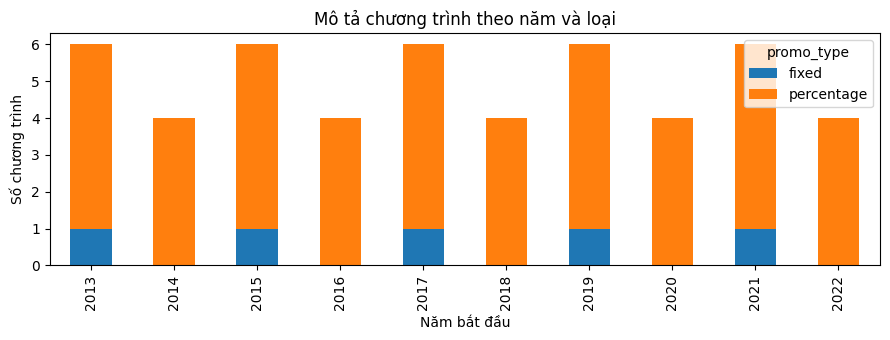

**Nhận xét.** 50 chương trình; 40 thiếu applicable_category; 12 có stackable_flag=1. Có 5 cặp khoảng giao nhau theo lịch. NULL danh mục chưa có nghĩa 'mọi danh mục', cờ 1 chưa chứng minh áp dụng kết hợp, min_order_value chưa xác định cơ sở tiền và promo_channel chưa chứng minh tiếp xúc thực tế. Cần chính sách áp dụng và định nghĩa trường trước bước kiểm tra điều kiện chi tiết.

In [3]:
show(prom,f'Toàn bộ {len(prom)} mô tả chương trình hiện hành')
pv=pd.to_numeric(prom.discount_value,errors='coerce')
mv=pd.to_numeric(prom.min_order_value,errors='coerce')
sf=pd.to_numeric(prom.stackable_flag,errors='coerce')
duration=(pe-ps).dt.days.where(ps.notna()&pe.notna()&ps.le(pe))
promo_quality=pd.DataFrame([
['start_date không đọc được (không NULL)',int((prom.start_date.notna()&ps.isna()).sum()),'A nếu có: không đọc được định dạng YYYY-MM-DD'],
['end_date không đọc được (không NULL)',int((prom.end_date.notna()&pe.isna()).sum()),'A nếu có: không đọc được định dạng YYYY-MM-DD'],
['Ngày đảo start > end',int(ps.gt(pe).sum()),'A nếu có: khoảng ngày đảo'],
['discount_value NULL/không số/không hữu hạn',int((~np.isfinite(pv.fillna(np.nan))).sum()),'Kiểm tra khả năng đọc số'],
['discount_value âm',int(pv.lt(0).sum()),'Dấu âm; cần định nghĩa để kết luận nghiệp vụ'],
['percentage ngoài [0,100]',int((prom.promo_type.eq('percentage')&~pv.between(0,100)).sum()),'Chỉ miền giả thuyết theo tên trường'],
['min_order_value NULL/không số/không hữu hạn',int((~np.isfinite(mv.fillna(np.nan))).sum()),'Kiểm tra khả năng đọc số'],
['min_order_value âm',int(mv.lt(0).sum()),'Dấu âm; chưa xác minh cơ sở Gross/Net'],
['stackable_flag ngoài {0,1} hoặc NULL',int((~sf.isin([0,1])).sum()),'Chỉ miền giả thuyết của cờ nhị phân']
],columns=['Kiểm tra','Dòng','Cách hiểu'])
show(promo_quality,'Ngày, số và miền kiểm tra')
show(prom.assign(_value=pv).groupby('promo_type',dropna=False)._value.agg(['count','min','max','mean','median']).rename(columns={'count':'Số mô tả','min':'Min','max':'Max','mean':'Trung bình','median':'Trung vị'}).reset_index(),'discount_value theo loại: không so sánh đơn vị giữa hai loại')
for c in ['promo_type','promo_channel','applicable_category','stackable_flag','min_order_value']:
    show(freq(prom,c,'Chương trình'),f'Phân bố {c}')
show(pd.crosstab(ps.dt.year,prom.promo_type,dropna=False).reset_index().rename(columns={'start_date':'Năm bắt đầu'}),'Số chương trình theo năm bắt đầu và loại')
show(duration.describe(percentiles=[.25,.5,.75]).rename(index={'count':'Số khoảng','mean':'Trung bình','std':'Độ lệch chuẩn mẫu','min':'Min','max':'Max','25%':'Phân vị 0,25','50%':'Trung vị','75%':'Phân vị 0,75'}).rename_axis('Thống kê').reset_index(name='Ngày đã trôi qua'),'Thời lượng, không cộng 1 ngày')
pairs=[]
for a,b in itertools.combinations(prom.index,2):
    if pd.notna(duration[a]) and pd.notna(duration[b]) and max(ps[a],ps[b])<=min(pe[a],pe[b]):
        pairs.append({'Mã A':prom.at[a,'promo_id'],'Mã B':prom.at[b,'promo_id'],'Từ':str(max(ps[a],ps[b]).date()),'Đến':str(min(pe[a],pe[b]).date()),'Ngày giao bao gồm':(min(pe[a],pe[b])-max(ps[a],ps[b])).days+1})
show(pairs,'Các cặp khoảng thời gian giao nhau; không tự gắn lỗi')
promo_categories=set(prom.applicable_category.dropna())
product_categories=set(products.category.dropna())
used_product=items.loc[p1|p2,['product_id']].merge(products[['product_id','category']],on='product_id',how='left',validate='many_to_one')
category_comparison=[]
for c in sorted(promo_categories|product_categories|set(used_product.category.dropna())):
    category_comparison.append({'Nhãn nguyên gốc':c,'Chương trình mô tả danh mục':int(prom.applicable_category.eq(c).sum()),'Sản phẩm hiện hành':int(products.category.eq(c).sum()),'Dòng có mã mang sản phẩm danh mục này':int(used_product.category.eq(c).sum()),'Có trong mô tả promotion':c in promo_categories})
show(category_comparison,'Ba khái niệm danh mục: không đánh giá tính đủ điều kiện giao dịch')
check('Ngày chương trình đọc đúng, không đảo',ps.notna().all() and pe.notna().all() and ps.le(pe).all())
check('Thời lượng đối chiếu độc lập ngày lịch',duration.tolist()==[(b.date()-a.date()).days for a,b in zip(ps,pe)])
fig,ax=plt.subplots(figsize=(9,3.5))
pd.crosstab(ps.dt.year,prom.promo_type).plot.bar(stacked=True,ax=ax)
ax.set(xlabel='Năm bắt đầu',ylabel='Số chương trình',title='Mô tả chương trình theo năm và loại'); figdone(fig)
note(f"**Nhận xét.** {len(prom)} chương trình; {prom.applicable_category.isna().sum()} thiếu applicable_category; {sf.eq(1).sum()} có stackable_flag=1. Có {len(pairs)} cặp khoảng giao nhau theo lịch. NULL danh mục chưa có nghĩa 'mọi danh mục', cờ 1 chưa chứng minh áp dụng kết hợp, min_order_value chưa xác định cơ sở tiền và promo_channel chưa chứng minh tiếp xúc thực tế. Cần chính sách áp dụng và định nghĩa trường trước bước kiểm tra điều kiện chi tiết.")

### 3. Các ô mã khuyến mãi và lượt tham chiếu
Bốn nhóm dòng hàng loại trừ nhau và bao phủ toàn bộ dữ liệu. Một dòng có hai mã tạo hai **lượt tham chiếu ô mã**, vẫn chỉ là một dòng hàng và một khoản discount_amount. promo_id_2 không chứng minh giảm giá kép. Khóa được so nguyên chuỗi, không bỏ dấu cách hoặc đổi NULL thành mã.

In [4]:
slot_rows=[]; ref_parts=[]
for slot in ['promo_id','promo_id_2']:
    s=items[slot]; non=s.notna(); known=s.isin(prom.promo_id.dropna())
    slot_rows.append({'Ô mã':slot,'Có cột':slot in items,'Kiểu':str(s.dtype),'NULL':int(s.isna().sum()),'NULL (%)':s.isna().mean()*100,'Có mã':int(non.sum()),'Mã khác nhau':s.nunique(),'Tham chiếu khớp':int((non&known).sum()),'Tham chiếu không khớp':int((non&~known).sum()),'Mã lạ khác nhau':s[non&~known].nunique()})
    part=items.loc[non,['order_id','product_id']].copy()
    part['_row']=part.index; part['slot']=slot; part['promo_id']=s[non]
    ref_parts.append(part)
refs=pd.concat(ref_parts,ignore_index=True)
refs['known']=refs.promo_id.isin(prom.promo_id)
show(slot_rows,'Độ phủ từng ô mã')
presence_table=presence.value_counts().reindex(['Không mã','Chỉ mã chính','Chỉ mã phụ','Hai mã'],fill_value=0).rename_axis('Nhóm').reset_index(name='Dòng hàng')
presence_table['Tỷ trọng (%)']=presence_table['Dòng hàng']/len(items)*100
show(presence_table,'Bốn nhóm dòng hàng')
uses=pd.crosstab(refs.promo_id,refs.slot).reindex(index=prom.promo_id,columns=['promo_id','promo_id_2'],fill_value=0).fillna(0).astype(int)
uses['Tổng lượt tham chiếu']=uses.sum(axis=1)
uses['Dòng hàng khác nhau']=refs.groupby('promo_id')._row.nunique().reindex(uses.index,fill_value=0)
show(uses.rename_axis('Mã chương trình').reset_index(),'Tần suất tham chiếu từng mã; không phải đơn tăng thêm hoặc người tiếp xúc')
order_codes=refs.groupby('order_id').promo_id.nunique().reindex(orders.order_id,fill_value=0)
show(order_codes.value_counts().sort_index().rename_axis('Số mã khác nhau/đơn').reset_index(name='Đơn hàng'),'Số mã khác nhau trong đơn, gồm cả đơn không mã')
same=(p1&p2&items.promo_id.eq(items.promo_id_2)).fillna(False)
show([{'Dòng có hai ô mã':int((p1&p2).sum()),'Hai ô cùng mã':int(same.sum()),'Hai ô khác mã':int(((p1&p2)&~same).sum()),'Tổng lượt tham chiếu':len(refs),'Mã dùng khác nhau':refs.promo_id.nunique(),'Mã không khớp khác nhau':refs.loc[~refs.known,'promo_id'].nunique(),'Chương trình không được tham chiếu':len(set(prom.promo_id)-set(refs.promo_id)),'Đơn có ít nhất một mã':int(order_codes.gt(0).sum())}])
check('Bốn nhóm bảo toàn dòng',presence_table['Dòng hàng'].sum()==len(items))
check('Hai ô mã: số lượt = dòng có mã + dòng hai mã',len(refs)==int((p1|p2).sum()+(p1&p2).sum()))
check('Lượt không khớp đối chiếu độc lập',int((~refs.known).sum())==sum(int((items[s].notna()&~items[s].isin(set(prom.promo_id))).sum()) for s in ['promo_id','promo_id_2']))
check('Tần suất theo mã bảo toàn lượt',int(uses['Tổng lượt tham chiếu'].sum())==len(refs))
note(f"**Nhận xét.** Có {(p1|p2).sum():,} dòng gắn ít nhất một mã, {(p1&p2).sum():,} dòng có hai mã và {len(refs):,} lượt tham chiếu. Có {refs.loc[~refs.known,'promo_id'].nunique()} mã lạ khác nhau. Khả năng đối chiếu khóa chỉ xác nhận mã có trong danh mục chương trình; chưa xác nhận điều kiện áp dụng, số lần đổi ưu đãi hoặc cách cộng giảm giá. Cần ID lần áp dụng và chính sách stacking.".replace(',','.'))

**Độ phủ từng ô mã**

Ô mã,Có cột,Kiểu,NULL,NULL (%),Có mã,Mã khác nhau,Tham chiếu khớp,Tham chiếu không khớp,Mã lạ khác nhau
promo_id,1,string,438.353,"61,336507",276.316,50,276.316,0,0
promo_id_2,1,string,714.463,"99,971175",206,2,206,0,0


**Bốn nhóm dòng hàng**

Nhóm,Dòng hàng,Tỷ trọng (%)
Không mã,438.353,"61,336507"
Chỉ mã chính,276.110,"38,634669"
Chỉ mã phụ,0,0
Hai mã,206,"0,028825"


**Tần suất tham chiếu từng mã; không phải đơn tăng thêm hoặc người tiếp xúc**

Mã chương trình,promo_id,promo_id_2,Tổng lượt tham chiếu,Dòng hàng khác nhau
PROMO-0001,8.523,0,8.523,8.523
PROMO-0002,7.754,0,7.754,7.754
PROMO-0003,6.277,0,6.277,6.277
PROMO-0004,11.126,0,11.126,11.126
PROMO-0005,4.887,0,4.887,4.887
PROMO-0006,2.828,0,2.828,2.828
PROMO-0007,9.373,0,9.373,9.373
PROMO-0008,7.089,0,7.089,7.089
PROMO-0009,5.637,0,5.637,5.637
PROMO-0010,11.345,0,11.345,11.345


**Số mã khác nhau trong đơn, gồm cả đơn không mã**

Số mã khác nhau/đơn,Đơn hàng
0,398.703
1,248.037
2,205


Dòng có hai ô mã,Hai ô cùng mã,Hai ô khác mã,Tổng lượt tham chiếu,Mã dùng khác nhau,Mã không khớp khác nhau,Chương trình không được tham chiếu,Đơn có ít nhất một mã
206,0,206,276.522,50,0,0,248.242


**Nhận xét.** Có 276.316 dòng gắn ít nhất một mã. 206 dòng có hai mã và 276.522 lượt tham chiếu. Có 0 mã lạ khác nhau. Khả năng đối chiếu khóa chỉ xác nhận mã có trong danh mục chương trình; chưa xác nhận điều kiện áp dụng. số lần đổi ưu đãi hoặc cách cộng giảm giá. Cần ID lần áp dụng và chính sách stacking.

### 4. discount_amount: giảm giá ghi nhận một lần trên mỗi dòng
Theo V02: Gross = Σ(quantity × unit_price); Discount = Σ(discount_amount); Net số học = Gross − Discount. **Không nhân discount_amount với quantity.** Dùng Decimal từ chuỗi nguồn rồi lưu số nguyên phần trăm ĐVT; chặn thiếu, không hữu hạn hoặc vượt 2 chữ số thập phân. Không gán phần giảm giá cho từng mã khi dòng có hai mã.

Phân vị dùng nội suy tuyến tính trên giá trị số; tổng tiền kiểm chứng bằng số nguyên và bằng bộ đọc csv/Decimal độc lập. Net ở đây chưa phải doanh thu được ghi nhận kế toán hoặc tiền thực thu.

In [5]:
da=discount_c/100
discount_stats=[
['Số dòng',len(items)],['NULL',items.discount_amount.isna().sum()],['Bằng 0',discount_c.eq(0).sum()],['Dương',discount_c.gt(0).sum()],['Âm',discount_c.lt(0).sum()],
['Min',da.min()],['Max',da.max()],['Trung bình',da.mean()],['Trung vị',da.median()],
*[[f'Phân vị {q:g}',da.quantile(q)] for q in [.01,.05,.25,.75,.95,.99]],['Tổng Discount',int(discount_c.sum())/100]]
show(pd.DataFrame(discount_stats,columns=['Thống kê','Giá trị nguồn (ĐVT nếu là tiền)']))
cross=pd.DataFrame({'Nhóm':presence,'NULL':items.discount_amount.isna(),'Bằng 0':discount_c.eq(0),'Dương':discount_c.gt(0),'Âm':discount_c.lt(0),'Discount (phần trăm ĐVT)':discount_c})
cross_summary=cross.groupby('Nhóm',dropna=False).agg(Dòng=('Nhóm','size'),NULL=('NULL','sum'),Không_giảm=('Bằng 0','sum'),Dương=('Dương','sum'),Âm=('Âm','sum'),Discount_c=('Discount (phần trăm ĐVT)','sum')).reset_index()
cross_summary['Discount (ĐVT)']=cross_summary.pop('Discount_c')/100
show(cross_summary,'Giảm giá theo nhóm hiện diện mã, mỗi dòng đúng một lần')
show([{'Gross (ĐVT)':int(gross_c.sum())/100,'Discount (ĐVT)':int(discount_c.sum())/100,'Net số học (ĐVT)':int(net_c.sum())/100,'Discount V02 (ĐVT)':reports['v02']['metrics']['discount'],'Không mã nhưng giảm dương':int((~(p1|p2)&discount_c.gt(0)).sum()),'Có mã nhưng giảm 0':int(((p1|p2)&discount_c.eq(0)).sum())}])
with paths['order_items'].open(encoding='utf-8-sig',newline='') as f:
    exact_independent=sum((Decimal(r['discount_amount']) for r in csv.DictReader(f)),Decimal(0))
check('Tổng Discount độc lập CSV/Decimal',Decimal(int(discount_c.sum()))/100==exact_independent,str(exact_independent))
check('Discount khớp V02',Decimal(int(discount_c.sum()))/100==Decimal(str(reports['v02']['metrics']['discount'])))
check('Gross khớp V02',Decimal(int(gross_c.sum()))/100==Decimal(str(reports['v02']['metrics']['gross'])))
check('Tổng tiền bốn nhóm bảo toàn',abs(cross_summary['Discount (ĐVT)'].sum()-int(discount_c.sum())/100)<0.000001)
check('Không cộng tài chính trên bảng lượt mã',len(cross)==len(items) and int(cross['Discount (phần trăm ĐVT)'].sum())==int(discount_c.sum()))
note(f"**Nhận xét.** Tổng giảm giá ghi nhận {vn(int(discount_c.sum())/100)} ĐVT, khớp V02 và phép cộng Decimal độc lập. Có {int((~(p1|p2)&discount_c.gt(0)).sum())} dòng không mã nhưng giảm dương và {int(((p1|p2)&discount_c.eq(0)).sum())} dòng có mã nhưng giảm 0. Kết quả 0 chỉ đúng trong mẫu hiện hành, không tạo quy tắc bắt buộc mã cho mọi khoản giảm. Cần tài liệu tính giảm trước khi liên hệ discount_value hoặc phân bổ cho chương trình.")

Thống kê,Giá trị nguồn (ĐVT nếu là tiền)
Số dòng,714.669
NULL,0
Bằng 0,438.353
Dương,276.316
Âm,0
Min,0
Max,"35.235,47"
Trung bình,"1.048,887415"
Trung vị,0
Phân vị 0.01,0


**Giảm giá theo nhóm hiện diện mã, mỗi dòng đúng một lần**

Nhóm,Dòng,NULL,Không_giảm,Dương,Âm,Discount (ĐVT)
Chỉ mã chính,276.110,0,0,276.110,0,"748.966.843,48"
Hai mã,206,0,0,206,0,"640.476,62"
Không mã,438.353,0,438.353,0,0,0


Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Discount V02 (ĐVT),Không mã nhưng giảm dương,Có mã nhưng giảm 0
"16.430.476.585,530001","749.607.320,1","15.680.869.265,43","749.607.320,1",0,0


**Nhận xét.** Tổng giảm giá ghi nhận 749.607.320,1 ĐVT, khớp V02 và phép cộng Decimal độc lập. Có 0 dòng không mã nhưng giảm dương và 0 dòng có mã nhưng giảm 0. Kết quả 0 chỉ đúng trong mẫu hiện hành, không tạo quy tắc bắt buộc mã cho mọi khoản giảm. Cần tài liệu tính giảm trước khi liên hệ discount_value hoặc phân bổ cho chương trình.

### 5. Khóa liên kết và bảo toàn khi JOIN
Kiểm tra khóa cha trước, sau đó LEFT JOIN có validate='many_to_one'. Hai slot được JOIN riêng theo cột, không bung dòng hàng thành các lượt mã để tính tiền. JOIN khách vào đơn thực hiện tại cấp đơn. Không dùng ngày/kênh để ghép traffic vào khách hoặc đơn.

Đối chiếu lịch bên dưới chỉ so order_date với khoảng chương trình theo ngày lịch, bao gồm hai đầu. Ngoài khoảng chưa phải lỗi vận hành: chưa có thời điểm áp dụng ưu đãi, múi giờ hoặc ngoại lệ chính sách.

In [6]:
baseline=(len(line),int(line._qty.sum()),int(line._gross_c.sum()),int(line._discount_c.sum()))
join_audits=[]
def audit_join(label,d,unmatched):
    vals=(len(d),int(d._qty.sum()),int(d._gross_c.sum()),int(d._discount_c.sum()))
    join_audits.append({'JOIN':label,'Dòng trước':baseline[0],'Dòng sau':vals[0],'Dòng không khớp':int(unmatched),'Quantity trước':baseline[1],'Quantity sau':vals[1],'Gross trước (ĐVT)':baseline[2]/100,'Gross sau (ĐVT)':vals[2]/100,'Discount trước (ĐVT)':baseline[3]/100,'Discount sau (ĐVT)':vals[3]/100})
    check(label+': bảo toàn dòng, quantity, Gross, Discount',vals==baseline)
for n,key in [('promotions','promo_id'),('orders','order_id'),('products','product_id'),('customers','customer_id')]:
    check(f'{n}: khóa cha đủ và duy nhất',data[n][key].notna().all() and data[n][key].is_unique)
joined=line
for slot in ['promo_id','promo_id_2']:
    parent=prom[['promo_id','promo_type']].rename(columns={'promo_id':slot,'promo_type':'_type_'+slot})
    joined=joined.merge(parent,on=slot,how='left',validate='many_to_one',sort=False)
    audit_join('items → promotions.'+slot,joined,(joined[slot].notna()&joined['_type_'+slot].isna()).sum())
joined=joined.merge(orders[['order_id','order_date']],on='order_id',how='left',validate='many_to_one',sort=False)
audit_join('items → orders',joined,joined.order_date.isna().sum())
joined=joined.merge(products[['product_id','category']],on='product_id',how='left',validate='many_to_one',sort=False)
audit_join('items → products',joined,(~joined.product_id.isin(products.product_id)).sum())
show(join_audits,'Bảo toàn tài chính qua mỗi bước JOIN')
oc=orders.merge(customers[['customer_id','acquisition_channel']],on='customer_id',how='left',validate='many_to_one',indicator=True)
customer_unmatched=int(oc._merge.eq('left_only').sum())
check('orders → customers: không nhân đơn',len(oc)==len(orders) and oc.order_id.nunique()==orders.order_id.nunique())
show([{'Quan hệ':'orders → customers','Đơn trước':len(orders),'Đơn sau':len(oc),'Đơn khớp':len(oc)-customer_unmatched,'Đơn không khớp':customer_unmatched,'Khách khác nhau trước':orders.customer_id.nunique(),'Khách khác nhau sau':oc.customer_id.nunique(),'Khách có nhiều đơn':int(orders.customer_id.value_counts().gt(1).sum())}])
refdates=refs.merge(orders[['order_id','order_date']],on='order_id',how='left',validate='many_to_one').merge(prom[['promo_id','start_date','end_date']],on='promo_id',how='left',validate='many_to_one')
rd=dates(refdates.order_date); rs=dates(refdates.start_date); re=dates(refdates.end_date)
known_dates=rd.notna()&rs.notna()&re.notna()&rs.le(re)
inside=known_dates&rd.ge(rs)&rd.le(re)
refdates['Đối chiếu lịch']=np.select([~known_dates,inside],['Không xác định','Trong khoảng'],default='Ngoài khoảng')
show(pd.crosstab(refdates.slot,refdates['Đối chiếu lịch']).reset_index(),'Lịch theo lượt tham chiếu, không phải số dòng/đơn lỗi')
check('Đối chiếu lịch bảo toàn lượt tham chiếu',len(refdates)==len(refs))
note(f"**Nhận xét.** Các LEFT JOIN hợp lệ bảo toàn {len(items):,} dòng hàng và tổng tiền. Có {customer_unmatched} đơn không khớp khách. So lịch ghi nhận {int((known_dates&~inside).sum()):,} lượt mã ngoài khoảng và {int((~known_dates).sum())} lượt chưa xác định; đây là dấu hiệu cần hỏi về ngày áp dụng và chính sách, không phải kết luận sai ưu đãi. JOIN đơn–khách cho phép nhóm đơn theo thuộc tính hồ sơ, chưa quy kết nguồn tạo đơn.".replace(',','.'))
del joined, oc, used_product, refdates

**Bảo toàn tài chính qua mỗi bước JOIN**

JOIN,Dòng trước,Dòng sau,Dòng không khớp,Quantity trước,Quantity sau,Gross trước (ĐVT),Gross sau (ĐVT),Discount trước (ĐVT),Discount sau (ĐVT)
items → promotions.promo_id,714.669,714.669,0,3.213.143,3.213.143,"16.430.476.585,530001","16.430.476.585,530001","749.607.320,1","749.607.320,1"
items → promotions.promo_id_2,714.669,714.669,0,3.213.143,3.213.143,"16.430.476.585,530001","16.430.476.585,530001","749.607.320,1","749.607.320,1"
items → orders,714.669,714.669,0,3.213.143,3.213.143,"16.430.476.585,530001","16.430.476.585,530001","749.607.320,1","749.607.320,1"
items → products,714.669,714.669,0,3.213.143,3.213.143,"16.430.476.585,530001","16.430.476.585,530001","749.607.320,1","749.607.320,1"


Quan hệ,Đơn trước,Đơn sau,Đơn khớp,Đơn không khớp,Khách khác nhau trước,Khách khác nhau sau,Khách có nhiều đơn
orders → customers,646.945,646.945,646.945,0,90.246,90.246,67.888


**Lịch theo lượt tham chiếu, không phải số dòng/đơn lỗi**

slot,Trong khoảng
promo_id,276.316
promo_id_2,206


**Nhận xét.** Các LEFT JOIN hợp lệ bảo toàn 714.669 dòng hàng và tổng tiền. Có 0 đơn không khớp khách. So lịch ghi nhận 0 lượt mã ngoài khoảng và 0 lượt chưa xác định; đây là dấu hiệu cần hỏi về ngày áp dụng và chính sách. không phải kết luận sai ưu đãi. JOIN đơn–khách cho phép nhóm đơn theo thuộc tính hồ sơ. chưa quy kết nguồn tạo đơn.

### 6. Hồ sơ khách và acquisition_channel
Kênh acquisition là thuộc tính của hồ sơ khách. Tỷ trọng dưới đây có mẫu số là số hồ sơ customers, không phải người vào web, người tiếp xúc chương trình hoặc số đơn. Nhiều đơn của một khách không tạo thêm khách; không JOIN rồi đếm số dòng như số khách.

**Khách theo nhãn acquisition nguyên gốc**

acquisition_channel,Hồ sơ khách,Tỷ trọng (%)
organic_search,36.450,"29,894202"
social_media,24.448,"20,050849"
paid_search,24.285,"19,917166"
email_campaign,14.674,"12,034774"
referral,12.270,"10,063151"
direct,9.803,"8,039859"


**Phân bố năm đăng ký; định dạng nguồn MM/DD/YYYY**

Năm đăng ký,Hồ sơ
2.012,957
2.013,2.989
2.014,5.034
2.015,7.133
2.016,9.202
2.017,11.078
2.018,13.011
2.019,15.058
2.020,17.211
2.021,19.154


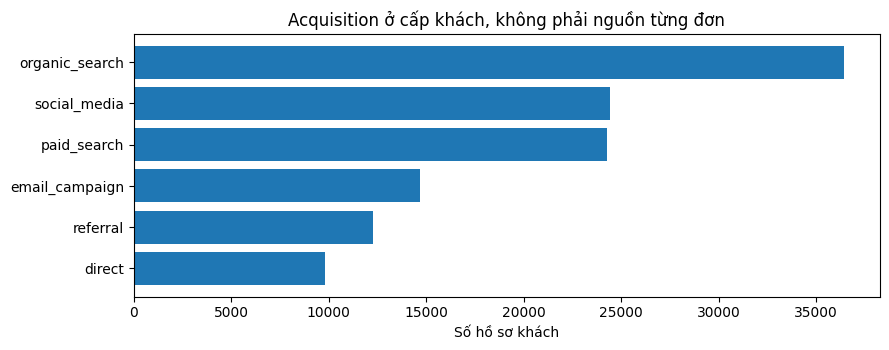

**Nhận xét.** 121.930 hồ sơ khách có 6 nhãn acquisition. thiếu 0 giá trị. Mỗi khách được đếm một lần từ bảng gốc. Phân bố mô tả hồ sơ hiện có. chưa cho biết CAC. conversion hoặc chương trình thu hút khách. Cần định nghĩa first/last-touch. thời điểm gán kênh và lịch sử thay đổi.

In [7]:
acq=freq(customers,'acquisition_channel','Hồ sơ khách')
show(acq,'Khách theo nhãn acquisition nguyên gốc')
signup_year=cd.dt.year.value_counts(dropna=False).sort_index().rename_axis('Năm đăng ký').reset_index(name='Hồ sơ')
show(signup_year,'Phân bố năm đăng ký; định dạng nguồn MM/DD/YYYY')
check('Acquisition bảo toàn tổng khách',int(acq['Hồ sơ khách'].sum())==len(customers))
check('Khóa khách duy nhất trước mọi đếm khách',customers.customer_id.notna().all() and customers.customer_id.is_unique)
check('Ngày đăng ký đọc được',cd.notna().all())
fig,ax=plt.subplots(figsize=(9,3.6))
ax.barh(acq.acquisition_channel.astype(str),acq['Hồ sơ khách'])
ax.invert_yaxis(); ax.set(xlabel='Số hồ sơ khách',title='Acquisition ở cấp khách, không phải nguồn từng đơn'); figdone(fig)
note(f"**Nhận xét.** {len(customers):,} hồ sơ khách có {customers.acquisition_channel.nunique()} nhãn acquisition, thiếu {customers.acquisition_channel.isna().sum()} giá trị. Mỗi khách được đếm một lần từ bảng gốc. Phân bố mô tả hồ sơ hiện có, chưa cho biết CAC, conversion hoặc chương trình thu hút khách. Cần định nghĩa first/last-touch, thời điểm gán kênh và lịch sử thay đổi.".replace(',','.'))

### 7. web_traffic: độ hạt, số đo và thang đo chưa xác minh
Kiểm tra ngày thực tế, dòng/ngày, nhãn/ngày và mức phủ lịch trước khi gọi đây là chuỗi ngày. unique_visitors là số đo được ghi trong từng ngày; chưa biết cách định danh hoặc khử trùng giữa ngày. Không cộng các giá trị ngày thành người duy nhất của toàn kỳ.

bounce_rate được giữ nguyên số nguồn. Việc nằm trong [0,1] chỉ tương thích về mặt số học với giả thuyết lưu tỷ phần; cũng có thể là thang lưu khác. Không nhân/chia 100 để sửa; cần đơn vị chính thức, định nghĩa tử/mẫu số và cách tổng hợp. Không mặc định traffic_source là nguồn chiếm ưu thế hoặc nguồn của mọi session trong ngày.

**Tất cả số đo web: nguyên thang nguồn, không cộng unique_visitors xuyên ngày**

Trường,NULL nguồn,Không số không NULL,Không hữu hạn,Âm,Bằng 0,Min,Max,Trung bình số lưu,Trung vị số lưu,Khác nhau
sessions,0,0,0,0,0,7.973,50.947,"25.041,768072","23.633,5",3.447
unique_visitors,0,0,0,0,0,6.136,40.430,"19.031,404436",17.924,3.382
page_views,0,0,0,0,0,30.451,275.560,"108.615,224535","101.010,5",3.620
bounce_rate,0,0,0,0,0,"0,0032","0,0058","0,004487","0,00445",261
avg_session_duration_sec,0,0,0,0,0,"100,1","319,9","210,283242","209,2",1.771


**Độ hạt được kiểm tra từ dữ liệu**

Dòng,Ngày đọc được,Ngày khác nhau,Dòng/ngày min,Dòng/ngày max,Ngày nhiều dòng,Nhãn/ngày max,Ngày nhiều nhãn,Ngày lịch giữa hai đầu,Ngày lịch thiếu,"Trùng (date,traffic_source) vượt đầu",Có khóa customer_id,Có khóa order_id,Có khóa phiên
3.652,3.652,3.652,1,1,0,1,0,3.652,0,0,0,0,0


**Số dòng/ngày/nhãn từng tháng, không giả định một dòng cho mỗi kênh/ngày**

Tháng,Dòng,Ngày,Nhãn
2013-01,31,31,6
2013-02,28,28,6
2013-03,31,31,5
2013-04,30,30,6
2013-05,31,31,6
2013-06,30,30,5
2013-07,31,31,6
2013-08,31,31,6
2013-09,30,30,6
2013-10,31,31,6


**Tần suất nhãn traffic_source: mẫu số là ngày, không phải sessions**

traffic_source,Ngày gắn nhãn,Tỷ trọng (%)
organic_search,1.090,"29,846659"
paid_search,784,"21,467689"
social_media,632,"17,305586"
email_campaign,505,"13,828039"
referral,375,"10,268346"
direct,266,"7,28368"


**Miền số không xác minh đơn vị**

Trường,Min thô,Max thô,Trung bình thô,Trung vị thô,"Trong [0,1]","Ngoài [0,1] hữu hạn",Đơn vị chính thức,Giả thuyết 1,Giả thuyết 2
bounce_rate,"0,0032","0,0058","0,004487","0,00445",3.652,0,Chưa xác minh,Số lưu là tỷ phần; cần xác nhận,Số lưu theo thang khác; cần tài liệu


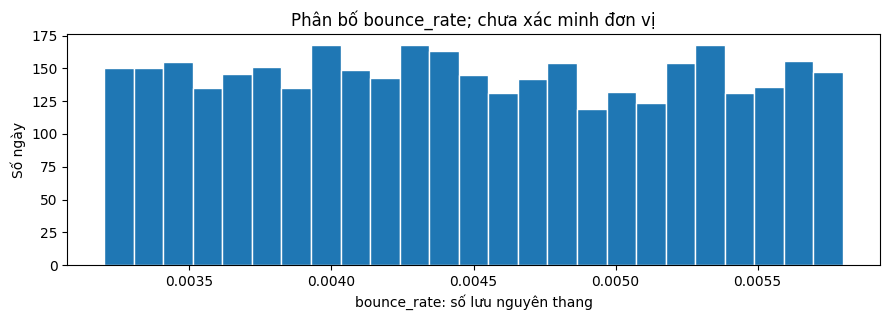

**Nhận xét.** Web có 3,652 dòng, 3,652 ngày khác nhau, thiếu 0 ngày giữa hai đầu; số nhãn tối đa/ngày là 1. Đây là một bản ghi/ngày với một nhãn nguồn, không có bảng phân rã sessions theo kênh. bounce_rate trung bình 0,004487 giữ nguyên thang; mức thấp không tự chứng minh sai đơn vị. Cần quy tắc tạo nhãn ngày, định nghĩa phiên/người và số đo bounce.

In [8]:
web_num_cols=[c for c in web if c not in ['date','traffic_source']]
web_nums={c:pd.to_numeric(web[c],errors='coerce') for c in web_num_cols}
web_numeric=[]
for c,s in web_nums.items():
    finite=s[np.isfinite(s.fillna(np.nan))]
    web_numeric.append({'Trường':c,'NULL nguồn':int(web[c].isna().sum()),'Không số không NULL':int((web[c].notna()&s.isna()).sum()),'Không hữu hạn':int((s.notna()&~np.isfinite(s)).sum()),'Âm':int(finite.lt(0).sum()),'Bằng 0':int(finite.eq(0).sum()),'Min':finite.min(),'Max':finite.max(),'Trung bình số lưu':finite.mean(),'Trung vị số lưu':finite.median(),'Khác nhau':finite.nunique()})
show(web_numeric,'Tất cả số đo web: nguyên thang nguồn, không cộng unique_visitors xuyên ngày')
day_counts=wd.value_counts()
labels_per_day=web.assign(_date=wd).groupby('_date').traffic_source.nunique(dropna=False)
expected_days=(wd.max()-wd.min()).days+1
web_missing_days=len(pd.date_range(wd.min(),wd.max()).difference(pd.DatetimeIndex(wd.dropna())))
web_grain={'Dòng':len(web),'Ngày đọc được':int(wd.notna().sum()),'Ngày khác nhau':wd.nunique(),'Dòng/ngày min':day_counts.min(),'Dòng/ngày max':day_counts.max(),'Ngày nhiều dòng':int(day_counts.gt(1).sum()),'Nhãn/ngày max':labels_per_day.max(),'Ngày nhiều nhãn':int(labels_per_day.gt(1).sum()),'Ngày lịch giữa hai đầu':expected_days,'Ngày lịch thiếu':web_missing_days,'Trùng (date,traffic_source) vượt đầu':int(web.duplicated(['date','traffic_source']).sum()),'Có khóa customer_id':'customer_id' in web,'Có khóa order_id':'order_id' in web,'Có khóa phiên':any(c in web for c in ['session_id','visitor_id','user_id'])}
show([web_grain],'Độ hạt được kiểm tra từ dữ liệu')
web_month=web.assign(Tháng=wd.dt.to_period('M').astype(str)).groupby('Tháng',dropna=False).agg(Dòng=('date','size'),Ngày=('date','nunique'),Nhãn=('traffic_source','nunique')).reset_index()
show(web_month,'Số dòng/ngày/nhãn từng tháng, không giả định một dòng cho mỗi kênh/ngày')
traffic=freq(web,'traffic_source','Ngày gắn nhãn')
show(traffic,'Tần suất nhãn traffic_source: mẫu số là ngày, không phải sessions')
bounce=web_nums['bounce_rate']
show([{'Trường':'bounce_rate','Min thô':bounce.min(),'Max thô':bounce.max(),'Trung bình thô':bounce.mean(),'Trung vị thô':bounce.median(),'Trong [0,1]':int(bounce.between(0,1).sum()),'Ngoài [0,1] hữu hạn':int((np.isfinite(bounce)&~bounce.between(0,1)).sum()),'Đơn vị chính thức':'Chưa xác minh','Giả thuyết 1':'Số lưu là tỷ phần; cần xác nhận','Giả thuyết 2':'Số lưu theo thang khác; cần tài liệu'}],'Miền số không xác minh đơn vị')
check('web: độ hạt ngày và lịch đầy đủ đã kiểm tra',wd.notna().all() and wd.is_unique and web_missing_days==0 and day_counts.eq(1).all())
check('web: mỗi ngày một nhãn ghi nhận',labels_per_day.eq(1).all() and web.traffic_source.notna().all())
check('bounce giữ đúng số nguồn',all(Decimal(raw)==Decimal(str(float(num))) for raw,num in zip(web.bounce_rate,bounce)))
check('bounce đối chiếu V07',abs(bounce.mean()-reports['v07']['metrics']['bounce_mean'])<1e-12)
check('Traffic không có khóa khách/đơn/phiên',not any(c in web for c in ['customer_id','order_id','session_id','visitor_id','user_id']))
fig,ax=plt.subplots(figsize=(9,3.3))
ax.hist(bounce.to_numpy(dtype=float),bins=25,edgecolor='white')
ax.set(xlabel='bounce_rate: số lưu nguyên thang',ylabel='Số ngày',title='Phân bố bounce_rate; chưa xác minh đơn vị')
figdone(fig)
note(f"**Nhận xét.** Web có {len(web):,} dòng, {wd.nunique():,} ngày khác nhau, thiếu {web_missing_days} ngày giữa hai đầu; số nhãn tối đa/ngày là {labels_per_day.max()}. Đây là một bản ghi/ngày với một nhãn nguồn, không có bảng phân rã sessions theo kênh. bounce_rate trung bình {vn(bounce.mean())} giữ nguyên thang; mức thấp không tự chứng minh sai đơn vị. Cần quy tắc tạo nhãn ngày, định nghĩa phiên/người và số đo bounce.".replace(':,',':'))

### 8. Ba loại kênh: từ vựng giống nhau chưa phải cùng ý nghĩa
So sánh tập nhãn chỉ dùng set trên chuỗi nguyên gốc; không tạo mapping. email và email_campaign vẫn là hai nhãn ở hai bảng. all_channels chỉ là nhãn mô tả chương trình, chưa chứng minh mọi khách được tiếp xúc. Không JOIN khách–traffic bằng ngày hoặc tên kênh.

In [9]:
channel_map=[
{'Trường':'promotions.promo_channel','Đơn vị':'Chương trình','Nhãn thực tế':', '.join(sorted(prom.promo_channel.dropna().unique())),'Ý nghĩa có thể xác nhận':'Nhãn kênh trên mô tả chương trình','Khả năng liên kết':'promo_id tới dòng hàng; không có campaign/event ID sang web','Rủi ro':'Nhãn không chứng minh exposure; all_channels không phải tất cả khách','Cần thêm':'Từ điển, lịch phân phối, exposure/campaign ID'},
{'Trường':'customers.acquisition_channel','Đơn vị':'Hồ sơ khách','Nhãn thực tế':', '.join(sorted(customers.acquisition_channel.dropna().unique())),'Ý nghĩa có thể xác nhận':'Nhãn acquisition của hồ sơ hiện tại','Khả năng liên kết':'customer_id tới orders; chỉ thuộc tính hồ sơ','Rủi ro':'Không mặc định nguồn mỗi đơn hoặc lần truy cập','Cần thêm':'First/last-touch, timestamp, lịch sử, quy tắc gán'},
{'Trường':'web_traffic.traffic_source','Đơn vị':'Ngày có một nhãn','Nhãn thực tế':', '.join(sorted(web.traffic_source.dropna().unique())),'Ý nghĩa có thể xác nhận':'Nhãn nguồn trên bản ghi ngày','Khả năng liên kết':'Chỉ căn chỉnh lịch tổng hợp sau kiểm tra; không có ID khách/đơn','Rủi ro':'Không phải thị phần session, chưa xác minh nguồn trội','Cần thêm':'Quy tắc nhãn, session/user/event/campaign/order ID, consent và cửa sổ'}]
show(channel_map,'So sánh ba cấp quan sát')
sets={c:set(d[col].dropna()) for c,d,col in [('promo',prom,'promo_channel'),('acquisition',customers,'acquisition_channel'),('traffic',web,'traffic_source')]}
show([{'Cặp':a+' ↔ '+b,'Nhãn chung':', '.join(sorted(sets[a]&sets[b])),'Chỉ bên trái':', '.join(sorted(sets[a]-sets[b])),'Chỉ bên phải':', '.join(sorted(sets[b]-sets[a])),'Chứng minh cùng nghĩa hoặc attribution':'Không'} for a,b in itertools.combinations(sets,2)],'Đối chiếu từ vựng, không tạo mapping')
check('Tập nhãn acquisition/traffic khớp kết quả V08',(sets['acquisition']==sets['traffic'])==reports['v08']['metrics']['label_sets_equal'])
note("**Nhận xét.** Hai tập acquisition/traffic có cùng nhãn nhưng một bên là hồ sơ khách, bên kia là ngày. Nhãn social_media trùng chữ không cung cấp lineage. Chưa thể diễn giải email thành email_campaign hoặc gán traffic cho từng khách. Cần khóa sự kiện và quy tắc attribution được xác minh; ở bước này chỉ mô tả riêng từng nguồn.")

**So sánh ba cấp quan sát**

Trường,Đơn vị,Nhãn thực tế,Ý nghĩa có thể xác nhận,Khả năng liên kết,Rủi ro,Cần thêm
promotions.promo_channel,Chương trình,"all_channels, email, in_store, online, social_media",Nhãn kênh trên mô tả chương trình,promo_id tới dòng hàng; không có campaign/event ID sang web,Nhãn không chứng minh exposure; all_channels không phải tất cả khách,"Từ điển, lịch phân phối, exposure/campaign ID"
customers.acquisition_channel,Hồ sơ khách,"direct, email_campaign, organic_search, paid_search, referral, social_media",Nhãn acquisition của hồ sơ hiện tại,customer_id tới orders; chỉ thuộc tính hồ sơ,Không mặc định nguồn mỗi đơn hoặc lần truy cập,"First/last-touch, timestamp, lịch sử, quy tắc gán"
web_traffic.traffic_source,Ngày có một nhãn,"direct, email_campaign, organic_search, paid_search, referral, social_media",Nhãn nguồn trên bản ghi ngày,Chỉ căn chỉnh lịch tổng hợp sau kiểm tra; không có ID khách/đơn,"Không phải thị phần session, chưa xác minh nguồn trội","Quy tắc nhãn, session/user/event/campaign/order ID, consent và cửa sổ"


**Đối chiếu từ vựng, không tạo mapping**

Cặp,Nhãn chung,Chỉ bên trái,Chỉ bên phải,Chứng minh cùng nghĩa hoặc attribution
promo ↔ acquisition,social_media,"all_channels, email, in_store, online","direct, email_campaign, organic_search, paid_search, referral",Không
promo ↔ traffic,social_media,"all_channels, email, in_store, online","direct, email_campaign, organic_search, paid_search, referral",Không
acquisition ↔ traffic,"direct, email_campaign, organic_search, paid_search, referral, social_media",,,Không


**Nhận xét.** Hai tập acquisition/traffic có cùng nhãn nhưng một bên là hồ sơ khách, bên kia là ngày. Nhãn social_media trùng chữ không cung cấp lineage. Chưa thể diễn giải email thành email_campaign hoặc gán traffic cho từng khách. Cần khóa sự kiện và quy tắc attribution được xác minh; ở bước này chỉ mô tả riêng từng nguồn.

### 9. sales và phạm vi thời gian
sales chỉ có Date, Revenue, COGS, không có khóa đơn/khách/sản phẩm/promotion. Khóa ngày duy nhất cho phép so số tổng hợp sau kiểm tra độ hạt; JOIN thẳng bảng ngày vào nhiều dòng hàng sẽ lặp Revenue. Notebook chỉ đối chiếu tổng/ngày, không ghép số tiền sales lên giao dịch.

V02 xác minh Revenue = Gross trước giảm giá trong phạm vi đã kiểm tra. Đây không phải Net hoặc bằng chứng tiền thực thu. V02 đã đọc payments; NV06.1 chỉ tham khảo kết luận báo cáo, không đọc thêm nguồn đó.

In [10]:
sales_revenue_c=cents(sales.Revenue)
gross_by_date=pd.DataFrame({'Ngày':items.order_id.map(pd.Series(od.values,index=orders.order_id)),'Gross_c':gross_c}).groupby('Ngày').Gross_c.sum()
sale_by_date=pd.Series(sales_revenue_c.to_numpy(),index=pd.DatetimeIndex(sd))
aligned=pd.concat([gross_by_date.rename('Gross_c'),sale_by_date.rename('Sales_Revenue_c')],axis=1)
daily_equal=aligned.notna().all(axis=1)&aligned.Gross_c.eq(aligned.Sales_Revenue_c)
show([{'Dòng sales':len(sales),'Cột thực tế':', '.join(sales.columns),'Ngày duy nhất':sd.is_unique,'Có ID giao dịch':False,'Tổng Revenue (ĐVT)':int(sales_revenue_c.sum())/100,'Tổng Gross (ĐVT)':int(gross_c.sum())/100,'Ngày khớp đúng Gross':int(daily_equal.sum()),'Ngày không khớp/thiếu một bên':int((~daily_equal).sum()),'Rủi ro JOIN':'Một số tổng/ngày bị lặp theo từng giao dịch'}])
check('sales Revenue khớp Gross từng ngày độc lập V02',daily_equal.all() and len(aligned)==len(sales))
series_dates={'promotions.start_date':ps,'promotions.end_date':pe,'orders.order_date':od,'customers.signup_date':cd,'web_traffic.date':wd,'sales.Date':sd}
time_rows=[]; annual_rows=[]
for name,d in series_dates.items():
    valid=d.dropna()
    years=sorted(valid.dt.year.unique())
    partial=[]
    for y in years:
        days=valid[valid.dt.year.eq(y)].nunique()
        total=366 if calendar.isleap(int(y)) else 365
        if days<total: partial.append(f'{y}: {days}/{total} ngày quan sát')
        annual_rows.append({'Trường':name,'Năm':int(y),'Bản ghi ngày hợp lệ':int(valid.dt.year.eq(y).sum()),'Ngày khác nhau':days,'Ngày lịch trong năm':total,'Không đủ mọi ngày năm':days<total})
    time_rows.append({'Trường':name,'Min':str(valid.min().date()),'Max':str(valid.max().date()),'NULL/không đọc được':int(d.isna().sum()),'Ngày khác nhau':valid.nunique(),'Tháng khác nhau':valid.dt.to_period('M').nunique(),'Năm không đủ ngày quan sát':'; '.join(partial),'Cách hiểu':'Mốc bắt đầu/kết thúc rời rạc, không đòi đủ lịch' if name.startswith('promotions') else 'Ngày có hồ sơ/số đo, không mặc định lỗi khi thiếu lịch'})
show(time_rows,'Phạm vi thời gian thực tế')
show(annual_rows,'Mức phủ từng năm: bản ghi và ngày khác nhau')
ranges=[]
for a,b in itertools.combinations(series_dates,2):
    da,db=series_dates[a].dropna(),series_dates[b].dropna()
    start=max(da.min(),db.min()); end=min(da.max(),db.max())
    ranges.append({'A':a,'B':b,'Giao hai khoảng':'Không giao' if start>end else f'{start.date()} → {end.date()}','Ngày giao khoảng':max(0,(end-start).days+1),'Cùng hai đầu':da.min()==db.min() and da.max()==db.max()})
show(ranges,'Giao khoảng min–max, không phải giao các sự kiện hoặc attribution')
check('Mọi trường ngày đọc được',all(d.notna().all() for d in series_dates.values()))
note(f"**Nhận xét.** Revenue của sales khớp Gross từng ngày ở {int(daily_equal.sum()):,} ngày kiểm tra. Web chỉ phủ {wd.min().date()}–{wd.max().date()}, còn đơn phủ {od.min().date()}–{od.max().date()}; phạm vi không đồng nhất. Mốc chương trình không phải chuỗi hoạt động từng ngày. Không so tổng năm thiếu ngày với năm đủ ngày mà bỏ qua độ phủ, và không coi trùng thời gian là tác động marketing.")

Dòng sales,Cột thực tế,Ngày duy nhất,Có ID giao dịch,Tổng Revenue (ĐVT),Tổng Gross (ĐVT),Ngày khớp đúng Gross,Ngày không khớp/thiếu một bên,Rủi ro JOIN
3.833,"Date, Revenue, COGS",1,0,"16.430.476.585,530001","16.430.476.585,530001",3.833,0,Một số tổng/ngày bị lặp theo từng giao dịch


**Phạm vi thời gian thực tế**

Trường,Min,Max,NULL/không đọc được,Ngày khác nhau,Tháng khác nhau,Năm không đủ ngày quan sát,Cách hiểu
promotions.start_date,2013-01-31,2022-11-18,0,50,50,2013: 6/365 ngày quan sát; 2014: 4/365 ngày quan sát; 2015: 6/365 ngày quan sát; 2016: 4/366 ngày quan sát; 2017: 6/365 ngày quan sát; 2018: 4/365 ngày quan sát; 2019: 6/365 ngày quan sát; 2020: 4/366 ngày quan sát; 2021: 6/365 ngày quan sát; 2022: 4/365 ngày quan sát,"Mốc bắt đầu/kết thúc rời rạc, không đòi đủ lịch"
promotions.end_date,2013-03-01,2022-12-31,0,50,50,2013: 5/365 ngày quan sát; 2014: 4/365 ngày quan sát; 2015: 6/365 ngày quan sát; 2016: 4/366 ngày quan sát; 2017: 6/365 ngày quan sát; 2018: 4/365 ngày quan sát; 2019: 6/365 ngày quan sát; 2020: 4/366 ngày quan sát; 2021: 6/365 ngày quan sát; 2022: 5/365 ngày quan sát,"Mốc bắt đầu/kết thúc rời rạc, không đòi đủ lịch"
orders.order_date,2012-07-04,2022-12-31,0,3.833,126,2012: 181/366 ngày quan sát,"Ngày có hồ sơ/số đo, không mặc định lỗi khi thiếu lịch"
customers.signup_date,2012-01-17,2022-12-31,0,3.941,132,2012: 289/366 ngày quan sát,"Ngày có hồ sơ/số đo, không mặc định lỗi khi thiếu lịch"
web_traffic.date,2013-01-01,2022-12-31,0,3.652,120,,"Ngày có hồ sơ/số đo, không mặc định lỗi khi thiếu lịch"
sales.Date,2012-07-04,2022-12-31,0,3.833,126,2012: 181/366 ngày quan sát,"Ngày có hồ sơ/số đo, không mặc định lỗi khi thiếu lịch"


**Mức phủ từng năm: bản ghi và ngày khác nhau**

Trường,Năm,Bản ghi ngày hợp lệ,Ngày khác nhau,Ngày lịch trong năm,Không đủ mọi ngày năm
promotions.start_date,2.013,6,6,365,1
promotions.start_date,2.014,4,4,365,1
promotions.start_date,2.015,6,6,365,1
promotions.start_date,2.016,4,4,366,1
promotions.start_date,2.017,6,6,365,1
promotions.start_date,2.018,4,4,365,1
promotions.start_date,2.019,6,6,365,1
promotions.start_date,2.020,4,4,366,1
promotions.start_date,2.021,6,6,365,1
promotions.start_date,2.022,4,4,365,1


**Giao khoảng min–max, không phải giao các sự kiện hoặc attribution**

A,B,Giao hai khoảng,Ngày giao khoảng,Cùng hai đầu
promotions.start_date,promotions.end_date,2013-03-01 → 2022-11-18,3.550,0
promotions.start_date,orders.order_date,2013-01-31 → 2022-11-18,3.579,0
promotions.start_date,customers.signup_date,2013-01-31 → 2022-11-18,3.579,0
promotions.start_date,web_traffic.date,2013-01-31 → 2022-11-18,3.579,0
promotions.start_date,sales.Date,2013-01-31 → 2022-11-18,3.579,0
promotions.end_date,orders.order_date,2013-03-01 → 2022-12-31,3.593,0
promotions.end_date,customers.signup_date,2013-03-01 → 2022-12-31,3.593,0
promotions.end_date,web_traffic.date,2013-03-01 → 2022-12-31,3.593,0
promotions.end_date,sales.Date,2013-03-01 → 2022-12-31,3.593,0
orders.order_date,customers.signup_date,2012-07-04 → 2022-12-31,3.833,0


**Nhận xét.** Revenue của sales khớp Gross từng ngày ở 3,833 ngày kiểm tra. Web chỉ phủ 2013-01-01–2022-12-31, còn đơn phủ 2012-07-04–2022-12-31; phạm vi không đồng nhất. Mốc chương trình không phải chuỗi hoạt động từng ngày. Không so tổng năm thiếu ngày với năm đủ ngày mà bỏ qua độ phủ, và không coi trùng thời gian là tác động marketing.

### 10. Ma trận JOIN và attribution
Bốn mức phải xét riêng: **(1)** đúng khóa; **(2)** không nhân bản; **(3)** cùng ý nghĩa nghiệp vụ; **(4)** đủ cơ sở attribution. Đạt (1) và (2) không kéo theo (3) hoặc (4). Căn chỉnh các bảng tổng theo lịch chỉ hỗ trợ mô tả ở giao phạm vi thời gian, chưa quy kết kênh hoặc tác động.

In [11]:
matrix=[
['promotions','order_items','promo_id → hai slot','Chương trình ↔ dòng hàng','1:n theo từng slot',f'{len(refs)} lượt; {(~refs.known).sum()} không khớp','Có; m:1 từ mỗi slot, không bung tiền','Có, phải định nghĩa mẫu số','Không phân bổ discount hoặc suy eligibility/stacking/lift','Chính sách giảm, ID lần áp dụng'],
['order_items','orders','order_id','Dòng hàng ↔ đơn','n:1',f'{items.order_id.isin(orders.order_id).sum()}/{len(items)} dòng khớp','Có; đã bảo toàn tiền/dòng','Có; tổng hợp dòng trước đếm đơn','Không nhầm dòng là đơn hoặc trạng thái là lịch sử','Khóa dòng và lịch sử trạng thái'],
['order_items','products','product_id','Dòng hàng ↔ sản phẩm','n:1',f'{items.product_id.isin(products.product_id).sum()}/{len(items)} dòng khớp','Có; đã bảo toàn tiền/dòng','Có; danh mục hiện hành','Không suy danh mục lịch sử/đủ điều kiện promotion','Lịch sử danh mục, chính sách áp dụng'],
['orders','customers','customer_id','Đơn ↔ hồ sơ khách','n:1',f'{len(orders)-customer_unmatched}/{len(orders)} đơn khớp','Có; không nhân đơn','Có; nhóm theo thuộc tính khách','Không coi acquisition là nguồn tạo từng đơn','Lịch sử kênh và quy tắc acquisition'],
['customers','web_traffic','Không có ID chung phù hợp','Khách ↔ ngày','Không có quan hệ sự kiện được xác minh','Tập nhãn giống; không có lineage','Không; ngày/kênh không là khóa khách','Chỉ mô tả riêng; không chung mẫu số','Không lấy traffic làm mẫu số chuyển đổi khách','User/session ID, identity resolution, consent'],
['promotions','web_traffic','Không có campaign/promo ID trong web','Chương trình ↔ ngày','Khoảng lịch ↔ ngày; không chứng minh tiếp xúc','Chỉ kiểm tra giao khoảng thời gian','Không JOIN để attribution','Chỉ lịch tổng hợp, không gán nhãn tương đương','Không quy mọi traffic trong khoảng cho promotion','Campaign/event/exposure ID, quy tắc nguồn'],
['orders','web_traffic','Không có order/session ID chung','Đơn ↔ ngày','Chỉ so ngày tổng hợp sau gom đơn','Khác phạm vi thời gian','Không ở cấp giao dịch; chỉ căn chỉnh tổng/ngày','Có điều kiện: độ phủ, nghĩa số đo','Không orders/sessions thành conversion; không doanh thu theo nhãn ngày','Session–order bridge, cửa sổ, tử/mẫu số'],
['sales','Giao dịch','Date ↔ order_date sau tổng hợp','Ngày ↔ dòng/đơn','1:1 sau tổng hợp ngày',f'{int(daily_equal.sum())}/{len(aligned)} ngày Revenue=Gross','Chỉ sau tổng hợp; không ghép Revenue lên dòng','Có, Gross và ngày đã kiểm tra','Không coi Revenue là Net, thực thu hoặc doanh thu tăng thêm','Định nghĩa kế toán/thu tiền và quy tắc attribution']]
matrix_cols=['Nguồn A','Nguồn B','Khóa thực tế','Đơn vị A/B','Quan hệ','Độ phủ/kết quả','JOIN trực tiếp?','So sánh tổng hợp?','Không được suy luận','Cần bổ sung']
show(pd.DataFrame(matrix,columns=matrix_cols),'Khả năng liên kết và giới hạn')
note("**Nhận xét.** Bốn liên kết giao dịch có khóa cha duy nhất hỗ trợ khảo sát mô tả. Ba quan hệ với web thiếu cầu nối sự kiện; so lịch chỉ là so tổng hợp. sales cần gom giao dịch thành ngày trước khi đối chiếu. Cần thiết kế thu thập ID và quy tắc gán nguồn, không giải quyết khoảng trống bằng tên kênh giống nhau.")

**Khả năng liên kết và giới hạn**

Nguồn A,Nguồn B,Khóa thực tế,Đơn vị A/B,Quan hệ,Độ phủ/kết quả,JOIN trực tiếp?,So sánh tổng hợp?,Không được suy luận,Cần bổ sung
promotions,order_items,promo_id → hai slot,Chương trình ↔ dòng hàng,1:n theo từng slot,276522 lượt; 0 không khớp,"Có; m:1 từ mỗi slot, không bung tiền","Có, phải định nghĩa mẫu số",Không phân bổ discount hoặc suy eligibility/stacking/lift,"Chính sách giảm, ID lần áp dụng"
order_items,orders,order_id,Dòng hàng ↔ đơn,n:1,714669/714669 dòng khớp,Có; đã bảo toàn tiền/dòng,Có; tổng hợp dòng trước đếm đơn,Không nhầm dòng là đơn hoặc trạng thái là lịch sử,Khóa dòng và lịch sử trạng thái
order_items,products,product_id,Dòng hàng ↔ sản phẩm,n:1,714669/714669 dòng khớp,Có; đã bảo toàn tiền/dòng,Có; danh mục hiện hành,Không suy danh mục lịch sử/đủ điều kiện promotion,"Lịch sử danh mục, chính sách áp dụng"
orders,customers,customer_id,Đơn ↔ hồ sơ khách,n:1,646945/646945 đơn khớp,Có; không nhân đơn,Có; nhóm theo thuộc tính khách,Không coi acquisition là nguồn tạo từng đơn,Lịch sử kênh và quy tắc acquisition
customers,web_traffic,Không có ID chung phù hợp,Khách ↔ ngày,Không có quan hệ sự kiện được xác minh,Tập nhãn giống; không có lineage,Không; ngày/kênh không là khóa khách,Chỉ mô tả riêng; không chung mẫu số,Không lấy traffic làm mẫu số chuyển đổi khách,"User/session ID, identity resolution, consent"
promotions,web_traffic,Không có campaign/promo ID trong web,Chương trình ↔ ngày,Khoảng lịch ↔ ngày; không chứng minh tiếp xúc,Chỉ kiểm tra giao khoảng thời gian,Không JOIN để attribution,"Chỉ lịch tổng hợp, không gán nhãn tương đương",Không quy mọi traffic trong khoảng cho promotion,"Campaign/event/exposure ID, quy tắc nguồn"
orders,web_traffic,Không có order/session ID chung,Đơn ↔ ngày,Chỉ so ngày tổng hợp sau gom đơn,Khác phạm vi thời gian,Không ở cấp giao dịch; chỉ căn chỉnh tổng/ngày,"Có điều kiện: độ phủ, nghĩa số đo",Không orders/sessions thành conversion; không doanh thu theo nhãn ngày,"Session–order bridge, cửa sổ, tử/mẫu số"
sales,Giao dịch,Date ↔ order_date sau tổng hợp,Ngày ↔ dòng/đơn,1:1 sau tổng hợp ngày,3833/3833 ngày Revenue=Gross,Chỉ sau tổng hợp; không ghép Revenue lên dòng,"Có, Gross và ngày đã kiểm tra","Không coi Revenue là Net, thực thu hoặc doanh thu tăng thêm",Định nghĩa kế toán/thu tiền và quy tắc attribution


**Nhận xét.** Bốn liên kết giao dịch có khóa cha duy nhất hỗ trợ khảo sát mô tả. Ba quan hệ với web thiếu cầu nối sự kiện; so lịch chỉ là so tổng hợp. sales cần gom giao dịch thành ngày trước khi đối chiếu. Cần thiết kế thu thập ID và quy tắc gán nguồn, không giải quyết khoảng trống bằng tên kênh giống nhau.

### 11. Những đại lượng chưa đủ điều kiện đo
- **Giảm giá ghi nhận:** discount_amount của từng dòng theo V02. Chưa chứng minh toàn bộ khoản giảm được tạo bởi chương trình cụ thể.
- **Giá trị có gắn chương trình:** có thể mô tả giá trị dòng/đơn mang mã khi khóa phù hợp; không gọi là doanh thu tăng thêm và không cộng tiền hai lần theo hai mã.
- **Attribution:** cần chuỗi tiếp xúc–khách–đơn, cửa sổ, quy tắc gán nguồn và thời điểm ghi nhận. Nhãn trùng không đáp ứng điều kiện.
- **Conversion rate:** phải xác minh tử số, mẫu số, người/phiên/sự kiện, phạm vi thời gian và cửa sổ chuyển đổi. Không lấy khách có đơn chia tổng traffic.
- **ROI, ROAS, CAC:** cần chi phí đúng phạm vi, doanh thu/khách được quy thuộc và attribution đã kiểm chứng; hiện chưa tính.
- **Tác động nhân quả:** cần đối chứng và thiết kế kiểm soát thời gian, mùa vụ, khách, giá cùng yếu tố khác. Trùng thời điểm không đủ chứng minh.

### 12. Sổ vấn đề và câu hỏi cần xác minh
A chỉ dùng khi vi phạm kỹ thuật có quy tắc kiểm tra cụ thể. B là hiện tượng cần làm rõ; C là thiếu định nghĩa hoặc dữ liệu. NULL và thiếu khóa marketing không tự trở thành lỗi. Các tình huống không xuất hiện được ghi rõ là **0 trong mẫu**, không tuyên bố không thể xảy ra.

In [12]:
issues=[]
def issue(i,kind,src,event,evidence,grain,impact,status,limit,need,next_step):
    issues.append({'Mã':i,'Loại':kind,'Nguồn':src,'Hiện tượng':event,'Bằng chứng':str(evidence),'Cấp':grain,'Tác động':impact,'Xác minh':status,'Giới hạn':limit,'Cần bổ sung':need,'Tiếp theo':next_step})
issue('B01','B','promotions','applicable_category thiếu',f'{prom.applicable_category.isna().sum()}/{len(prom)}','Chương trình','Chưa biết phạm vi danh mục','Số thiếu đã tính','Không coi NULL là tất cả hoặc lỗi','Nghĩa NULL, phạm vi áp dụng','NV06.2: giữ NULL riêng, kiểm tra chính sách')
issue('B02','B','order_items','Ô mã thiếu',f'Chính {items.promo_id.isna().sum()}; phụ {items.promo_id_2.isna().sum()}','Dòng/slot','Tách không mã và mã phụ','Đã kiểm tra 4 nhóm','Thiếu mã chưa phải sai dữ liệu','Quy tắc ghi mã và giảm giá ngoài chương trình','NV06.2: dùng 4 nhóm, giữ mẫu số')
issue('B03','B','items/promotions','Tham chiếu hai mã',f'{len(refs)} lượt; {len(refs.loc[~refs.known])} lượt lạ; {(p1&p2).sum()} dòng hai mã','Lượt mã khác dòng','Có thể cộng trùng nếu bung dòng','Khóa và bảo toàn đã kiểm tra','Không phải lần áp dụng ưu đãi đã xác nhận','ID áp dụng và chính sách nhiều mã','NV06.2: mỗi slot m:1; tiền ở cấp dòng')
issue('B04','B','order_items','Tình huống không mã nhưng giảm dương',f'{int((~(p1|p2)&discount_c.gt(0)).sum())} dòng; có mã giảm 0: {int(((p1|p2)&discount_c.eq(0)).sum())}','Dòng hàng','Không giả định mã sinh mọi giảm giá','Đã kiểm tra; không xuất hiện trong mẫu','Kết quả 0 không thành ràng buộc','Nguồn giảm thủ công và công thức discount','NV06.2: không tự phân bổ giảm')
issue('C01','C','promotions','stackable_flag chưa có chính sách',f'{sf.eq(1).sum()} cờ 1; {(p1&p2).sum()} dòng hai mã','Chương trình/dòng','Chưa xác nhận stacking','Đếm được; nghĩa chưa xác minh','Hai cấp quan sát khác nhau','Thứ tự áp dụng và điều kiện kết hợp','NV06.2: hỏi chính sách, chưa suy stacking')
issue('C02','C','promotions','Cơ sở min_order_value chưa rõ',f'{mv.nunique()} giá trị; min {mv.min()}, max {mv.max()}','Chương trình','Chưa đánh giá ngưỡng đơn','Số đọc được; cơ sở chưa xác minh','Chưa biết Gross/Net, thuế/phí, đơn vị','Định nghĩa giá trị đơn và thời điểm xét','NV06.2: chỉ khảo sát ngưỡng mô tả')
issue('C03','C','web_traffic','Đơn vị bounce_rate chưa xác minh',f'min {bounce.min()}, max {bounce.max()}, mean {bounce.mean()}','Ngày','Không diễn giải % hoặc sửa thang','Khớp V07; đơn vị chưa biết','Trong [0,1] không xác nhận nghĩa','Đơn vị, tử/mẫu, công thức và tổng hợp','NV06.4: giữ nguyên thang')
issue('C04','C','web_traffic','Nhận diện ngày, thiếu ID phiên/khách',f'{len(web)} dòng/{wd.nunique()} ngày; {web_missing_days} ngày lịch thiếu','Ngày','Không nối từng phiên/khách/đơn','Độ hạt đã kiểm tra','unique_visitors không phải ID; không khử trùng xuyên ngày','Event/session/user ID và định nghĩa khách','NV06.4: mô tả ngày; không attribution')
issue('C05','C','Ba nguồn kênh','Các kênh khác cấp quan sát',f'{len(sets["promo"])} nhãn promo; {len(sets["acquisition"])} acquisition; {len(sets["traffic"])} traffic','Chương trình/khách/ngày','Không gộp mẫu số hoặc ánh xạ tự động','Tập nhãn đã đối chiếu V08','Tên giống không đồng nghĩa','Từ điển, lineage, thời điểm gán kênh','NV06.3–.4: khảo sát riêng từng nguồn')
issue('C06','C','Marketing/giao dịch','Thiếu cầu nối attribution và chi phí','Web không có promo_id/customer_id/order_id; không có chi phí marketing trong nguồn đang khảo sát','Sự kiện chưa có','Chưa đo conversion/ROI/ROAS/CAC','Kiểm tra schema; chưa có quy tắc','Không suy thiếu trong mọi hệ thống ngoài phạm vi','Chi phí, exposure, bridge và cửa sổ attribution','NV06.3–.4: nêu thiếu, không tự dựng')
issue('C07','C','sales/order_items','Revenue mang nghĩa Gross',f'{int(daily_equal.sum())} ngày khớp; Discount {vn(int(discount_c.sum())/100)} ĐVT','Ngày/dòng','Không lẫn Net và thực thu','Khớp V02 và đối chiếu hiện hành','Chưa xác minh kế toán/settlement','Định nghĩa tiền và thu/hoàn theo thời điểm','Các bước sau: gọi rõ Gross/Discount/Net số học')
issue('C08','C','Các nguồn thời gian','Phạm vi không đồng nhất',f'Đơn {od.min().date()}–{od.max().date()}; web {wd.min().date()}–{wd.max().date()}','Ngày/khoảng','So năm dễ lệch độ phủ','Min/max/ngày/tháng đã tính','Giao khoảng không là giao khách/sự kiện','Phạm vi đầy đủ và lịch ghi nhận','Các bước sau: công bố độ phủ trước so sánh')
issue('B05','B','Đơn/chương trình','Ngày đơn so với khoảng mô tả',f'{int((known_dates&~inside).sum())} lượt ngoài khoảng; {int((~known_dates).sum())} chưa xác định','Lượt tham chiếu','Cần hỏi thời điểm áp dụng','So ngày hai đầu bao gồm','Không kết luận vi phạm vận hành','Timestamp áp dụng, múi giờ, chính sách ngoại lệ','NV06.2: xác minh trước kiểm tra eligibility')
issue('B06','B','order_items','Khóa ghép dòng không duy nhất',f'{items.duplicated(["order_id","product_id"]).sum()} dòng vượt đầu','Dòng hàng','Không tự loại trùng','Đã tính trực tiếp','Chưa phải lỗi nếu đơn có nhiều dòng cùng sản phẩm','Khóa dòng hoặc quy tắc tách dòng','Giữ nguyên và kiểm soát JOIN')
show(issues,'Sổ vấn đề B/C, có bằng chứng và giới hạn')
technical_counts={'Khóa cha NULL/trùng':sum(int(data[n][k].isna().sum()+data[n].duplicated([k]).sum()) for n,k in [('promotions','promo_id'),('orders','order_id'),('products','product_id'),('customers','customer_id')]),'Ngày chương trình đảo':int(ps.gt(pe).sum()),'Ngày không đọc được':sum(int(d.isna().sum()) for d in series_dates.values()),'Lượt promo không khớp':int((~refs.known).sum()),'Dòng hàng không khớp đơn':int((~items.order_id.isin(orders.order_id)).sum()),'Dòng hàng không khớp sản phẩm':int((~items.product_id.isin(products.product_id)).sum())}
show([{'Kiểm tra kỹ thuật theo cấu trúc đã nêu':k,'Số lượng':v,'Phân loại':'Không phát hiện A trong phép kiểm này' if v==0 else 'A — cần xem bằng chứng cụ thể'} for k,v in technical_counts.items()],'A: báo cáo riêng các vi phạm cấu trúc được kiểm tra')
note("**Nhận xét.** Sổ phân biệt số đo đã xác minh và ý nghĩa chưa có tài liệu; không nâng NULL hay thiếu cầu nối thành lỗi. Các kiểm tra kỹ thuật có phạm vi hữu hạn, không khẳng định toàn bộ hệ thống không lỗi. Cần ưu tiên từ điển promotion, định nghĩa số đo web và cầu nối attribution trước khi mở rộng phân tích.")

**Sổ vấn đề B/C, có bằng chứng và giới hạn**

Mã,Loại,Nguồn,Hiện tượng,Bằng chứng,Cấp,Tác động,Xác minh,Giới hạn,Cần bổ sung,Tiếp theo
B01,B,promotions,applicable_category thiếu,40/50,Chương trình,Chưa biết phạm vi danh mục,Số thiếu đã tính,Không coi NULL là tất cả hoặc lỗi,"Nghĩa NULL, phạm vi áp dụng","NV06.2: giữ NULL riêng, kiểm tra chính sách"
B02,B,order_items,Ô mã thiếu,Chính 438353; phụ 714463,Dòng/slot,Tách không mã và mã phụ,Đã kiểm tra 4 nhóm,Thiếu mã chưa phải sai dữ liệu,Quy tắc ghi mã và giảm giá ngoài chương trình,"NV06.2: dùng 4 nhóm, giữ mẫu số"
B03,B,items/promotions,Tham chiếu hai mã,276522 lượt; 0 lượt lạ; 206 dòng hai mã,Lượt mã khác dòng,Có thể cộng trùng nếu bung dòng,Khóa và bảo toàn đã kiểm tra,Không phải lần áp dụng ưu đãi đã xác nhận,ID áp dụng và chính sách nhiều mã,NV06.2: mỗi slot m:1; tiền ở cấp dòng
B04,B,order_items,Tình huống không mã nhưng giảm dương,0 dòng; có mã giảm 0: 0,Dòng hàng,Không giả định mã sinh mọi giảm giá,Đã kiểm tra; không xuất hiện trong mẫu,Kết quả 0 không thành ràng buộc,Nguồn giảm thủ công và công thức discount,NV06.2: không tự phân bổ giảm
C01,C,promotions,stackable_flag chưa có chính sách,12 cờ 1; 206 dòng hai mã,Chương trình/dòng,Chưa xác nhận stacking,Đếm được; nghĩa chưa xác minh,Hai cấp quan sát khác nhau,Thứ tự áp dụng và điều kiện kết hợp,"NV06.2: hỏi chính sách, chưa suy stacking"
C02,C,promotions,Cơ sở min_order_value chưa rõ,"5 giá trị; min 0, max 200000",Chương trình,Chưa đánh giá ngưỡng đơn,Số đọc được; cơ sở chưa xác minh,"Chưa biết Gross/Net, thuế/phí, đơn vị",Định nghĩa giá trị đơn và thời điểm xét,NV06.2: chỉ khảo sát ngưỡng mô tả
C03,C,web_traffic,Đơn vị bounce_rate chưa xác minh,"min 0.0032, max 0.0058, mean 0.004487291894852137",Ngày,Không diễn giải % hoặc sửa thang,Khớp V07; đơn vị chưa biết,"Trong [0,1] không xác nhận nghĩa","Đơn vị, tử/mẫu, công thức và tổng hợp",NV06.4: giữ nguyên thang
C04,C,web_traffic,"Nhận diện ngày, thiếu ID phiên/khách",3652 dòng/3652 ngày; 0 ngày lịch thiếu,Ngày,Không nối từng phiên/khách/đơn,Độ hạt đã kiểm tra,unique_visitors không phải ID; không khử trùng xuyên ngày,Event/session/user ID và định nghĩa khách,NV06.4: mô tả ngày; không attribution
C05,C,Ba nguồn kênh,Các kênh khác cấp quan sát,5 nhãn promo; 6 acquisition; 6 traffic,Chương trình/khách/ngày,Không gộp mẫu số hoặc ánh xạ tự động,Tập nhãn đã đối chiếu V08,Tên giống không đồng nghĩa,"Từ điển, lineage, thời điểm gán kênh",NV06.3–.4: khảo sát riêng từng nguồn
C06,C,Marketing/giao dịch,Thiếu cầu nối attribution và chi phí,Web không có promo_id/customer_id/order_id; không có chi phí marketing trong nguồn đang khảo sát,Sự kiện chưa có,Chưa đo conversion/ROI/ROAS/CAC,Kiểm tra schema; chưa có quy tắc,Không suy thiếu trong mọi hệ thống ngoài phạm vi,"Chi phí, exposure, bridge và cửa sổ attribution","NV06.3–.4: nêu thiếu, không tự dựng"


**A: báo cáo riêng các vi phạm cấu trúc được kiểm tra**

Kiểm tra kỹ thuật theo cấu trúc đã nêu,Số lượng,Phân loại
Khóa cha NULL/trùng,0,Không phát hiện A trong phép kiểm này
Ngày chương trình đảo,0,Không phát hiện A trong phép kiểm này
Ngày không đọc được,0,Không phát hiện A trong phép kiểm này
Lượt promo không khớp,0,Không phát hiện A trong phép kiểm này
Dòng hàng không khớp đơn,0,Không phát hiện A trong phép kiểm này
Dòng hàng không khớp sản phẩm,0,Không phát hiện A trong phép kiểm này


**Nhận xét.** Sổ phân biệt số đo đã xác minh và ý nghĩa chưa có tài liệu; không nâng NULL hay thiếu cầu nối thành lỗi. Các kiểm tra kỹ thuật có phạm vi hữu hạn, không khẳng định toàn bộ hệ thống không lỗi. Cần ưu tiên từ điển promotion, định nghĩa số đo web và cầu nối attribution trước khi mở rộng phân tích.

### 13. Đối chứng độc lập bằng mẫu nhỏ trong bộ nhớ
Mẫu bên dưới tách hoàn toàn khỏi CSV. Kỳ vọng được nêu bằng số cố định từ bốn dòng tự xây dựng: 4 dòng, 3 đơn, 2 khách, 4 lượt mã, giảm giá 15 ĐVT và Gross 80 ĐVT. Mục tiêu là bắt lỗi nhân bản dòng, nhân discount với quantity, nhầm khách với đơn, nhầm nhãn với lineage hoặc tự sửa đơn vị.

In [13]:
tp=pd.DataFrame({'promo_id':['A','B'],'start':pd.to_datetime(['2020-01-01','2020-01-05']),'end':pd.to_datetime(['2020-01-10','2020-01-15']),'channel':['social_media','email']})
ti=pd.DataFrame({'line_id':[1,2,3,4],'order_id':['O1','O1','O2','O3'],'quantity':[2,1,3,2],'price':[10,10,10,10],'discount':[5,2,7,1],'promo_id':['A',None,'A',None],'promo_id_2':['B',None,None,'B']})
to=pd.DataFrame({'order_id':['O1','O2','O3'],'customer_id':['C1','C1','C2']})
tc=pd.DataFrame({'customer_id':['C1','C2'],'acquisition_channel':['social_media','direct']})
tw=pd.DataFrame({'date':pd.to_datetime(['2020-01-01','2020-01-02']),'traffic_source':['social_media','direct'],'sessions':[10,20],'bounce_rate':[.004,.005]})
fixture=[]
def fx(name,ok,detail):
    fixture.append({'Mẫu kiểm thử':name,'Đạt':bool(ok),'Kỳ vọng/ý nghĩa':detail})
    check('Mẫu: '+name,ok,detail)
tj=ti.merge(tp[['promo_id','channel']],on='promo_id',how='left',validate='many_to_one').merge(tp[['promo_id','channel']].rename(columns={'promo_id':'promo_id_2','channel':'channel_2'}),on='promo_id_2',how='left',validate='many_to_one')
fx('Một promotion nhiều dòng',ti.promo_id.eq('A').sum()==2,'A có 2 dòng; mô tả A chỉ 1')
fx('Không mã nhưng có discount',((ti.promo_id.isna()&ti.promo_id_2.isna())&ti.discount.gt(0)).sum()==1,'Dòng 2 không mã, discount=2')
fx('Hai mã trên một dòng',((ti.promo_id.notna())&ti.promo_id_2.notna()).sum()==1,'Dòng 1 có A và B, vẫn 1 dòng')
fx('Hai slot JOIN không nhân bản',len(tj)==4 and tj.line_id.is_unique and tj.discount.sum()==15 and (tj.quantity*tj.price).sum()==80,'4 dòng; Gross80; Discount15')
fx('Không nhân discount theo quantity',(ti.discount*ti.quantity).sum()==35 and ti.discount.sum()==15,'Công thức sai cho 35, đúng cho 15')
fx('Một đơn nhiều dòng',ti.order_id.nunique()==3 and len(ti)==4,'3 đơn, 4 dòng')
fx('Hai khoảng giao nhau',max(tp.start)<=min(tp.end) and (min(tp.end)-max(tp.start)).days+1==6,'Giao bao gồm 05–10/01 = 6 ngày; không mặc định lỗi')
tjoined=to.merge(tc,on='customer_id',validate='many_to_one')
fx('Một khách nhiều đơn',len(tjoined)==3 and tjoined.customer_id.nunique()==2,'3 đơn chỉ 2 khách; C1 có 2 đơn')
fx('Cùng nhãn khác cấp',tc.acquisition_channel.eq('social_media').sum()==1 and tw.traffic_source.eq('social_media').sum()==1 and not set(['customer_id','order_id','session_id'])&set(tw),'1 hồ sơ và 1 ngày; không có khóa để ghép')
fx('Traffic ngày không có khóa khách',tw.date.is_unique and 'customer_id' not in tw,'Khóa ngày không phải khóa khách')
original_rate=tw.bounce_rate.copy(deep=True)
fx('Tỷ lệ chưa xác minh được giữ nguyên',tw.bounce_rate.equals(original_rate) and tw.bounce_rate.tolist()==[.004,.005],'Giữ .004 và .005; không xác nhận đơn vị từ miền')
show(fixture,'Đối chứng độc lập; không ghép mẫu vào dữ liệu thật')
note("**Nhận xét.** Mẫu cho thấy giảm giá không mã là tình huống có thể biểu diễn, dù dữ liệu thật hiện không có trường hợp dương như vậy. Các phép JOIN hai slot vẫn bảo toàn 4 dòng và Discount 15; tính theo lượt mã hoặc nhân quantity sẽ sai. Trùng nhãn không tạo khóa khách, còn giá trị tỷ lệ được giữ nguyên.")

**Đối chứng độc lập; không ghép mẫu vào dữ liệu thật**

Mẫu kiểm thử,Đạt,Kỳ vọng/ý nghĩa
Một promotion nhiều dòng,1,A có 2 dòng; mô tả A chỉ 1
Không mã nhưng có discount,1,"Dòng 2 không mã, discount=2"
Hai mã trên một dòng,1,"Dòng 1 có A và B, vẫn 1 dòng"
Hai slot JOIN không nhân bản,1,4 dòng; Gross80; Discount15
Không nhân discount theo quantity,1,"Công thức sai cho 35, đúng cho 15"
Một đơn nhiều dòng,1,"3 đơn, 4 dòng"
Hai khoảng giao nhau,1,Giao bao gồm 05–10/01 = 6 ngày; không mặc định lỗi
Một khách nhiều đơn,1,3 đơn chỉ 2 khách; C1 có 2 đơn
Cùng nhãn khác cấp,1,1 hồ sơ và 1 ngày; không có khóa để ghép
Traffic ngày không có khóa khách,1,Khóa ngày không phải khóa khách


**Nhận xét.** Mẫu cho thấy giảm giá không mã là tình huống có thể biểu diễn, dù dữ liệu thật hiện không có trường hợp dương như vậy. Các phép JOIN hai slot vẫn bảo toàn 4 dòng và Discount 15; tính theo lượt mã hoặc nhân quantity sẽ sai. Trùng nhãn không tạo khóa khách, còn giá trị tỷ lệ được giữ nguyên.

### 14. Kết luận NV06.1
Kết luận chỉ phản ánh cấu trúc, mức ghi nhận và khả năng liên kết trong dữ liệu đang có. Các bước NV06.2–NV06.4 được nêu như chính sách sử dụng nguồn cho tương lai, chưa triển khai tại đây.

In [14]:
note(f'''promotions cung cấp {len(prom)} mô tả chương trình cùng loại, giá trị mô tả, khoảng ngày, nhãn kênh, danh mục, cờ và ngưỡng. Có {prom.applicable_category.isna().sum()} danh mục thiếu; cần xác minh nghĩa NULL, min_order_value và stackable_flag. Khoảng giao nhau chưa chứng minh xung đột. Không đánh giá chương trình tốt/kém từ các mô tả này.

order_items hỗ trợ đối chiếu {len(refs):,} lượt tham chiếu qua hai ô mã trên {(p1|p2).sum():,} dòng có mã; {(p1&p2).sum()} dòng có hai mã. Khóa cha và JOIN được kiểm tra bảo toàn dòng, quantity, Gross và Discount. Tổng giảm giá ghi nhận là {vn(int(discount_c.sum())/100)} ĐVT, khớp V02 và phép cộng độc lập; vẫn chưa có quy tắc gán khoản giảm cho từng chương trình, nhất là dòng nhiều mã. sales.Revenue khớp Gross, không thay thế Net hoặc thực thu.

customers hỗ trợ mô tả acquisition_channel trên {len(customers):,} hồ sơ riêng biệt; web_traffic hỗ trợ mô tả {len(web):,} ngày có một nhãn nguồn mỗi ngày. promo_channel, acquisition_channel và traffic_source thuộc ba cấp chương trình–khách–ngày, không thể đồng nhất từ tên nhãn. Web thiếu khóa khách/phiên/đơn và chưa có định nghĩa chính thức bounce_rate; chỉ có thể căn chỉnh lịch ở cấp tổng hợp với công bố phạm vi, chưa nối traffic đến từng giao dịch.

NV06.2 nên dùng promotion–dòng–đơn với mã nguyên gốc, bốn nhóm hiện diện, tiền ở cấp dòng và chính sách ưu đãi cần xác minh; NV06.3 nên giữ acquisition ở cấp khách; NV06.4 nên giữ web ở cấp ngày và nguyên thang số. Trước conversion, attribution hoặc ROI cần định nghĩa tử/mẫu số, ID sự kiện và cầu nối khách–đơn, cửa sổ và quy tắc gán nguồn, chi phí cùng doanh thu được quy thuộc; tác động nhân quả còn cần đối chứng phù hợp. Không tự ánh xạ kênh, phân bổ discount hoặc suy đơn tăng thêm.''')

promotions cung cấp 50 mô tả chương trình cùng loại, giá trị mô tả, khoảng ngày, nhãn kênh, danh mục, cờ và ngưỡng. Có 40 danh mục thiếu; cần xác minh nghĩa NULL, min_order_value và stackable_flag. Khoảng giao nhau chưa chứng minh xung đột. Không đánh giá chương trình tốt/kém từ các mô tả này.

order_items hỗ trợ đối chiếu 276,522 lượt tham chiếu qua hai ô mã trên 276,316 dòng có mã; 206 dòng có hai mã. Khóa cha và JOIN được kiểm tra bảo toàn dòng, quantity, Gross và Discount. Tổng giảm giá ghi nhận là 749.607.320,1 ĐVT, khớp V02 và phép cộng độc lập; vẫn chưa có quy tắc gán khoản giảm cho từng chương trình, nhất là dòng nhiều mã. sales.Revenue khớp Gross, không thay thế Net hoặc thực thu.

customers hỗ trợ mô tả acquisition_channel trên 121,930 hồ sơ riêng biệt; web_traffic hỗ trợ mô tả 3,652 ngày có một nhãn nguồn mỗi ngày. promo_channel, acquisition_channel và traffic_source thuộc ba cấp chương trình–khách–ngày, không thể đồng nhất từ tên nhãn. Web thiếu khóa khách/phiên/đơn và chưa có định nghĩa chính thức bounce_rate; chỉ có thể căn chỉnh lịch ở cấp tổng hợp với công bố phạm vi, chưa nối traffic đến từng giao dịch.

NV06.2 nên dùng promotion–dòng–đơn với mã nguyên gốc, bốn nhóm hiện diện, tiền ở cấp dòng và chính sách ưu đãi cần xác minh; NV06.3 nên giữ acquisition ở cấp khách; NV06.4 nên giữ web ở cấp ngày và nguyên thang số. Trước conversion, attribution hoặc ROI cần định nghĩa tử/mẫu số, ID sự kiện và cầu nối khách–đơn, cửa sổ và quy tắc gán nguồn, chi phí cùng doanh thu được quy thuộc; tác động nhân quả còn cần đối chứng phù hợp. Không tự ánh xạ kênh, phân bổ discount hoặc suy đơn tăng thêm.

### 15. Kiểm chứng và trạng thái thực thi
Bảng kiểm chứng được tạo từ các phép tính đã chạy. “Không áp dụng” là các đại lượng chủ ý ngoài phạm vi; không được tính như kiểm chứng đạt. Nếu bất kỳ kiểm chứng thực tế không đạt, ô cuối dừng bằng AssertionError.

Hai lượt Run All dùng hai kernel mới ở thư mục gốc và thư mục notebook. Kết quả thực thi, so sánh output và hash các tệp được ghi vào metadata của chính notebook sau khi chạy; không tạo báo cáo phụ. Kiểm tra nguồn, số bảng/biểu đồ và tác động tệp được thực hiện ngoài kernel sau hai lượt, tránh tự tuyên bố hoàn tất trước khi thực hiện.

In [15]:
reference_counts=[
('V06 số chương trình',len(prom),reports['v06']['metrics']['promotions_rows']),
('V06 NULL promo_id',int(items.promo_id.isna().sum()),reports['v06']['metrics']['promo_id_null']),
('V06 NULL promo_id_2',int(items.promo_id_2.isna().sum()),reports['v06']['metrics']['promo_id_2_null']),
('V06 dòng hai mã',int((p1&p2).sum()),reports['v06']['metrics']['both_codes_rows']),
('V06 tổng lượt tham chiếu',len(refs),reports['v06']['metrics']['non_null_reference_uses_total']),
('V06 lượt không khớp',int((~refs.known).sum()),reports['v06']['metrics']['unknown_reference_uses_total']),
('V08 khách',len(customers),reports['v08']['metrics']['customers_rows']),
('V07 ngày web',wd.nunique(),reports['v07']['metrics']['date_distinct_valid'])]
for name,actual,expected in reference_counts: check(name,actual==expected,f'Tính lại {actual}; báo cáo {expected}')
check('NULL toàn schema bảo toàn từng trường',all(int(r['NULL'])==int(data[r['Nguồn']][r['Cột']].isna().sum()) for r in schema))
check('Các trường item bắt buộc hiện diện',set(['promo_id','promo_id_2','discount_amount','quantity','unit_price','order_id','product_id']).issubset(items.columns))
check('Không lọc trạng thái đơn',len(orders)==independent_counts['orders'] and len(line)==independent_counts['order_items'])
check('Biểu đồ đúng phạm vi khảo sát',figure_count==3)
show(checks,'Kiểm chứng đã thực hiện')
statuses=pd.DataFrame(checks)['Trạng thái'].value_counts()
show([{'Nhóm':'Đạt','Số':int(statuses.get('Đạt',0)),'Diễn giải':'Đã thực hiện, có bằng chứng bên trên'},
{'Nhóm':'Không đạt','Số':int(statuses.get('Không đạt',0)),'Diễn giải':'Nếu >0 thì notebook dừng; không bỏ qua'},
{'Nhóm':'Không áp dụng','Số':6,'Diễn giải':'6 nhóm: hiệu quả chiến dịch, uplift/nhân quả, conversion, attribution, ROI/ROAS/CAC, phân bổ discount'},
{'Nhóm':'Không thể chạy','Số':0,'Diễn giải':'Các kiểm chứng trong kernel này đã chạy; hai kernel và hash bảo toàn được kiểm tra hậu kỳ qua metadata'}],'Phân biệt trạng thái, không trộn ngoài phạm vi với Đạt')
assert all(r['Trạng thái']=='Đạt' for r in checks), 'Có kiểm chứng không đạt; xem bảng.'
note(f"**Kết quả trong kernel:** {len(checks)} kiểm chứng đạt, không có kiểm chứng thất bại. Đã hiển thị {table_count} bảng và {figure_count} biểu đồ. Mẫu kiểm thử ở bộ nhớ; chỉ đọc 7 CSV được chỉ định và 4 JSON kiểm chứng có sẵn. Kết quả hai kernel và bảo toàn file xem metadata nv06_1.execution.")
print('NV06_RESULT '+json.dumps({'checks_passed':len(checks),'checks_failed':0,'tables':table_count,'figures':figure_count,'discount':str(exact_independent),'programs':len(prom),'items':len(items),'refs':len(refs),'orders_with_code':int(order_codes.gt(0).sum()),'out_of_window_refs':int((known_dates&~inside).sum()),'technical_counts':technical_counts},ensure_ascii=False))

**Kiểm chứng đã thực hiện**

Kiểm chứng,Trạng thái,Bằng chứng
Số lượng là số nguyên hữu hạn,Đạt,
promotions: số dòng và tên cột khớp CSV,Đạt,50
order_items: số dòng và tên cột khớp CSV,Đạt,714669
orders: số dòng và tên cột khớp CSV,Đạt,646945
customers: số dòng và tên cột khớp CSV,Đạt,121930
web_traffic: số dòng và tên cột khớp CSV,Đạt,3652
products: số dòng và tên cột khớp CSV,Đạt,2412
sales: số dòng và tên cột khớp CSV,Đạt,3833
v02: dấu vân tay order_items,Đạt,
v02: dấu vân tay orders,Đạt,


**Phân biệt trạng thái, không trộn ngoài phạm vi với Đạt**

Nhóm,Số,Diễn giải
Đạt,72,"Đã thực hiện, có bằng chứng bên trên"
Không đạt,0,Nếu >0 thì notebook dừng; không bỏ qua
Không áp dụng,6,"6 nhóm: hiệu quả chiến dịch, uplift/nhân quả, conversion, attribution, ROI/ROAS/CAC, phân bổ discount"
Không thể chạy,0,Các kiểm chứng trong kernel này đã chạy; hai kernel và hash bảo toàn được kiểm tra hậu kỳ qua metadata


**Kết quả trong kernel:** 72 kiểm chứng đạt, không có kiểm chứng thất bại. Đã hiển thị 46 bảng và 3 biểu đồ. Mẫu kiểm thử ở bộ nhớ; chỉ đọc 7 CSV được chỉ định và 4 JSON kiểm chứng có sẵn. Kết quả hai kernel và bảo toàn file xem metadata nv06_1.execution.

NV06_RESULT {"checks_passed": 72, "checks_failed": 0, "tables": 46, "figures": 3, "discount": "749607320.10", "programs": 50, "items": 714669, "refs": 276522, "orders_with_code": 248242, "out_of_window_refs": 0, "technical_counts": {"Khóa cha NULL/trùng": 0, "Ngày chương trình đảo": 0, "Ngày không đọc được": 0, "Lượt promo không khớp": 0, "Dòng hàng không khớp đơn": 0, "Dòng hàng không khớp sản phẩm": 0}}


## NV06.2 — Chương trình khuyến mãi và giảm giá ghi nhận
### NV06.2.1–2 — Mục tiêu, đơn vị và bảng làm việc an toàn
Mục tiêu là mô tả mức tham chiếu chương trình và tiền giảm ghi nhận, không đo hiệu quả nhân quả. Giữ mọi dòng CSV, kể cả khi order_id/product_id trùng. _item_row_id là vị trí dòng CSV, chỉ là định danh kỹ thuật trong phiên phân tích.

Hai bảng riêng: **i62** ở cấp dòng hàng để tính tiền, **r62** ở cấp vị trí mã để đếm tham chiếu. r62 không chứa tiền giảm hoặc Gross/Net của dòng. Đơn được tổng hợp tiền trước khi liên hệ ngưỡng chương trình. Ngày đặt, danh mục và cờ giữ nghĩa nguồn; khác mô tả chưa phải vi phạm chính sách.

“Dòng một mã” trong phần tiền nghĩa **đúng một vị trí có mã**. Cùng mã ở hai vị trí vẫn thuộc tập hai vị trí; số chương trình phân biệt ghi riêng, không tự đưa tiền vào bảng một mã.

In [16]:
base_tables62,base_figures62=table_count,figure_count
checks62=[]
def ck62(name,ok,evidence=''):
    checks62.append({'Kiểm chứng NV06.2':name,'Trạng thái':'Đạt' if bool(ok) else 'Không đạt','Bằng chứng':str(evidence)})
i62=items.copy()
i62['_item_row_id']=np.arange(len(items),dtype='int64')
i62['_qty']=qty.astype('int64');i62['_gross_c']=gross_c;i62['_discount_c']=discount_c;i62['_net_c']=net_c
i62['_slots']=i62.promo_id.notna().astype(int)+i62.promo_id_2.notna().astype(int)
i62['_same_code']=(i62.promo_id.notna()&i62.promo_id.eq(i62.promo_id_2)).fillna(False)
i62['_distinct_codes']=i62['_slots']-i62['_same_code'].astype(int)
i62['_has_code']=i62['_slots'].gt(0)
i62['_group']=i62['_slots'].map({0:'Không mã',1:'Một vị trí mã',2:'Hai vị trí mã'})
def totals62(d):return (len(d),int(d._qty.sum()),int(d._gross_c.sum()),int(d._discount_c.sum()),int(d._net_c.sum()))
raw_totals62=totals62(i62)
join_checks62=[]
for name,parent,key,cols in [('orders',orders,'order_id',['order_date','customer_id','order_status']),('products',products,'product_id',['category','segment'])]:
    before=totals62(i62)
    ck62(f'{name}: khóa cha đủ và duy nhất',parent[key].notna().all() and parent[key].is_unique)
    unmatched=int((~i62[key].isin(parent[key])).sum())
    i62=i62.merge(parent[[key]+cols],on=key,how='left',validate='many_to_one',sort=False)
    after=totals62(i62)
    join_checks62.append({'JOIN':name,'Dòng trước':before[0],'Dòng sau':after[0],'Không khớp':unmatched,'Quantity bảo toàn':before[1]==after[1],'Gross bảo toàn':before[2]==after[2],'Discount bảo toàn':before[3]==after[3],'Net bảo toàn':before[4]==after[4]})
    ck62(f'JOIN {name} bảo toàn dòng và tiền',before==after and i62._item_row_id.is_unique)
    ck62(f'JOIN {name}: không có khóa mồ côi',unmatched==0,unmatched)
i62['_date']=dates(i62.order_date);i62['_month']=i62['_date'].dt.to_period('M').astype(str);i62['_year']=i62['_date'].dt.year
i62['_coded_order_id']=i62.order_id.where(i62._has_code)
i62['_line_pct']=(100*i62._discount_c/i62._gross_c).where(i62._gross_c.gt(0))
parts62=[]
for slot in ['promo_id','promo_id_2']:
    p=i62.loc[i62[slot].notna(),['_item_row_id','order_id','product_id']].copy()
    p['promo_id']=i62.loc[i62[slot].notna(),slot];p['_slot']=slot;parts62.append(p)
r62=pd.concat(parts62,ignore_index=True)
raw_refs62=len(r62)
ck62('promotions: promo_id đủ và duy nhất',prom.promo_id.notna().all() and prom.promo_id.is_unique)
orphans62=r62.loc[~r62.promo_id.isin(prom.promo_id)]
r62=r62.merge(prom,on='promo_id',how='left',validate='many_to_one',sort=False)
r62=r62.merge(i62[['_item_row_id','customer_id','order_date','_date','_month','_year','category','segment']],on='_item_row_id',how='left',validate='many_to_one',sort=False)
unique_ref62=r62.drop_duplicates(['_item_row_id','promo_id'])
ck62('JOIN promotions không nhân lượt',len(r62)==raw_refs62)
ck62('Bảng tham chiếu không chứa tiền dòng',not set(['discount_amount','_gross_c','_discount_c','_net_c','unit_price','quantity'])&set(r62.columns))
ck62('Định danh dòng bảo toàn CSV',i62._item_row_id.is_unique and set(i62._item_row_id)==set(range(len(items))))
ck62('Số lượt đúng số vị trí',len(r62)==int(i62._slots.sum()))
ck62('Cặp dòng–mã không cộng trùng cùng mã',len(unique_ref62)==int(i62._distinct_codes.sum()))
ck62('Dòng có mã tính từ dòng gốc',int(i62._has_code.sum())==int((items.promo_id.notna()|items.promo_id_2.notna()).sum()))
ck62('Không có mã mồ côi',len(orphans62)==0,f'{len(orphans62)} lượt; {orphans62.promo_id.nunique()} mã')
o62=i62.groupby('order_id',dropna=False).agg(_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_qty=('_qty','sum'),_lines=('_item_row_id','size'),_has_code=('_has_code','any')).reset_index()
o62=orders[['order_id','order_date','customer_id','order_status']].merge(o62,on='order_id',how='left',validate='one_to_one')
o62['_date']=dates(o62.order_date);o62['_month']=o62['_date'].dt.to_period('M').astype(str);o62['_year']=o62['_date'].dt.year
o62['_codes']=unique_ref62.groupby('order_id').promo_id.nunique().reindex(o62.order_id,fill_value=0).to_numpy()
ck62('Tổng hợp đơn bảo toàn đơn và tiền',len(o62)==len(orders) and o62.order_id.is_unique and o62._discount_c.sum()==discount_c.sum() and o62._gross_c.sum()==gross_c.sum())
show(pd.DataFrame([
['Chương trình','promo_id','Không cộng tiền dòng',len(prom),'Không phải lần sử dụng'],
['Lượt mã','_item_row_id + vị trí','Đếm vị trí có mã',len(r62),'Hai vị trí tạo hai lượt'],
['Cặp dòng–chương trình','_item_row_id + promo_id','Đếm cặp phân biệt',len(unique_ref62),'Cùng mã hai vị trí chỉ một cặp'],
['Dòng hàng','_item_row_id','Quantity; Gross; Discount; Net một lần',len(i62),'Không dùng order_id/product_id làm khóa dòng'],
['Đơn có mã','order_id','Đếm đơn; tổng tiền từ dòng gốc',len(o62),'Một đơn có thể nhiều mã/dòng'],
['Giảm giá dòng','_item_row_id','discount_amount; không nhân quantity',len(i62),'Không phân bổ hai mã']
],columns=['Đơn vị','Khóa','Đại lượng được cộng','Mẫu số gốc','Rủi ro/quy tắc']))
show(join_checks62,'Bảo toàn khi làm giàu dòng hàng')
show([{'Dòng có mã':int(i62._has_code.sum()),'Dòng hai vị trí':int(i62._slots.eq(2).sum()),'Hai vị trí cùng mã':int(i62._same_code.sum()),'Lượt trước JOIN':raw_refs62,'Lượt sau JOIN':len(r62),'Cặp dòng–mã':len(unique_ref62),'Lượt mồ côi':len(orphans62),'Mã mồ côi':orphans62.promo_id.nunique()}])
note(f"**Nhận xét.** {len(r62):,} lượt vị trí thuộc {i62._has_code.sum():,} dòng có mã; {i62._slots.eq(2).sum()} dòng hai vị trí, {i62._same_code.sum()} dòng lặp cùng mã. Hai bảng tách tiền khỏi tham chiếu để tránh nhân Discount. Cần ID lần áp dụng để biết đây có phải ưu đãi áp dụng thành công hay chỉ là tham chiếu ghi nhận.")

Đơn vị,Khóa,Đại lượng được cộng,Mẫu số gốc,Rủi ro/quy tắc
Chương trình,promo_id,Không cộng tiền dòng,50,Không phải lần sử dụng
Lượt mã,_item_row_id + vị trí,Đếm vị trí có mã,276.522,Hai vị trí tạo hai lượt
Cặp dòng–chương trình,_item_row_id + promo_id,Đếm cặp phân biệt,276.522,Cùng mã hai vị trí chỉ một cặp
Dòng hàng,_item_row_id,Quantity; Gross; Discount; Net một lần,714.669,Không dùng order_id/product_id làm khóa dòng
Đơn có mã,order_id,Đếm đơn; tổng tiền từ dòng gốc,646.945,Một đơn có thể nhiều mã/dòng
Giảm giá dòng,_item_row_id,discount_amount; không nhân quantity,714.669,Không phân bổ hai mã


**Bảo toàn khi làm giàu dòng hàng**

JOIN,Dòng trước,Dòng sau,Không khớp,Quantity bảo toàn,Gross bảo toàn,Discount bảo toàn,Net bảo toàn
orders,714.669,714.669,0,1,1,1,1
products,714.669,714.669,0,1,1,1,1


Dòng có mã,Dòng hai vị trí,Hai vị trí cùng mã,Lượt trước JOIN,Lượt sau JOIN,Cặp dòng–mã,Lượt mồ côi,Mã mồ côi
276.316,206,0,276.522,276.522,276.522,0,0


**Nhận xét.** 276,522 lượt vị trí thuộc 276,316 dòng có mã; 206 dòng hai vị trí, 0 dòng lặp cùng mã. Hai bảng tách tiền khỏi tham chiếu để tránh nhân Discount. Cần ID lần áp dụng để biết đây có phải ưu đãi áp dụng thành công hay chỉ là tham chiếu ghi nhận.

### NV06.2.3–4 — Quy mô và độ phổ biến chương trình
Mẫu số tỷ lệ dòng là toàn bộ dòng hàng; tỷ lệ đơn là toàn bộ đơn, không phải khách. Tỷ lệ hai vị trí mã lấy số dòng có mã làm mẫu số. Số đơn, khách và sản phẩm phân biệt theo chương trình không cộng được thành tổng toàn kỳ vì các nhóm có thể giao nhau.

Xếp hạng số giảm dần; hòa số thì promo_id tăng dần để chọn Top 10 ổn định. Hạng min: bằng số thì cùng hạng. “Nhiều tham chiếu” chỉ là độ phổ biến ghi nhận.

Chỉ tiêu,Số lượng,Mẫu số,Đơn vị,Tỷ lệ (%)
Tổng đơn,646.945,646.945,Đơn,100
Tổng dòng,714.669,714.669,Dòng,100
Dòng không mã,438.353,714.669,Dòng,"61,336507"
Dòng có mã,276.316,714.669,Dòng,"38,663493"
Dòng một vị trí mã,276.110,714.669,Dòng,"38,634669"
Dòng hai vị trí / dòng có mã,206,276.316,Dòng,"0,074552"
Đơn có mã,248.242,646.945,Đơn,"38,371423"
Đơn không mã,398.703,646.945,Đơn,"61,628577"
Chương trình có tham chiếu,50,50,Chương trình,100
Sản phẩm trên dòng có mã,1.495,2.412,Sản phẩm,"61,981758"


Đơn chỉ một chương trình,Đơn từ hai chương trình,Dòng bình quân/đơn có mã (mọi dòng),Mã phân biệt bình quân/đơn có mã,Khách trong đơn có mã
248.037,205,"1,114332","1,000826",67.411


**Phạm vi từng chương trình; không cộng các cột phân biệt**

promo_id,promo_name,promo_type,discount_value,start_date,end_date,applicable_category,promo_channel,stackable_flag,min_order_value,Lượt,Dòng khác nhau,Đơn khác nhau,Khách khác nhau,Sản phẩm khác nhau,Ngày đơn,Tháng đơn,Hạng lượt,Hạng dòng,Hạng đơn,Hạng sản phẩm
PROMO-0001,Spring Sale 2013,percentage,12.0,2013-03-18,2013-04-17,∅,email,1,0,8.523,8.523,7.599,6.733,464,31,2,9,9,10,21
PROMO-0002,Mid-Year Sale 2013,percentage,18.0,2013-06-23,2013-07-22,∅,online,0,0,7.754,7.754,6.956,6.261,451,30,2,12,12,12,30
PROMO-0003,Fall Launch 2013,percentage,10.0,2013-08-30,2013-10-02,∅,email,0,0,6.277,6.277,5.632,5.097,465,34,3,19,19,19,18
PROMO-0004,Year-End Sale 2013,percentage,20.0,2013-11-18,2014-01-02,∅,all_channels,0,50000,11.126,11.126,8.985,7.504,477,46,3,3,3,3,16
PROMO-0005,Urban Blowout 2013,fixed,50.0,2013-07-30,2013-09-02,Streetwear,online,0,150000,4.887,4.887,4.831,4.558,246,35,3,26,26,25,45
PROMO-0006,Rural Special 2013,percentage,15.0,2013-01-31,2013-03-01,Outdoor,in_store,0,0,2.828,2.828,2.199,1.936,180,30,3,42,42,46,46
PROMO-0007,Spring Sale 2014,percentage,12.0,2014-03-18,2014-04-17,∅,email,1,0,9.373,9.373,8.367,7.403,479,31,2,6,6,6,14
PROMO-0008,Mid-Year Sale 2014,percentage,18.0,2014-06-23,2014-07-22,∅,social_media,0,0,7.089,7.089,6.394,5.793,463,30,2,16,16,17,22
PROMO-0009,Fall Launch 2014,percentage,10.0,2014-08-30,2014-10-01,∅,all_channels,0,100000,5.637,5.637,5.064,4.607,450,33,3,21,21,23,32
PROMO-0010,Year-End Sale 2014,percentage,20.0,2014-11-19,2015-01-02,∅,all_channels,0,100000,11.345,11.345,9.287,7.644,481,45,3,2,2,2,12


**Top chương trình theo bốn tiêu chí**

Tiêu chí,Vị trí Top 10,Mã,Tên,Số lượng,Hạng min
Lượt mã,1,PROMO-0014,Year-End Sale 2015,11.451,1
Lượt mã,2,PROMO-0010,Year-End Sale 2014,11.345,2
Lượt mã,3,PROMO-0004,Year-End Sale 2013,11.126,3
Lượt mã,4,PROMO-0020,Year-End Sale 2016,10.121,4
Lượt mã,5,PROMO-0011,Spring Sale 2015,9.594,5
Lượt mã,6,PROMO-0007,Spring Sale 2014,9.373,6
Lượt mã,7,PROMO-0021,Spring Sale 2017,8.966,7
Lượt mã,8,PROMO-0017,Spring Sale 2016,8.808,8
Lượt mã,9,PROMO-0001,Spring Sale 2013,8.523,9
Lượt mã,10,PROMO-0024,Year-End Sale 2017,8.205,10


Cặp,Thứ tự đủ 50 giống nhau,Tập Top 10 giống nhau
refs / lines,1,1
refs / orders,0,0
refs / products,0,0
lines / orders,0,0
lines / products,0,0
orders / products,0,0


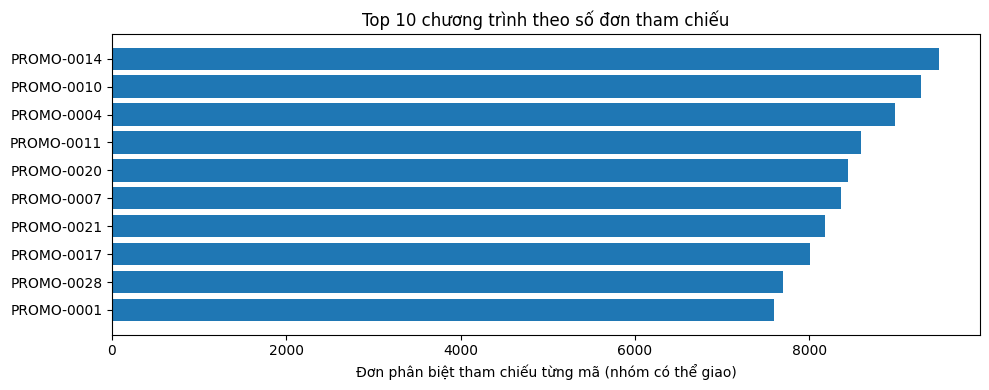

**Nhận xét.** 276,316/714,669 dòng có mã (38.66%); 248,242/646,945 đơn có mã. PROMO-0014 nhiều lượt nhất: 11,451 lượt và 9,487 đơn. Bảng so hạng kiểm tra riêng lượt/dòng/đơn/sản phẩm; mức phổ biến không chứng minh hiệu quả. Cần exposure và điều kiện áp dụng để giải thích quy mô.

In [17]:
coded62=i62.loc[i62._has_code]
single62=i62.loc[i62._slots.eq(1)].copy()
single62['_single_promo']=single62.promo_id.combine_first(single62.promo_id_2)
single62=single62.merge(prom[['promo_id','promo_type','discount_value']].rename(columns={'promo_id':'_single_promo'}),on='_single_promo',how='left',validate='many_to_one')
dual62=i62.loc[i62._slots.eq(2)].copy()
scale62=[
['Tổng đơn',len(o62),len(o62),'Đơn'],['Tổng dòng',len(i62),len(i62),'Dòng'],
['Dòng không mã',int(i62._slots.eq(0).sum()),len(i62),'Dòng'],
['Dòng có mã',len(coded62),len(i62),'Dòng'],['Dòng một vị trí mã',len(single62),len(i62),'Dòng'],
['Dòng hai vị trí / dòng có mã',len(dual62),len(coded62),'Dòng'],
['Đơn có mã',int(o62._has_code.sum()),len(o62),'Đơn'],['Đơn không mã',int((~o62._has_code).sum()),len(o62),'Đơn'],
['Chương trình có tham chiếu',r62.promo_id.nunique(),len(prom),'Chương trình'],
['Sản phẩm trên dòng có mã',coded62.product_id.nunique(),products.product_id.nunique(),'Sản phẩm'],
['Lượt vị trí mã',len(r62),None,'Lượt; không chia cho dòng']]
scale_df62=pd.DataFrame(scale62,columns=['Chỉ tiêu','Số lượng','Mẫu số','Đơn vị'])
scale_df62['Tỷ lệ (%)']=100*scale_df62['Số lượng']/scale_df62['Mẫu số'];show(scale_df62)
show([{'Đơn chỉ một chương trình':int(o62._codes.eq(1).sum()),'Đơn từ hai chương trình':int(o62._codes.ge(2).sum()),'Dòng bình quân/đơn có mã (mọi dòng)':o62.loc[o62._has_code,'_lines'].mean(),'Mã phân biệt bình quân/đơn có mã':o62.loc[o62._has_code,'_codes'].mean(),'Khách trong đơn có mã':o62.loc[o62._has_code,'customer_id'].nunique()}])
program_counts62=r62.groupby('promo_id').agg(refs=('_item_row_id','size'),lines=('_item_row_id','nunique'),orders=('order_id','nunique'),customers=('customer_id','nunique'),products=('product_id','nunique'),days=('_date','nunique'),months=('_month','nunique')).reset_index()
prog62=prom.merge(program_counts62,on='promo_id',how='left',validate='one_to_one')
for c in ['refs','lines','orders','customers','products','days','months']:prog62[c]=prog62[c].fillna(0).astype('int64')
rank_columns62={'refs':'Hạng lượt','lines':'Hạng dòng','orders':'Hạng đơn','products':'Hạng sản phẩm'}
for c,label in rank_columns62.items():prog62[label]=prog62[c].rank(method='min',ascending=False).astype(int)
show(prog62.rename(columns={'refs':'Lượt','lines':'Dòng khác nhau','orders':'Đơn khác nhau','customers':'Khách khác nhau','products':'Sản phẩm khác nhau','days':'Ngày đơn','months':'Tháng đơn'}),'Phạm vi từng chương trình; không cộng các cột phân biệt')
ranking62=[];ranking_orders62={}
for metric,label in [('refs','Lượt mã'),('lines','Dòng phân biệt'),('orders','Đơn phân biệt'),('products','Sản phẩm phân biệt')]:
    sorted62=prog62.sort_values([metric,'promo_id'],ascending=[False,True]);ranking_orders62[metric]=sorted62.promo_id.tolist()
    for pos,(_,row) in enumerate(sorted62.head(10).iterrows(),1):ranking62.append({'Tiêu chí':label,'Vị trí Top 10':pos,'Mã':row.promo_id,'Tên':row.promo_name,'Số lượng':int(row[metric]),'Hạng min':int(row[rank_columns62[metric]])})
show(ranking62,'Top chương trình theo bốn tiêu chí')
show([{'Cặp':a+' / '+b,'Thứ tự đủ 50 giống nhau':ranking_orders62[a]==ranking_orders62[b],'Tập Top 10 giống nhau':set(ranking_orders62[a][:10])==set(ranking_orders62[b][:10])} for a,b in itertools.combinations(rank_columns62,2)])
ck62('Ba nhóm bảo toàn dòng',int(i62._slots.value_counts().sum())==len(items) and len(coded62)==len(single62)+len(dual62))
ck62('Đơn có mã đối chiếu bảng dòng',int(o62._has_code.sum())==coded62.order_id.nunique())
ck62('Không cộng đơn theo chương trình làm tổng',set(r62.order_id)==set(o62.loc[o62._has_code,'order_id']) and int(o62._has_code.sum())==r62.order_id.nunique(),f'Cộng cột chương trình={prog62.orders.sum()}; hợp đơn={r62.order_id.nunique()}')
ck62('Tổng lượt theo chương trình bảo toàn',int(prog62.refs.sum())==len(r62))
ck62('Khách tham chiếu có ID khớp hồ sơ',r62.customer_id.isin(customers.customer_id).all())
fig,ax=plt.subplots(figsize=(10,4))
top62=prog62.sort_values(['orders','promo_id'],ascending=[False,True]).head(10).iloc[::-1]
ax.barh(top62.promo_id,top62.orders)
ax.set(xlabel='Đơn phân biệt tham chiếu từng mã (nhóm có thể giao)',title='Top 10 chương trình theo số đơn tham chiếu');figdone(fig)
leader62=prog62.sort_values(['refs','promo_id'],ascending=[False,True]).iloc[0]
note(f"**Nhận xét.** {len(coded62):,}/{len(i62):,} dòng có mã ({len(coded62)/len(i62)*100:.2f}%); {o62._has_code.sum():,}/{len(o62):,} đơn có mã. {leader62.promo_id} nhiều lượt nhất: {leader62.refs:,} lượt và {leader62.orders:,} đơn. Bảng so hạng kiểm tra riêng lượt/dòng/đơn/sản phẩm; mức phổ biến không chứng minh hiệu quả. Cần exposure và điều kiện áp dụng để giải thích quy mô.")

### NV06.2.5–6 — Tiền theo nhóm dòng và liên hệ từng chương trình
Gross = quantity × unit_price; Discount = discount_amount một lần/dòng; Net số học = Gross − Discount. Tính bằng số nguyên phần trăm ĐVT; không gọi Net là thực thu. Bảng tiền theo chương trình chỉ chứa **đúng một vị trí mã**. Mẫu số tỷ trọng là tổng Discount của tập một vị trí, không phải toàn kỳ.

Tỷ lệ tổng Discount/tổng Gross dùng tổng tiền làm mẫu số; trung bình tỷ lệ từng dòng cho mỗi dòng trọng số bằng nhau. Chỉ tính khi Gross tương ứng >0; số dòng hợp lệ được báo rõ. Số đơn giữa các nhóm dòng có thể giao nhau; tổng tiền/dòng của ba nhóm không giao nhau thì cộng được.

Hiển thị tổng tiền bằng Decimal với 2 chữ số thập phân; mean/median tối đa 6 chữ số. Các phép tính và kiểm chứng vẫn dùng số nguyên phần trăm ĐVT.


In [18]:
def fin62(d,keys):
    keys=[keys] if isinstance(keys,str) else keys
    t=d.groupby(keys,dropna=False,observed=True).agg(rows=('_item_row_id','size'),orders=('order_id','nunique'),coded_rows=('_has_code','sum'),coded_orders=('_coded_order_id','nunique'),quantity=('_qty','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_mean_c=('_discount_c','mean'),_median_c=('_discount_c','median'),mean_line_pct=('_line_pct','mean'),valid_ratio_rows=('_line_pct','count')).reset_index()
    t['weighted_pct']=(100*t._discount_c/t._gross_c).where(t._gross_c.gt(0));t['coded_pct']=100*t.coded_rows/t.rows
    return t
def view62(t):
    t=t.copy()
    def money_text62(value,digits):
        if pd.isna(value):return '∅'
        text=format(Decimal(str(value))/Decimal(100),f',.{digits}f')
        if digits==6:text=text.rstrip('0').rstrip('.')
        return text.replace(',','_').replace('.',',').replace('_','.')
    for c in ['_gross_c','_discount_c','_net_c','_mean_c','_median_c']:
        if c in t:t[c]=t[c].map(lambda v:money_text62(v,6 if c in ['_mean_c','_median_c'] else 2))
    if '_year' in t:t['_year']=t['_year'].astype(str)
    return t.rename(columns={'rows':'Dòng','orders':'Đơn phân biệt','coded_rows':'Dòng có mã','coded_orders':'Đơn có dòng mã','quantity':'Quantity','_gross_c':'Gross (ĐVT)','_discount_c':'Discount (ĐVT)','_net_c':'Net số học (ĐVT)','_mean_c':'Mean Discount/dòng (ĐVT)','_median_c':'Median Discount/dòng (ĐVT)','mean_line_pct':'TB tỷ lệ dòng (%)','valid_ratio_rows':'Dòng Gross dương','weighted_pct':'Tổng Discount/Gross (%)','coded_pct':'Dòng có mã/tổng dòng (%)'})
groups62=fin62(i62,'_group')
show(view62(groups62),'Ba nhóm không giao nhau, mỗi khoản tiền một lần')
ratio62=i62.groupby('_group')._line_pct.quantile([0,.1,.5,.9,.95,.99,1]).unstack().reset_index()
show(ratio62.rename(columns={'_group':'Nhóm',0:'Min',.1:'P10',.5:'P50',.9:'P90',.95:'P95',.99:'P99',1:'Max'}),'Phân vị Discount/Gross từng dòng (%), chỉ Gross >0')
single_fin62=fin62(single62,'_single_promo').rename(columns={'_single_promo':'promo_id'})
single_fin62['Tỷ trọng Discount tập một mã (%)']=100*single_fin62._discount_c/int(single62._discount_c.sum())
single_program62=prog62[['promo_id','promo_name','promo_type','refs','orders']].rename(columns={'refs':'Lượt mọi dòng','orders':'Đơn mọi dòng'}).merge(single_fin62,on='promo_id',how='left',validate='one_to_one')
show(view62(single_program62),'Giảm giá ghi nhận trên các dòng chỉ tham chiếu một chương trình; không phân bổ hai mã')
ck62('Ba nhóm bảo toàn Gross/Discount/Net',all(int(groups62[c].sum())==int(i62[c].sum()) for c in ['_gross_c','_discount_c','_net_c']))
ck62('Net đúng từng dòng',i62._net_c.eq(i62._gross_c-i62._discount_c).all())
ck62('Tiền theo chương trình một mã bảo toàn',int(single_fin62._discount_c.sum())==int(single62._discount_c.sum()))
ck62('Tỷ trọng một mã dùng đúng mẫu số',abs(single_fin62['Tỷ trọng Discount tập một mã (%)'].sum()-100)<1e-9)
ck62('Hai mã không nhân đôi Discount',int(dual62._discount_c.sum()+single62._discount_c.sum()+i62.loc[~i62._has_code,'_discount_c'].sum())==int(discount_c.sum()))
show([{'Tập':'Một vị trí','Dòng':len(single62),'Discount (ĐVT)':int(single62._discount_c.sum())/100,'Tỷ trọng toàn Discount (%)':100*single62._discount_c.sum()/discount_c.sum()},
{'Tập':'Hai vị trí, giữ riêng','Dòng':len(dual62),'Discount (ĐVT)':int(dual62._discount_c.sum())/100,'Tỷ trọng toàn Discount (%)':100*dual62._discount_c.sum()/discount_c.sum()}])
note(f"**Nhận xét.** Một vị trí mã ghi {vn(int(single62._discount_c.sum())/100)} ĐVT giảm giá; hai vị trí ghi {vn(int(dual62._discount_c.sum())/100)} ĐVT và được giữ riêng. Ba nhóm bảo toàn {vn(int(discount_c.sum())/100)} ĐVT. Tiền theo chương trình là tiền trên dòng một mã, chưa chứng minh phần giảm do chương trình tạo ra. Cần công thức sinh discount_amount trước khi kiểm tra discount_value hoặc quy thuộc.")

**Ba nhóm không giao nhau, mỗi khoản tiền một lần**

_group,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%)
Hai vị trí mã,206,205,206,205,835,"6.301.765,62","640.476,62","5.661.289,00","3.109,109806","2.708,535","10,319935",206,"10,163447",100
Không mã,438.353,398.972,0,0,1.971.104,"10.995.039.052,90","0,00","10.995.039.052,90",0,0,0,438.353,0,0
Một vị trí mã,276.110,248.037,276.110,248.037,1.241.204,"5.429.135.767,01","748.966.843,48","4.680.168.923,53","2.712,566888","1.627,69","14,305386",276.110,"13,795324",100


**Phân vị Discount/Gross từng dòng (%), chỉ Gross >0**

Nhóm,Min,P10,P50,P90,P95,P99,Max
Hai vị trí mã,"10,038242","10,082621","10,188074","10,627057","11,091467","11,755522","12,715777"
Không mã,0,0,0,0,0,0,0
Một vị trí mã,"0,414354","9,999974","14,999574",20,"20,000032","20,000163","20,000747"


**Giảm giá ghi nhận trên các dòng chỉ tham chiếu một chương trình; không phân bổ hai mã**

promo_id,promo_name,promo_type,Lượt mọi dòng,Đơn mọi dòng,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%),Tỷ trọng Discount tập một mã (%)
PROMO-0001,Spring Sale 2013,percentage,8.523,7.599,8.523,7.599,8.523,7.599,38.351,"162.063.135,66","19.447.576,15","142.615.559,51","2.281,775918","1.482,54",12,8.523,12,100,"2,596587"
PROMO-0002,Mid-Year Sale 2013,percentage,7.754,6.956,7.754,6.956,7.754,6.956,35.152,"144.423.191,04","25.996.174,60","118.427.016,44","3.352,614728","2.194,5",18,7.754,18,100,"3,470938"
PROMO-0003,Fall Launch 2013,percentage,6.277,5.632,6.277,5.632,6.277,5.632,28.142,"130.294.888,64","13.029.489,80","117.265.398,84","2.075,751123","1.360,67","10,000002",6.277,"10,000001",100,"1,739662"
PROMO-0004,Year-End Sale 2013,percentage,11.126,8.985,11.126,8.985,11.126,8.985,50.057,"127.322.933,58","25.464.586,91","101.858.346,67","2.288,745902","1.175,44",20,11.126,20,100,"3,399962"
PROMO-0005,Urban Blowout 2013,fixed,4.887,4.831,4.887,4.831,4.887,4.831,22.048,"82.021.991,91","1.102.400,00","80.919.591,91","225,578064",250,"1,664945",4.887,"1,34403",100,"0,147189"
PROMO-0006,Rural Special 2013,percentage,2.828,2.199,2.828,2.199,2.828,2.199,12.607,"23.748.011,74","3.562.201,58","20.185.810,16","1.259,618663","879,8",15,2.828,"14,999999",100,"0,475615"
PROMO-0007,Spring Sale 2014,percentage,9.373,8.367,9.373,8.367,9.373,8.367,41.949,"184.829.965,79","22.179.596,04","162.650.369,75","2.366,328394","1.612,15",12,9.373,12,100,"2,961359"
PROMO-0008,Mid-Year Sale 2014,percentage,7.089,6.394,7.089,6.394,7.089,6.394,32.116,"133.758.180,20","24.076.472,47","109.681.707,73","3.396,314356","2.270,2",18,7.089,18,100,"3,214625"
PROMO-0009,Fall Launch 2014,percentage,5.637,5.064,5.637,5.064,5.637,5.064,25.543,"113.762.847,30","11.376.285,26","102.386.562,04","2.018,145336","1.315,2","10,000001",5.637,10,100,"1,51893"
PROMO-0010,Year-End Sale 2014,percentage,11.345,9.287,11.345,9.287,11.345,9.287,50.940,"140.071.090,17","28.014.217,70","112.056.872,47","2.469,300811","1.286,58",20,11.345,20,100,"3,740382"


Tập,Dòng,Discount (ĐVT),Tỷ trọng toàn Discount (%)
Một vị trí,276.110,"748.966.843,48","99,914558"
"Hai vị trí, giữ riêng",206,"640.476,62","0,085442"


**Nhận xét.** Một vị trí mã ghi 748.966.843,48 ĐVT giảm giá; hai vị trí ghi 640.476,62 ĐVT và được giữ riêng. Ba nhóm bảo toàn 749.607.320,1 ĐVT. Tiền theo chương trình là tiền trên dòng một mã, chưa chứng minh phần giảm do chương trình tạo ra. Cần công thức sinh discount_amount trước khi kiểm tra discount_value hoặc quy thuộc.

### NV06.2.7 — Loại chương trình: tách cấp chương trình, lượt và dòng một mã
Phân bố catalogue, tham chiếu và tiền có mẫu số khác nhau. Đơn tham chiếu nhiều loại có thể được đếm ở nhiều loại; không cộng số đơn các loại làm tổng đơn có mã. Không coi percentage bắt buộc discount_value × Gross, hoặc fixed bắt buộc giảm 50 mỗi dòng khi chưa có công thức áp dụng.

In [19]:
pt62=prom.assign(_value=pd.to_numeric(prom.discount_value),_duration=(dates(prom.end_date)-dates(prom.start_date)).dt.days,_used=prom.promo_id.isin(r62.promo_id)).groupby('promo_type',dropna=False).agg(Chương_trình=('promo_id','size'),Giá_trị_min=('_value','min'),Giá_trị_max=('_value','max'),Giá_trị_median=('_value','median'),Thời_lượng_min=('_duration','min'),Thời_lượng_max=('_duration','max'),Thời_lượng_mean=('_duration','mean'),Có_tham_chiếu=('_used','sum')).reset_index()
ptrefs62=r62.groupby('promo_type',dropna=False).agg(Lượt=('_item_row_id','size'),Dòng=('_item_row_id','nunique'),Đơn=('order_id','nunique')).reset_index()
show(pt62.merge(ptrefs62,on='promo_type',validate='one_to_one'),'Loại chương trình: catalogue và tham chiếu toàn bộ')
type_money62=fin62(single62,'promo_type')
show(view62(type_money62),'Tiền chỉ trên dòng một vị trí mã theo promo_type')
type_orders62=r62.groupby('order_id').promo_type.nunique()
show([{'Đơn tham chiếu nhiều loại':int(type_orders62.gt(1).sum()),'Đơn phân biệt có mã':r62.order_id.nunique(),'Cộng đơn riêng từng loại (không dùng làm tổng)':int(ptrefs62.Đơn.sum())}])
ck62('Loại chương trình bảo toàn catalogue và lượt',int(pt62.Chương_trình.sum())==len(prom) and int(ptrefs62.Lượt.sum())==len(r62))
ck62('Tiền theo loại chỉ dùng dòng một mã',int(type_money62._discount_c.sum())==int(single62._discount_c.sum()) and int(type_money62.rows.sum())==len(single62))
type_leader62=ptrefs62.sort_values('Lượt',ascending=False).iloc[0]
note(f"**Nhận xét.** Loại {type_leader62.promo_type} có {type_leader62['Lượt']:,} lượt mã ghi nhận, lớn nhất trong tập. Có {type_orders62.gt(1).sum()} đơn tham chiếu nhiều loại. Tiền giữa các loại chỉ so trên dòng một mã; các nhóm khác quy mô và điều kiện nên chưa kết luận loại nào tốt hơn. Cần công thức giảm, mẫu số exposure và mục tiêu kinh doanh.")

**Loại chương trình: catalogue và tham chiếu toàn bộ**

promo_type,Chương_trình,Giá_trị_min,Giá_trị_max,Giá_trị_median,Thời_lượng_min,Thời_lượng_max,Thời_lượng_mean,Có_tham_chiếu,Lượt,Dòng,Đơn
fixed,5,50,50,50,34,34,34,5,21.156,21.156,20.946
percentage,45,10,20,15,29,45,"33,488889",45,255.366,255.366,227.501


**Tiền chỉ trên dòng một vị trí mã theo promo_type**

promo_type,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%)
fixed,20.950,20.741,20.950,20.741,94.531,"376.473.741,30","4.726.550,00","371.747.191,30","225,610979",250,"1,586023",20.950,"1,255479",100
percentage,255.160,227.296,255.160,227.296,1.146.673,"5.052.662.025,71","744.240.293,48","4.308.421.732,23","2.916,759263","1.845,635","15,349714",255.160,"14,729667",100


Đơn tham chiếu nhiều loại,Đơn phân biệt có mã,Cộng đơn riêng từng loại (không dùng làm tổng)
205,248.242,248.447


**Nhận xét.** Loại percentage có 255,366 lượt mã ghi nhận, lớn nhất trong tập. Có 205 đơn tham chiếu nhiều loại. Tiền giữa các loại chỉ so trên dòng một mã; các nhóm khác quy mô và điều kiện nên chưa kết luận loại nào tốt hơn. Cần công thức giảm, mẫu số exposure và mục tiêu kinh doanh.

### NV06.2.8 — Hai trục thời gian: catalogue và order_date
Catalogue: đếm chương trình giao tháng theo hai biên bao gồm; **ngày có ≥1 chương trình** là hợp ngày lịch, còn **ngày–chương trình** cộng riêng từng chương trình nên có thể lớn hơn số ngày trong tháng. Đỉnh giao nhau là số chương trình tối đa trên một ngày, chưa phải cùng áp dụng giao dịch.

Giao dịch: tổng hợp dòng gốc theo order_date, đối chiếu số dòng/đơn toàn kỳ làm mẫu số của kỳ. Tỷ lệ Discount/Gross của dòng có mã chỉ dùng Gross tập có mã. Độ phủ năm/tháng được báo để tránh so năm 2012 thiếu đầu năm với năm đủ. Kiểm tra order_id có đúng một kỳ trước khi cộng số đơn qua kỳ.

**Khoảng mô tả trong catalogue, không phải giao dịch khuyến mãi**

Tháng,Chương trình bắt đầu,Chương trình giao tháng,Ngày lịch trong phần quan sát,Ngày có ≥1 chương trình,Ngày–chương trình,Đỉnh số chương trình/ngày,Ngày nhiều chương trình
2012-07,0,0,28,0,0,0,0
2012-08,0,0,31,0,0,0,0
2012-09,0,0,30,0,0,0,0
2012-10,0,0,31,0,0,0,0
2012-11,0,0,30,0,0,0,0
2012-12,0,0,31,0,0,0,0
2013-01,1,1,31,1,1,1,0
2013-02,0,1,28,28,28,1,0
2013-03,1,2,31,15,15,1,0
2013-04,0,1,30,17,17,1,0


**Chương trình bắt đầu theo năm và loại**

Năm bắt đầu,fixed,percentage
2.013,1,5
2.014,0,4
2.015,1,5
2.016,0,4
2.017,1,5
2.018,0,4
2.019,1,5
2.020,0,4
2.021,1,5
2.022,0,4


**Theo năm order_date: tiền tập dòng có mã và mẫu số toàn kỳ**

_year,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Tổng dòng kỳ,Tổng đơn kỳ,Đơn có mã của kỳ,Lượt mã,Dòng có mã/tổng dòng kỳ (%),Đơn có mã/tổng đơn kỳ (%),Ngày order_date có dữ liệu,Ngày lịch cả kỳ
2012,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,37.007,32.051,0,0,0,0,181,366
2013,40.529,35.538,40.529,35.538,182.498,"661.883.250,20","87.004.248,57","574.879.001,63","2.146,715897","1.136,56","13,826509",40.529,"13,144954",87.341,76.849,35.538,40.529,"46,403178","46,243933",365,365
2014,33.965,29.510,33.965,29.510,152.858,"576.705.064,41","86.503.167,66","490.201.896,75","2.546,832553","1.523,64","15,715237",33.965,"14,999551",91.086,80.645,29.510,33.965,"37,288936","36,592473",365,365
2015,42.988,38.118,42.988,38.118,193.073,"744.577.803,88","97.923.860,36","646.653.943,52","2.277,934781","1.249,895","13,699421",42.988,"13,151595",92.537,82.622,38.118,43.120,"46,454932","46,135412",365,365
2016,31.882,28.367,31.882,28.367,143.440,"621.586.211,40","92.276.211,92","529.309.999,48","2.894,30437","1.884,43","15,537544",31.882,"14,84528",90.895,82.247,28.367,31.882,"35,075637","34,490012",366,366
2017,37.193,33.654,37.193,33.654,167.192,"733.069.687,57","95.617.691,30","637.451.996,27","2.570,851808","1.538,76","13,298229",37.193,"13,043465",83.691,76.010,33.654,37.267,"44,44086","44,275753",365,365
2018,25.250,23.150,25.250,23.150,113.659,"544.401.753,32","80.399.276,46","464.002.476,86","3.184,129761","2.217,545","15,258772",25.250,"14,768372",75.132,69.510,23.150,25.250,"33,607517","33,30456",365,365
2019,20.244,18.603,20.244,18.603,90.979,"436.354.158,76","55.211.860,32","381.142.298,44","2.727,319715","1.592,295","13,04756",20.244,"12,652993",44.925,41.601,18.603,20.244,"45,06177","44,717675",365,365
2020,13.654,12.714,13.654,12.714,61.415,"337.376.967,30","48.403.622,41","288.973.344,89","3.545,014092","2.419,51","14,919731",13.654,"14,347044",37.238,34.881,12.714,13.654,"36,666846","36,449643",366,366
2021,16.447,15.303,16.447,15.303,73.381,"405.360.380,43","51.825.645,91","353.534.734,52","3.151,069855","1.844,4","12,93494",16.447,"12,785079",36.749,34.525,15.303,16.447,"44,754959","44,324403",365,365


**Theo tháng order_date, gồm cả các kỳ không có mã**

_month,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Tổng dòng kỳ,Tổng đơn kỳ,Đơn có mã của kỳ,Lượt mã,Dòng có mã/tổng dòng kỳ (%),Đơn có mã/tổng đơn kỳ (%),Ngày order_date có dữ liệu,Ngày lịch cả kỳ
2012-07,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,5.887,5.294,0,0,0,0,28,31
2012-08,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,7.166,6.427,0,0,0,0,31,31
2012-09,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,5.857,5.219,0,0,0,0,30,30
2012-10,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,4.877,4.285,0,0,0,0,31,31
2012-11,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,4.877,4.142,0,0,0,0,30,30
2012-12,0,0,0,0,0,"0,00","0,00","0,00",∅,∅,∅,0,∅,8.343,6.684,0,0,0,0,31,31
2013-01,21,17,21,17,71,"154.847,63","23.227,14","131.620,49","1.106,054286","772,03","15,000009",21,"14,999997",4.216,3.665,17,21,"0,498102","0,463847",31,31
2013-02,2.705,2.104,2.705,2.104,12.095,"22.816.458,92","3.422.468,64","19.393.990,28","1.265,237945","893,87","14,999999",2.705,"14,999999",5.309,4.661,2.104,2.705,"50,951215","45,140528",28,28
2013-03,4.573,4.058,4.573,4.058,20.747,"85.547.206,59","10.288.965,87","75.258.240,72","2.249,937868","1.490,52","12,066915",4.573,"12,027238",7.461,6.590,4.058,4.573,"61,292052","61,578149",31,31
2013-04,4.052,3.619,4.052,3.619,18.045,"77.292.634,26","9.275.116,08","68.017.518,18","2.289,021737","1.429,615",12,4.052,12,9.936,8.874,3.619,4.052,"40,780998","40,78206",30,30


**Đối chiếu năm đầu ngoài phạm vi catalogue**

Năm,Dòng có mã,Đơn có mã,Lượt mã,Chương trình catalogue bắt đầu 2012
2.012,0,0,0,0


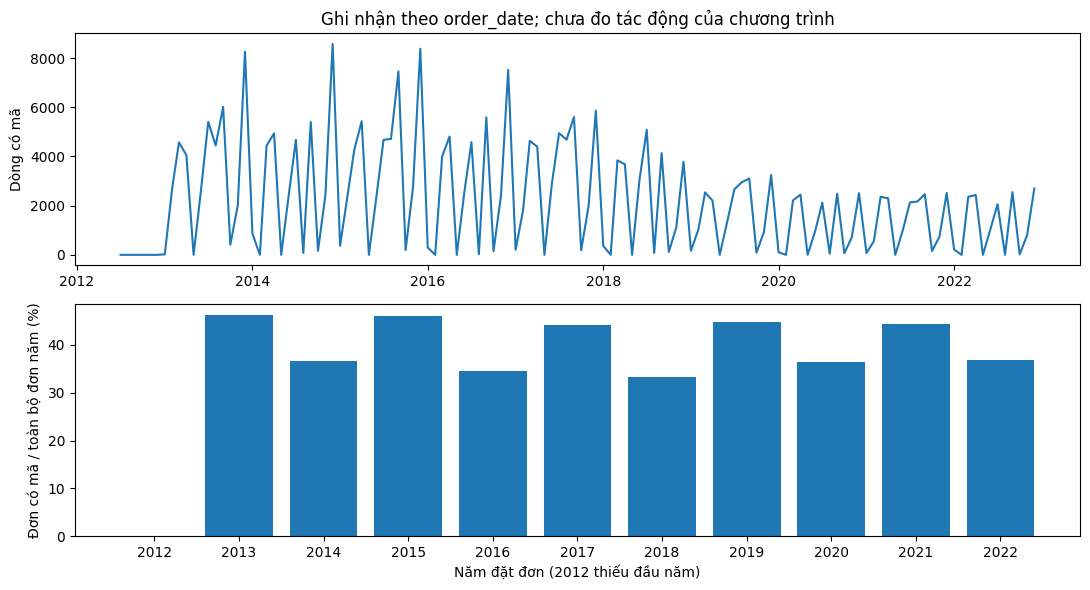

**Nhận xét.** Năm 2012 có 0 dòng mã; catalogue có 1,707 ngày được ít nhất một khoảng mô tả bao phủ và đỉnh 2 chương trình/ngày. Bảng tháng tách các khoảng catalogue khỏi giao dịch có mã; tổng qua kỳ chỉ cộng sau kiểm tra mỗi đơn có một ngày. Chênh lệch theo thời gian chưa kiểm soát mùa vụ, giá hay khách; cần đối chứng trước nhận định tác động.

In [20]:
calendar_dates62=pd.date_range(min(od.min(),ps.min()),max(od.max(),pe.max()),freq='D')
active62=np.zeros(len(calendar_dates62),dtype=int)
for a,b in zip(ps,pe):active62+=((calendar_dates62>=a)&(calendar_dates62<=b)).astype(int)
cal62=pd.DataFrame({'_date':calendar_dates62,'_active':active62})
cal62['_month']=cal62._date.dt.to_period('M').astype(str)
catalog_month62=[]
for period,g in cal62.groupby('_month'):
    start=pd.Period(period,'M').start_time;end=pd.Period(period,'M').end_time.normalize()
    catalog_month62.append({'Tháng':period,'Chương trình bắt đầu':int(((ps>=start)&(ps<=end)).sum()),'Chương trình giao tháng':int(((ps<=end)&(pe>=start)).sum()),'Ngày lịch trong phần quan sát':len(g),'Ngày có ≥1 chương trình':int(g._active.gt(0).sum()),'Ngày–chương trình':int(g._active.sum()),'Đỉnh số chương trình/ngày':int(g._active.max()),'Ngày nhiều chương trình':int(g._active.gt(1).sum())})
catalog_month62=pd.DataFrame(catalog_month62)
show(catalog_month62,'Khoảng mô tả trong catalogue, không phải giao dịch khuyến mãi')
catalog_year62=pd.crosstab(ps.dt.year,prom.promo_type).reset_index().rename(columns={'start_date':'Năm bắt đầu'})
show(catalog_year62,'Chương trình bắt đầu theo năm và loại')
def time62(key):
    t=fin62(coded62,key)
    all_lines=i62.groupby(key).size(); all_orders=o62.groupby(key).size()
    coded_orders=o62.loc[o62._has_code].groupby(key).size()
    t['Tổng dòng kỳ']=t[key].map(all_lines);t['Tổng đơn kỳ']=t[key].map(all_orders)
    t['Đơn có mã của kỳ']=t[key].map(coded_orders).fillna(0).astype(int)
    t['Lượt mã']=t[key].map(r62.groupby(key).size()).fillna(0).astype(int)
    t['Dòng có mã/tổng dòng kỳ (%)']=100*t.rows/t['Tổng dòng kỳ']
    t['Đơn có mã/tổng đơn kỳ (%)']=100*t['Đơn có mã của kỳ']/t['Tổng đơn kỳ']
    t['Ngày order_date có dữ liệu']=t[key].map(i62.groupby(key)._date.nunique())
    # Giữ cả kỳ không có dòng mã (2012), không tự bỏ kỳ rỗng.
    skeleton=o62.groupby(key).agg(Tổng_dòng=('_lines','sum'),Tổng_đơn=('order_id','size'),Ngày=('_date','nunique')).reset_index()
    t=skeleton[[key]].merge(t,on=key,how='left',validate='one_to_one')
    for c in ['rows','orders','coded_rows','coded_orders','quantity','_gross_c','_discount_c','_net_c','valid_ratio_rows','Lượt mã','Đơn có mã của kỳ']:t[c]=t[c].fillna(0).astype('int64')
    t['Tổng dòng kỳ']=t[key].map(i62.groupby(key).size());t['Tổng đơn kỳ']=t[key].map(o62.groupby(key).size())
    t['Ngày order_date có dữ liệu']=t[key].map(o62.groupby(key)._date.nunique())
    t['Ngày lịch cả kỳ']=t[key].map(lambda x: (366 if calendar.isleap(int(x)) else 365) if key=='_year' else pd.Period(x,'M').days_in_month)
    t['Dòng có mã/tổng dòng kỳ (%)']=100*t.rows/t['Tổng dòng kỳ'];t['Đơn có mã/tổng đơn kỳ (%)']=100*t['Đơn có mã của kỳ']/t['Tổng đơn kỳ']
    return t.drop(columns=['coded_pct'])
year62=time62('_year');month62=time62('_month')
show(view62(year62),'Theo năm order_date: tiền tập dòng có mã và mẫu số toàn kỳ')
show(view62(month62),'Theo tháng order_date, gồm cả các kỳ không có mã')
ck62('Mỗi đơn thuộc đúng một ngày/kỳ',i62.groupby('order_id')._date.nunique().eq(1).all())
for name,t in [('năm',year62),('tháng',month62)]:
    ck62('Tổng hợp '+name+' bảo toàn dòng, lượt, đơn và tiền',int(t.rows.sum())==len(coded62) and int(t['Lượt mã'].sum())==len(r62) and int(t['Đơn có mã của kỳ'].sum())==coded62.order_id.nunique() and int(t._discount_c.sum())==int(coded62._discount_c.sum()))
ck62('Ngày catalogue bao gồm đủ hai biên',int(cal62._active.sum())==int(((pe-ps).dt.days+1).sum()))
coded_2012_62=int(i62.loc[i62._year.eq(2012),'_has_code'].sum())
show([{'Năm':2012,'Dòng có mã':coded_2012_62,'Đơn có mã':int(o62.loc[o62._year.eq(2012),'_has_code'].sum()),'Lượt mã':int(r62._year.eq(2012).sum()),'Chương trình catalogue bắt đầu 2012':int(ps.dt.year.eq(2012).sum())}],'Đối chiếu năm đầu ngoài phạm vi catalogue')
fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(pd.to_datetime(month62._month),month62.rows)
axs[0].set(ylabel='Dòng có mã',title='Ghi nhận theo order_date; chưa đo tác động của chương trình')
axs[1].bar(year62._year.astype(str),year62['Đơn có mã/tổng đơn kỳ (%)'])
axs[1].set(xlabel='Năm đặt đơn (2012 thiếu đầu năm)',ylabel='Đơn có mã / toàn bộ đơn năm (%)');figdone(fig)
note(f"**Nhận xét.** Năm 2012 có {coded_2012_62} dòng mã; catalogue có {cal62._active.gt(0).sum():,} ngày được ít nhất một khoảng mô tả bao phủ và đỉnh {cal62._active.max()} chương trình/ngày. Bảng tháng tách các khoảng catalogue khỏi giao dịch có mã; tổng qua kỳ chỉ cộng sau kiểm tra mỗi đơn có một ngày. Chênh lệch theo thời gian chưa kiểm soát mùa vụ, giá hay khách; cần đối chứng trước nhận định tác động.")

### NV06.2.9–10 — Đối chiếu lịch và danh mục từng mã–dòng
Mỗi lượt mã được so độc lập: trước start_date, trong [start_date,end_date] hoặc sau end_date; hai đầu bao gồm. Số dòng/đơn chịu ảnh hưởng lấy **hợp ID phân biệt**, không cộng các nhóm mã.

Danh mục so nguyên nhãn promotion với danh mục sản phẩm hiện hành. applicable_category NULL được giữ nguyên và đánh dấu “Chưa xác định phạm vi danh mục từ trường nguồn”. Khác nhãn chưa chứng minh áp dụng sai, vì chưa xác minh danh mục lịch sử, phân cấp hay chính sách.

In [21]:
r62['_start']=dates(r62.start_date);r62['_end']=dates(r62.end_date)
r62['_valid_window']=r62['_date'].notna()&r62._start.notna()&r62._end.notna()&r62._start.le(r62._end)&r62.promo_id.isin(prom.promo_id)
r62['_window']=np.select([~r62._valid_window,r62['_date'].lt(r62._start),r62['_date'].gt(r62._end)],['Chưa xác định','Trước','Sau'],default='Trong')
r62['_before_days']=(r62._start-r62['_date']).dt.days.where(r62._window.eq('Trước'))
r62['_after_days']=(r62['_date']-r62._end).dt.days.where(r62._window.eq('Sau'))
def scope62(d,key,states=None):
    t=d.groupby(key,dropna=False).agg(Lượt=('_item_row_id','size'),Dòng=('_item_row_id','nunique'),Đơn=('order_id','nunique'),Chương_trình=('promo_id','nunique'),Sản_phẩm=('product_id','nunique'))
    if states is not None:t=t.reindex(states,fill_value=0)
    return t.reset_index()
date_scope62=scope62(r62,'_window',['Trước','Trong','Sau','Chưa xác định'])
show(date_scope62,'Theo lượt mã và hợp ID trong từng nhóm lịch')
show(r62.groupby('_window').agg(Lệch_trước_min=('_before_days','min'),Lệch_trước_max=('_before_days','max'),Lệch_sau_min=('_after_days','min'),Lệch_sau_max=('_after_days','max')).reset_index(),'Số ngày lệch: chỉ có nghĩa cho lượt trước/sau')
outside62=r62.loc[~r62._window.eq('Trong')]
tracecols62=['_item_row_id','order_id','product_id','promo_id','_slot','order_date','start_date','end_date','_window']
show(outside62[tracecols62].head(12),'Ví dụ ngoài khoảng/chưa xác định: tối đa 12 dòng; rỗng nghĩa không có')
show(r62[tracecols62].head(5),'Ví dụ truy vết lượt trong dữ liệu nguồn (ID kỹ thuật bắt đầu 0)')
r62['_category_state']=np.select([
r62.applicable_category.isna().to_numpy(),
r62.category.isna().to_numpy(),
r62.applicable_category.eq(r62.category).fillna(False).to_numpy(dtype=bool)],
['Chưa xác định phạm vi danh mục từ trường nguồn','Thiếu danh mục sản phẩm','Khớp nhãn'],default='Khác nhãn')
category_scope62=scope62(r62,'_category_state')
show(category_scope62,'Mỗi lượt mã–dòng được đối chiếu; không cộng số dòng phân biệt các nhóm')
show([{'Chương trình có danh mục rõ':int(prom.applicable_category.notna().sum()),'Chương trình NULL danh mục':int(prom.applicable_category.isna().sum()),'Dòng thuộc tham chiếu có danh mục rõ':r62.loc[r62.applicable_category.notna(),'_item_row_id'].nunique(),'Dòng có ít nhất một lượt khác nhãn':r62.loc[r62._category_state.eq('Khác nhãn'),'_item_row_id'].nunique(),'Đơn có ít nhất một lượt khác nhãn':r62.loc[r62._category_state.eq('Khác nhãn'),'order_id'].nunique()}])
show(r62.loc[r62._category_state.eq('Khác nhãn'),['_item_row_id','order_id','product_id','promo_id','applicable_category','category','_slot']].head(12),'Ví dụ khác nhãn, chưa kết luận vi phạm chính sách')
ck62('Lịch bảo toàn lượt',int(date_scope62.Lượt.sum())==len(r62))
ck62('Hai biên lịch dùng bao gồm',r62.loc[r62._window.eq('Trong'),'_date'].ge(r62.loc[r62._window.eq('Trong'),'_start']).all() and r62.loc[r62._window.eq('Trong'),'_date'].le(r62.loc[r62._window.eq('Trong'),'_end']).all())
ck62('Danh mục bảo toàn lượt',int(category_scope62.Lượt.sum())==len(r62))
ck62('NULL danh mục không đổi và không chấm đúng/sai',r62.applicable_category.isna().equals(r62._category_state.eq('Chưa xác định phạm vi danh mục từ trường nguồn')))
ck62('Danh mục lấy đúng sản phẩm',i62.category.equals(i62.product_id.map(products.set_index('product_id').category)))
note(f"**Nhận xét.** {len(outside62):,} lượt ngoài khoảng/chưa xác định; {r62.loc[r62._category_state.eq('Khác nhãn'),'_item_row_id'].nunique():,} dòng có ít nhất một lượt khác nhãn. {prom.applicable_category.isna().sum()} chương trình chưa xác định phạm vi danh mục từ nguồn. Các số là đối chiếu lịch/nhãn, chưa chứng minh lỗi ưu đãi. Cần thời điểm áp dụng, lịch sử danh mục và quy tắc phân cấp để xác minh.")

**Theo lượt mã và hợp ID trong từng nhóm lịch**

_window,Lượt,Dòng,Đơn,Chương_trình,Sản_phẩm
Trước,0,0,0,0,0
Trong,276.522,276.316,248.242,50,1.495
Sau,0,0,0,0,0
Chưa xác định,0,0,0,0,0


**Số ngày lệch: chỉ có nghĩa cho lượt trước/sau**

_window,Lệch_trước_min,Lệch_trước_max,Lệch_sau_min,Lệch_sau_max
Trong,∅,∅,∅,∅


**Ví dụ ngoài khoảng/chưa xác định: tối đa 12 dòng; rỗng nghĩa không có**

_item_row_id,order_id,product_id,promo_id,_slot,order_date,start_date,end_date,_window


... (4 outputs left out)

Chương trình có danh mục rõ,Chương trình NULL danh mục,Dòng thuộc tham chiếu có danh mục rõ,Dòng có ít nhất một lượt khác nhãn,Đơn có ít nhất một lượt khác nhãn
10,40,30.061,0,0


**Ví dụ khác nhãn, chưa kết luận vi phạm chính sách**

_item_row_id,order_id,product_id,promo_id,applicable_category,category,_slot


**Nhận xét.** 0 lượt ngoài khoảng/chưa xác định; 0 dòng có ít nhất một lượt khác nhãn. 40 chương trình chưa xác định phạm vi danh mục từ nguồn. Các số là đối chiếu lịch/nhãn, chưa chứng minh lỗi ưu đãi. Cần thời điểm áp dụng, lịch sử danh mục và quy tắc phân cấp để xác minh.

### NV06.2.11 — min_order_value: hai phép so ứng viên ở cấp đơn
Gross/Discount/Net được tổng hợp từ **toàn bộ dòng của đơn**, trước khi JOIN mã. Sau đó mới so Order Gross ≥ ngưỡng và Order Net ≥ ngưỡng; không chọn cách nào là chính sách chính thức.

Ngưỡng 0 vẫn so như số nguồn: Gross/Net không âm đạt phép so số học. Điều này chưa chứng minh đủ mọi điều kiện nhận ưu đãi. Mẫu số đếm lượt mã; đơn/chương trình phân biệt báo riêng để thấy sự giao nhau.

In [22]:
threshold62=r62[['_item_row_id','order_id','promo_id','_slot','min_order_value']].merge(o62[['order_id','_gross_c','_net_c']].rename(columns={'_gross_c':'_order_gross_c','_net_c':'_order_net_c'}),on='order_id',how='left',validate='many_to_one')
threshold62['_threshold_c']=cents(threshold62.min_order_value)
threshold62['_gross_ok']=threshold62._order_gross_c.ge(threshold62._threshold_c)
threshold62['_net_ok']=threshold62._order_net_c.ge(threshold62._threshold_c)
threshold62['_comparison']=np.select([threshold62._gross_ok&threshold62._net_ok,threshold62._gross_ok&~threshold62._net_ok,~threshold62._gross_ok&threshold62._net_ok],['Gross đạt / Net đạt','Gross đạt / Net dưới','Gross dưới / Net đạt'],default='Gross dưới / Net dưới')
show(freq(prom,'min_order_value','Chương trình'),'Ngưỡng catalogue, giữ nguyên ĐVT nguồn')
threshold_rows62=[]
for col,label in [('_gross_ok','Order Gross ≥ ngưỡng'),('_net_ok','Order Net ≥ ngưỡng')]:
    for ok in [True,False]:
        g=threshold62.loc[threshold62[col].eq(ok)]
        threshold_rows62.append({'Ứng viên':label,'Kết quả':'Đạt số học' if ok else 'Dưới ngưỡng','Lượt':len(g),'Tỷ trọng/lượt (%)':100*len(g)/len(threshold62),'Dòng phân biệt':g._item_row_id.nunique(),'Đơn phân biệt':g.order_id.nunique(),'Chương trình':g.promo_id.nunique()})
show(threshold_rows62,'Hai cách so ứng viên, chưa xác minh cơ sở chính thức')
show(threshold62.groupby('_comparison').agg(Lượt=('_item_row_id','size'),Dòng=('_item_row_id','nunique'),Đơn=('order_id','nunique'),Chương_trình=('promo_id','nunique')).reset_index(),'Đối chiếu đồng thời Gross/Net')
show(threshold62.loc[threshold62._gross_ok.ne(threshold62._net_ok)].assign(Gross_đơn=lambda x:x._order_gross_c/100,Net_đơn=lambda x:x._order_net_c/100,Ngưỡng=lambda x:x._threshold_c/100)[['_item_row_id','order_id','promo_id','_slot','Gross_đơn','Net_đơn','Ngưỡng','_comparison']].head(12),'Ví dụ khác kết quả Gross/Net, không sửa khoản giảm')
show([{'Lượt ngưỡng 0':int(threshold62._threshold_c.eq(0).sum()),'Đơn ngưỡng 0':threshold62.loc[threshold62._threshold_c.eq(0),'order_id'].nunique(),'Lượt Gross/Net khác kết quả':int(threshold62._gross_ok.ne(threshold62._net_ok).sum()),'Đơn có khác kết quả':threshold62.loc[threshold62._gross_ok.ne(threshold62._net_ok),'order_id'].nunique(),'Lượt có giá trị đơn thiếu':int(threshold62[['_order_gross_c','_order_net_c']].isna().any(axis=1).sum())}])
ck62('JOIN ngưỡng không nhân lượt',len(threshold62)==len(r62))
ck62('Ngưỡng lấy Gross/Net cấp đơn trước JOIN',threshold62._order_gross_c.equals(threshold62.order_id.map(o62.set_index('order_id')._gross_c)) and threshold62._order_net_c.equals(threshold62.order_id.map(o62.set_index('order_id')._net_c)))
ck62('Gross/Net đơn bảo toàn toàn bộ Discount',int(o62._net_c.sum())==int(o62._gross_c.sum()-o62._discount_c.sum()))
ck62('Ngưỡng 0 được so số học',threshold62.loc[threshold62._threshold_c.eq(0),'_gross_ok'].equals(threshold62.loc[threshold62._threshold_c.eq(0),'_order_gross_c'].ge(0)))
note(f"**Nhận xét.** Có {threshold62._gross_ok.ne(threshold62._net_ok).sum():,} lượt cho kết quả khác nhau giữa Gross và Net; {len(threshold62.loc[~threshold62._gross_ok]):,} lượt dưới ngưỡng theo Gross, {len(threshold62.loc[~threshold62._net_ok]):,} theo Net. Đây là so số học ở cấp đơn, chưa xác minh eligibility. Cần định nghĩa cơ sở ngưỡng, thuế/phí, đơn vị và thời điểm xét trước khi kết luận.")

**Ngưỡng catalogue, giữ nguyên ĐVT nguồn**

min_order_value,Chương trình,Tỷ trọng (%)
0,31,62
150000,8,16
100000,5,10
50000,4,8
200000,2,4


**Hai cách so ứng viên, chưa xác minh cơ sở chính thức**

Ứng viên,Kết quả,Lượt,Tỷ trọng/lượt (%),Dòng phân biệt,Đơn phân biệt,Chương trình
Order Gross ≥ ngưỡng,Đạt số học,165.599,"59,886374",165.599,148.844,42
Order Gross ≥ ngưỡng,Dưới ngưỡng,110.923,"40,113626",110.923,99.603,19
Order Net ≥ ngưỡng,Đạt số học,164.824,"59,606107",164.824,148.130,38
Order Net ≥ ngưỡng,Dưới ngưỡng,111.698,"40,393893",111.698,100.317,19


**Đối chiếu đồng thời Gross/Net**

_comparison,Lượt,Dòng,Đơn,Chương_trình
Gross dưới / Net dưới,110.923,110.923,99.603,19
Gross đạt / Net dưới,775,775,714,11
Gross đạt / Net đạt,164.824,164.824,148.130,38


**Ví dụ khác kết quả Gross/Net, không sửa khoản giảm**

_item_row_id,order_id,promo_id,_slot,Gross_đơn,Net_đơn,Ngưỡng,_comparison
114.101,129784,PROMO-0004,promo_id,"51.869,8","41.495,84",50.000,Gross đạt / Net dưới
114.122,129813,PROMO-0004,promo_id,"53.324,82","42.659,86",50.000,Gross đạt / Net dưới
114.124,129815,PROMO-0004,promo_id,"53.315,88","42.652,7",50.000,Gross đạt / Net dưới
114.166,129860,PROMO-0004,promo_id,"58.363,92","46.691,14",50.000,Gross đạt / Net dưới
114.167,129861,PROMO-0004,promo_id,"62.108,83","49.687,06",50.000,Gross đạt / Net dưới
114.202,129897,PROMO-0004,promo_id,"50.607,1","40.485,68",50.000,Gross đạt / Net dưới
114.229,129927,PROMO-0004,promo_id,"50.247,18","40.197,74",50.000,Gross đạt / Net dưới
114.246,129948,PROMO-0004,promo_id,"51.355,74","41.084,59",50.000,Gross đạt / Net dưới
114.250,129952,PROMO-0004,promo_id,"60.829,16","48.663,33",50.000,Gross đạt / Net dưới
114.259,129961,PROMO-0004,promo_id,"62.075,02","49.660,02",50.000,Gross đạt / Net dưới


Lượt ngưỡng 0,Đơn ngưỡng 0,Lượt Gross/Net khác kết quả,Đơn có khác kết quả,Lượt có giá trị đơn thiếu
163.772,147.127,775,714,0


**Nhận xét.** Có 775 lượt cho kết quả khác nhau giữa Gross và Net; 110,923 lượt dưới ngưỡng theo Gross, 111,698 theo Net. Đây là so số học ở cấp đơn, chưa xác minh eligibility. Cần định nghĩa cơ sở ngưỡng, thuế/phí, đơn vị và thời điểm xét trước khi kết luận.

### NV06.2.6B và NV06.2.12 — Dòng hai mã, tổ hợp và stackable_flag
Giữ mỗi dòng hai vị trí đúng một bản ghi để cộng tiền. Cặp có thứ tự chính/phụ dùng cho bảng cờ; cặp không thứ tự dùng để so với các khoảng catalogue giao nhau. Không phân bổ 50/50, theo discount_value hoặc theo vị trí.

Đối chiếu thời gian từng mã độc lập. Catalogue giao khoảng chỉ là khả năng đồng hiện theo lịch, không chứng minh cùng áp dụng trong giao dịch; cờ 0 trên dòng hai mã cũng chưa xác minh vi phạm.

In [23]:
for slot,prefix in [('promo_id','a_'),('promo_id_2','b_')]:
    attrs=prom[['promo_id','promo_type','stackable_flag','start_date','end_date','applicable_category']].rename(columns={c:(slot if c=='promo_id' else prefix+c) for c in ['promo_id','promo_type','stackable_flag','start_date','end_date','applicable_category']})
    before=totals62(dual62);dual62=dual62.merge(attrs,on=slot,how='left',validate='many_to_one',sort=False)
    ck62('Hai mã JOIN '+slot+' bảo toàn tiền/dòng',before==totals62(dual62))
dual62['_pair']=dual62.apply(lambda x:' + '.join(sorted([x.promo_id,x.promo_id_2])),axis=1)
dual62['_ordered_pair']=dual62.promo_id+' → '+dual62.promo_id_2
dual_pairs62=fin62(dual62,['_pair','_ordered_pair','a_promo_type','b_promo_type','a_stackable_flag','b_stackable_flag'])
show(view62(dual_pairs62),'Tổ hợp hai mã: tiền cộng tại cấp dòng, mỗi dòng chỉ thuộc một tổ hợp có thứ tự')
dual_cross62=pd.crosstab(dual62.a_stackable_flag,dual62.b_stackable_flag).reindex(index=['0','1'],columns=['0','1'],fill_value=0).rename_axis(index='Cờ mã chính',columns='Cờ mã phụ')
show(dual_cross62.reset_index(),'Bốn tổ hợp cờ 0/0, 0/1, 1/0, 1/1: số dòng')
for label,slot in [('a','promo_id'),('b','promo_id_2')]:
    state_map=r62.loc[r62._slot.eq(slot)].set_index('_item_row_id')._window
    dual62[label+'_window']=dual62._item_row_id.map(state_map)
show(scope62(r62.loc[r62._item_row_id.isin(dual62._item_row_id)],'_window'),'Lịch từng lượt trên tập hai mã: số dòng là hợp trong nhóm')
overlap_pairs62=set()
for a,b in itertools.combinations(prom.index,2):
    if max(ps[a],ps[b])<=min(pe[a],pe[b]):overlap_pairs62.add(tuple(sorted([prom.at[a,'promo_id'],prom.at[b,'promo_id']])))
actual_pairs62={tuple(sorted([a,b])) for a,b in zip(dual62.promo_id,dual62.promo_id_2)}
show([{'Cặp catalogue giao khoảng':len(overlap_pairs62),'Cặp không thứ tự trên dòng hai mã':len(actual_pairs62),'Cặp hai mã thuộc cặp lịch giao':len(actual_pairs62&overlap_pairs62),'Cặp lịch giao không xuất hiện trên cùng dòng':len(overlap_pairs62-actual_pairs62),'Dòng hai mã có ít nhất một cờ 0':int((dual62.a_stackable_flag.eq('0')|dual62.b_stackable_flag.eq('0')).sum()),'Dòng cùng mã hai vị trí':int(dual62._same_code.sum()),'Đơn liên quan':dual62.order_id.nunique(),'Sản phẩm liên quan':dual62.product_id.nunique()}])
show(dual62[['_item_row_id','order_id','product_id','category','promo_id','promo_id_2','a_promo_type','b_promo_type','a_stackable_flag','b_stackable_flag','a_window','b_window']].head(20),'Ví dụ truy vết hai mã: tối đa 20 dòng nguồn')
ck62('Bốn tổ hợp cờ bao phủ dòng hai mã',int(dual_cross62.to_numpy().sum())==len(dual62))
ck62('Tổ hợp hai mã bảo toàn Discount và dòng',int(dual_pairs62._discount_c.sum())==int(dual62._discount_c.sum()) and int(dual_pairs62.rows.sum())==len(dual62))
ck62('Đối chiếu lịch đủ hai vị trí mỗi dòng',len(r62.loc[r62._item_row_id.isin(dual62._item_row_id)])==2*len(dual62))
note(f"**Nhận xét.** {len(dual62)} dòng hai mã thuộc {dual62.order_id.nunique()} đơn, {dual62.product_id.nunique()} sản phẩm và {len(actual_pairs62)} cặp không thứ tự; Discount {vn(int(dual62._discount_c.sum())/100)} ĐVT. Có {int((dual62.a_stackable_flag.eq('0')|dual62.b_stackable_flag.eq('0')).sum())} dòng chứa ít nhất một cờ 0. Cần định nghĩa cờ, thứ tự và cơ chế áp dụng; chưa kết luận stacking thành công hoặc lỗi chính sách, chưa chia tiền giữa mã.")

**Tổ hợp hai mã: tiền cộng tại cấp dòng, mỗi dòng chỉ thuộc một tổ hợp có thứ tự**

_pair,_ordered_pair,a_promo_type,b_promo_type,a_stackable_flag,b_stackable_flag,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%)
PROMO-0013 + PROMO-0015,PROMO-0013 → PROMO-0015,percentage,fixed,1,0,132,132,132,132,534,"3.845.865,05","391.186,52","3.454.678,53","2.963,534242","2.355,485","10,354056",132,"10,171613",100
PROMO-0023 + PROMO-0025,PROMO-0023 → PROMO-0025,percentage,fixed,1,0,74,73,74,73,301,"2.455.900,57","249.290,10","2.206.610,47","3.368,785135","3.047,275","10,259072",74,"10,150659",100


**Bốn tổ hợp cờ 0/0, 0/1, 1/0, 1/1: số dòng**

Cờ mã chính,0,1
0,0,0
1,206,0


**Lịch từng lượt trên tập hai mã: số dòng là hợp trong nhóm**

_window,Lượt,Dòng,Đơn,Chương_trình,Sản_phẩm
Trong,412,206,205,4,114


Cặp catalogue giao khoảng,Cặp không thứ tự trên dòng hai mã,Cặp hai mã thuộc cặp lịch giao,Cặp lịch giao không xuất hiện trên cùng dòng,Dòng hai mã có ít nhất một cờ 0,Dòng cùng mã hai vị trí,Đơn liên quan,Sản phẩm liên quan
5,2,2,3,206,0,205,114


**Ví dụ truy vết hai mã: tối đa 20 dòng nguồn**

_item_row_id,order_id,product_id,category,promo_id,promo_id_2,a_promo_type,b_promo_type,a_stackable_flag,b_stackable_flag,a_window,b_window
280.515,320123,2331,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.517,320125,622,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.518,320126,565,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.521,320128,609,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.522,320129,2086,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.525,320133,2387,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.527,320136,2157,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.528,320137,854,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.529,320138,604,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong
280.532,320141,409,Streetwear,PROMO-0013,PROMO-0015,percentage,fixed,1,0,Trong,Trong


**Nhận xét.** 206 dòng hai mã thuộc 205 đơn, 114 sản phẩm và 2 cặp không thứ tự; Discount 640.476,62 ĐVT. Có 206 dòng chứa ít nhất một cờ 0. Cần định nghĩa cờ, thứ tự và cơ chế áp dụng; chưa kết luận stacking thành công hoặc lỗi chính sách, chưa chia tiền giữa mã.

### NV06.2.13–14 — Category, segment và trạng thái snapshot
Tổng hợp tiền từ i62, không từ r62. Tỷ lệ dòng mã dùng tổng dòng của từng category/segment; số đơn có mã nghĩa đơn chứa ít nhất một **dòng có mã thuộc nhóm**. Đơn nhiều danh mục có thể xuất hiện nhiều nhóm, không cộng các số đơn phân biệt.

order_status là trạng thái snapshot trên orders. Giữ cả cancelled/returned và mọi trạng thái khác. delivered chưa chứng minh thu tiền; cancelled chưa chứng minh không có chi phí; returned chưa chứng minh giảm giá đã được hoàn nguyên. Không đọc returns/stockout, không tính lợi nhuận hoặc tổn thất ở bước này.

**Category hiện hành: toàn bộ dòng trong nhóm**

category,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%),Tỷ trọng toàn Discount (%)
Casual,23.991,23.600,8.075,7.939,107.469,"460.648.383,35","20.363.189,60","440.285.193,75","848,784528",0,"4,989038",23.991,"4,420549","33,658455","2,716514"
GenZ,37.159,37.054,12.232,12.193,166.848,"343.599.095,36","14.888.919,71","328.710.175,65","400,681388",0,"4,92489",37.159,"4,333224","32,918001","1,986229"
Outdoor,259.986,200.454,108.341,83.293,1.170.000,"2.494.882.754,20","141.485.957,34","2.353.396.796,86","544,206062",0,"6,761337",259.986,"5,671046","41,671859","18,874677"
Streetwear,393.533,389.543,147.668,146.129,1.768.826,"13.131.346.352,62","572.869.253,45","12.558.477.099,17","1.455,708298",0,"4,806299",393.533,"4,362609","37,523664","76,42258"


**Segment hiện hành: toàn bộ dòng trong nhóm**

segment,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%)
Activewear,230.375,171.011,96.696,71.794,1.036.857,"2.047.815.224,18","117.110.249,52","1.930.704.974,66","508,346173",0,"6,844666",230.375,"5,71879","41,973304"
All-weather,22.570,22.553,7.596,7.590,101.147,"427.584.524,98","18.819.409,57","408.765.115,41","833,824084",0,"4,974834",22.570,"4,401331","33,655295"
Balanced,103.333,103.023,39.404,39.280,464.217,"5.127.408.523,48","227.090.557,59","4.900.317.965,89","2.197,657647",0,"4,890754",103.333,"4,428954","38,133026"
Everyday,182.533,181.514,67.748,67.375,819.449,"5.376.848.662,27","229.393.745,66","5.147.454.916,61","1.256,724788",0,"4,72678",182.533,"4,266323","37,11548"
Performance,96.730,96.303,36.226,36.061,435.685,"2.390.412.021,17","105.382.688,99","2.285.029.332,18","1.089,451969",0,"4,836883",96.730,"4,408558","37,450636"
Premium,31.032,30.944,12.124,12.079,139.465,"480.131.388,39","25.919.487,85","454.211.900,54","835,250317",0,"6,071894",31.032,"5,398416","39,069348"
Standard,10.937,10.924,4.290,4.285,49.475,"236.677.145,70","11.002.261,21","225.674.884,49","1.005,967012",0,"5,065",10.937,"4,648637","39,22465"
Trendy,37.159,37.054,12.232,12.193,166.848,"343.599.095,36","14.888.919,71","328.710.175,65","400,681388",0,"4,92489",37.159,"4,333224","32,918001"


**Category × promo_type chỉ trên dòng một vị trí mã**

category,promo_type,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%)
Casual,percentage,8.075,7.939,8.075,7.939,35.990,"138.691.520,10","20.363.189,60","118.328.330,50","2.521,757226","2.068,46","14,822539",8.075,"14,682361",100
GenZ,percentage,12.232,12.193,12.232,12.193,54.511,"100.788.725,17","14.888.919,71","85.899.805,46","1.217,210571","890,49","14,961086",12.232,"14,772406",100
Outdoor,percentage,108.341,83.293,108.341,83.293,488.306,"905.670.857,11","141.485.957,34","764.184.899,77","1.305,931802","919,45","16,225187",108.341,"15,622227",100
Streetwear,fixed,20.950,20.741,20.950,20.741,94.531,"376.473.741,30","4.726.550,00","371.747.191,30","225,610979",250,"1,586023",20.950,"1,255479",100
Streetwear,percentage,126.512,125.183,126.512,125.183,567.866,"3.907.510.923,33","567.502.226,83","3.340.008.696,50","4.485,758085","3.618,55","14,671209",126.512,"14,523369",100


**Trạng thái hiện ghi nhận; không phải tiền thực thu hoặc lịch sử trạng thái**

order_status,Dòng,Đơn phân biệt,Dòng có mã,Đơn có dòng mã,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Discount/dòng (ĐVT),Median Discount/dòng (ĐVT),TB tỷ lệ dòng (%),Dòng Gross dương,Tổng Discount/Gross (%),Dòng có mã/tổng dòng (%),Tổng_đơn,Đơn_có_mã,Đơn có mã/tổng đơn status (%)
cancelled,65.673,59.462,25.463,22.883,296.113,"1.515.891.006,19","68.877.368,76","1.447.013.637,43","1.048,792788",0,"5,530396",65.673,"4,543689","38,772403",59.462,22.883,"38,483401"
created,7.994,7.275,3.133,2.830,36.137,"190.652.330,76","8.817.311,99","181.835.018,77","1.102,991242",0,"5,547954",7.994,"4,624812","39,191894",7.275,2.830,"38,900344"
delivered,570.887,516.716,220.697,198.222,2.565.930,"13.117.091.360,41","598.915.403,21","12.518.175.957,20","1.049,096237",0,"5,533436",570.887,"4,565916","38,658614",516.716,198.222,"38,361885"
paid,14.987,13.577,5.736,5.171,67.325,"345.922.854,99","15.295.758,75","330.627.096,24","1.020,601772",0,"5,439483",14.987,"4,421725","38,27317",13.577,5.171,"38,08647"
returned,40.034,36.142,15.531,13.930,179.401,"907.543.031,93","41.604.316,34","865.938.715,59","1.039,224568",0,"5,535973",40.034,"4,58428","38,794525",36.142,13.930,"38,542416"
shipped,15.094,13.773,5.756,5.206,68.237,"353.376.001,25","16.097.161,05","337.278.840,20","1.066,460915",0,"5,453993",15.094,"4,55525","38,134358",13.773,5.206,"37,798591"


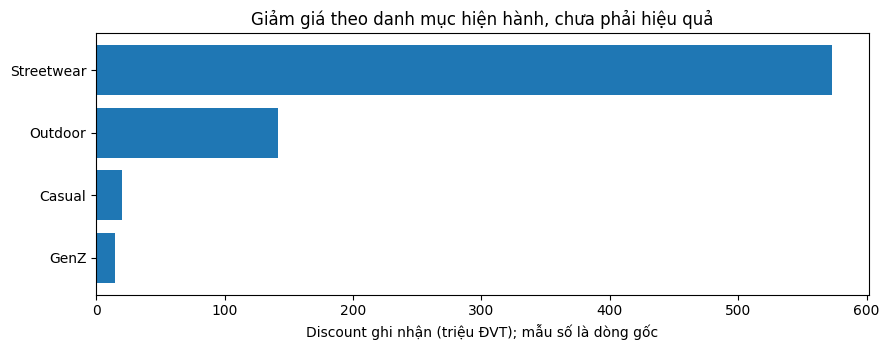

**Nhận xét.** Streetwear có tổng Discount lớn nhất: 572.869.253,45 ĐVT (76.42% toàn Discount). Có 6 trạng thái được giữ nguyên. Chênh lệch theo nhóm còn phụ thuộc số dòng, giá và cơ cấu sản phẩm; chưa chứng minh hiệu quả hoặc lạm dụng. Cần lịch sử danh mục và trạng thái/dòng tiền trước các diễn giải sâu hơn.

In [24]:
category62=fin62(i62,'category');segment62=fin62(i62,'segment')
category62['Tỷ trọng toàn Discount (%)']=100*category62._discount_c/int(i62._discount_c.sum())
show(view62(category62),'Category hiện hành: toàn bộ dòng trong nhóm')
show(view62(segment62),'Segment hiện hành: toàn bộ dòng trong nhóm')
category_type62=fin62(single62,['category','promo_type'])
show(view62(category_type62),'Category × promo_type chỉ trên dòng một vị trí mã')
status62=fin62(i62,'order_status')
status_orders62=o62.groupby('order_status',dropna=False).agg(Tổng_đơn=('order_id','size'),Đơn_có_mã=('_has_code','sum')).reset_index()
status_orders62['Đơn có mã/tổng đơn status (%)']=100*status_orders62.Đơn_có_mã/status_orders62.Tổng_đơn
status62=status62.merge(status_orders62,on='order_status',validate='one_to_one')
show(view62(status62),'Trạng thái hiện ghi nhận; không phải tiền thực thu hoặc lịch sử trạng thái')
for label,t in [('category',category62),('segment',segment62),('order_status',status62)]:
    ck62(label+': bảo toàn dòng và Gross/Discount/Net',int(t.rows.sum())==len(i62) and all(int(t[c].sum())==int(i62[c].sum()) for c in ['_gross_c','_discount_c','_net_c']))
ck62('Category × loại bảo toàn dòng một mã',int(category_type62.rows.sum())==len(single62) and int(category_type62._discount_c.sum())==int(single62._discount_c.sum()))
ck62('Status bảo toàn số đơn và đơn có mã',int(status62.Tổng_đơn.sum())==len(o62) and int(status62.Đơn_có_mã.sum())==int(o62._has_code.sum()))
ck62('Status lấy đúng snapshot của từng đơn',i62.order_status.equals(i62.order_id.map(orders.set_index('order_id').order_status)))
fig,ax=plt.subplots(figsize=(9,3.6))
ct62=category62.sort_values('_discount_c')
ax.barh(ct62.category.astype(str),ct62._discount_c/100/1_000_000)
ax.set(xlabel='Discount ghi nhận (triệu ĐVT); mẫu số là dòng gốc',title='Giảm giá theo danh mục hiện hành, chưa phải hiệu quả');figdone(fig)
cat_lead62=category62.sort_values('_discount_c',ascending=False).iloc[0]
note(f"**Nhận xét.** {cat_lead62.category} có tổng Discount lớn nhất: {vn(int(cat_lead62._discount_c)/100)} ĐVT ({cat_lead62['Tỷ trọng toàn Discount (%)']:.2f}% toàn Discount). Có {len(status62)} trạng thái được giữ nguyên. Chênh lệch theo nhóm còn phụ thuộc số dòng, giá và cơ cấu sản phẩm; chưa chứng minh hiệu quả hoặc lạm dụng. Cần lịch sử danh mục và trạng thái/dòng tiền trước các diễn giải sâu hơn.")

### NV06.2.15 — Phân bố và mức tập trung Discount
Mẫu số dân số: **mọi dòng** hoặc **mọi đơn**, kể cả Discount=0. Chọn k=ceil(p×N) cho Top 1%, 5%, 10%, không mở rộng nhóm khi hòa tại biên. Sắp Discount giảm dần, sau đó ID tăng dần: _item_row_id số nguyên cho dòng, order_id nguyên chuỗi cho đơn. Các tập top lồng nhau nên không cộng tỷ trọng của chúng.

Mẫu số tiền là toàn bộ Discount ở đúng cấp quan sát (hai cấp có cùng tổng đã bảo toàn). Mean/median/phân vị của dòng một mã và hai vị trí được trình bày riêng. Đường tập trung lấy mẫu điểm để vẽ; phép tính tỷ trọng dùng đầy đủ dữ liệu, không lấy mẫu.

Đơn vị,Top mục tiêu (%),Dân số N,k=ceil(p×N),Dân số thực chọn (%),Discount top (ĐVT),Mẫu số Discount (ĐVT),Tỷ trọng Discount (%),Discount biên (ĐVT)
Dòng,1,714.669,7.147,"1,000043","98.696.780,12","749.607.320,1","13,166464","11.041,89"
Dòng,5,714.669,35.734,"5,000077","320.544.702,19","749.607.320,1","42,761682","5.815,16"
Dòng,10,714.669,71.467,"10,000014","484.736.049,21","749.607.320,1","64,66533","3.642,02"
Đơn,1,646.945,6.470,"1,000085","92.461.502,59","749.607.320,1","12,334658","11.464,41"
Đơn,5,646.945,32.348,"5,000116","306.075.946,03","749.607.320,1","40,831504","6.333,69"
Đơn,10,646.945,64.695,"10,000077","470.073.271,94","749.607.320,1","62,709269","4.072,42"


**Phân vị tuyến tính, giữ cả dòng/đơn Discount=0**

Tập,Số quan sát,Mean (ĐVT),Median (ĐVT),P90 (ĐVT),P95 (ĐVT),P99 (ĐVT),Max (ĐVT),Tỷ lệ bằng 0 (%)
Toàn bộ dòng,714.669,"1.048,887415",0,"3.642,02","5.815,144","11.041,1488","35.235,47","61,336507"
Toàn bộ đơn,646.945,"1.158,687864",0,"4.072,372","6.333,66","11.464,2824","37.183,16","61,628577"
Dòng một vị trí mã,276.110,"2.712,566888","1.627,69","6.694,83","8.926,566","13.636,4299","35.235,47",0
Dòng hai vị trí mã,206,"3.109,109806","2.708,535","6.101,635","7.515,0275","9.421,9215","13.124,01",0


**12 dòng Discount lớn nhất: không tự coi là lạm dụng**

_item_row_id,order_id,product_id,category,order_status,promo_id,promo_id_2,_qty,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT)
600.734,696254,296,Streetwear,delivered,PROMO-0034,∅,8,"176.177,36","35.235,47","140.941,89"
711.744,830939,462,Streetwear,delivered,PROMO-0050,∅,8,"156.398,08","31.279,62","125.118,46"
673.877,784754,476,Streetwear,delivered,PROMO-0044,∅,8,"152.959,04","30.591,81","122.367,23"
712.913,832287,505,Streetwear,delivered,PROMO-0050,∅,8,"152.656,56","30.531,31","122.125,25"
546.370,631538,347,Streetwear,delivered,PROMO-0029,∅,8,"302.124,08","30.212,41","271.911,67"
544.845,629691,347,Streetwear,delivered,PROMO-0029,∅,8,"299.060,24","29.906,02","269.154,22"
638.987,742279,405,Streetwear,delivered,PROMO-0040,∅,8,"148.746,72","29.749,34","118.997,38"
639.093,742389,405,Streetwear,delivered,PROMO-0040,∅,8,"148.721,20","29.744,24","118.976,96"
637.145,740137,405,Streetwear,delivered,PROMO-0040,∅,8,"148.292,16","29.658,43","118.633,73"
714.107,833634,462,Streetwear,delivered,PROMO-0050,∅,8,"147.929,28","29.585,86","118.343,42"


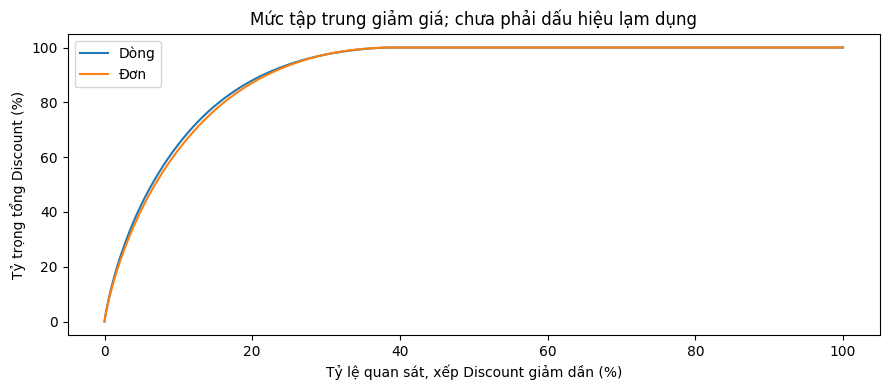

**Nhận xét.** Top 1% dòng (làm tròn lên thành 7,147 dòng) chứa 13.17% toàn Discount. So sánh dòng/đơn dùng hai dân số riêng; độ tập trung chưa chứng minh hành vi bất thường. Cần quy tắc kiểm soát ưu đãi và bối cảnh giá trị đơn để điều tra nếu có yêu cầu sau này.

In [25]:
import math
concentration62=[];sorted_populations62={}
for unit,d,key in [('Dòng',i62,'_item_row_id'),('Đơn',o62,'order_id')]:
    ranked=d[[key,'_discount_c']].sort_values(['_discount_c',key],ascending=[False,True],kind='stable')
    sorted_populations62[unit]=ranked
    total=int(ranked._discount_c.sum())
    for fraction in [.01,.05,.10]:
        k=math.ceil(fraction*len(ranked));top=ranked.head(k)
        concentration62.append({'Đơn vị':unit,'Top mục tiêu (%)':fraction*100,'Dân số N':len(ranked),'k=ceil(p×N)':k,'Dân số thực chọn (%)':100*k/len(ranked),'Discount top (ĐVT)':int(top._discount_c.sum())/100,'Mẫu số Discount (ĐVT)':total/100,'Tỷ trọng Discount (%)':100*int(top._discount_c.sum())/total,'Discount biên (ĐVT)':int(top._discount_c.iloc[-1])/100})
        ck62(f'Top {unit} {fraction:.0%}: đúng k và mẫu số',len(top)==k and top[key].is_unique and total==int(discount_c.sum()))
concentration62=pd.DataFrame(concentration62);show(concentration62)
distribution62=[]
for label,d in [('Toàn bộ dòng',i62),('Toàn bộ đơn',o62),('Dòng một vị trí mã',single62),('Dòng hai vị trí mã',dual62)]:
    s=d._discount_c/100
    distribution62.append({'Tập':label,'Số quan sát':len(d),'Mean (ĐVT)':s.mean(),'Median (ĐVT)':s.median(),'P90 (ĐVT)':s.quantile(.9),'P95 (ĐVT)':s.quantile(.95),'P99 (ĐVT)':s.quantile(.99),'Max (ĐVT)':s.max(),'Tỷ lệ bằng 0 (%)':100*s.eq(0).mean()})
show(distribution62,'Phân vị tuyến tính, giữ cả dòng/đơn Discount=0')
largest62=i62.sort_values(['_discount_c','_item_row_id'],ascending=[False,True]).head(12)
show(view62(largest62[['_item_row_id','order_id','product_id','category','order_status','promo_id','promo_id_2','_qty','_gross_c','_discount_c','_net_c']]),'12 dòng Discount lớn nhất: không tự coi là lạm dụng')
fig,ax=plt.subplots(figsize=(9,4))
for unit,ranked in sorted_populations62.items():
    cumulative=ranked._discount_c.cumsum().to_numpy()
    ix=np.unique(np.r_[0,np.linspace(1,len(ranked),1000,dtype=int),[math.ceil(x*len(ranked)) for x in [.01,.05,.1]]])
    y=np.r_[0,cumulative]
    ax.plot(100*ix/len(ranked),100*y[ix]/cumulative[-1],label=unit)
ax.set(xlabel='Tỷ lệ quan sát, xếp Discount giảm dần (%)',ylabel='Tỷ trọng tổng Discount (%)',title='Mức tập trung giảm giá; chưa phải dấu hiệu lạm dụng')
ax.legend();figdone(fig)
top_line1_62=concentration62.loc[(concentration62['Đơn vị']=='Dòng')&(concentration62['Top mục tiêu (%)']==1)].iloc[0]
note(f"**Nhận xét.** Top 1% dòng (làm tròn lên thành {top_line1_62['k=ceil(p×N)']:,} dòng) chứa {top_line1_62['Tỷ trọng Discount (%)']:.2f}% toàn Discount. So sánh dòng/đơn dùng hai dân số riêng; độ tập trung chưa chứng minh hành vi bất thường. Cần quy tắc kiểm soát ưu đãi và bối cảnh giá trị đơn để điều tra nếu có yêu cầu sau này.")

### NV06.2.16 — Sổ phát hiện và câu hỏi cần xác minh
A chỉ áp dụng khi có vi phạm kỹ thuật của ràng buộc đã kiểm tra. B là hiện tượng mô tả cần làm rõ; C là thiếu định nghĩa/dữ liệu. Các kết quả 0 được ghi là không xuất hiện trong mẫu hiện hành, không tạo vi phạm giả. Mỗi kết luận định lượng truy về bảng nguồn và đơn vị bên dưới.

In [26]:
findings62=[]
def finding62(code,kind,event,evidence,scope,source,meaning,level,limit,question):
    findings62.append({'Mã':code,'Loại':kind,'Phát hiện':event,'Bằng chứng':str(evidence),'Phạm vi/mẫu số':scope,'Nguồn':source,'Ý nghĩa':meaning,'Mức bằng chứng':level,'Giới hạn':limit,'Câu hỏi tiếp':question})
finding62('B62-01','B','Tham chiếu khác dòng và đơn',f'{len(r62)} lượt; {len(coded62)} dòng; {coded62.order_id.nunique()} đơn',f'{len(i62)} dòng; {len(o62)} đơn','items/orders/promotions','Mức ghi nhận mã','Khóa và hợp ID đã tính','Không phải lần áp dụng thành công hoặc khách được exposure','ID lần áp dụng và quy tắc ghi mã?')
finding62('B62-02','B','Chương trình phổ biến theo lượt',f'{leader62.promo_id}: {leader62.refs} lượt; {leader62.orders} đơn','Mỗi chương trình; các nhóm đơn giao nhau','r62','Mức phổ biến mô tả','Xếp hạng kiểm tra bốn tiêu chí','Không gọi hiệu quả nhất','Quy mô exposure, mục tiêu và điều kiện chương trình?')
finding62('B62-03','B','Giảm giá một lần/dòng',f'Tổng {vn(int(i62._discount_c.sum())/100)} ĐVT; một mã {vn(int(single62._discount_c.sum())/100)}; hai mã {vn(int(dual62._discount_c.sum())/100)}',f'{len(i62)} dòng gốc','items; V02','Tiền giảm ghi nhận','Tổng nguyên phần trăm ĐVT và đối chứng độc lập','Không phải chi phí marketing hoặc tiền tăng thêm','Công thức sinh discount_amount và nguồn giảm khác?')
finding62('B62-04','B','Hai vị trí mã',f'{len(dual62)} dòng; {len(actual_pairs62)} cặp; {dual62.order_id.nunique()} đơn','Tập hai vị trí; tiền một lần/dòng','items/promotions','Có rủi ro nhân tiền nếu bung dòng','Bảo toàn qua JOIN hai slot','Không phân bổ được theo mã','Có nhật ký chi tiết giảm theo mã?')
finding62('B62-05','B','Đối chiếu ngoài khoảng mô tả',f'{len(outside62)} lượt; {outside62._item_row_id.nunique()} dòng; {outside62.order_id.nunique()} đơn','Lượt mã; khoảng hai biên bao gồm','r62/order_date','Không phát hiện ngoài khoảng nếu số=0','So ngày lịch đã thực hiện','Không xác nhận chính sách áp dụng','Ngày áp dụng có khác ngày đặt?')
finding62('B62-06','B','Khác nhãn danh mục',f'{r62._category_state.eq("Khác nhãn").sum()} lượt; {r62.loc[r62._category_state.eq("Khác nhãn"),"_item_row_id"].nunique()} dòng','Lượt có danh mục mô tả rõ','promotions/products','Cần hỏi phạm vi nhãn','So chuỗi nguyên gốc','Không gọi sai eligibility','Danh mục lịch sử và quy tắc phân cấp?')
finding62('C62-01','C','Danh mục NULL chưa xác định phạm vi',f'{prom.applicable_category.isna().sum()} chương trình; {r62.applicable_category.isna().sum()} lượt','Catalogue và lượt có NULL','promotions','Không chấm đúng/sai danh mục','NULL được giữ nguyên','Không coi là mọi danh mục','Ý nghĩa NULL chính thức?')
finding62('B62-07','B','Hai cơ sở ngưỡng đơn',f'Gross dưới: {(~threshold62._gross_ok).sum()} lượt; Net dưới: {(~threshold62._net_ok).sum()}; khác nhau {threshold62._gross_ok.ne(threshold62._net_ok).sum()}','Tiền mọi dòng/đơn, rồi liên hệ mã','items/orders/promotions','Kết quả ứng viên có thể khác','Gross/Net tổng hợp trước JOIN','Không chọn cơ sở chính thức','Ngưỡng dựa Gross/Net, thuế/phí và ĐVT nào?')
finding62('B62-08','B','Cờ stackable trên hai mã',f'{int((dual62.a_stackable_flag.eq("0")|dual62.b_stackable_flag.eq("0")).sum())} dòng có cờ 0; {len(overlap_pairs62)} cặp catalogue giao lịch','Tập hai mã và cặp catalogue riêng','items/promotions','Ghi nhận đồng hiện và cờ','Kiểm tra đủ hai mã','Không chứng minh cấm hay stacking thành công','Ý nghĩa cờ và thứ tự áp dụng?')
finding62('B62-09','B','Chênh lệch nhóm sản phẩm và status',f'{cat_lead62.category}: {cat_lead62["Tỷ trọng toàn Discount (%)"]:.2f}% Discount; {len(status62)} status',f'{len(i62)} dòng, giữ mọi status','items/products/orders','Khác cơ cấu ghi nhận','Tổng nhóm bảo toàn','Snapshot không phải lịch sử hoặc dòng tiền','Lịch sử trạng thái và thanh toán/hoàn nguyên?')
finding62('B62-10','B','Tập trung giảm giá',f'Top 1% dòng chứa {top_line1_62["Tỷ trọng Discount (%)"]:.2f}% Discount','Mọi dòng, k=ceil(0,01N), hòa theo ID','items; tổng hợp đơn riêng','Mô tả độ tập trung','Tính đủ dân số','Không suy lạm dụng hoặc hiệu quả','Điều kiện giá trị đơn và quy tắc kiểm soát?')
finding62('C62-02','C','Giới hạn quy Discount cho chương trình','Chỉ tổng hợp tiền tập một vị trí; hai vị trí giữ riêng','Discount tập một vị trí là mẫu số tỷ trọng chương trình','items/promotions','Có liên hệ mô tả, chưa có phân bổ nguyên nhân','Chưa có công thức/nhật ký áp dụng','Không chia 50/50 hoặc theo vị trí','Công thức phân bổ được chủ nguồn xác nhận?')
finding62('C62-03','C','Chưa đo hiệu quả/attribution','Không tính uplift, ROI/ROAS/CAC hoặc nối traffic','NV06.2; chỉ 4 nguồn giao dịch/chương trình đang phân tích','Nguồn hiện có và giới hạn NV06.1','Cung cấp dữ liệu mô tả cho bước sau','Chưa có đối chứng, exposure, chi phí và bridge','Discount không là tác động nhân quả','Thiết kế đối chứng, quy tắc attribution và chi phí?')
show(findings62,'Phát hiện B/C; không tự tạo A')
technical62={'Khóa cha NULL/trùng':sum(int(d[k].isna().sum()+d.duplicated(k).sum()) for d,k in [(prom,'promo_id'),(orders,'order_id'),(products,'product_id')]),'Lượt mã mồ côi':len(orphans62),'Dòng thất lạc sau JOIN':abs(len(i62)-len(items)),'Sai lệch Discount nhóm (phần trăm ĐVT)':abs(int(groups62._discount_c.sum())-int(discount_c.sum()))}
show([{'Kiểm tra kỹ thuật':k,'Số lượng':int(v),'Kết luận':'Không phát hiện A trong phép kiểm này' if v==0 else 'A — cần truy vết'} for k,v in technical62.items()],'Phân loại A chỉ trong phạm vi ràng buộc đã kiểm tra')
note("**Nhận xét.** Các hiện tượng B phản ánh mức ghi nhận và đối chiếu mô tả; C nêu định nghĩa còn thiếu. Những tổng khác nhau do khác đơn vị quan sát được giải thích bằng hợp ID và bảng tiền riêng, không gán là lỗi. Cần ưu tiên công thức giảm, cơ sở ngưỡng và ý nghĩa cờ trước kết luận về chương trình.")

**Phát hiện B/C; không tự tạo A**

Mã,Loại,Phát hiện,Bằng chứng,Phạm vi/mẫu số,Nguồn,Ý nghĩa,Mức bằng chứng,Giới hạn,Câu hỏi tiếp
B62-01,B,Tham chiếu khác dòng và đơn,276522 lượt; 276316 dòng; 248242 đơn,714669 dòng; 646945 đơn,items/orders/promotions,Mức ghi nhận mã,Khóa và hợp ID đã tính,Không phải lần áp dụng thành công hoặc khách được exposure,ID lần áp dụng và quy tắc ghi mã?
B62-02,B,Chương trình phổ biến theo lượt,PROMO-0014: 11451 lượt; 9487 đơn,Mỗi chương trình; các nhóm đơn giao nhau,r62,Mức phổ biến mô tả,Xếp hạng kiểm tra bốn tiêu chí,Không gọi hiệu quả nhất,"Quy mô exposure, mục tiêu và điều kiện chương trình?"
B62-03,B,Giảm giá một lần/dòng,"Tổng 749.607.320,1 ĐVT; một mã 748.966.843,48; hai mã 640.476,62",714669 dòng gốc,items; V02,Tiền giảm ghi nhận,Tổng nguyên phần trăm ĐVT và đối chứng độc lập,Không phải chi phí marketing hoặc tiền tăng thêm,Công thức sinh discount_amount và nguồn giảm khác?
B62-04,B,Hai vị trí mã,206 dòng; 2 cặp; 205 đơn,Tập hai vị trí; tiền một lần/dòng,items/promotions,Có rủi ro nhân tiền nếu bung dòng,Bảo toàn qua JOIN hai slot,Không phân bổ được theo mã,Có nhật ký chi tiết giảm theo mã?
B62-05,B,Đối chiếu ngoài khoảng mô tả,0 lượt; 0 dòng; 0 đơn,Lượt mã; khoảng hai biên bao gồm,r62/order_date,Không phát hiện ngoài khoảng nếu số=0,So ngày lịch đã thực hiện,Không xác nhận chính sách áp dụng,Ngày áp dụng có khác ngày đặt?
B62-06,B,Khác nhãn danh mục,0 lượt; 0 dòng,Lượt có danh mục mô tả rõ,promotions/products,Cần hỏi phạm vi nhãn,So chuỗi nguyên gốc,Không gọi sai eligibility,Danh mục lịch sử và quy tắc phân cấp?
C62-01,C,Danh mục NULL chưa xác định phạm vi,40 chương trình; 246461 lượt,Catalogue và lượt có NULL,promotions,Không chấm đúng/sai danh mục,NULL được giữ nguyên,Không coi là mọi danh mục,Ý nghĩa NULL chính thức?
B62-07,B,Hai cơ sở ngưỡng đơn,Gross dưới: 110923 lượt; Net dưới: 111698; khác nhau 775,"Tiền mọi dòng/đơn, rồi liên hệ mã",items/orders/promotions,Kết quả ứng viên có thể khác,Gross/Net tổng hợp trước JOIN,Không chọn cơ sở chính thức,"Ngưỡng dựa Gross/Net, thuế/phí và ĐVT nào?"
B62-08,B,Cờ stackable trên hai mã,206 dòng có cờ 0; 5 cặp catalogue giao lịch,Tập hai mã và cặp catalogue riêng,items/promotions,Ghi nhận đồng hiện và cờ,Kiểm tra đủ hai mã,Không chứng minh cấm hay stacking thành công,Ý nghĩa cờ và thứ tự áp dụng?
B62-09,B,Chênh lệch nhóm sản phẩm và status,Streetwear: 76.42% Discount; 6 status,"714669 dòng, giữ mọi status",items/products/orders,Khác cơ cấu ghi nhận,Tổng nhóm bảo toàn,Snapshot không phải lịch sử hoặc dòng tiền,Lịch sử trạng thái và thanh toán/hoàn nguyên?


**Phân loại A chỉ trong phạm vi ràng buộc đã kiểm tra**

Kiểm tra kỹ thuật,Số lượng,Kết luận
Khóa cha NULL/trùng,0,Không phát hiện A trong phép kiểm này
Lượt mã mồ côi,0,Không phát hiện A trong phép kiểm này
Dòng thất lạc sau JOIN,0,Không phát hiện A trong phép kiểm này
Sai lệch Discount nhóm (phần trăm ĐVT),0,Không phát hiện A trong phép kiểm này


**Nhận xét.** Các hiện tượng B phản ánh mức ghi nhận và đối chiếu mô tả; C nêu định nghĩa còn thiếu. Những tổng khác nhau do khác đơn vị quan sát được giải thích bằng hợp ID và bảng tiền riêng, không gán là lỗi. Cần ưu tiên công thức giảm, cơ sở ngưỡng và ý nghĩa cờ trước kết luận về chương trình.

### Đối chứng độc lập trong bộ nhớ
Mẫu 5 dòng, 4 đơn, 2 chương trình có kỳ vọng cố định: Gross=210, Discount=46, Net=164 ĐVT; 6 lượt vị trí nhưng 5 cặp dòng–mã. Hai vị trí có tiền 21 ĐVT, một vị trí 25 ĐVT. Nếu cộng tiền trên bảng lượt mã sẽ sai thành 67 ĐVT. Mẫu bao gồm mã lặp, trước/sau khoảng, khác danh mục, danh mục NULL, Gross đạt nhưng Net dưới ngưỡng và đơn cancelled. Mẫu không ghép vào CSV.

In [27]:
fp62=pd.DataFrame({'promo_id':['A','B'],'start_date':['2020-01-05','2020-01-10'],'end_date':['2020-01-15','2020-01-20'],'applicable_category':['Streetwear',None],'min_order_value':[130,0],'stackable_flag':[0,1]})
fi62=pd.DataFrame({'_item_row_id':[0,1,2,3,4],'order_id':['O0','O1','O1','O2','O3'],'product_id':['P0','P1','P1','P1','P1'],'quantity':[1,2,1,1,1],'unit_price':[10,50,50,30,20],'discount_amount':[0,20,15,6,5],'promo_id':[None,'A','A','A','B'],'promo_id_2':[None,None,'B','A',None],'category':['Outdoor']*5})
fo62=pd.DataFrame({'order_id':['O0','O1','O2','O3'],'order_date':['2020-01-01','2020-01-10','2020-01-01','2020-02-01'],'order_status':['delivered','delivered','cancelled','delivered']})
fi62['_qty']=fi62.quantity
fi62['_gross_c']=fi62.quantity*fi62.unit_price*100
fi62['_discount_c']=fi62.discount_amount*100
fi62['_net_c']=fi62._gross_c-fi62._discount_c
fi62['_slots']=fi62.promo_id.notna().astype(int)+fi62.promo_id_2.notna().astype(int)
fi62['_has_code']=fi62._slots.gt(0);fi62['_group']=fi62._slots.map({0:'Không mã',1:'Một vị trí mã',2:'Hai vị trí mã'})
fi62['_coded_order_id']=fi62.order_id.where(fi62._has_code)
fi62['_line_pct']=100*fi62._discount_c/fi62._gross_c
fi62=fi62.merge(fo62,on='order_id',validate='many_to_one')
fr_parts62=[]
for slot in ['promo_id','promo_id_2']:
    p=fi62.loc[fi62[slot].notna(),['_item_row_id','order_id','order_date','product_id','category']].copy()
    p['promo_id']=fi62.loc[fi62[slot].notna(),slot];p['_slot']=slot;fr_parts62.append(p)
fr62=pd.concat(fr_parts62,ignore_index=True).merge(fp62,on='promo_id',validate='many_to_one')
fu62=fr62.drop_duplicates(['_item_row_id','promo_id'])
fg62=fin62(fi62,'_group')
ft62=fi62.groupby('order_id')[['_gross_c','_discount_c','_net_c']].sum()
fixture62=[]
def fx62(label,ok,evidence):
    fixture62.append({'Tình huống':label,'Đạt':bool(ok),'Kỳ vọng':evidence});ck62('Mẫu độc lập: '+label,ok,evidence)
fx62('Không mã, Discount=0',fi62.loc[fi62._slots.eq(0),'_discount_c'].tolist()==[0],'Dòng0, giữ nguyên')
fx62('Một vị trí mã',fi62._slots.eq(1).sum()==2 and fi62.loc[fi62._slots.eq(1),'_discount_c'].sum()==2500,'2 dòng; Discount25')
fx62('Hai vị trí, một khoản giảm',fi62._slots.eq(2).sum()==2 and fi62.loc[fi62._slots.eq(2),'_discount_c'].sum()==2100,'Dòng2 và3; Discount21 một lần')
fx62('Cùng mã hai vị trí',len(fr62.loc[fr62._item_row_id.eq(3)])==2 and len(fu62.loc[fu62._item_row_id.eq(3)])==1,'2 vị trí A nhưng 1 cặp dòng–A')
fx62('Lượt khác cặp dòng–mã',len(fr62)==6 and len(fu62)==5,'6 lượt, 5 cặp')
fx62('Một đơn nhiều dòng và mã',fi62.loc[fi62.order_id.eq('O1')].shape[0]==2 and fu62.loc[fu62.order_id.eq('O1'),'promo_id'].nunique()==2,'O1:2 dòng, A/B')
fx62('Một chương trình nhiều lượt',fr62.promo_id.eq('A').sum()==4,'A có4 lượt, 3 dòng')
fx62('Trước start_date',(dates(fr62.order_date)<dates(fr62.start_date)).sum()==2,'O2 có2 vị trí A trước ngày')
fx62('Sau end_date',(dates(fr62.order_date)>dates(fr62.end_date)).sum()==1,'O3:B sau ngày')
fx62('Hai biên bao gồm',pd.Timestamp('2020-01-05')>=dates(fp62.start_date)[0] and pd.Timestamp('2020-01-15')<=dates(fp62.end_date)[0] and ((dates(fr62.order_date)==dates(fr62.start_date))&fr62.promo_id.eq('B')).sum()==1,'Start và end đều thuộc khoảng; O1:B đúng start')
fx62('Khác nhãn danh mục',fr62.applicable_category.notna().sum()==4 and ((fr62.applicable_category!=fr62.category)&fr62.applicable_category.notna()).sum()==4,'4 lượt A:Streetwear khác Outdoor')
fx62('NULL không là mọi danh mục',fr62.applicable_category.isna().sum()==2,'2 lượt B chưa xác định phạm vi')
fx62('Gross đạt, Net dưới ngưỡng',ft62.loc['O1','_gross_c']==15000 and ft62.loc['O1','_net_c']==11500 and 11500<13000<=15000,'O1 Gross150 Net115; ngưỡng130')
fx62('Cancelled có mã',fi62.loc[fi62.order_status.eq('cancelled'),'_discount_c'].sum()==600,'O2 giữ Discount6, chưa suy dòng tiền')
fx62('Gross/Discount/Net đúng',tuple(fi62[c].sum() for c in ['_gross_c','_discount_c','_net_c'])==(21000,4600,16400),'210/46/164 ĐVT')
fx62('Bảng nhóm tiền bảo toàn',tuple(fg62[c].sum() for c in ['_gross_c','_discount_c','_net_c'])==(21000,4600,16400),'Dùng cùng hàm fin62 như nguồn thật')
fx62('Cộng tiền trên lượt sẽ sai',fr62.merge(fi62[['_item_row_id','_discount_c']],on='_item_row_id',validate='many_to_one')._discount_c.sum()==6700 and fi62._discount_c.sum()==4600,'67 sai,46 đúng; bảng thật không mang tiền dòng')
fx62('Không nhân Discount với quantity',(fi62.discount_amount*fi62.quantity).sum()==66 and fi62.discount_amount.sum()==46,'66 sai,46 đúng')
fdual62=fi62.loc[fi62._slots.eq(2)].merge(fp62[['promo_id','stackable_flag']].rename(columns={'stackable_flag':'a_flag'}),on='promo_id',validate='many_to_one').merge(fp62[['promo_id','stackable_flag']].rename(columns={'promo_id':'promo_id_2','stackable_flag':'b_flag'}),on='promo_id_2',validate='many_to_one')
fx62('Kiểm tra đủ cờ hai mã',len(fdual62)==2 and set(zip(fdual62.a_flag,fdual62.b_flag))=={(0,1),(0,0)},'A/B cờ0/1; A/A cờ0/0, không kết luận vi phạm')
tie62=pd.DataFrame({'id':[3,1,2],'discount':[10,10,5]}).sort_values(['discount','id'],ascending=[False,True]).head(math.ceil(.01*3))
fx62('Top làm tròn lên, hòa theo ID',tie62.id.tolist()==[1],'k=1, chọn ID1 dù hai giá trị10; không mở rộng biên')
show(fixture62,'Đối chứng độc lập: có kỳ vọng số cố định, không sửa dữ liệu gốc')
note("**Nhận xét.** Các mẫu chặn lỗi cộng trùng mã, nhân tiền, nhầm số dòng thành số lượt và dùng Gross/Net sau bung mã. Trường hợp Gross đạt nhưng Net dưới cho thấy cần hỏi cơ sở ngưỡng. Mẫu cancelled và khác danh mục chỉ mô tả tình huống, không tự chứng minh dòng tiền hoặc vi phạm.")

**Đối chứng độc lập: có kỳ vọng số cố định, không sửa dữ liệu gốc**

Tình huống,Đạt,Kỳ vọng
"Không mã, Discount=0",1,"Dòng0, giữ nguyên"
Một vị trí mã,1,2 dòng; Discount25
"Hai vị trí, một khoản giảm",1,Dòng2 và3; Discount21 một lần
Cùng mã hai vị trí,1,2 vị trí A nhưng 1 cặp dòng–A
Lượt khác cặp dòng–mã,1,"6 lượt, 5 cặp"
Một đơn nhiều dòng và mã,1,"O1:2 dòng, A/B"
Một chương trình nhiều lượt,1,"A có4 lượt, 3 dòng"
Trước start_date,1,O2 có2 vị trí A trước ngày
Sau end_date,1,O3:B sau ngày
Hai biên bao gồm,1,Start và end đều thuộc khoảng; O1:B đúng start


**Nhận xét.** Các mẫu chặn lỗi cộng trùng mã, nhân tiền, nhầm số dòng thành số lượt và dùng Gross/Net sau bung mã. Trường hợp Gross đạt nhưng Net dưới cho thấy cần hỏi cơ sở ngưỡng. Mẫu cancelled và khác danh mục chỉ mô tả tình huống, không tự chứng minh dòng tiền hoặc vi phạm.

### Kết luận NV06.2
Kết luận chỉ mô tả dữ liệu ghi nhận. Các đầu vào cho NV06.3–NV06.4 được nêu như điều kiện sử dụng nguồn; chưa thực hiện các nhiệm vụ đó.

In [28]:
top_order62=prog62.sort_values(['orders','promo_id'],ascending=[False,True]).iloc[0]
note(f'''Có {len(coded62):,} dòng gắn ít nhất một mã trong {len(i62):,} dòng ({len(coded62)/len(i62)*100:.2f}%) và {coded62.order_id.nunique():,} đơn có mã trong {len(o62):,} đơn ({coded62.order_id.nunique()/len(o62)*100:.2f}%). {leader62.promo_id} đứng đầu số lượt, {top_order62.promo_id} đứng đầu số đơn; loại {type_leader62.promo_type} có nhiều lượt nhất. Hạng lượt/dòng/đơn/sản phẩm được kiểm tra riêng, chưa xếp hạng hiệu quả.

Tổng Discount ghi nhận {vn(int(i62._discount_c.sum())/100)} ĐVT, với {vn(int(single62._discount_c.sum())/100)} ĐVT trên dòng một vị trí và {vn(int(dual62._discount_c.sum())/100)} ĐVT trên dòng hai vị trí. {len(r62):,} lượt không phải {len(r62):,} dòng giảm giá vì {len(dual62)} dòng có hai vị trí. Cộng khoản giảm theo từng lượt sẽ lặp tiền; mỗi dòng chỉ tính một lần. Bảng theo chương trình chỉ liên hệ tiền tập một vị trí, chưa xác nhận toàn bộ khoản giảm do mã sinh ra; phần hai mã chưa phân bổ.

Danh mục {cat_lead62.category} có {cat_lead62["Tỷ trọng toàn Discount (%)"]:.2f}% tổng Discount; độ tập trung dòng/đơn và bảng thời gian/status đã báo đúng dân số, kể cả giá trị 0 và năm 2012 chưa đủ năm. Có {len(outside62)} lượt ngoài khoảng/chưa xác định; {r62._category_state.eq("Khác nhãn").sum()} lượt khác nhãn; {threshold62._gross_ok.ne(threshold62._net_ok).sum()} lượt khác kết quả ngưỡng Gross/Net. Những đối chiếu này cần ngày áp dụng, danh mục lịch sử và định nghĩa ngưỡng. {int((dual62.a_stackable_flag.eq("0")|dual62.b_stackable_flag.eq("0")).sum())} dòng hai mã có ít nhất một cờ0 chưa chứng minh cấm kết hợp hoặc stacking thành công.

NV06.2 cung cấp hai bảng cấp dòng/lượt, phạm vi chương trình, mẫu số theo kỳ/nhóm và sổ vấn đề cho NV06.3–NV06.4. Chưa có exposure, quy tắc attribution, chi phí hay đối chứng để kết luận khuyến mãi tạo thêm đơn, doanh thu hoặc lợi nhuận; Discount không mặc định là chi phí marketing. Các bước sau cần giữ nguyên đơn vị, không tự ánh xạ kênh, chia tiền hai mã hoặc dùng snapshot status như dòng tiền.''')

Có 276,316 dòng gắn ít nhất một mã trong 714,669 dòng (38.66%) và 248,242 đơn có mã trong 646,945 đơn (38.37%). PROMO-0014 đứng đầu số lượt, PROMO-0014 đứng đầu số đơn; loại percentage có nhiều lượt nhất. Hạng lượt/dòng/đơn/sản phẩm được kiểm tra riêng, chưa xếp hạng hiệu quả.

Tổng Discount ghi nhận 749.607.320,1 ĐVT, với 748.966.843,48 ĐVT trên dòng một vị trí và 640.476,62 ĐVT trên dòng hai vị trí. 276,522 lượt không phải 276,522 dòng giảm giá vì 206 dòng có hai vị trí. Cộng khoản giảm theo từng lượt sẽ lặp tiền; mỗi dòng chỉ tính một lần. Bảng theo chương trình chỉ liên hệ tiền tập một vị trí, chưa xác nhận toàn bộ khoản giảm do mã sinh ra; phần hai mã chưa phân bổ.

Danh mục Streetwear có 76.42% tổng Discount; độ tập trung dòng/đơn và bảng thời gian/status đã báo đúng dân số, kể cả giá trị 0 và năm 2012 chưa đủ năm. Có 0 lượt ngoài khoảng/chưa xác định; 0 lượt khác nhãn; 775 lượt khác kết quả ngưỡng Gross/Net. Những đối chiếu này cần ngày áp dụng, danh mục lịch sử và định nghĩa ngưỡng. 206 dòng hai mã có ít nhất một cờ0 chưa chứng minh cấm kết hợp hoặc stacking thành công.

NV06.2 cung cấp hai bảng cấp dòng/lượt, phạm vi chương trình, mẫu số theo kỳ/nhóm và sổ vấn đề cho NV06.3–NV06.4. Chưa có exposure, quy tắc attribution, chi phí hay đối chứng để kết luận khuyến mãi tạo thêm đơn, doanh thu hoặc lợi nhuận; Discount không mặc định là chi phí marketing. Các bước sau cần giữ nguyên đơn vị, không tự ánh xạ kênh, chia tiền hai mã hoặc dùng snapshot status như dòng tiền.

### Kiểm chứng riêng NV06.2 và bảo toàn NV06.1
Đối chiếu mốc bằng báo cáo V06/V02 đã xác minh hash; tổng Gross/Discount được tính lại bằng bộ đọc csv và Decimal độc lập. Thực thi cũ được chạy lại **trong bộ nhớ**; khi lưu notebook, 30 ô cũ được giữ nguyên JSON gồm output, execution_count và metadata. Metadata gốc giữ nguyên; chỉ thêm nv06_2.

Hai kernel mới chạy toàn notebook từ gốc repo và thư mục notebook. Hậu kiểm so output mới, hash 90 tệp còn lại và hash JSON 30 ô cũ trước/sau. Kết quả hậu kiểm được ghi trong metadata nv06_2.execution của chính notebook, không tạo báo cáo phụ. Ngoài phạm vi không được tính như kiểm chứng đạt.

In [29]:
# Bộ đọc độc lập: không dùng bảng JOIN, không lấy tổng từ r62.
ind_count62=0;ind_gross62=Decimal(0);ind_discount62=Decimal(0)
with paths['order_items'].open(encoding='utf-8-sig',newline='') as f:
    for row in csv.DictReader(f):
        ind_count62+=1;ind_gross62+=Decimal(row['quantity'])*Decimal(row['unit_price']);ind_discount62+=Decimal(row['discount_amount'])
ck62('Mốc V06: số chương trình',len(prom)==reports['v06']['metrics']['promotions_rows'],len(prom))
ck62('Mốc V06 và CSV độc lập: số items',len(i62)==reports['v06']['metrics']['order_items_rows']==ind_count62,len(i62))
ck62('Gross độc lập quantity × unit_price',Decimal(int(i62._gross_c.sum()))/100==ind_gross62,str(ind_gross62))
ck62('Discount độc lập một lần/dòng',Decimal(int(i62._discount_c.sum()))/100==ind_discount62,str(ind_discount62))
ck62('Discount đối chiếu V02',ind_discount62==Decimal(str(reports['v02']['metrics']['discount'])),str(ind_discount62))
ck62('Số mã phân biệt từng dòng được đối chiếu',r62.groupby('_item_row_id').promo_id.nunique().reindex(i62._item_row_id,fill_value=0).to_numpy().tolist()==i62._distinct_codes.tolist())
ck62('Mỗi vị trí nguồn chỉ một lượt',not r62.duplicated(['_item_row_id','_slot']).any())
ck62('Không tự thay mã hoặc NULL',all(i62.sort_values('_item_row_id')[c].reset_index(drop=True).equals(items[c].reset_index(drop=True)) for c in ['promo_id','promo_id_2','discount_amount']))
ck62('Dòng hai mã lấy đúng tiền nguồn một lần',int(dual62._discount_c.sum())==int(discount_c.loc[(items.promo_id.notna()&items.promo_id_2.notna())].sum()))
ck62('Tỷ lệ nhóm dòng đúng mẫu số',int(groups62.rows.sum())==len(i62) and groups62.valid_ratio_rows.le(groups62.rows).all())
ck62('Không có Gross không dương bị tính tỷ lệ dòng',i62.loc[i62._gross_c.le(0),'_line_pct'].isna().all(),int(i62._gross_c.le(0).sum()))
ck62('Bảng tiền theo chương trình loại trừ hai vị trí',set(single62._item_row_id).isdisjoint(set(dual62._item_row_id)))
ck62('Bốn biểu đồ mới đúng phạm vi',figure_count-base_figures62==4)
# Đối chiếu JSON trước/sau bằng dấu vân tay chuẩn hóa khóa, không bỏ output/metadata.
self_path62=ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb'
self62=load_notebook_for_audit(self_path62)
def jsonhash62(x):return hashlib.sha256(json.dumps(x,ensure_ascii=False,sort_keys=True,separators=(',',':'),allow_nan=False).encode()).hexdigest()
ck62('37: 30 ô NV06.1 nguyên JSON gồm output/metadata',jsonhash62(self62['cells'][:30])==self62['metadata']['nv06_2']['original_cells_sha256'])
ck62('Metadata gốc không đổi',jsonhash62({k:v for k,v in self62['metadata'].items() if k!='nv06_2'})==self62['metadata']['nv06_2']['original_metadata_sha256'])
show(checks62,'Kiểm chứng NV06.2 đã thực hiện, không trộn với 72 kiểm chứng cũ')
passed62=sum(r['Trạng thái']=='Đạt' for r in checks62);failed62=len(checks62)-passed62
show([{'Phạm vi':'NV06.1','Đạt':len(checks),'Không đạt':sum(r['Trạng thái']!='Đạt' for r in checks),'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phạm vi':'NV06.2','Đạt':passed62,'Không đạt':failed62,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0}],'Trạng thái riêng: 6 nhóm ngoài phạm vi là hiệu quả chiến dịch, nhân quả/uplift, conversion, attribution, ROI/ROAS/CAC, phân bổ tiền hai mã')
assert failed62==0,'Có kiểm chứng NV06.2 không đạt, xem bảng.'
note(f"**Kết quả trong kernel.** NV06.2 đạt {passed62} kiểm chứng; NV06.1 chạy lại đạt {len(checks)}. NV06.2 bổ sung {table_count-base_tables62} bảng, {figure_count-base_figures62} biểu đồ; tổng notebook {table_count} bảng và {figure_count} biểu đồ. Hai lượt Run All và kiểm tra file hậu kỳ xem metadata nv06_2.execution.")
summary62={'checks_new':passed62,'checks_old':len(checks),'checks_failed':failed62,'tables_new':table_count-base_tables62,'figures_new':figure_count-base_figures62,'tables_total':table_count,'figures_total':figure_count,'coded_lines':len(coded62),'coded_orders':coded62.order_id.nunique(),'refs':len(r62),'leader_refs':leader62.promo_id,'leader_orders':top_order62.promo_id,'discount_total':str(ind_discount62),'discount_single':str(Decimal(int(single62._discount_c.sum()))/100),'discount_dual':str(Decimal(int(dual62._discount_c.sum()))/100),'outside_refs':len(outside62),'category_different_refs':int(r62._category_state.eq('Khác nhãn').sum()),'gross_below_refs':int((~threshold62._gross_ok).sum()),'net_below_refs':int((~threshold62._net_ok).sum()),'threshold_different_refs':int(threshold62._gross_ok.ne(threshold62._net_ok).sum()),'dual_with_zero_flag':int((dual62.a_stackable_flag.eq('0')|dual62.b_stackable_flag.eq('0')).sum()),'dual_pairs':len(actual_pairs62),'top1_line_discount_share':float(top_line1_62['Tỷ trọng Discount (%)']),'findings_B':sum(x['Loại']=='B' for x in findings62),'findings_C':sum(x['Loại']=='C' for x in findings62)}
print('NV062_RESULT '+json.dumps(summary62,ensure_ascii=False))

**Kiểm chứng NV06.2 đã thực hiện, không trộn với 72 kiểm chứng cũ**

Kiểm chứng NV06.2,Trạng thái,Bằng chứng
orders: khóa cha đủ và duy nhất,Đạt,
JOIN orders bảo toàn dòng và tiền,Đạt,
JOIN orders: không có khóa mồ côi,Đạt,0
products: khóa cha đủ và duy nhất,Đạt,
JOIN products bảo toàn dòng và tiền,Đạt,
JOIN products: không có khóa mồ côi,Đạt,0
promotions: promo_id đủ và duy nhất,Đạt,
JOIN promotions không nhân lượt,Đạt,
Bảng tham chiếu không chứa tiền dòng,Đạt,
Định danh dòng bảo toàn CSV,Đạt,


**Trạng thái riêng: 6 nhóm ngoài phạm vi là hiệu quả chiến dịch, nhân quả/uplift, conversion, attribution, ROI/ROAS/CAC, phân bổ tiền hai mã**

Phạm vi,Đạt,Không đạt,Ngoài phạm vi (nhóm),Không thể chạy
NV06.1,72,0,6,0
NV06.2,92,0,6,0


**Kết quả trong kernel.** NV06.2 đạt 92 kiểm chứng; NV06.1 chạy lại đạt 72. NV06.2 bổ sung 49 bảng, 4 biểu đồ; tổng notebook 95 bảng và 7 biểu đồ. Hai lượt Run All và kiểm tra file hậu kỳ xem metadata nv06_2.execution.

NV062_RESULT {"checks_new": 92, "checks_old": 72, "checks_failed": 0, "tables_new": 49, "figures_new": 4, "tables_total": 95, "figures_total": 7, "coded_lines": 276316, "coded_orders": 248242, "refs": 276522, "leader_refs": "PROMO-0014", "leader_orders": "PROMO-0014", "discount_total": "749607320.10", "discount_single": "748966843.48", "discount_dual": "640476.62", "outside_refs": 0, "category_different_refs": 0, "gross_below_refs": 110923, "net_below_refs": 111698, "threshold_different_refs": 775, "dual_with_zero_flag": 206, "dual_pairs": 2, "top1_line_discount_share": 13.166464290507934, "findings_B": 10, "findings_C": 3}


## NV06.3 — Kênh thu hút khách hàng và lưu lượng website
### NV06.3.1 — Mục tiêu, đơn vị và phạm vi
Phân tích hai nguồn độc lập: hồ sơ khách và số đo web theo ngày. Không đồng nhất acquisition_channel, traffic_source và promo_channel. Không nối web với đơn/khách, chưa đối chiếu doanh thu–traffic theo ngày; phần đó dành cho NV06.4.

Nguồn: customers, orders, order_items để kiểm soát tiền; web_traffic đọc lại từ CSV; promotions chỉ tham chiếu ngữ nghĩa kênh. Tái sử dụng tiền cấp đơn o62 đã được kiểm chứng; không lấy sales làm tiền của khách. Thời gian nguồn được hiển thị trước khi tính. Giữ mọi trạng thái, giá trị thiếu, nhãn và cực trị; không ghi file phụ.

**Giới hạn bắt buộc:** ngày signup chưa được xác nhận là ngày bắt đầu mua hàng. Mọi bảng orders/acquisition bên dưới là **phân nhóm hồi cứu theo thuộc tính hồ sơ hiện có**, chưa phải số đơn hoặc doanh thu do kênh tạo ra. Tỷ lệ khách có đơn không gọi là conversion. Tiền hiển thị bằng Decimal; Net là hiệu số số học, không phải thực thu/lợi nhuận.

Audit NV06.3 được đặt trong metadata của ô tiêu đề mới này. Toàn bộ metadata notebook gốc giữ nguyên để bảo toàn cả kiểm chứng NV06.1–NV06.2.

In [30]:
base_tables63,base_figures63=table_count,figure_count
checks63=[]
def ck63(name,ok,evidence=''):
    checks63.append({'Kiểm chứng NV06.3':name,'Trạng thái':'Đạt' if bool(ok) else 'Không đạt','Bằng chứng':str(evidence)})
def orders_show63(d,title):
    show(d,title+' — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution')
c63=customers.copy();c63['_signup']=dates(c63.signup_date,'%m/%d/%Y')
c63['_year']=c63._signup.dt.year;c63['_month']=c63._signup.dt.to_period('M').astype(str)
wraw63=pd.read_csv(paths['web_traffic'],dtype='string',keep_default_na=True)
w63=wraw63.copy();w63['_date']=dates(w63.date)
w63['_year']=w63._date.dt.year;w63['_month']=w63._date.dt.to_period('M').astype(str)
w63['_calendar_month']=w63._date.dt.month;w63['_weekday']=w63._date.dt.dayofweek
weekday_names63={0:'Thứ Hai',1:'Thứ Ba',2:'Thứ Tư',3:'Thứ Năm',4:'Thứ Sáu',5:'Thứ Bảy',6:'Chủ nhật'}
w63['_day_group']=np.where(w63._weekday.ge(5),'Cuối tuần','Ngày thường')
web_fields63=[c for c in wraw63 if c not in ['date','traffic_source']]
for col in web_fields63:w63[col]=pd.to_numeric(wraw63[col],errors='coerce')
duration_field63='avg_session_duration_sec'
report_v01_63=json.loads(reference_path('reports/tables/gd1/validations/v01.json').read_text(encoding='utf-8'))
for n in ['orders','customers']:
    ck63('V01: nguồn hiện hành khớp hash '+n,digest(paths[n])==report_v01_63['sources'][n]['sha256'])
ck63('Khách: khóa đủ và duy nhất',c63.customer_id.notna().all() and c63.customer_id.is_unique)
ck63('Đơn: khóa đủ và duy nhất',orders.order_id.notna().all() and orders.order_id.is_unique)
ck63('Khách: số dòng khớp V08',len(c63)==reports['v08']['metrics']['customers_rows'])
ck63('Ngày signup hợp lệ, không mất khách',c63._signup.notna().all())
ck63('Web đọc lại khớp toàn CSV đã kiểm chứng',wraw63.equals(web))
ck63('Web đúng schema 7 trường thực tế',wraw63.columns.tolist()==['date','sessions','unique_visitors','page_views','bounce_rate',duration_field63,'traffic_source'])
ck63('Web khớp số dòng V07',len(w63)==reports['v07']['metrics']['rows'])
show(pd.DataFrame([
['Khách','customers','customer_id','acquisition_channel','Đếm hồ sơ, tỷ trọng; khách có đơn','Khách–đơn qua customer_id; không có exposure'],
['Đơn','orders và items tổng hợp','order_id','Thuộc tính khách qua customer_id','Đơn; Gross/Discount/Net cấp đơn','Một khách nhiều đơn; nhãn hồi cứu, không là kênh tạo đơn'],
['Ngày web','web_traffic','date','traffic_source trên ngày','Sessions/page_views và unique_visitors theo ngày','Không có ID phiên/khách/đơn; chưa biết số đo phân rã theo nguồn'],
['Chương trình','promotions','promo_id','promo_channel','Số mô tả chương trình','Không đồng nghĩa với acquisition hoặc traffic']
],columns=['Cấp','Nguồn','Khóa','Nhãn','Chỉ tiêu hợp lệ','Giới hạn JOIN']))
show([{'Nguồn':'customers','Dòng':len(c63),'Từ':str(c63._signup.min().date()),'Đến':str(c63._signup.max().date()),'Đơn vị':'Hồ sơ khách, signup MM/DD/YYYY'},
{'Nguồn':'orders','Dòng':len(orders),'Từ':str(od.min().date()),'Đến':str(od.max().date()),'Đơn vị':'Đơn, mọi snapshot status'},
{'Nguồn':'web_traffic','Dòng':len(w63),'Từ':str(w63._date.min().date()),'Đến':str(w63._date.max().date()),'Đơn vị':'Ngày; kiểm tra độ hạt bên dưới'}],'Phạm vi, mẫu số và nguồn của NV06.3')
note(f"**Nhận xét.** {len(c63):,} hồ sơ, {len(orders):,} đơn và {len(w63):,} ngày web có mẫu số khác nhau. Web bắt đầu năm {w63._year.min()}, trong khi hồ sơ có signup năm {c63._year.min()}; không lấy số đăng ký 2012 so với web chưa quan sát. Cần từ điển và lịch sử gán kênh để diễn giải thời điểm acquisition.")

Cấp,Nguồn,Khóa,Nhãn,Chỉ tiêu hợp lệ,Giới hạn JOIN
Khách,customers,customer_id,acquisition_channel,"Đếm hồ sơ, tỷ trọng; khách có đơn",Khách–đơn qua customer_id; không có exposure
Đơn,orders và items tổng hợp,order_id,Thuộc tính khách qua customer_id,Đơn; Gross/Discount/Net cấp đơn,"Một khách nhiều đơn; nhãn hồi cứu, không là kênh tạo đơn"
Ngày web,web_traffic,date,traffic_source trên ngày,Sessions/page_views và unique_visitors theo ngày,Không có ID phiên/khách/đơn; chưa biết số đo phân rã theo nguồn
Chương trình,promotions,promo_id,promo_channel,Số mô tả chương trình,Không đồng nghĩa với acquisition hoặc traffic


**Phạm vi, mẫu số và nguồn của NV06.3**

Nguồn,Dòng,Từ,Đến,Đơn vị
customers,121.930,2012-01-17,2022-12-31,"Hồ sơ khách, signup MM/DD/YYYY"
orders,646.945,2012-07-04,2022-12-31,"Đơn, mọi snapshot status"
web_traffic,3.652,2013-01-01,2022-12-31,Ngày; kiểm tra độ hạt bên dưới


**Nhận xét.** 121,930 hồ sơ, 646,945 đơn và 3,652 ngày web có mẫu số khác nhau. Web bắt đầu năm 2013, trong khi hồ sơ có signup năm 2012; không lấy số đăng ký 2012 so với web chưa quan sát. Cần từ điển và lịch sử gán kênh để diễn giải thời điểm acquisition.

### NV06.3.2–3 — Cơ cấu và xu hướng signup theo kênh
Ba mẫu số riêng: **A** khách trong kênh / mọi khách; **B** khách kênh–năm / mọi khách trong năm signup; **C** khách kênh–năm / mọi khách của riêng kênh. Các phần trăm không thay thế nhau.

signup là ngày ghi trên hồ sơ, không suy hành trình mua. Đếm một customer_id một lần; năm đầu bắt đầu 17/01/2012 trong mẫu, không khẳng định hệ thống quan sát đủ cả năm. Thay đổi tỷ trọng dùng điểm phần trăm; chưa quy về chiến dịch. Biểu đồ mới thể hiện cơ cấu theo năm, không lặp biểu đồ số khách toàn kỳ của NV06.1.

**Phân bố acquisition hồ sơ; tỷ trọng không là thị phần hoặc hiệu quả**

acquisition_channel,Khách,Signup_sớm,Signup_muộn,Mẫu số A: mọi khách,A: tỷ trọng mọi khách (%)
direct,9.803,2012-01-17,2022-12-31,121.930,"8,039859"
email_campaign,14.674,2012-03-18,2022-12-31,121.930,"12,034774"
organic_search,36.450,2012-02-07,2022-12-31,121.930,"29,894202"
paid_search,24.285,2012-01-20,2022-12-31,121.930,"19,917166"
referral,12.270,2012-02-25,2022-12-31,121.930,"10,063151"
social_media,24.448,2012-02-08,2022-12-31,121.930,"20,050849"


**Tổng signup, số kênh và kênh đông nhất từng năm**

_year,Khách,Kênh,Ngày_signup,Từ,Đến,Ngày lịch cả năm,Thay đổi số hồ sơ YoY (%),acquisition_channel,B: tỷ trọng trong năm (%)
2012,957,6,289,2012-01-17 00:00:00,2012-12-31 00:00:00,366,∅,organic_search,"30,094044"
2013,2.989,6,365,2013-01-01 00:00:00,2013-12-31 00:00:00,365,"212,330199",organic_search,"30,277685"
2014,5.034,6,365,2014-01-01 00:00:00,2014-12-31 00:00:00,365,"68,417531",organic_search,"30,433055"
2015,7.133,6,365,2015-01-01 00:00:00,2015-12-31 00:00:00,365,"41,696464",organic_search,"28,96397"
2016,9.202,6,366,2016-01-01 00:00:00,2016-12-31 00:00:00,366,"29,006028",organic_search,"29,613128"
2017,11.078,6,365,2017-01-01 00:00:00,2017-12-31 00:00:00,365,"20,386872",organic_search,"30,240116"
2018,13.011,6,365,2018-01-01 00:00:00,2018-12-31 00:00:00,365,"17,448998",organic_search,"30,235954"
2019,15.058,6,365,2019-01-01 00:00:00,2019-12-31 00:00:00,365,"15,732841",organic_search,"29,565679"
2020,17.211,6,366,2020-01-01 00:00:00,2020-12-31 00:00:00,366,"14,298048",organic_search,"29,928534"
2021,19.154,6,365,2021-01-01 00:00:00,2021-12-31 00:00:00,365,"11,289292",organic_search,"30,056385"


**Hai mẫu số B/C: không cộng chéo tỷ lệ**

_year,acquisition_channel,Khách,Mẫu số B: khách trong năm,Mẫu số C: khách riêng kênh,B: tỷ trọng trong năm (%),C: cơ cấu năm trong kênh (%)
2012,direct,71,957,9.803,"7,419018","0,724268"
2012,email_campaign,113,957,14.674,"11,807732","0,77007"
2012,organic_search,288,957,36.450,"30,094044","0,790123"
2012,paid_search,189,957,24.285,"19,749216","0,778258"
2012,referral,77,957,12.270,"8,045977","0,627547"
2012,social_media,219,957,24.448,"22,884013","0,895779"
2013,direct,232,2.989,9.803,"7,761793","2,366622"
2013,email_campaign,369,2.989,14.674,"12,345266","2,514652"
2013,organic_search,905,2.989,36.450,"30,277685","2,482853"
2013,paid_search,586,2.989,24.285,"19,605219","2,413012"


**Số hồ sơ theo tháng signup và nhãn nguyên gốc, không phải conversion từ web**

_month,direct,email_campaign,organic_search,paid_search,referral,social_media,Tổng khách tháng
2012-01,1,0,0,1,0,0,2
2012-02,3,0,5,6,1,6,21
2012-03,0,4,14,3,1,6,28
2012-04,2,2,10,9,3,14,40
2012-05,5,8,17,14,6,17,67
2012-06,7,8,24,12,5,17,73
2012-07,8,9,27,17,9,20,90
2012-08,5,10,33,21,11,16,96
2012-09,7,17,32,23,9,30,118
2012-10,8,22,49,30,12,25,146


**Mức đổi cơ cấu mô tả; năm đầu/cuối theo phạm vi signup thực tế**

acquisition_channel,Năm đầu (%),Năm cuối (%),Chênh cuối–đầu (điểm %),Min tỷ trọng năm (%),Max tỷ trọng năm (%)
direct,"7,419018","7,918305","0,499288","7,419018","8,291676"
email_campaign,"11,807732","12,01251","0,204778","11,653728","12,645451"
organic_search,"30,094044","29,806189","-0,287855","28,96397","30,433055"
paid_search,"19,749216","19,864474","0,115258","19,593819","20,460885"
referral,"8,045977","10,358717","2,31274","8,045977","10,358717"
social_media,"22,884013","20,039805","-2,844208","19,566945","22,884013"


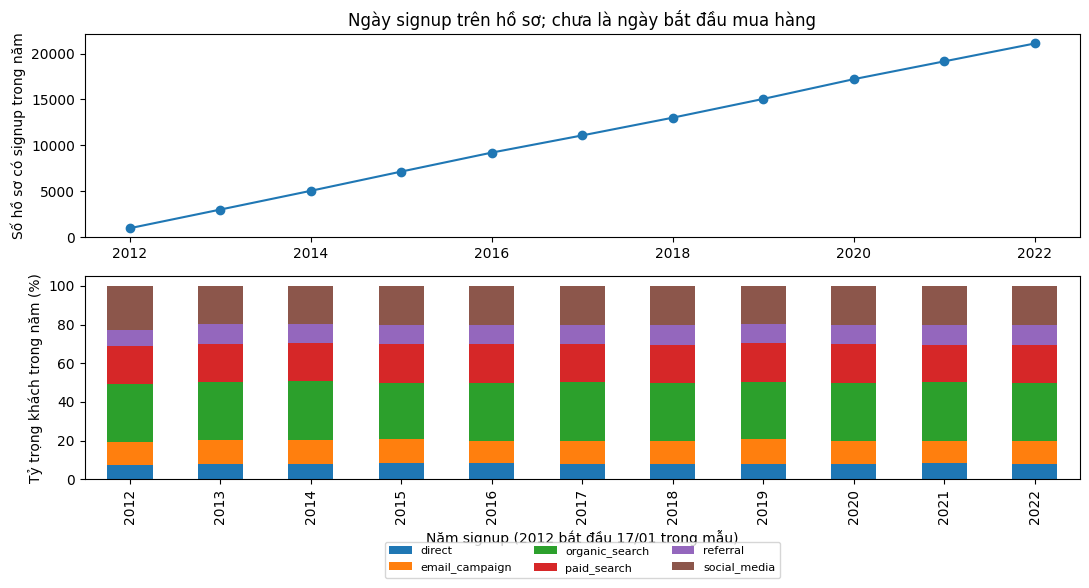

**Nhận xét.** organic_search có 36,450/121,930 hồ sơ, lớn nhất toàn kỳ. Năm 2022 có 21,103 signup, cao nhất; đổi cơ cấu đầu–cuối lớn nhất về trị tuyệt đối là social_media: -2.84 điểm %. Tổng theo kênh chịu trọng số của các năm đông hồ sơ, nên cần đọc tỷ trọng trong năm cùng tổng năm. Chưa chứng minh tác động chiến dịch; cần lịch sử ghi nhận signup và gán kênh.

In [31]:
acq63=c63.groupby('acquisition_channel',dropna=False).agg(Khách=('customer_id','nunique'),Signup_sớm=('_signup','min'),Signup_muộn=('_signup','max')).reset_index()
acq63['Mẫu số A: mọi khách']=len(c63);acq63['A: tỷ trọng mọi khách (%)']=100*acq63.Khách/len(c63)
for col in ['Signup_sớm','Signup_muộn']:acq63[col]=acq63[col].dt.strftime('%Y-%m-%d')
show(acq63,'Phân bố acquisition hồ sơ; tỷ trọng không là thị phần hoặc hiệu quả')
signup_year63=c63.groupby('_year').agg(Khách=('customer_id','nunique'),Kênh=('acquisition_channel','nunique'),Ngày_signup=('_signup','nunique'),Từ=('_signup','min'),Đến=('_signup','max')).reset_index()
signup_year63['Ngày lịch cả năm']=signup_year63._year.map(lambda y:366 if calendar.isleap(int(y)) else 365)
signup_year63['Thay đổi số hồ sơ YoY (%)']=100*signup_year63.Khách.pct_change(fill_method=None)
syc63=c63.groupby(['_year','acquisition_channel'],dropna=False).size().rename('Khách').reset_index()
syc63['Mẫu số B: khách trong năm']=syc63._year.map(signup_year63.set_index('_year').Khách)
syc63['Mẫu số C: khách riêng kênh']=syc63.acquisition_channel.map(acq63.set_index('acquisition_channel').Khách)
syc63['B: tỷ trọng trong năm (%)']=100*syc63.Khách/syc63['Mẫu số B: khách trong năm']
syc63['C: cơ cấu năm trong kênh (%)']=100*syc63.Khách/syc63['Mẫu số C: khách riêng kênh']
leaders_signup63=syc63.sort_values(['_year','Khách','acquisition_channel'],ascending=[True,False,True]).groupby('_year').head(1)
signup_year63=signup_year63.merge(leaders_signup63[['_year','acquisition_channel','B: tỷ trọng trong năm (%)']],on='_year',validate='one_to_one')
show(signup_year63.assign(_year=lambda d:d._year.astype(str)),'Tổng signup, số kênh và kênh đông nhất từng năm')
show(syc63.assign(_year=lambda d:d._year.astype(str)),'Hai mẫu số B/C: không cộng chéo tỷ lệ')
signup_month63=pd.crosstab(c63._month,c63.acquisition_channel,dropna=False).reset_index()
signup_month63['Tổng khách tháng']=signup_month63.drop(columns='_month').sum(axis=1)
show(signup_month63,'Số hồ sơ theo tháng signup và nhãn nguyên gốc, không phải conversion từ web')
share_matrix63=syc63.pivot(index='_year',columns='acquisition_channel',values='B: tỷ trọng trong năm (%)')
delta_share63=pd.DataFrame({'acquisition_channel':share_matrix63.columns,'Năm đầu (%)':share_matrix63.iloc[0].values,'Năm cuối (%)':share_matrix63.iloc[-1].values})
delta_share63['Chênh cuối–đầu (điểm %)']=delta_share63['Năm cuối (%)']-delta_share63['Năm đầu (%)']
delta_share63['Min tỷ trọng năm (%)']=share_matrix63.min().to_numpy();delta_share63['Max tỷ trọng năm (%)']=share_matrix63.max().to_numpy()
show(delta_share63,'Mức đổi cơ cấu mô tả; năm đầu/cuối theo phạm vi signup thực tế')
ck63('Kênh cộng đúng tổng khách',int(acq63.Khách.sum())==len(c63))
ck63('Mẫu số A tỷ trọng toàn khách',abs(acq63['A: tỷ trọng mọi khách (%)'].sum()-100)<1e-9)
ck63('Năm và tháng signup bảo toàn khách',int(signup_year63.Khách.sum())==len(c63) and int(signup_month63['Tổng khách tháng'].sum())==len(c63))
ck63('Mẫu số B tỷ trọng trong năm',np.allclose(syc63.groupby('_year')['B: tỷ trọng trong năm (%)'].sum(),100))
ck63('Mẫu số C cơ cấu năm riêng kênh',np.allclose(syc63.groupby('acquisition_channel')['C: cơ cấu năm trong kênh (%)'].sum(),100))
ck63('Không nhầm khách với đơn ở bảng signup',int(syc63.Khách.sum())==c63.customer_id.nunique())
fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(signup_year63._year,signup_year63.Khách,marker='o')
axs[0].set(ylabel='Số hồ sơ có signup trong năm',title='Ngày signup trên hồ sơ; chưa là ngày bắt đầu mua hàng')
share_matrix63.plot.bar(stacked=True,ax=axs[1],legend=True)
axs[1].set(xlabel='Năm signup (2012 bắt đầu 17/01 trong mẫu)',ylabel='Tỷ trọng khách trong năm (%)')
axs[1].legend(loc='upper center',bbox_to_anchor=(.5,-.28),ncol=3,fontsize=8);figdone(fig)
acq_leader63=acq63.sort_values('Khách',ascending=False).iloc[0]
signup_peak63=signup_year63.sort_values('Khách',ascending=False).iloc[0]
largest_delta63=delta_share63.loc[delta_share63['Chênh cuối–đầu (điểm %)'].abs().idxmax()]
note(f"**Nhận xét.** {acq_leader63.acquisition_channel} có {acq_leader63.Khách:,}/{len(c63):,} hồ sơ, lớn nhất toàn kỳ. Năm {int(signup_peak63._year)} có {signup_peak63.Khách:,} signup, cao nhất; đổi cơ cấu đầu–cuối lớn nhất về trị tuyệt đối là {largest_delta63.acquisition_channel}: {largest_delta63['Chênh cuối–đầu (điểm %)']:.2f} điểm %. Tổng theo kênh chịu trọng số của các năm đông hồ sơ, nên cần đọc tỷ trọng trong năm cùng tổng năm. Chưa chứng minh tác động chiến dịch; cần lịch sử ghi nhận signup và gán kênh.")

### NV06.3.4 — Khách có đơn và tiền theo thuộc tính acquisition
**Phân nhóm hồi cứu:** acquisition_channel được lấy từ hồ sơ hiện có, chưa xác nhận đã ghi nhận trước mọi đơn. Tiền lấy từ o62: items đã tổng hợp lên order_id rồi JOIN một–một với orders. LEFT JOIN hồ sơ theo khóa customer_id duy nhất, kiểm tra bảo toàn đơn và tiền.

Khách không có đơn xác định bằng đối chiếu tập ID; không tạo đơn 0, không điền NULL nguồn. Giá trị thiếu do không có bản ghi tổng hợp đơn vẫn để thiếu. Mean đơn trên mọi khách = tổng đơn / mọi khách; mean trên khách có đơn = tổng đơn / khách có đơn. Median và Net/khách có đơn chỉ dùng những khách có ít nhất một đơn. Chỉ gọi **“Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát”**.

In [32]:
money_cols63=['_gross_c','_discount_c','_net_c']
before_fin63=tuple(int(o62[c].sum()) for c in money_cols63)
orphan_orders63=orders.loc[~orders.customer_id.isin(c63.customer_id)]
o63=o62[['order_id','customer_id','order_date','order_status',*money_cols63]].merge(c63[['customer_id','acquisition_channel','signup_date','_signup']],on='customer_id',how='left',validate='many_to_one',indicator=True)
o63['_date']=dates(o63.order_date)
o63['_year']=o63._date.dt.year
ck63('JOIN đơn–khách không nhân đơn',len(o63)==len(orders) and o63.order_id.is_unique)
ck63('JOIN đơn–khách bảo toàn Gross/Discount/Net',tuple(int(o63[c].sum()) for c in money_cols63)==before_fin63)
ck63('Đơn không có khách được báo cáo',len(orphan_orders63)==int(o63._merge.eq('left_only').sum()),len(orphan_orders63))
ck63('Không có customer_id đơn mồ côi trong mẫu',len(orphan_orders63)==0)
buyers_set63=set(orders.customer_id.dropna())&set(c63.customer_id)
buyer_counts63=o63.groupby('customer_id').agg(_n_orders=('order_id','size'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum')).reset_index()
customer_orders63=c63.merge(buyer_counts63,on='customer_id',how='left',validate='one_to_one')
customer_orders63['_has_order']=customer_orders63.customer_id.isin(buyers_set63)
channel_orders63=customer_orders63.groupby('acquisition_channel',dropna=False).agg(customers=('customer_id','size'),buyers=('_has_order','sum'),orders=('_n_orders','sum'),median_orders_buyers=('_n_orders','median'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),median_net_buyers_c=('_net_c','median')).reset_index()
for col in ['customers','buyers','orders',*money_cols63]:channel_orders63[col]=channel_orders63[col].astype('int64')
channel_orders63['Khách không có đơn']=channel_orders63.customers-channel_orders63.buyers
channel_orders63['Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát (%)']=100*channel_orders63.buyers/channel_orders63.customers
channel_orders63['Mean đơn/mọi khách']=channel_orders63.orders/channel_orders63.customers
channel_orders63['Mean đơn/khách có đơn']=channel_orders63.orders/channel_orders63.buyers
def money63(v,digits=2):
    if pd.isna(v):return '∅'
    text=format(Decimal(str(v))/Decimal(100),f',.{digits}f')
    return text.replace(',','_').replace('.',',').replace('_','.')
channel_orders63['Mean Net/khách có đơn (ĐVT)']=[money63(Decimal(str(v))/Decimal(str(n)),6) for v,n in zip(channel_orders63._net_c,channel_orders63.buyers)]
channel_orders63['Median Net/khách có đơn (ĐVT)']=channel_orders63.median_net_buyers_c.map(money63)
show([{'Customers':len(c63),'Orders trước JOIN':len(orders),'Orders sau JOIN':len(o63),'Đơn mồ côi':len(orphan_orders63),'Khách có đơn':len(buyers_set63),'Khách không đơn':len(c63)-len(buyers_set63),'Khách sau JOIN cấp khách':len(customer_orders63),'Gross bảo toàn':tuple(int(o63[c].sum()) for c in money_cols63)==before_fin63}],'Kiểm tra độ phủ khóa, đơn và khách riêng')
orders_show63(channel_orders63[['acquisition_channel','customers','buyers','Khách không có đơn','Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát (%)','orders','Mean đơn/mọi khách','Mean đơn/khách có đơn','median_orders_buyers']].rename(columns={'customers':'Mọi khách trong kênh','buyers':'Khách có đơn','orders':'Tổng đơn','median_orders_buyers':'Median đơn/khách có đơn'}),'Đơn vị khách và hai mẫu số trung bình, toàn phạm vi orders')
finance_acq63=channel_orders63[['acquisition_channel','customers','buyers','orders',*money_cols63,'Mean Net/khách có đơn (ĐVT)','Median Net/khách có đơn (ĐVT)']].copy()
for c in money_cols63:finance_acq63[c]=finance_acq63[c].map(money63)
orders_show63(finance_acq63.rename(columns={'customers':'Mọi khách','buyers':'Khách có đơn','orders':'Đơn','_gross_c':'Gross (ĐVT)','_discount_c':'Discount (ĐVT)','_net_c':'Net số học (ĐVT)'}),'Tiền đơn thuộc khách theo nhãn hồ sơ; không phải doanh thu được quy thuộc')
ck63('Đếm khách có đơn độc lập tập ID và groupby',len(buyers_set63)==len(buyer_counts63)==int(customer_orders63._has_order.sum()))
ck63('Có/không có đơn bảo toàn khách',int(channel_orders63.buyers.sum()+channel_orders63['Khách không có đơn'].sum())==len(c63))
ck63('Các kênh bảo toàn đơn và tiền',int(channel_orders63.orders.sum())==len(orders) and tuple(int(channel_orders63[c].sum()) for c in money_cols63)==before_fin63)
ck63('Mean đơn hai mẫu số đúng tử số',np.allclose(channel_orders63['Mean đơn/mọi khách']*channel_orders63.customers,channel_orders63.orders) and np.allclose(channel_orders63['Mean đơn/khách có đơn']*channel_orders63.buyers,channel_orders63.orders))
ck63('Khách không đơn không bị tạo số tiền giả',customer_orders63.loc[~customer_orders63._has_order,['_n_orders',*money_cols63]].isna().all().all())
ck63('Tiền cấp đơn khớp items gốc đã kiểm chứng',tuple(int(o63[c].sum()) for c in money_cols63)==tuple(int(i62[c].sum()) for c in money_cols63))
buyer_rate_range63=channel_orders63['Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát (%)'].agg(['min','max'])
note(f"**Nhận xét.** {len(buyers_set63):,}/{len(c63):,} khách có đơn và {len(c63)-len(buyers_set63):,} khách không có đơn. Tỷ lệ theo nhãn hồ sơ từ {buyer_rate_range63['min']:.2f}% đến {buyer_rate_range63['max']:.2f}%; chỉ là sự hiện diện trong dữ liệu quan sát. Các mean/median dùng đúng tập khách và không lặp tiền đơn. Cần thời điểm gán kênh, thời gian quan sát tương đương và định nghĩa chuyển đổi trước so hiệu quả; không gọi Net là thực thu.")

**Kiểm tra độ phủ khóa, đơn và khách riêng**

Customers,Orders trước JOIN,Orders sau JOIN,Đơn mồ côi,Khách có đơn,Khách không đơn,Khách sau JOIN cấp khách,Gross bảo toàn
121.930,646.945,646.945,0,90.246,31.684,121.930,1


**Đơn vị khách và hai mẫu số trung bình, toàn phạm vi orders — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

acquisition_channel,Mọi khách trong kênh,Khách có đơn,Khách không có đơn,Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát (%),Tổng đơn,Mean đơn/mọi khách,Mean đơn/khách có đơn,Median đơn/khách có đơn
direct,9.803,7.337,2.466,"74,844435",52.019,"5,306437","7,089955",4
email_campaign,14.674,10.886,3.788,"74,185634",77.775,"5,300191","7,144498",4
organic_search,36.450,26.950,9.500,"73,9369",194.227,"5,328587","7,206939",4
paid_search,24.285,17.999,6.286,"74,115709",128.953,"5,309986","7,164454",4
referral,12.270,9.072,3.198,"73,93643",64.473,"5,254523","7,106812",4
social_media,24.448,18.002,6.446,"73,633835",129.498,"5,296875","7,193534",4


**Tiền đơn thuộc khách theo nhãn hồ sơ; không phải doanh thu được quy thuộc — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

acquisition_channel,Mọi khách,Khách có đơn,Đơn,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Mean Net/khách có đơn (ĐVT),Median Net/khách có đơn (ĐVT)
direct,9.803,7.337,52.019,"1.310.930.473,19","60.114.165,97","1.250.816.307,22","170.480,619766","88.171,44"
email_campaign,14.674,10.886,77.775,"1.967.111.032,67","90.204.665,87","1.876.906.366,80","172.414,694727","86.667,53"
organic_search,36.450,26.950,194.227,"4.937.571.851,57","225.383.620,61","4.712.188.230,96","174.849,285008","90.718,04"
paid_search,24.285,17.999,128.953,"3.271.722.558,11","149.343.233,00","3.122.379.325,11","173.475,155570","89.668,91"
referral,12.270,9.072,64.473,"1.634.969.451,48","74.987.921,55","1.559.981.529,93","171.955,636015","89.051,20"
social_media,24.448,18.002,129.498,"3.308.171.218,51","149.573.713,10","3.158.597.505,41","175.458,143840","92.181,97"


**Nhận xét.** 90,246/121,930 khách có đơn và 31,684 khách không có đơn. Tỷ lệ theo nhãn hồ sơ từ 73.63% đến 74.84%; chỉ là sự hiện diện trong dữ liệu quan sát. Các mean/median dùng đúng tập khách và không lặp tiền đơn. Cần thời điểm gán kênh, thời gian quan sát tương đương và định nghĩa chuyển đổi trước so hiệu quả; không gọi Net là thực thu.

### NV06.3.5 — Kiểm tra order_date và signup_date, đối chiếu V01
**Phân nhóm hồi cứu:** so ngày lịch YYYY-MM-DD của đơn và MM/DD/YYYY của signup; trước/bằng/sau hoặc không thể so sánh. Số khách giữa các nhóm ngày có thể giao nhau, không cộng thành tổng khách.

Nếu nhiều đơn trước signup, không dùng signup làm gốc conversion lag, retention hoặc cohort mua hàng hợp lệ; không quy tiền đơn trước signup cho tác động acquisition tại signup. Chưa có bằng chứng xác nhận signup sai hay giải thích bằng chuyển hệ thống; cần chủ nguồn xác minh ý nghĩa ngày và lịch sử ID.

In [33]:
comparable63=o63._date.notna()&o63._signup.notna()&o63._merge.eq('both')
o63['_time_state']=np.select([~comparable63,o63._date.lt(o63._signup),o63._date.eq(o63._signup)],['Không thể so','Trước signup','Bằng signup'],default='Sau signup')
o63['_gap_days']=(o63._date-o63._signup).dt.days
temporal63=o63.groupby('_time_state').agg(Đơn=('order_id','size'),Khách=('customer_id','nunique'),Năm_đơn_min=('_year','min'),Năm_đơn_max=('_year','max'),Signup_min=('_signup','min'),Signup_max=('_signup','max')).reindex(['Trước signup','Bằng signup','Sau signup','Không thể so'])
temporal63['Tỷ lệ/tất cả đơn (%)']=100*temporal63.Đơn/len(o63)
orders_show63(temporal63.reset_index(),'Ngày đặt so ngày signup; ô trống ở nhóm không xuất hiện không tự điền số nguồn')
temporal_channel63=o63.groupby(['acquisition_channel','_time_state'],dropna=False).agg(Đơn=('order_id','size'),Khách=('customer_id','nunique')).reset_index()
temporal_channel63['Mẫu số: đơn thuộc nhãn hồ sơ']=temporal_channel63.acquisition_channel.map(o63.groupby('acquisition_channel').size())
temporal_channel63['Tỷ lệ đơn trong nhãn (%)']=100*temporal_channel63.Đơn/temporal_channel63['Mẫu số: đơn thuộc nhãn hồ sơ']
orders_show63(temporal_channel63,'Đối chiếu thời gian trong từng acquisition_channel, không attribution')
before_signup63=o63.loc[o63._time_state.eq('Trước signup')]
before_year63=before_signup63.groupby('_year').agg(Đơn_trước=('order_id','size'),Khách=('customer_id','nunique'),Gap_min=('_gap_days','min'),Gap_max=('_gap_days','max')).reset_index()
before_year63['Mọi đơn năm']=before_year63._year.map(o63.groupby('_year').size());before_year63['Tỷ lệ trước/tất cả đơn năm (%)']=100*before_year63.Đơn_trước/before_year63['Mọi đơn năm']
orders_show63(before_year63.assign(_year=lambda d:d._year.astype(str)),'Phạm vi năm của đơn trước signup; gap âm theo order_date−signup_date')
examples_time63=pd.concat([g.head(3) for _,g in o63.groupby('_time_state')])
orders_show63(examples_time63[['order_id','customer_id','acquisition_channel','order_date','signup_date','_time_state','_gap_days']],'Ví dụ truy vết tối đa 3 đơn mỗi nhóm; không sửa ngày')
ck63('V01: số khách có đơn được tính lại',len(buyers_set63)==report_v01_63['metrics']['orders_distinct_customer_ids'])
ck63('V01: số đơn trước signup',len(before_signup63)==report_v01_63['metrics']['before_orders'],len(before_signup63))
ck63('V01: số bằng/sau/không so khớp',int(o63._time_state.eq('Bằng signup').sum())==report_v01_63['metrics']['equal_orders'] and int(o63._time_state.eq('Sau signup').sum())==report_v01_63['metrics']['after_orders'] and int((~comparable63).sum())==report_v01_63['metrics']['uncomparable_orders'])
ck63('Bốn trạng thái ngày bảo toàn đơn',int(o63._time_state.value_counts().sum())==len(orders))
ck63('Bảng thời gian theo kênh bảo toàn đơn',int(temporal_channel63.Đơn.sum())==len(o63))
ck63('Ngày so sánh kiểm tra độc lập bằng ánh xạ ID',int((od.to_numpy()<orders.customer_id.map(c63.set_index('customer_id')._signup).to_numpy()).sum())==len(before_signup63))
note(f"**Nhận xét.** {len(before_signup63):,}/{len(o63):,} đơn ({len(before_signup63)/len(o63)*100:.2f}%) có ngày trước signup, thuộc {before_signup63.customer_id.nunique():,} khách; bằng signup {o63._time_state.eq('Bằng signup').sum():,}, sau {o63._time_state.eq('Sau signup').sum():,}. Kết quả khớp V01 và ảnh hưởng mọi diễn giải hành trình acquisition. Bảng đơn/tiền theo kênh chỉ là phân nhóm hồi cứu. Cần nguồn gốc signup, thời điểm gán kênh và tính ổn định customer_id; chưa tính lag chuyển đổi hoặc retention từ signup.")

**Ngày đặt so ngày signup; ô trống ở nhóm không xuất hiện không tự điền số nguồn — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

_time_state,Đơn,Khách,Năm_đơn_min,Năm_đơn_max,Signup_min,Signup_max,Tỷ lệ/tất cả đơn (%)
Trước signup,477.453,80.623,2.012,2.022,2012-08-03 00:00:00,2022-12-31 00:00:00,"73,801173"
Bằng signup,149,148,2.013,2.022,2013-09-23 00:00:00,2022-12-28 00:00:00,"0,023031"
Sau signup,169.343,48.674,2.012,2.022,2012-01-20 00:00:00,2022-12-28 00:00:00,"26,175795"
Không thể so,∅,∅,∅,∅,∅,∅,∅


**Đối chiếu thời gian trong từng acquisition_channel, không attribution — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

acquisition_channel,_time_state,Đơn,Khách,Mẫu số: đơn thuộc nhãn hồ sơ,Tỷ lệ đơn trong nhãn (%)
direct,Bằng signup,15,15,52.019,"0,028836"
direct,Sau signup,13.625,3.987,52.019,"26,192353"
direct,Trước signup,38.379,6.520,52.019,"73,778812"
email_campaign,Bằng signup,15,15,77.775,"0,019286"
email_campaign,Sau signup,20.332,5.826,77.775,"26,142077"
email_campaign,Trước signup,57.428,9.721,77.775,"73,838637"
organic_search,Bằng signup,44,44,194.227,"0,022654"
organic_search,Sau signup,50.779,14.527,194.227,"26,144151"
organic_search,Trước signup,143.404,24.080,194.227,"73,833195"
paid_search,Bằng signup,32,32,128.953,"0,024815"


**Phạm vi năm của đơn trước signup; gap âm theo order_date−signup_date — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

_year,Đơn_trước,Khách,Gap_min,Gap_max,Mọi đơn năm,Tỷ lệ trước/tất cả đơn năm (%)
2012,31.894,21.975,-3.832,-2,32.051,"99,510156"
2013,75.410,38.713,-3.648,-1,76.849,"98,127497"
2014,76.492,38.454,-3.284,-1,80.645,"94,85027"
2015,74.216,36.914,-2.917,-1,82.622,"89,825954"
2016,68.321,34.392,-2.552,-1,82.247,"83,068075"
2017,57.007,30.032,-2.190,-1,76.010,"74,999342"
2018,45.526,25.081,-1.819,-1,69.510,"65,495612"
2019,22.423,14.840,-1.457,-1,41.601,"53,900147"
2020,14.023,9.957,-1.093,-1,34.881,"40,202402"
2021,8.850,6.319,-726,-1,34.525,"25,633599"


**Ví dụ truy vết tối đa 3 đơn mỗi nhóm; không sửa ngày — phân nhóm hồi cứu theo hồ sơ; nhiều đơn trước signup, chưa attribution**

order_id,customer_id,acquisition_channel,order_date,signup_date,_time_state,_gap_days
118265,60380,referral,2013-09-23,9/23/2013,Bằng signup,0
149618,106905,organic_search,2014-02-24,2/24/2014,Bằng signup,0
163978,8975,organic_search,2014-04-05,4/5/2014,Bằng signup,0
436,132875,paid_search,2012-07-05,4/12/2012,Sau signup,84
1888,46830,organic_search,2012-07-13,7/7/2012,Sau signup,6
2927,36443,referral,2012-07-17,7/4/2012,Sau signup,13
1,58578,social_media,2012-07-04,6/6/2020,Trước signup,-2.894
2,58621,social_media,2012-07-04,11/3/2021,Trước signup,-3.409
3,58811,direct,2012-07-04,9/18/2020,Trước signup,-2.998


**Nhận xét.** 477,453/646,945 đơn (73.80%) có ngày trước signup, thuộc 80,623 khách; bằng signup 149, sau 169,343. Kết quả khớp V01 và ảnh hưởng mọi diễn giải hành trình acquisition. Bảng đơn/tiền theo kênh chỉ là phân nhóm hồi cứu. Cần nguồn gốc signup, thời điểm gán kênh và tính ổn định customer_id; chưa tính lag chuyển đổi hoặc retention từ signup.

### NV06.3.6 — Web: cấu trúc, trạng thái số và cực trị
Đọc lại web_traffic, giữ bản chuỗi wraw63 và bản số w63 riêng. NULL, không đọc được, không hữu hạn và dấu được báo; thống kê trên số hữu hạn, không cắt cực trị. Std mẫu ddof=1, phân vị nội suy tuyến tính. IQR là quy tắc mô tả Q1−1,5IQR / Q3+1,5IQR để gắn cờ quan sát, không phải miền hợp lệ chính thức.

sessions/unique_visitors/page_views được kiểm tra số nguyên. Các bất đẳng thức thường gặp chỉ là giả thuyết về nghĩa tên trường. avg_session_duration_sec giữ đúng tên: hậu tố sec gợi ý đơn vị nhưng chưa có định nghĩa chính thức, không tự quy đổi. bounce_rate giữ nguyên thang, không nhân 100 hoặc suy số phiên thoát.

In [34]:
schema_web63=[]
stats_web63=[]
for col in wraw63:
    schema_web63.append({'Cột nguồn':col,'Kiểu đọc giữ nguyên':str(wraw63[col].dtype),'Kiểu phân tích':str(w63[col].dtype),'NULL nguồn':int(wraw63[col].isna().sum()),'Khác nhau không NULL':wraw63[col].nunique()})
show(schema_web63,'Schema và NULL thực tế: bản nguồn được giữ riêng')
for col in web_fields63:
    s=w63[col];finite=np.isfinite(s.fillna(np.nan));v=s.loc[finite]
    q1,q3=v.quantile([.25,.75]);iqr=q3-q1
    stats_web63.append({'Trường':col,'Hữu hạn':len(v),'NULL nguồn':int(wraw63[col].isna().sum()),'Không số không NULL':int((wraw63[col].notna()&s.isna()).sum()),'Không hữu hạn không NULL':int((s.notna()&~finite).sum()),'Min':v.min(),'Max':v.max(),'Mean':v.mean(),'Median':v.median(),'Std mẫu':v.std(ddof=1),'P25':q1,'P75':q3,'P90':v.quantile(.9),'P95':v.quantile(.95),'P99':v.quantile(.99),'Âm':int(v.lt(0).sum()),'Bằng 0':int(v.eq(0).sum()),'Dương':int(v.gt(0).sum()),'Không nguyên':int(v.ne(v.round()).sum()),'Cờ IQR (không loại)':int((v.lt(q1-1.5*iqr)|v.gt(q3+1.5*iqr)).sum())})
show(stats_web63,'Mọi trường số: số nguồn; bounce và thời lượng chưa xác minh đơn vị')
web_totals63={c:int(w63[c].sum()) for c in ['sessions','unique_visitors','page_views']}
show([{'Phép cộng':'Σ sessions theo ngày','Giá trị':web_totals63['sessions'],'Mẫu số mean/median':len(w63)},
{'Phép cộng':'Σ page_views theo ngày','Giá trị':web_totals63['page_views'],'Mẫu số mean/median':len(w63)},
{'Phép cộng':'Tổng các lượt khách phân biệt được ghi nhận theo từng ngày (Σ unique_visitors)','Giá trị':web_totals63['unique_visitors'],'Mẫu số mean/median':len(w63)}],'Tổng giá trị ghi nhận; Σ unique_visitors không là người duy nhất cả kỳ')
relations_web63=[{'Đối chiếu giả thuyết':label,'Số ngày':int(mask.sum()),'Mẫu số ngày':len(w63),'Kết luận':'Quan hệ số học; chưa xác nhận định nghĩa/vi phạm'} for label,mask in [('sessions < unique_visitors',w63.sessions.lt(w63.unique_visitors)),('page_views < sessions',w63.page_views.lt(w63.sessions)),('page_views < unique_visitors',w63.page_views.lt(w63.unique_visitors))]]
show(relations_web63,'Kiểm tra quan hệ thường gặp, không áp đặt miền nguồn')
extremes_web63=[]
for col in ['sessions','unique_visitors','page_views']:
    for label,ascending in [('Thấp',True),('Cao',False)]:
        g=w63.sort_values([col,'_date'],ascending=[ascending,True]).head(3)
        for _,r in g.iterrows():extremes_web63.append({'Trường':col,'Nhóm':label,'Ngày':str(r['_date'].date()),'Giá trị ghi nhận':r[col],'Nhãn ngày':r.traffic_source})
show(extremes_web63,'3 ngày cao/thấp mỗi số lượng, hòa thì ngày tăng dần; không loại khỏi phân tích')
for col in ['sessions','unique_visitors','page_views']:
    ck63(col+': nguồn hữu hạn và nguyên được kiểm tra',w63[col].notna().all() and np.isfinite(w63[col]).all() and w63[col].eq(w63[col].round()).all())
ck63('Số dòng và nhãn một/ngày',w63._date.notna().all() and w63._date.is_unique and wraw63.traffic_source.notna().all())
ck63('Phủ đủ lịch từ min đến max',len(pd.date_range(w63._date.min(),w63._date.max()).difference(pd.DatetimeIndex(w63._date)))==0)
ck63('Phạm vi web khớp V07',str(w63._date.min().date())==reports['v07']['metrics']['date_min'] and str(w63._date.max().date())==reports['v07']['metrics']['date_max'])
ck63('Giữ nguyên mọi giá trị trường web nguồn',wraw63.equals(web))
note(f"**Nhận xét.** Web có {len(w63):,} ngày, tổng sessions {web_totals63['sessions']:,}, page_views {web_totals63['page_views']:,}; Σ unique_visitors là {web_totals63['unique_visitors']:,} lượt khách phân biệt ghi theo từng ngày. Các cờ IQR và quan hệ số học chỉ mô tả, không loại hoặc sửa số. Cần định nghĩa người/phiên/sự kiện và đơn vị thời lượng trước diễn giải hành vi hoặc sai dữ liệu.")

**Schema và NULL thực tế: bản nguồn được giữ riêng**

Cột nguồn,Kiểu đọc giữ nguyên,Kiểu phân tích,NULL nguồn,Khác nhau không NULL
date,string,string,0,3.652
sessions,string,Int64,0,3.447
unique_visitors,string,Int64,0,3.382
page_views,string,Int64,0,3.620
bounce_rate,string,Float64,0,261
avg_session_duration_sec,string,Float64,0,1.771
traffic_source,string,string,0,6


**Mọi trường số: số nguồn; bounce và thời lượng chưa xác minh đơn vị**

Trường,Hữu hạn,NULL nguồn,Không số không NULL,Không hữu hạn không NULL,Min,Max,Mean,Median,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương,Không nguyên,Cờ IQR (không loại)
sessions,3.652,0,0,0,7.973,50.947,"25.041,768072","23.633,5","9.422,609335","17.099,25","31.782,75","38.764,1",42.365,"47.227,96",0,0,3.652,0,0
unique_visitors,3.652,0,0,0,6.136,40.430,"19.031,404436",17.924,"7.237,953062",12.915,"24.191,75",29.407,"32.397,3","36.726,2",0,0,3.652,0,0
page_views,3.652,0,0,0,30.451,275.560,"108.615,224535","101.010,5","44.472,055524",72.982,138.086,"172.393,5","190.782,9","223.688,37",0,0,3.652,0,18
bounce_rate,3.652,0,0,0,"0,0032","0,0058","0,004487","0,00445","0,000753","0,003848","0,00516","0,00555","0,00566","0,00577",0,0,3.652,3.652,0
avg_session_duration_sec,3.652,0,0,0,"100,1","319,9","210,283242","209,2","63,771711","156,7","266,2","298,3",310,"317,7",0,0,3.652,3.297,0


**Tổng giá trị ghi nhận; Σ unique_visitors không là người duy nhất cả kỳ**

Phép cộng,Giá trị,Mẫu số mean/median
Σ sessions theo ngày,91.452.537,3.652
Σ page_views theo ngày,396.662.800,3.652
Tổng các lượt khách phân biệt được ghi nhận theo từng ngày (Σ unique_visitors),69.502.689,3.652


**Kiểm tra quan hệ thường gặp, không áp đặt miền nguồn**

Đối chiếu giả thuyết,Số ngày,Mẫu số ngày,Kết luận
sessions < unique_visitors,0,3.652,Quan hệ số học; chưa xác nhận định nghĩa/vi phạm
page_views < sessions,0,3.652,Quan hệ số học; chưa xác nhận định nghĩa/vi phạm
page_views < unique_visitors,0,3.652,Quan hệ số học; chưa xác nhận định nghĩa/vi phạm


**3 ngày cao/thấp mỗi số lượng, hòa thì ngày tăng dần; không loại khỏi phân tích**

Trường,Nhóm,Ngày,Giá trị ghi nhận,Nhãn ngày
sessions,Thấp,2014-01-27,7.973,organic_search
sessions,Thấp,2013-01-15,8.102,direct
sessions,Thấp,2013-01-14,8.230,paid_search
sessions,Cao,2022-06-26,50.947,organic_search
sessions,Cao,2022-04-04,50.915,social_media
sessions,Cao,2021-04-30,50.714,organic_search
unique_visitors,Thấp,2013-01-12,6.136,paid_search
unique_visitors,Thấp,2013-01-19,6.138,organic_search
unique_visitors,Thấp,2013-01-15,6.179,direct
unique_visitors,Cao,2021-04-25,40.430,paid_search


**Nhận xét.** Web có 3,652 ngày, tổng sessions 91,452,537, page_views 396,662,800; Σ unique_visitors là 69,502,689 lượt khách phân biệt ghi theo từng ngày. Các cờ IQR và quan hệ số học chỉ mô tả, không loại hoặc sửa số. Cần định nghĩa người/phiên/sự kiện và đơn vị thời lượng trước diễn giải hành vi hoặc sai dữ liệu.

### NV06.3.7 — Xu hướng web theo tháng/năm
Nguồn web chỉ 01/01/2013–31/12/2022, không đưa 2012 vào traffic. Tổng sessions và page_views là phép cộng số nguồn. **UV-ngày** trong tiêu đề bảng là “tổng các lượt khách phân biệt được ghi nhận theo từng ngày”, không phải số người duy nhất cả tháng/năm.

Mean/median theo ngày và số ngày được báo cùng tổng kỳ. YoY tổng và YoY mean/ngày tách riêng vì năm nhuận có 366 ngày. Không cộng bounce_rate hay thời lượng, chỉ thống kê số nguồn. Các biến động chưa được quy cho chương trình hoặc doanh thu.

**Web theo năm; UV-ngày không khử trùng người xuyên ngày, tỷ lệ nguồn không đổi thang**

_year,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn),Ngày lịch cả năm,YoY tổng sessions (%),YoY mean sessions/ngày (%),YoY tổng page_views (%)
2013,365,1,2013-01-01,2013-12-31,6.801.940,"18.635,452055",18.275,"27.147,8","28.560,2",29.403.658,"80.557,967123",74.574,5.166.501,"14.154,79726",13.750,"0,004545","0,0045","0,00565","206,941644","200,9",365,∅,∅,∅
2014,365,1,2014-01-01,2014-12-31,7.340.960,"20.112,219178",19.708,"29.548,6","30.981,4",31.947.207,"87.526,594521",83.362,5.596.248,"15.332,186301",15.014,"0,00445","0,00439","0,00568","212,567671","214,3",365,"7,924504","7,924504","8,650451"
2015,365,1,2015-01-01,2015-12-31,7.861.938,"21.539,556164",20.962,"31.311,4","33.317,6",34.175.895,"93.632,589041",87.438,5.962.192,"16.334,772603",15.874,"0,004409","0,00433","0,00563","216,365479","220,5",365,"7,096865","7,096865","6,976159"
2016,366,1,2016-01-01,2016-12-31,8.403.399,"22.960,106557","22.958,5",33.544,35.176,36.322.275,"99.241,188525",94.944,6.393.654,17.469,"17.046,5","0,004425","0,004395","0,00563","205,377049","197,9",366,"6,887119","6,595077","6,280391"
2017,365,1,2017-01-01,2017-12-31,8.992.602,"24.637,265753",24.119,35.697,"37.329,4",38.785.941,"106.262,852055",102.782,6.818.372,"18.680,471233",18.584,"0,004479","0,00439","0,00568","209,265205","210,6",365,"7,011484","7,304666","6,782797"
2018,365,1,2018-01-01,2018-12-31,9.415.085,"25.794,753425",25.444,"37.943,2","40.069,6",41.461.837,"113.594,073973",109.317,7.143.496,"19.571,221918",19.107,"0,004528","0,00455","0,005686","208,406027","209,3",365,"4,698117","4,698117","6,899139"
2019,365,1,2019-01-01,2019-12-31,9.990.148,"27.370,268493",26.432,"40.196,6","42.053,6",42.927.110,"117.608,520548",110.379,7.580.565,"20.768,671233",20.184,"0,004539","0,0046","0,005718","207,552329","206,2",365,"6,10789","6,10789","3,534028"
2020,366,1,2020-01-01,2020-12-31,10.591.082,"28.937,382514",28.665,43.053,45.218,46.146.457,"126.083,215847",119.885,8.065.367,"22.036,521858",21.541,"0,004546","0,00449","0,00569","213,418033","203,6",366,"6,015266","5,725607","7,499566"
2021,365,1,2021-01-01,2021-12-31,10.991.725,"30.114,315068",29.427,"44.361,6","46.275,6",47.760.867,"130.851,690411",123.393,8.367.014,"22.923,326027",22.131,"0,004464","0,00446","0,005648","210,011507","209,8",365,"3,782834","4,06717","3,498448"
2022,365,1,2022-01-01,2022-12-31,11.063.658,"30.311,391781",29.790,"44.453,4","47.173,2",47.731.553,"130.771,378082",126.179,8.409.280,"23.039,123288",22.594,"0,004489","0,00451","0,005628","212,932329","216,6",365,"0,654429","0,654429","-0,061377"


**Web theo tháng; tổng tháng và mean/ngày có đơn vị khác nhau**

_month,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn),Ngày lịch cả tháng
2013-01,31,1,2013-01-01,2013-01-31,295.006,"9.516,322581",9.698,10.270,"10.397,5",1.249.046,"40.291,806452",39.117,224.927,"7.255,709677",7.368,"0,00453","0,00445","0,00558","222,6","238,2",31
2013-02,28,1,2013-02-01,2013-02-28,416.896,"14.889,142857","14.711,5","16.004,9","16.472,15",1.812.512,"64.732,571429","63.202,5",316.689,"11.310,321429",11.150,"0,004506","0,0044","0,005594","205,817857","201,6",28
2013-03,31,1,2013-03-01,2013-03-31,622.174,"20.070,129032",20.504,21.762,"22.460,5",2.735.450,"88.240,322581",85.400,477.302,"15.396,83871",15.498,"0,004503","0,00437","0,005725","205,851613","195,9",31
2013-04,30,1,2013-04-01,2013-04-30,814.380,27.146,26.853,"31.055,3","32.470,75",3.495.043,"116.501,433333",114.223,615.275,"20.509,166667","20.744,5","0,004672","0,00477","0,005537","206,72","204,75",30
2013-05,31,1,2013-05-01,2013-05-31,816.540,26.340,26.616,28.654,28.876,3.554.250,"114.653,225806",113.183,621.639,"20.052,870968",20.140,"0,004475","0,00445","0,005605","208,806452","198,2",31
2013-06,30,1,2013-06-01,2013-06-30,802.614,"26.753,8","26.815,5","28.869,6","29.005,3",3.595.391,"119.846,366667",125.099,609.958,"20.331,933333",20.505,"0,004588","0,004625","0,005642","201,78","190,9",30
2013-07,31,1,2013-07-01,2013-07-31,655.041,"21.130,354839",20.990,22.930,"24.095,5",2.763.177,"89.134,741935",88.626,492.361,"15.882,612903",16.026,"0,00461","0,0045","0,005635","197,56129","187,7",31
2013-08,31,1,2013-08-01,2013-08-31,709.622,"22.891,032258",23.027,25.048,25.388,2.984.208,"96.264,774194",95.876,537.601,"17.341,967742",17.269,"0,004488","0,00437","0,005655","206,870968","193,3",31
2013-09,30,1,2013-09-01,2013-09-30,506.857,"16.895,233333",16.802,"19.224,9","19.481,1",2.177.198,"72.573,266667","72.989,5",386.480,"12.882,666667","12.768,5","0,004676","0,00471","0,0056","204,643333","202,85",30
2013-10,31,1,2013-10-01,2013-10-31,414.758,"13.379,290323",13.080,14.589,15.289,1.818.852,"58.672,645161",58.429,314.764,"10.153,677419",9.851,"0,004389","0,00435","0,00557","212,316129","209,6",31


**Tháng nổi bật theo mean sessions/ngày, không loại khỏi chuỗi**

Nhóm,_month,Ngày quan sát,Tổng sessions ghi nhận,Mean sessions/ngày,Mean page_views/ngày,Mean unique_visitors/ngày
3 tháng mean cao,2022-04,30,1.345.666,"44.855,533333","188.554,066667","33.962,966667"
3 tháng mean cao,2021-04,30,1.332.462,"44.415,4","189.588,233333","33.676,566667"
3 tháng mean cao,2021-06,30,1.320.205,"44.006,833333","201.526,666667","34.003,333333"
3 tháng mean thấp,2013-01,31,295.006,"9.516,322581","40.291,806452","7.255,709677"
3 tháng mean thấp,2014-01,31,331.441,"10.691,645161","46.463,258065","8.180,806452"
3 tháng mean thấp,2013-11,30,341.927,"11.397,566667","49.399,666667","8.701,533333"


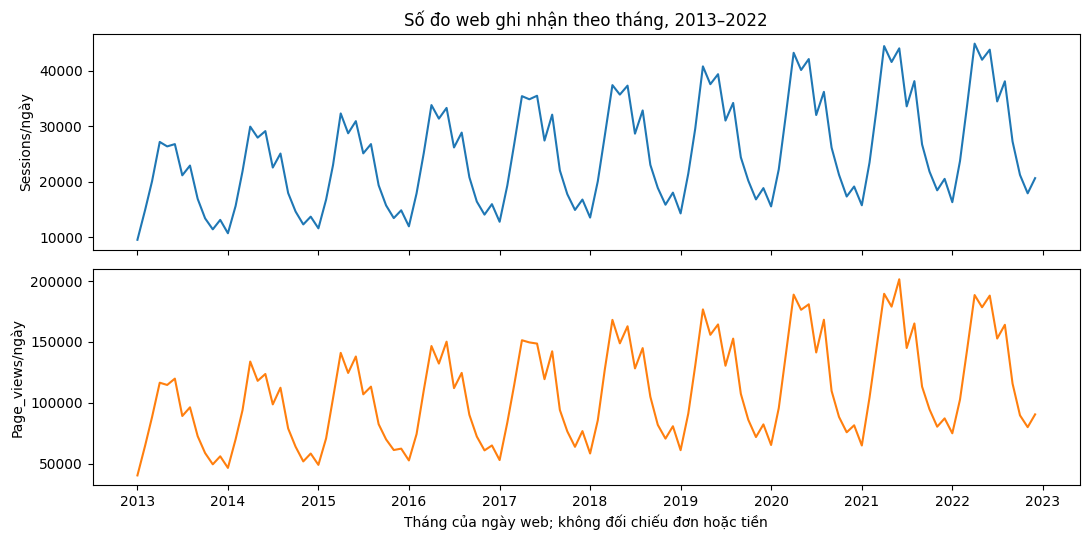

**Nhận xét.** Mean sessions/ngày từ 18635.45 năm 2013 đến 30311.39 năm 2022; cao nhất là 2022 với 30311.39. Các bảng giữ 120 tháng và năm nhuận đầy đủ; Σ UV-ngày chỉ cộng số đo từng ngày. Cần xác minh tính ổn định công cụ đo trước diễn giải xu hướng; không quy thay đổi cho chiến dịch.

In [35]:
def web_summary63(d,key):
    return d.groupby(key,dropna=False,observed=True).agg(days=('_date','size'),years=('_year','nunique'),first=('_date','min'),last=('_date','max'),
        sessions_total=('sessions','sum'),sessions_mean=('sessions','mean'),sessions_median=('sessions','median'),sessions_p90=('sessions',lambda x:x.quantile(.9)),sessions_p95=('sessions',lambda x:x.quantile(.95)),
        pv_total=('page_views','sum'),pv_mean=('page_views','mean'),pv_median=('page_views','median'),
        uv_daily_sum=('unique_visitors','sum'),uv_mean=('unique_visitors','mean'),uv_median=('unique_visitors','median'),
        bounce_mean=('bounce_rate','mean'),bounce_median=('bounce_rate','median'),bounce_p95=('bounce_rate',lambda x:x.quantile(.95)),
        duration_mean=(duration_field63,'mean'),duration_median=(duration_field63,'median')).reset_index()
def web_view63(t):
    t=t.copy()
    for c in ['first','last']:
        if c in t:t[c]=t[c].dt.strftime('%Y-%m-%d')
    if '_year' in t:t['_year']=t['_year'].astype(str)
    return t.rename(columns={'days':'Ngày quan sát','years':'Số năm','first':'Ngày đầu','last':'Ngày cuối','sessions_total':'Tổng sessions ghi nhận','sessions_mean':'Mean sessions/ngày','sessions_median':'Median sessions/ngày','sessions_p90':'P90 sessions/ngày','sessions_p95':'P95 sessions/ngày','pv_total':'Tổng page_views ghi nhận','pv_mean':'Mean page_views/ngày','pv_median':'Median page_views/ngày','uv_daily_sum':'Tổng UV-ngày (không phải người duy nhất cả kỳ)','uv_mean':'Mean unique_visitors/ngày','uv_median':'Median unique_visitors/ngày','bounce_mean':'Mean bounce_rate nguồn','bounce_median':'Median bounce_rate nguồn','bounce_p95':'P95 bounce_rate nguồn','duration_mean':'Mean '+duration_field63+' (số nguồn)','duration_median':'Median '+duration_field63+' (số nguồn)'})
wy63=web_summary63(w63,'_year')
wy63['Ngày lịch cả năm']=wy63._year.map(lambda y:366 if calendar.isleap(int(y)) else 365)
wy63['YoY tổng sessions (%)']=100*wy63.sessions_total.pct_change(fill_method=None)
wy63['YoY mean sessions/ngày (%)']=100*wy63.sessions_mean.pct_change(fill_method=None)
wy63['YoY tổng page_views (%)']=100*wy63.pv_total.pct_change(fill_method=None)
wm63=web_summary63(w63,'_month');wm63['Ngày lịch cả tháng']=wm63._month.map(lambda m:pd.Period(m,'M').days_in_month)
show(web_view63(wy63),'Web theo năm; UV-ngày không khử trùng người xuyên ngày, tỷ lệ nguồn không đổi thang')
show(web_view63(wm63),'Web theo tháng; tổng tháng và mean/ngày có đơn vị khác nhau')
month_extremes63=pd.concat([wm63.sort_values(['sessions_mean','_month'],ascending=[False,True]).head(3).assign(Nhóm='3 tháng mean cao'),wm63.sort_values(['sessions_mean','_month']).head(3).assign(Nhóm='3 tháng mean thấp')])
show(web_view63(month_extremes63[['Nhóm','_month','days','sessions_total','sessions_mean','pv_mean','uv_mean']]),'Tháng nổi bật theo mean sessions/ngày, không loại khỏi chuỗi')
for label,t in [('năm',wy63),('tháng',wm63)]:
    ck63('Web '+label+': bảo toàn ngày và ba số lượng',int(t.days.sum())==len(w63) and all(int(t[k].sum())==web_totals63[v] for k,v in [('sessions_total','sessions'),('pv_total','page_views'),('uv_daily_sum','unique_visitors')]))
    ck63('Web '+label+': mean/ngày dùng đúng mẫu số',np.allclose(t.sessions_mean*t.days,t.sessions_total) and np.allclose(t.pv_mean*t.days,t.pv_total))
ck63('Web đủ ngày từng năm kể cả nhuận',wy63.days.eq(wy63['Ngày lịch cả năm']).all())
ck63('Web đủ ngày từng tháng',wm63.days.eq(wm63['Ngày lịch cả tháng']).all())
ck63('Traffic không bao gồm năm 2012',w63._year.min()==2013 and not w63._year.eq(2012).any())
fig,axs=plt.subplots(2,1,figsize=(11,5.5),sharex=True)
axs[0].plot(pd.to_datetime(wm63._month),wm63.sessions_mean,label='Mean sessions/ngày')
axs[0].set(ylabel='Sessions/ngày',title='Số đo web ghi nhận theo tháng, 2013–2022')
axs[1].plot(pd.to_datetime(wm63._month),wm63.pv_mean,color='tab:orange')
axs[1].set(ylabel='Page_views/ngày',xlabel='Tháng của ngày web; không đối chiếu đơn hoặc tiền');figdone(fig)
web_first63,web_last63=wy63.iloc[0],wy63.iloc[-1]
web_peak_year63=wy63.sort_values('sessions_mean',ascending=False).iloc[0]
note(f"**Nhận xét.** Mean sessions/ngày từ {web_first63.sessions_mean:.2f} năm {int(web_first63._year)} đến {web_last63.sessions_mean:.2f} năm {int(web_last63._year)}; cao nhất là {int(web_peak_year63._year)} với {web_peak_year63.sessions_mean:.2f}. Các bảng giữ {len(wm63)} tháng và năm nhuận đầy đủ; Σ UV-ngày chỉ cộng số đo từng ngày. Cần xác minh tính ổn định công cụ đo trước diễn giải xu hướng; không quy thay đổi cho chiến dịch.")

### NV06.3.8 — Tháng lịch, thứ và nhóm ngày
So tháng 1–12 trên tất cả năm; mỗi tháng báo số ngày và số năm được đại diện. Bảng năm × tháng kiểm tra đỉnh có lặp giữa năm không, không kết luận mùa vụ từ trung bình gộp vì xu hướng dài hạn có thể gây khác biệt.

Thứ lấy từ ngày thực tế (Thứ Hai=0…Chủ nhật=6). Cuối tuần = Thứ Bảy/Chủ nhật, chỉ là quy ước mô tả. Bounce và thời lượng vẫn giữ số nguồn, không diễn giải thành chuyển đổi hay hoạt động mua hàng.

**Tháng lịch, mẫu số là tất cả ngày của tháng qua các năm 2013–2022**

_calendar_month,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn)
1,310,10,2013-01-01,2022-01-31,4.086.801,"13.183,229032",13.151,"16.279,9","16.820,65",17.536.012,"56.567,780645","55.436,5",3.104.735,"10.015,274194","9.951,5","0,004542","0,004525","0,00565","213,276452","217,2"
2,282,10,2013-02-01,2022-02-28,5.507.525,"19.530,230496",19.490,"24.003,6","25.605,4",23.764.305,"84.270,585106","82.868,5",4.178.528,"14.817,475177","14.747,5","0,004518","0,004525","0,005628","211,394681","210,3"
3,310,10,2013-03-01,2022-03-31,8.468.196,"27.316,76129",27.582,"34.446,3","35.796,5",37.090.101,"119.645,487097","117.798,5",6.450.121,"20.806,841935","20.739,5","0,004486","0,00439","0,00567","214,283548",214
4,300,10,2013-04-01,2022-04-30,11.074.024,"36.913,413333","36.663,5","46.241,9","47.573,5",48.042.273,"160.140,91","157.818,5",8.407.220,"28.024,066667","27.741,5","0,0045","0,00454","0,005691","202,807667","197,7"
5,310,10,2013-05-01,2022-05-31,10.725.045,"34.596,919355","34.543,5","42.643,1","45.441,35",45.810.628,"147.776,219355",146.429,8.192.137,"26.426,248387","26.386,5","0,004502","0,004435","0,005706","208,566452","210,9"
6,300,10,2013-06-01,2022-06-30,10.859.389,"36.197,963333","35.810,5","44.662,4","46.602,95",47.348.842,"157.829,473333","153.762,5",8.254.065,"27.513,55",27.222,"0,004494","0,00445","0,00562","207,819667","206,3"
7,310,10,2013-07-01,2022-07-31,8.739.569,"28.192,158065","27.715,5","34.712,5","35.659,05",37.946.963,"122.409,558065",121.391,6.617.581,"21.347,035484",21.252,"0,004489","0,00453","0,00565","211,840645","211,2"
8,310,10,2013-08-01,2022-08-31,9.763.082,"31.493,812903","31.571,5","39.163,8","40.987,9",42.904.668,"138.402,154839","135.753,5",7.414.104,"23.916,464516",23.776,"0,004408","0,004375","0,005686","212,262903","210,65"
9,300,10,2013-09-01,2022-09-30,6.732.077,"22.440,256667",22.264,"27.860,7","28.930,05",29.072.906,"96.909,686667",95.890,5.098.842,"16.996,14",16.840,"0,004484","0,004405","0,0057","210,646667","207,6"
10,310,10,2013-10-01,2022-10-31,5.614.576,"18.111,535484","18.160,5",22.208,"23.317,3",24.233.222,"78.171,683871","77.592,5",4.281.363,"13.810,848387","13.837,5","0,004437","0,004325","0,00564","209,745806","206,35"


**Mean sessions/ngày: năm × tháng lịch; không khử xu hướng dài hạn**

Năm,1,2,3,4,5,6,7,8,9,10,11,12
2013,"9.516,322581","14.889,142857","20.070,129032",27.146,26.340,"26.753,8","21.130,354839","22.891,032258","16.895,233333","13.379,290323","11.397,566667","13.100,806452"
2014,"10.691,645161","15.605,285714","21.874,741935","29.905,366667","27.921,645161","29.098,466667","22.531,83871","25.054,806452","17.938,566667","14.602,516129","12.282,7",13.686
2015,"11.580,193548","16.749,821429",22.976,"32.279,666667",28.702,"30.892,9","25.087,290323","26.758,967742","19.337,033333","15.713,354839","13.422,366667","14.826,83871"
2016,"11.940,935484","17.883,413793","25.136,612903","33.787,066667","31.342,129032","33.273,3","26.151,290323","28.830,290323","20.780,7","16.401,064516",14.053,"15.938,258065"
2017,"12.762,516129","19.302,178571","26.807,935484","35.396,766667","34.829,032258","35.465,733333","27.394,741935",32.064,22.011,"17.736,225806","14.893,2","16.764,903226"
2018,"13.519,096774","20.051,678571","28.211,741935","37.381,733333","35.674,064516","37.289,4",28.638,"32.821,387097","23.012,8","18.866,387097","15.836,2","18.012,354839"
2019,"14.268,096774","21.449,928571","29.532,870968","40.760,466667","37.548,354839","39.351,2","30.996,677419","34.171,870968","24.374,433333","20.177,064516","16.792,9",18.827
2020,"15.529,032258","22.215,344828","32.146,225806","43.206,133333","40.107,903226","42.078,633333","31.995,258065","36.172,032258","26.125,633333","21.227,935484",17.314,"19.115,322581"
2021,"15.733,83871","23.417,714286","32.935,387097","44.415,4","41.548,806452","44.006,833333","33.555,129032","38.102,580645","26.702,433333","21.805,677419","18.429,533333","20.492,870968"
2022,"16.290,612903","23.700,714286","33.475,967742","44.855,533333","41.955,258065","43.769,366667",34.441,"38.071,16129","27.224,733333","21.205,83871","17.887,866667","20.621,870968"


**Độ lặp tháng cao: kiểm tra riêng từng năm, không mặc định mùa vụ ổn định**

Năm,Tháng mean cao nhất,Mean sessions/ngày,Top 3 tháng (hòa theo tháng tăng)
2013,4,27.146,"4, 6, 5"
2014,4,"29.905,366667","4, 6, 5"
2015,4,"32.279,666667","4, 6, 5"
2016,4,"33.787,066667","4, 6, 5"
2017,6,"35.465,733333","6, 4, 5"
2018,4,"37.381,733333","4, 6, 5"
2019,4,"40.760,466667","4, 6, 5"
2020,4,"43.206,133333","4, 6, 5"
2021,4,"44.415,4","4, 6, 5"
2022,4,"44.855,533333","4, 6, 5"


**Thứ trong tuần: mean/median số lượng, bounce_rate và thời lượng số nguồn**

_weekday,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn),Thứ
0,521,10,2013-01-07,2022-12-26,13.140.757,"25.222,182342",23.617,39.843,44.198,56.474.731,"108.396,796545",101.385,10.005.680,"19.204,760077",17.883,"0,004532","0,00453","0,00568","207,631478","207,9",Thứ Hai
1,522,10,2013-01-01,2022-12-27,13.005.512,"24.914,773946",23.627,"37.918,4","41.407,8",56.635.272,"108.496,689655",102.825,9.878.977,"18.925,243295",17.862,"0,00449","0,00449","0,005699","209,617816","208,95",Thứ Ba
2,522,10,2013-01-02,2022-12-28,13.128.406,"25.150,203065",23.834,"38.682,2","42.475,05",57.348.673,"109.863,358238","101.048,5",10.003.904,"19.164,56705","18.203,5","0,004515","0,004515","0,005679","209,865134","206,55",Thứ Tư
3,522,10,2013-01-03,2022-12-29,13.130.360,"25.153,94636","24.045,5","39.149,1","43.020,5",57.511.206,"110.174,724138","102.038,5",9.980.663,"19.120,044061","18.070,5","0,004495","0,00442","0,005699","210,11954","210,25",Thứ Năm
4,522,10,2013-01-04,2022-12-30,12.986.767,"24.878,863985",23.422,"38.206,5","41.068,7",56.084.604,"107.441,770115",99.703,9.858.729,"18.886,454023","17.966,5","0,004431","0,00441","0,005629","211,398276","210,15",Thứ Sáu
5,522,10,2013-01-05,2022-12-31,13.009.630,"24.922,662835","23.352,5","38.342,7","42.438,45",56.883.000,"108.971,264368","100.489,5",9.873.361,"18.914,484674",17.799,"0,004497","0,004475","0,00566","214,931226","214,6",Thứ Bảy
6,521,10,2013-01-06,2022-12-25,13.051.105,"25.050,105566",23.398,38.704,42.050,55.725.314,"106.958,3762",99.403,9.901.375,"19.004,558541",17.411,"0,00445","0,00439","0,00566","208,410557","205,2",Chủ nhật


**Ngày thường/cuối tuần: số ngày làm mẫu số, không là ngày chiến dịch**

_day_group,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn)
Cuối tuần,1.043,10,2013-01-05,2022-12-31,26.060.735,"24.986,323106",23.398,"38.513,8","42.318,3",112.608.314,"107.965,785235",100.168,19.774.736,"18.959,478428",17.584,"0,004474","0,00442","0,00566","211,674017","209,4"
Ngày thường,2.609,10,2013-01-01,2022-12-30,65.391.802,"25.063,933308",23.757,"38.865,4",42.404,284.054.486,"108.874,850901",101.309,49.727.953,"19.060,158298",18.012,"0,004493","0,00447","0,00567","209,727252","208,8"


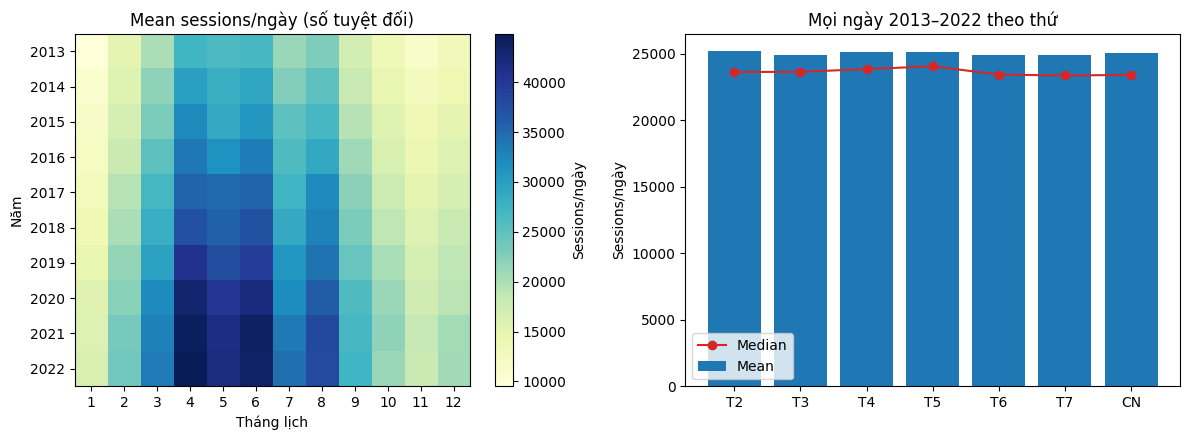

**Nhận xét.** Tháng 4 là tháng mean sessions cao nhất ở 9/10 năm. Thứ Hai có mean sessions/ngày cao nhất: 25222.18; số ngày của các thứ không hoàn toàn bằng nhau nên dùng mean cùng số ngày. Đây là dấu hiệu lặp mô tả, chưa chứng minh mùa vụ hoặc mua hàng; cần kiểm tra lịch đo và các yếu tố thời gian.

In [36]:
calendar_month63=web_summary63(w63,'_calendar_month')
weekday63=web_summary63(w63,'_weekday')
weekday63['Thứ']=weekday63._weekday.map(weekday_names63)
day_group63=web_summary63(w63,'_day_group')
ym_session63=w63.groupby(['_year','_calendar_month']).sessions.mean().unstack('_calendar_month')
show(web_view63(calendar_month63),'Tháng lịch, mẫu số là tất cả ngày của tháng qua các năm 2013–2022')
show(ym_session63.rename_axis('Năm').reset_index().assign(Năm=lambda d:d.Năm.astype(str)),'Mean sessions/ngày: năm × tháng lịch; không khử xu hướng dài hạn')
peaks_calendar63=[]
for year,g in w63.groupby('_year'):
    t=g.groupby('_calendar_month').sessions.mean().sort_values(ascending=False,kind='stable')
    peaks_calendar63.append({'Năm':str(year),'Tháng mean cao nhất':int(t.index[0]),'Mean sessions/ngày':t.iloc[0],'Top 3 tháng (hòa theo tháng tăng)':', '.join(str(m) for m in t.index[:3])})
show(peaks_calendar63,'Độ lặp tháng cao: kiểm tra riêng từng năm, không mặc định mùa vụ ổn định')
show(web_view63(weekday63),'Thứ trong tuần: mean/median số lượng, bounce_rate và thời lượng số nguồn')
show(web_view63(day_group63),'Ngày thường/cuối tuần: số ngày làm mẫu số, không là ngày chiến dịch')
ck63('Tháng lịch và thứ bảo toàn ngày/sessions',int(calendar_month63.days.sum())==len(w63) and int(weekday63.days.sum())==len(w63) and int(weekday63.sessions_total.sum())==web_totals63['sessions'])
ck63('Thứ từ ngày thực tế kiểm tra độc lập',w63._weekday.tolist()==[d.date().weekday() for d in w63._date])
ck63('Mỗi tháng lịch có đủ mười năm quan sát',calendar_month63.years.eq(w63._year.nunique()).all())
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
im=axs[0].imshow(ym_session63.to_numpy(dtype=float),aspect='auto',cmap='YlGnBu')
axs[0].set(xticks=np.arange(12),xticklabels=range(1,13),yticks=np.arange(len(ym_session63)),yticklabels=ym_session63.index.astype(str),xlabel='Tháng lịch',ylabel='Năm',title='Mean sessions/ngày (số tuyệt đối)')
fig.colorbar(im,ax=axs[0],label='Sessions/ngày')
axs[1].bar(weekday63._weekday,weekday63.sessions_mean,label='Mean')
axs[1].plot(weekday63._weekday,weekday63.sessions_median,'o-',color='tab:red',label='Median')
axs[1].set(xticks=np.arange(7),xticklabels=['T2','T3','T4','T5','T6','T7','CN'],ylabel='Sessions/ngày',title='Mọi ngày 2013–2022 theo thứ');axs[1].legend();figdone(fig)
month_peak_counts63=pd.Series([p['Tháng mean cao nhất'] for p in peaks_calendar63]).value_counts()
weekday_peak63=weekday63.sort_values('sessions_mean',ascending=False).iloc[0]
note(f"**Nhận xét.** Tháng {int(month_peak_counts63.index[0])} là tháng mean sessions cao nhất ở {int(month_peak_counts63.iloc[0])}/{w63._year.nunique()} năm. {weekday_peak63['Thứ']} có mean sessions/ngày cao nhất: {weekday_peak63.sessions_mean:.2f}; số ngày của các thứ không hoàn toàn bằng nhau nên dùng mean cùng số ngày. Đây là dấu hiệu lặp mô tả, chưa chứng minh mùa vụ hoặc mua hàng; cần kiểm tra lịch đo và các yếu tố thời gian.")

### NV06.3.9–10 — Những ngày mang traffic_source
**Chưa xác minh:** traffic_source tạo toàn bộ traffic trong ngày. **Cách hiểu sử dụng:** đây là nhãn trên bản ghi ngày. Vì mỗi ngày chỉ có một dòng và một nhãn, chưa có phân rã mọi nguồn trong cùng ngày.

“Tổng sessions trên những ngày được gắn nhãn traffic_source=X” không phải tổng sessions do kênh X tạo ra đã được xác minh. Mẫu số tỷ trọng là ngày, không phải lượt phiên/khách. Cơ cấu năm/thứ và số ngày nhóm có thể ảnh hưởng mean. Nhóm tháng–nhãn dưới 5 ngày được gắn cảnh báo mô tả mẫu nhỏ, không phải ngưỡng kiểm định thống kê.

**Sessions/page_views/UV-ngày trên những ngày mang từng nhãn; không quy nguồn tạo traffic**

traffic_source,Ngày quan sát,Số năm,Ngày đầu,Ngày cuối,Tổng sessions ghi nhận,Mean sessions/ngày,Median sessions/ngày,P90 sessions/ngày,P95 sessions/ngày,Tổng page_views ghi nhận,Mean page_views/ngày,Median page_views/ngày,Tổng UV-ngày (không phải người duy nhất cả kỳ),Mean unique_visitors/ngày,Median unique_visitors/ngày,Mean bounce_rate nguồn,Median bounce_rate nguồn,P95 bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn),Median avg_session_duration_sec (số nguồn),Tỷ trọng ngày/tất cả ngày (%)
direct,266,10,2013-01-03,2022-12-29,6.571.549,"24.705,071429","23.283,5","38.400,5","42.953,75",28.771.362,"108.163,015038",104.417,4.986.650,"18.746,804511","17.491,5","0,004511","0,004435","0,005707","207,678195","203,6","7,28368"
email_campaign,505,10,2013-01-18,2022-12-30,12.792.670,"25.332,019802",24.814,"37.767,8","40.867,2",55.477.636,"109.856,70495",105.059,9.700.462,"19.208,835644",18.765,"0,004458","0,00439","0,005648","213,220594","210,8","13,828039"
organic_search,1.090,10,2013-01-01,2022-12-31,27.196.976,"24.951,354128",23.271,"38.913,4","42.206,85",117.606.452,"107.895,827523",98.838,20.625.107,"18.922,116514",17.559,"0,004504","0,00449","0,00568","211,153945","209,05","29,846659"
paid_search,784,10,2013-01-08,2022-12-26,19.598.271,"24.997,794643",23.337,"38.460,7","41.937,85",85.079.551,"108.519,835459",100.295,14.922.386,"19.033,655612",17.739,"0,004478","0,004415","0,00565","209,362117","209,3","21,467689"
referral,375,10,2013-01-05,2022-10-10,9.476.845,"25.271,586667",23.461,39.099,"42.780,9",41.655.659,"111.081,757333",103.165,7.220.019,"19.253,384",17.459,"0,004499","0,0045","0,00566","207,558667","209,4","10,268346"
social_media,632,10,2013-01-06,2022-12-23,15.816.226,"25.025,674051",23.897,"39.139,2","42.728,7",68.072.140,"107.709,082278",100.422,12.048.065,"19.063,393987","18.174,5","0,004476","0,00448","0,005669","210,29019","209,95","17,305586"


**Cơ cấu nhãn theo năm và mean của các ngày mang nhãn**

_year,traffic_source,Ngày quan sát,Mẫu số: ngày web trong năm,Tỷ trọng ngày trong năm (%),Mean sessions/ngày,Mean page_views/ngày,Mean bounce_rate nguồn,Mean avg_session_duration_sec (số nguồn)
2013,direct,32,365,"8,767123","17.881,40625","78.945,03125","0,004719","215,821875"
2013,email_campaign,33,365,"9,041096","18.697,454545","81.031,181818","0,004463","218,187879"
2013,organic_search,119,365,"32,60274","18.578,966387","79.066,470588","0,00455","205,982353"
2013,paid_search,77,365,"21,09589","18.785,779221","81.003,922078","0,004529","201,235065"
2013,referral,31,365,"8,493151","17.834,290323","77.637,516129","0,004456","215,048387"
2013,social_media,73,365,20,"19.211,69863","84.252,232877","0,004552","202,105479"
2014,direct,35,365,"9,589041","20.730,314286","91.567,057143","0,004555","216,485714"
2014,email_campaign,36,365,"9,863014","21.285,527778","90.834,888889","0,004341","200,45"
2014,organic_search,104,365,"28,493151","19.044,730769","83.539,182692","0,004368","226,321154"
2014,paid_search,89,365,"24,383562","20.321,460674","87.384,573034","0,004481","203,97191"


**Số ngày mang từng nhãn theo thứ: không phải số phiên theo nguồn**

traffic_source,Thứ Hai,Thứ Ba,Thứ Tư,Thứ Năm,Thứ Sáu,Thứ Bảy,Chủ nhật
direct,49,34,37,44,33,34,35
email_campaign,69,60,72,85,77,71,71
organic_search,145,158,154,151,156,169,157
paid_search,105,126,108,101,109,111,124
referral,54,54,54,60,47,60,46
social_media,99,90,97,81,100,77,88


... (2 outputs left out)

**15 nhóm tháng–nhãn ít ngày nhất trong tập dưới 5; không suy mean ổn định**

_month,traffic_source,Ngày,Mean_sessions
2013-02,referral,1,14.103
2013-09,direct,1,19.210
2013-12,referral,1,12.296
2014-04,direct,1,26.998
2014-11,direct,1,9.858
2014-11,referral,1,13.244
2015-06,direct,1,29.801
2015-07,direct,1,25.169
2015-08,direct,1,25.347
2015-08,social_media,1,28.515


**Đổi cơ cấu ngày được gắn nhãn, chưa là thị phần marketing**

Nhãn,Tỷ trọng ngày năm đầu (%),Tỷ trọng ngày năm cuối (%),Chênh cuối–đầu (điểm %)
direct,"8,767123","7,123288","-1,643836"
email_campaign,"9,041096","12,60274","3,561644"
organic_search,"32,60274","32,60274",0
paid_search,"21,09589","22,739726","1,643836"
referral,"8,493151","6,849315","-1,643836"
social_media,20,"18,082192","-1,917808"


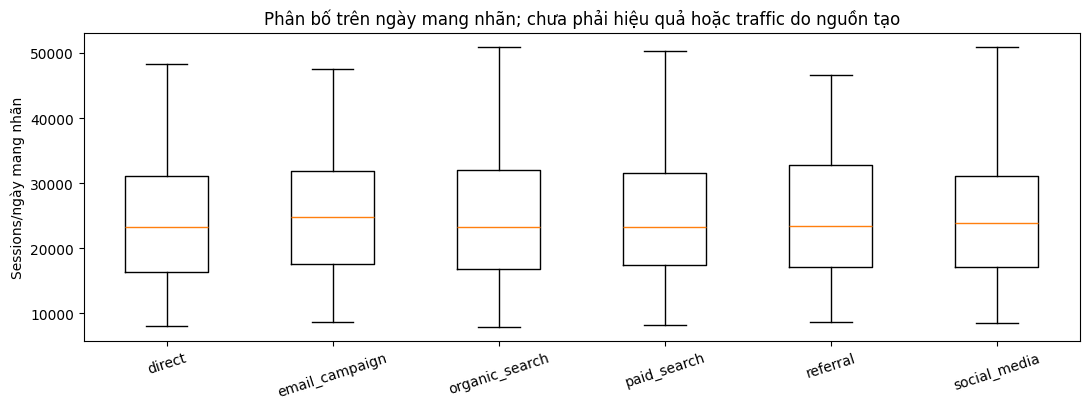

**Nhận xét.** organic_search xuất hiện trên 1,090/3,652 ngày; email_campaign có mean sessions cao nhất trên ngày mang nhãn (25332.02). Có 328 tổ hợp tháng–nhãn dưới 5 ngày. Phân bố theo năm và thứ là yếu tố có thể làm các mean khác nhau; chưa kiểm soát nhiễu, không gọi nhãn nào hiệu quả nhất. Cần quy tắc gán nhãn và số đo riêng từng nguồn/ngày.

In [37]:
source63=web_summary63(w63,'traffic_source')
source63['Tỷ trọng ngày/tất cả ngày (%)']=100*source63.days/len(w63)
show(web_view63(source63),'Sessions/page_views/UV-ngày trên những ngày mang từng nhãn; không quy nguồn tạo traffic')
source_year63=web_summary63(w63,['_year','traffic_source'])
source_year63['Mẫu số: ngày web trong năm']=source_year63._year.map(w63.groupby('_year').size())
source_year63['Tỷ trọng ngày trong năm (%)']=100*source_year63.days/source_year63['Mẫu số: ngày web trong năm']
show(web_view63(source_year63[['_year','traffic_source','days','Mẫu số: ngày web trong năm','Tỷ trọng ngày trong năm (%)','sessions_mean','pv_mean','bounce_mean','duration_mean']]),'Cơ cấu nhãn theo năm và mean của các ngày mang nhãn')
source_weekday63=pd.crosstab(w63.traffic_source,w63._weekday).rename(columns=weekday_names63)
show(source_weekday63.reset_index(),'Số ngày mang từng nhãn theo thứ: không phải số phiên theo nguồn')
source_month63=w63.groupby(['_month','traffic_source']).agg(Ngày=('_date','size'),Mean_sessions=('sessions','mean')).reset_index()
# Bảng tần suất: ô không có tổ hợp được hiển thị 0 là số đếm tổ hợp, không thay NULL nguồn.
source_month_matrix63=pd.crosstab(w63._month,w63.traffic_source)
show(source_month_matrix63.reset_index(),'Tần suất nhãn theo tháng, 120 tháng × các nhãn, đơn vị ngày')
small_source_month63=source_month63.loc[source_month63.Ngày.lt(5)].sort_values(['Ngày','_month','traffic_source'])
show(small_source_month63.head(15),'15 nhóm tháng–nhãn ít ngày nhất trong tập dưới 5; không suy mean ổn định')
source_delta63=source_year63.pivot(index='_year',columns='traffic_source',values='Tỷ trọng ngày trong năm (%)')
show(pd.DataFrame({'Nhãn':source_delta63.columns,'Tỷ trọng ngày năm đầu (%)':source_delta63.iloc[0].values,'Tỷ trọng ngày năm cuối (%)':source_delta63.iloc[-1].values,'Chênh cuối–đầu (điểm %)':source_delta63.iloc[-1].values-source_delta63.iloc[0].values}),'Đổi cơ cấu ngày được gắn nhãn, chưa là thị phần marketing')
ck63('Nhãn ngày bảo toàn số ngày và số lượng',int(source63.days.sum())==len(w63) and int(source63.sessions_total.sum())==web_totals63['sessions'] and int(source63.pv_total.sum())==web_totals63['page_views'])
ck63('Tỷ trọng ngày đúng mẫu số',abs(source63['Tỷ trọng ngày/tất cả ngày (%)'].sum()-100)<1e-9)
ck63('Cơ cấu nhãn năm đúng mẫu số',np.allclose(source_year63.groupby('_year')['Tỷ trọng ngày trong năm (%)'].sum(),100))
ck63('Tần suất nhãn tháng/thứ bảo toàn ngày',int(source_month63.Ngày.sum())==len(w63) and int(source_weekday63.to_numpy().sum())==len(w63) and int(source_month_matrix63.to_numpy().sum())==len(w63))
fig,ax=plt.subplots(figsize=(11,4.2))
source_order63=source63.sort_values('traffic_source').traffic_source.tolist()
ax.boxplot([w63.loc[w63.traffic_source.eq(s),'sessions'].to_numpy(dtype=float) for s in source_order63],tick_labels=source_order63,showfliers=True)
ax.set(ylabel='Sessions/ngày mang nhãn',title='Phân bố trên ngày mang nhãn; chưa phải hiệu quả hoặc traffic do nguồn tạo')
ax.tick_params(axis='x',rotation=18);figdone(fig)
source_leader63=source63.sort_values('days',ascending=False).iloc[0]
source_high_mean63=source63.sort_values('sessions_mean',ascending=False).iloc[0]
note(f"**Nhận xét.** {source_leader63.traffic_source} xuất hiện trên {source_leader63.days:,}/{len(w63):,} ngày; {source_high_mean63.traffic_source} có mean sessions cao nhất trên ngày mang nhãn ({source_high_mean63.sessions_mean:.2f}). Có {len(small_source_month63)} tổ hợp tháng–nhãn dưới 5 ngày. Phân bố theo năm và thứ là yếu tố có thể làm các mean khác nhau; chưa kiểm soát nhiễu, không gọi nhãn nào hiệu quả nhất. Cần quy tắc gán nhãn và số đo riêng từng nguồn/ngày.")

### NV06.3.11 — Tỷ số số học, bounce_rate và thời lượng nguồn
Tỷ số theo ngày chỉ tính khi tử/mẫu hữu hạn và mẫu >0. Không gọi sessions/unique_visitors là tần suất thật của một người khi chưa biết định nghĩa người. Phân biệt **mean tỷ số ngày** và **tổng tử/tổng mẫu trên cùng tập ngày hợp lệ**; không cộng tỷ lệ ngày thành tỷ lệ tháng/năm.

bounce_rate không được đổi thang, không nhân sessions để suy số phiên thoát. avg_session_duration_sec giữ số nguồn: chưa xác minh đơn vị chính thức hoặc cách gia quyền khi tổng hợp. Chỉ báo mean của các số ngày không mặc định là trung bình gia quyền theo phiên của cả kỳ.

In [38]:
ratio_specs63=[('page_views/sessions','page_views','sessions'),('sessions/unique_visitors','sessions','unique_visitors'),('page_views/unique_visitors','page_views','unique_visitors')]
ratio_valid63={}
for name,num,den in ratio_specs63:
    valid=np.isfinite(w63[num].fillna(np.nan))&np.isfinite(w63[den].fillna(np.nan))&w63[den].gt(0)
    ratio_valid63[name]=valid
    with np.errstate(divide='ignore',invalid='ignore'):w63[name]=(w63[num]/w63[den]).where(valid)
def ratio_table63(d,key=None):
    records=[]
    groups=[('Toàn bộ web',d)] if key is None else d.groupby(key,dropna=False)
    for group,g in groups:
        for name,num,den in ratio_specs63:
            valid=np.isfinite(g[name].fillna(np.nan))
            s=g.loc[valid,name];n=g.loc[valid,num];dd=g.loc[valid,den]
            records.append({'Nhóm':str(group),'Tỷ số số học từ số ghi nhận':name,'Tử số':num,'Mẫu số':den,'Mọi ngày nhóm':len(g),'Ngày hợp lệ':len(s),'Ngày không tính':len(g)-len(s),'Mean tỷ số ngày':s.mean(),'Median tỷ số ngày':s.median(),'Min':s.min(),'Max':s.max(),'P25':s.quantile(.25),'P75':s.quantile(.75),'P95':s.quantile(.95),'Tổng tử trên ngày hợp lệ':n.sum(),'Tổng mẫu trên ngày hợp lệ':dd.sum(),'Tổng tử/tổng mẫu':n.sum()/dd.sum() if dd.sum()>0 else np.nan})
    return pd.DataFrame(records)
ratios_global63=ratio_table63(w63)
ratios_year63=ratio_table63(w63,'_year')
ratios_source63=ratio_table63(w63,'traffic_source')
show(ratios_global63,'Tỷ số nguồn theo ngày, không diễn giải như conversion/hành vi đã xác minh')
show(ratios_year63,'Mean tỷ số ngày và tỷ số tổng theo năm, cùng tập quan sát hợp lệ')
show(ratios_source63,'Tỷ số trên ngày mang nhãn, không tự gán traffic cho nguồn')
duration_year63=w63.groupby('_year').agg(Quan_sát=(duration_field63,'count'),Min=(duration_field63,'min'),Max=(duration_field63,'max'),Mean=(duration_field63,'mean'),Median=(duration_field63,'median'),P90=(duration_field63,lambda s:s.quantile(.9)),Bounce_min=('bounce_rate','min'),Bounce_max=('bounce_rate','max'),Bounce_P25=('bounce_rate',lambda s:s.quantile(.25)),Bounce_P75=('bounce_rate',lambda s:s.quantile(.75))).reset_index()
show(duration_year63.assign(_year=lambda d:d._year.astype(str)),'Phân bố thời lượng và bounce theo năm: giữ số nguồn, chưa xác minh đơn vị')
for name,num,den in ratio_specs63:
    valid=ratio_valid63[name]
    ck63('Tỷ số '+name+': chỉ mẫu hợp lệ',w63.loc[~valid,name].isna().all() and np.isfinite(w63.loc[valid,name]).all() and w63.loc[valid,den].gt(0).all())
    ck63('Tỷ số '+name+': khớp phép chia nguồn',np.allclose(w63.loc[valid,name].to_numpy(dtype=float),w63.loc[valid,num].to_numpy(dtype=float)/w63.loc[valid,den].to_numpy(dtype=float)))
ck63('bounce không đổi thang: đối chiếu Decimal từng nguồn',all(Decimal(s)==Decimal(str(float(v))) for s,v in zip(wraw63.bounce_rate,w63.bounce_rate)))
ck63('Thời lượng không đổi đơn vị: đối chiếu Decimal',all(Decimal(s)==Decimal(str(float(v))) for s,v in zip(wraw63[duration_field63],w63[duration_field63])))
ck63('bounce mean khớp V07',abs(float(w63.bounce_rate.mean())-reports['v07']['metrics']['bounce_mean'])<1e-12)
ratio_pages63=ratios_global63.iloc[0]
note(f"**Nhận xét.** page_views/sessions có mean ngày {ratio_pages63['Mean tỷ số ngày']:.6f}, còn tổng page_views/tổng sessions là {ratio_pages63['Tổng tử/tổng mẫu']:.6f}; hai cách dùng trọng số khác nhau. Bounce mean nguồn {w63.bounce_rate.mean():.10f}, thời lượng mean nguồn {w63[duration_field63].mean():.6f}; chưa xác minh thang đo/công thức của cả hai. Cần từ điển chỉ báo và quy tắc tổng hợp, không suy số phiên thoát hoặc tần suất thật từng người.")

**Tỷ số nguồn theo ngày, không diễn giải như conversion/hành vi đã xác minh**

Nhóm,Tỷ số số học từ số ghi nhận,Tử số,Mẫu số,Mọi ngày nhóm,Ngày hợp lệ,Ngày không tính,Mean tỷ số ngày,Median tỷ số ngày,Min,Max,P25,P75,P95,Tổng tử trên ngày hợp lệ,Tổng mẫu trên ngày hợp lệ,Tổng tử/tổng mẫu
Toàn bộ web,page_views/sessions,page_views,sessions,3.652,3.652,0,"4,336151","4,340644","3,200083","5,499946","3,775489","4,898958","5,358473",396.662.800,91.452.537,"4,337362"
Toàn bộ web,sessions/unique_visitors,sessions,unique_visitors,3.652,3.652,0,"1,318666","1,316992","1,21968","1,428598","1,267136","1,367591","1,415756",91.452.537,69.502.689,"1,315813"
Toàn bộ web,page_views/unique_visitors,page_views,unique_visitors,3.652,3.652,0,"5,71842","5,693434","3,925324","7,822767","4,956216","6,460178","7,194223",396.662.800,69.502.689,"5,707158"


**Mean tỷ số ngày và tỷ số tổng theo năm, cùng tập quan sát hợp lệ**

Nhóm,Tỷ số số học từ số ghi nhận,Tử số,Mẫu số,Mọi ngày nhóm,Ngày hợp lệ,Ngày không tính,Mean tỷ số ngày,Median tỷ số ngày,Min,Max,P25,P75,P95,Tổng tử trên ngày hợp lệ,Tổng mẫu trên ngày hợp lệ,Tổng tử/tổng mẫu
2013,page_views/sessions,page_views,sessions,365,365,0,"4,322209","4,30158","3,205174","5,492041","3,766354","4,8824","5,394248",29.403.658,6.801.940,"4,322834"
2013,sessions/unique_visitors,sessions,unique_visitors,365,365,0,"1,318666","1,314393","1,219963","1,427682","1,267609","1,370213","1,41671",6.801.940,5.166.501,"1,316547"
2013,page_views/unique_visitors,page_views,unique_visitors,365,365,0,"5,696776","5,660698","4,042782","7,770445","4,90897","6,426811","7,156239",29.403.658,5.166.501,"5,691213"
2014,page_views/sessions,page_views,sessions,365,365,0,"4,347683","4,346497","3,218521","5,499946","3,790809","4,874918","5,357903",31.947.207,7.340.960,"4,351911"
2014,sessions/unique_visitors,sessions,unique_visitors,365,365,0,"1,314503","1,313754","1,221326","1,428598","1,261299","1,36371","1,417111",7.340.960,5.596.248,"1,311765"
2014,page_views/unique_visitors,page_views,unique_visitors,365,365,0,"5,715366","5,709844","3,973453","7,680756","4,96702","6,416124","7,219786",31.947.207,5.596.248,"5,708683"
2015,page_views/sessions,page_views,sessions,365,365,0,"4,33954","4,402748","3,201041","5,497603","3,7663","4,905824","5,32499",34.175.895,7.861.938,"4,347006"
2015,sessions/unique_visitors,sessions,unique_visitors,365,365,0,"1,319546","1,318052","1,219722","1,42779","1,266386","1,36719","1,416161",7.861.938,5.962.192,"1,318632"
2015,page_views/unique_visitors,page_views,unique_visitors,365,365,0,"5,728981","5,721986","3,937669","7,664121","4,95226","6,498236","7,247455",34.175.895,5.962.192,"5,732102"
2016,page_views/sessions,page_views,sessions,366,366,0,"4,315094","4,297886","3,200565","5,490992","3,756094","4,887767","5,332165",36.322.275,8.403.399,"4,322331"


**Tỷ số trên ngày mang nhãn, không tự gán traffic cho nguồn**

Nhóm,Tỷ số số học từ số ghi nhận,Tử số,Mẫu số,Mọi ngày nhóm,Ngày hợp lệ,Ngày không tính,Mean tỷ số ngày,Median tỷ số ngày,Min,Max,P25,P75,P95,Tổng tử trên ngày hợp lệ,Tổng mẫu trên ngày hợp lệ,Tổng tử/tổng mẫu
direct,page_views/sessions,page_views,sessions,266,266,0,"4,413643","4,471377","3,205174","5,48836","3,855114","4,927745","5,381167",28.771.362,6.571.549,"4,378171"
direct,sessions/unique_visitors,sessions,unique_visitors,266,266,0,"1,319133","1,312574","1,220257","1,426867","1,268923","1,368822","1,413512",6.571.549,4.986.650,"1,317828"
direct,page_views/unique_visitors,page_views,unique_visitors,266,266,0,"5,824556","5,855938","4,042782","7,777045","5,056972","6,550186","7,279904",28.771.362,4.986.650,"5,769677"
email_campaign,page_views/sessions,page_views,sessions,505,505,0,"4,320679","4,249986","3,20033","5,490924","3,814249","4,89755","5,362371",55.477.636,12.792.670,"4,336674"
email_campaign,sessions/unique_visitors,sessions,unique_visitors,505,505,0,"1,321393","1,323734","1,21995","1,427706","1,271025","1,37414","1,416128",12.792.670,9.700.462,"1,318769"
email_campaign,page_views/unique_visitors,page_views,unique_visitors,505,505,0,"5,708907","5,621071","3,937669","7,778015","4,983128","6,410328","7,208052",55.477.636,9.700.462,"5,719072"
organic_search,page_views/sessions,page_views,sessions,1.090,1.090,0,"4,323706","4,325247","3,201068","5,499946","3,76686","4,881005","5,362533",117.606.452,27.196.976,"4,324247"
organic_search,sessions/unique_visitors,sessions,unique_visitors,1.090,1.090,0,"1,321596","1,320885","1,219722","1,428146","1,269012","1,371414","1,416518",27.196.976,20.625.107,"1,318634"
organic_search,page_views/unique_visitors,page_views,unique_visitors,1.090,1.090,0,"5,713995","5,714485","3,975587","7,770445","4,965336","6,437635","7,167209",117.606.452,20.625.107,"5,702101"
paid_search,page_views/sessions,page_views,sessions,784,784,0,"4,32909","4,344375","3,200083","5,495342","3,759469","4,88471","5,36133",85.079.551,19.598.271,"4,341176"


**Phân bố thời lượng và bounce theo năm: giữ số nguồn, chưa xác minh đơn vị**

_year,Quan_sát,Min,Max,Mean,Median,P90,Bounce_min,Bounce_max,Bounce_P25,Bounce_P75
2013,365,"101,7","319,7","206,941644","200,9","301,3","0,00321","0,0058","0,00397","0,00518"
2014,365,"100,4","319,9","212,567671","214,3","299,46","0,00322","0,0058","0,00375","0,00514"
2015,365,"101,7","319,2","216,365479","220,5","301,66","0,00321","0,00575","0,00378","0,00508"
2016,366,"100,2","319,8","205,377049","197,9","296,65","0,0032","0,00579","0,00377","0,005075"
2017,365,"100,2","319,4","209,265205","210,6","295,72","0,0032","0,0058","0,00386","0,00519"
2018,365,"100,7","319,7","208,406027","209,3","295,44","0,0032","0,00577","0,00385","0,00521"
2019,365,"100,1","319,8","207,552329","206,2","296,96","0,00321","0,00579","0,00385","0,0052"
2020,366,"100,2","319,1","213,418033","203,6","297,8","0,0032","0,00578","0,003892","0,00526"
2021,365,"100,1","319,8","210,011507","209,8","301,34","0,00321","0,0058","0,00384","0,00504"
2022,365,"100,2","319,3","212,932329","216,6","295,72","0,0032","0,0058","0,00386","0,00515"


**Nhận xét.** page_views/sessions có mean ngày 4.336151, còn tổng page_views/tổng sessions là 4.337362; hai cách dùng trọng số khác nhau. Bounce mean nguồn 0.0044872919, thời lượng mean nguồn 210.283242; chưa xác minh thang đo/công thức của cả hai. Cần từ điển chỉ báo và quy tắc tổng hợp, không suy số phiên thoát hoặc tần suất thật từng người.

### NV06.3.12 — Liên hệ mô tả giữa số đo web
Pearson trên các cặp số hữu hạn; Spearman là Pearson của hạng trung bình trên **chính cùng tập cặp hợp lệ**, không cần thêm thư viện. Không bỏ cực trị. Báo số ngày, khoảng ngày và chênh hệ số; tương quan theo năm giúp nhận diện khả năng trộn xu hướng thời gian, chưa là kiểm soát nhân quả.

Tỷ số được tạo từ chính biến gốc có liên hệ toán học: tương quan sessions với page_views/sessions không là bằng chứng độc lập xác minh công thức hoặc hành vi. Không dùng tương quan để quy đơn, doanh thu hoặc khách trung thành cho traffic.

**Tương quan trên cùng tập ngày, không có phép kiểm định tác động**

A,B,Ngày hợp lệ chung,Không tính,Từ,Đến,Pearson,Spearman,|Pearson−Spearman|,Giới hạn
sessions,page_views,3.652,0,2013-01-01,2022-12-31,"0,919589","0,931293","0,011704",Tương quan mô tả; có thể trộn xu hướng thời gian
sessions,unique_visitors,3.652,0,2013-01-01,2022-12-31,"0,992026","0,993489","0,001463",Tương quan mô tả; có thể trộn xu hướng thời gian
page_views,unique_visitors,3.652,0,2013-01-01,2022-12-31,"0,911411","0,924963","0,013552",Tương quan mô tả; có thể trộn xu hướng thời gian
sessions,page_views/sessions,3.652,0,2013-01-01,2022-12-31,"0,004891","0,007145","0,002255","Tỷ số chứa biến gốc, không độc lập"
bounce_rate,sessions,3.652,0,2013-01-01,2022-12-31,"-0,004614","-0,005497","0,000883",Tương quan mô tả; có thể trộn xu hướng thời gian
bounce_rate,page_views,3.652,0,2013-01-01,2022-12-31,"0,010369","0,009806","0,000563",Tương quan mô tả; có thể trộn xu hướng thời gian
avg_session_duration_sec,sessions,3.652,0,2013-01-01,2022-12-31,"-0,022047","-0,018774","0,003273",Tương quan mô tả; có thể trộn xu hướng thời gian
avg_session_duration_sec,page_views,3.652,0,2013-01-01,2022-12-31,"-0,022882","-0,017868","0,005014",Tương quan mô tả; có thể trộn xu hướng thời gian
avg_session_duration_sec,bounce_rate,3.652,0,2013-01-01,2022-12-31,"0,00657","0,006526","0,000043",Tương quan mô tả; có thể trộn xu hướng thời gian
avg_session_duration_sec,page_views/sessions,3.652,0,2013-01-01,2022-12-31,"-0,002331","-0,002489","0,000158","Tỷ số chứa biến gốc, không độc lập"


**Hệ số trong từng năm: khác hệ số gộp không chứng minh nguyên nhân**

Năm,A,B,Ngày,Pearson,Spearman
2013,sessions,page_views,365,"0,89562","0,91278"
2013,sessions,unique_visitors,365,"0,98988","0,989948"
2013,bounce_rate,sessions,365,"0,045569","0,039526"
2014,sessions,page_views,365,"0,913772","0,923451"
2014,sessions,unique_visitors,365,"0,989759","0,988902"
2014,bounce_rate,sessions,365,"0,040988","0,042275"
2015,sessions,page_views,365,"0,899018","0,906919"
2015,sessions,unique_visitors,365,"0,988909","0,989394"
2015,bounce_rate,sessions,365,"0,00302","0,006501"
2016,sessions,page_views,366,"0,909603","0,915845"


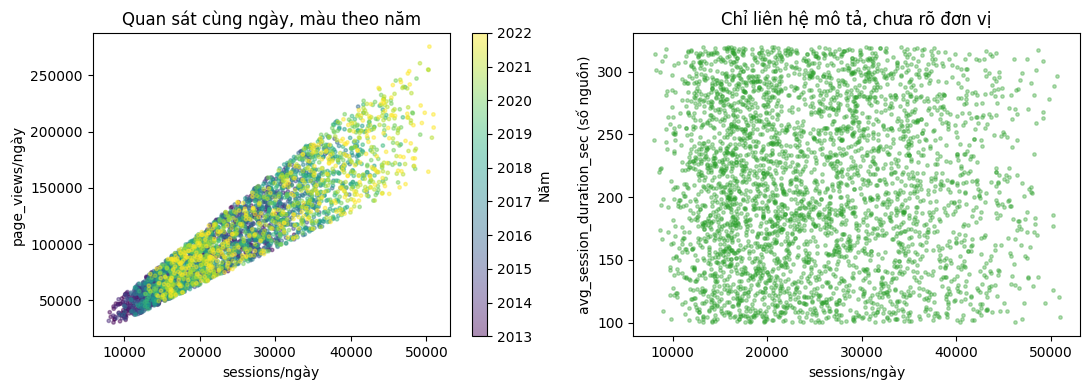

**Nhận xét.** Sessions/page_views có Pearson 0.919589, Spearman 0.931293, dùng 3,652 ngày. Bảng theo năm và chênh Pearson/Spearman cho thấy phạm vi mô tả cần xem cùng cực trị và thời gian; không suy traffic làm tăng đơn hoặc doanh thu. Cần định nghĩa chỉ báo và thiết kế đối chứng trước câu hỏi tác động.

In [39]:
corr_pairs63=[('sessions','page_views'),('sessions','unique_visitors'),('page_views','unique_visitors'),('sessions','page_views/sessions'),('bounce_rate','sessions'),('bounce_rate','page_views'),(duration_field63,'sessions'),(duration_field63,'page_views'),(duration_field63,'bounce_rate'),(duration_field63,'page_views/sessions')]
def corr_pair63(d,a,b):
    mask=np.isfinite(d[a].fillna(np.nan))&np.isfinite(d[b].fillna(np.nan))
    pairs=d.loc[mask,[a,b]].astype(float)
    if len(pairs)<2 or pairs[a].nunique()<2 or pairs[b].nunique()<2:return len(pairs),np.nan,np.nan,mask
    return len(pairs),pairs[a].corr(pairs[b]),pairs[a].rank(method='average').corr(pairs[b].rank(method='average')),mask
corr_records63=[]
for a,b in corr_pairs63:
    n,pear,spear,mask=corr_pair63(w63,a,b)
    corr_records63.append({'A':a,'B':b,'Ngày hợp lệ chung':n,'Không tính':len(w63)-n,'Từ':str(w63.loc[mask,'_date'].min().date()),'Đến':str(w63.loc[mask,'_date'].max().date()),'Pearson':pear,'Spearman':spear,'|Pearson−Spearman|':abs(pear-spear),'Giới hạn':'Tỷ số chứa biến gốc, không độc lập' if '/' in a or '/' in b else 'Tương quan mô tả; có thể trộn xu hướng thời gian'})
corr63=pd.DataFrame(corr_records63)
show(corr63,'Tương quan trên cùng tập ngày, không có phép kiểm định tác động')
corr_year63=[]
for year,g in w63.groupby('_year'):
    for a,b in [('sessions','page_views'),('sessions','unique_visitors'),('bounce_rate','sessions')]:
        n,p,s,_=corr_pair63(g,a,b)
        corr_year63.append({'Năm':str(year),'A':a,'B':b,'Ngày':n,'Pearson':p,'Spearman':s})
show(corr_year63,'Hệ số trong từng năm: khác hệ số gộp không chứng minh nguyên nhân')
for record in corr_records63:
    a,b=record['A'],record['B'];valid=np.isfinite(w63[a].fillna(np.nan))&np.isfinite(w63[b].fillna(np.nan))
    ck63('Tương quan cùng cặp hữu hạn: '+a+' / '+b,record['Ngày hợp lệ chung']==int(valid.sum()))
ck63('Tương quan giữ toàn bộ dòng, không loại IQR',len(w63)==len(wraw63))
fig,axs=plt.subplots(1,2,figsize=(11,4))
dots=axs[0].scatter(w63.sessions,w63.page_views,c=w63._year,s=6,alpha=.45,cmap='viridis')
axs[0].set(xlabel='sessions/ngày',ylabel='page_views/ngày',title='Quan sát cùng ngày, màu theo năm')
fig.colorbar(dots,ax=axs[0],label='Năm')
axs[1].scatter(w63.sessions,w63[duration_field63],s=6,alpha=.35,color='tab:green')
axs[1].set(xlabel='sessions/ngày',ylabel=duration_field63+' (số nguồn)',title='Chỉ liên hệ mô tả, chưa rõ đơn vị');figdone(fig)
note(f"**Nhận xét.** Sessions/page_views có Pearson {corr63.iloc[0].Pearson:.6f}, Spearman {corr63.iloc[0].Spearman:.6f}, dùng {int(corr63.iloc[0]['Ngày hợp lệ chung']):,} ngày. Bảng theo năm và chênh Pearson/Spearman cho thấy phạm vi mô tả cần xem cùng cực trị và thời gian; không suy traffic làm tăng đơn hoặc doanh thu. Cần định nghĩa chỉ báo và thiết kế đối chứng trước câu hỏi tác động.")

### NV06.3.13–15 — Ba loại kênh, ranh giới JOIN và thuật ngữ
Giống chuỗi (**A**) chưa chứng minh ánh xạ ngữ nghĩa (**B**), chung hệ theo dõi (**C**), có khóa sự kiện (**D**) hoặc có attribution (**E**). Không tự đi từ A sang B/C/D/E, kể cả cùng tên social_media.

Không mapping email_campaign↔email, organic_search↔search hoặc direct↔all_channels. Những nhãn chỉ có ở một nguồn được giữ nguyên. customers–orders có khóa ID; web không có ID khách/đơn/phiên, nên chỉ được nêu khả năng đối chiếu lịch tổng hợp cho NV06.4. **NV06.3 chưa JOIN traffic vào đơn/khách hoặc so doanh thu–traffic theo ngày.**

In [40]:
channel_compare63=[
{'Nguồn/trường':'customers.acquisition_channel','Cấp':'Hồ sơ khách','Giá trị nguyên gốc':', '.join(sorted(c63.acquisition_channel.dropna().unique())),'Từ':str(c63._signup.min().date()),'Đến':str(c63._signup.max().date()),'Quan sát':len(c63),'Số lượng/tỷ lệ hợp lệ':'Khách, tỷ trọng khách; khách có đơn trong dữ liệu','Liên kết':'customer_id tới orders; nhãn hồi cứu','Giới hạn':'Nhiều đơn trước signup; chưa biết thời điểm gán kênh','Cần xác minh':'First/last touch, lịch sử nhãn, nguồn gốc signup'},
{'Nguồn/trường':'web_traffic.traffic_source','Cấp':'Ngày có một nhãn','Giá trị nguyên gốc':', '.join(sorted(wraw63.traffic_source.dropna().unique())),'Từ':str(w63._date.min().date()),'Đến':str(w63._date.max().date()),'Quan sát':len(w63),'Số lượng/tỷ lệ hợp lệ':'Ngày mang nhãn, số đo trên ngày mang nhãn','Liên kết':'Không có customer_id/order_id/session_id','Giới hạn':'Chưa phân rã số đo thật theo từng nguồn','Cần xác minh':'Quy tắc nhãn, event ID và nguồn riêng từng ngày'},
{'Nguồn/trường':'promotions.promo_channel','Cấp':'Mô tả chương trình','Giá trị nguyên gốc':', '.join(sorted(prom.promo_channel.dropna().unique())),'Từ':str(ps.min().date()),'Đến':str(pe.max().date()),'Quan sát':len(prom),'Số lượng/tỷ lệ hợp lệ':'Số/tỷ trọng mô tả chương trình','Liên kết':'promo_id tới dòng hàng; không có cầu nối web','Giới hạn':'all_channels chưa chứng minh mọi khách được tiếp xúc','Cần xác minh':'Lịch phân phối/exposure và campaign ID'}]
show(channel_compare63,'So sánh ba nguồn, đơn vị và giới hạn khác nhau')
label_sets63={'acquisition':set(c63.acquisition_channel.dropna()),'traffic':set(wraw63.traffic_source.dropna()),'promo':set(prom.promo_channel.dropna())}
show([{'Nguồn A':a,'Nguồn B':b,'Chuỗi trùng (chỉ mức A)':', '.join(sorted(label_sets63[a]&label_sets63[b])),'Chỉ A':', '.join(sorted(label_sets63[a]-label_sets63[b])),'Chỉ B':', '.join(sorted(label_sets63[b]-label_sets63[a])),'B/C/D/E được chứng minh?':'Chưa'} for a,b in itertools.combinations(label_sets63,2)],'Tập nhãn không tạo mapping hoặc cầu nối')
show([{'Quan hệ':'customers → orders','Khóa':'customer_id','Kết quả':f'{len(o63)} đơn; {len(orphan_orders63)} mồ côi; bảo toàn tiền','Có thể':'Phân nhóm hồi cứu theo hồ sơ','Chưa thể':'Quy kênh tạo từng đơn'},
{'Quan hệ':'web → customers','Khóa':'Không có ID chung cấp sự kiện','Kết quả':'Không thực hiện JOIN','Có thể':'Mô tả độc lập','Chưa thể':'Nhận diện người truy cập là khách'},
{'Quan hệ':'web → orders','Khóa':'Không có order/session/event bridge','Kết quả':'Không thực hiện JOIN hoặc đối chiếu tiền theo ngày','Có thể':'NV06.4: chỉ cân nhắc so tổng hợp cùng lịch','Chưa thể':'Trùng ngày không chứng minh truy cập dẫn tới đơn'}],'Ranh giới khóa, mẫu số và attribution')
terms63=[
['Khách có đơn / khách trong nhãn','Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát','Conversion rate chiến dịch'],
['Đơn thuộc khách acquisition=X','Đơn phân nhóm hồi cứu theo thuộc tính hồ sơ','Đơn do kênh X tạo ra'],
['Net đơn thuộc khách acquisition=X','Net số học theo nhãn hồ sơ','Doanh thu quy thuộc kênh X/thực thu/lợi nhuận'],
['Sessions trên ngày traffic_source=X','Sessions ghi nhận trên những ngày mang nhãn X','Sessions chắc chắn do nguồn X tạo ra'],
['Σ unique_visitors ngày','Tổng lượt khách phân biệt ghi nhận từng ngày','Số người duy nhất toàn tháng/năm'],
['Mean bounce_rate nguồn','Trung bình số nguồn, chưa rõ thang','Bounce rate chính thức hoặc số phiên thoát'],
['Traffic/đơn cùng tăng','Đối chiếu mô tả nếu thực hiện ở bước sau','Traffic gây tăng doanh thu'],
['Số signup năm','Số hồ sơ có ngày signup trong năm','Conversion từ web'],
['Mean avg_session_duration_sec','Mean chỉ báo số nguồn chưa rõ cách tổng hợp','Thời lượng chính thức đã xác minh đơn vị']]
show(pd.DataFrame(terms63,columns=['Phép đo','Tên sử dụng','Không được gọi sai thành']),'Kiểm soát thuật ngữ')
ck63('Web thực tế thiếu khóa khách/đơn/phiên',not any(k in wraw63 for k in ['customer_id','order_id','session_id','user_id','visitor_id']))
ck63('Không đổi nhãn trong ba nguồn',c63.acquisition_channel.equals(customers.acquisition_channel) and wraw63.traffic_source.equals(web.traffic_source))
ck63('Từ vựng acquisition/traffic chỉ đối chiếu set V08',(label_sets63['acquisition']==label_sets63['traffic'])==reports['v08']['metrics']['label_sets_equal'])
note("**Nhận xét.** Có quan hệ khóa thật giữa khách–đơn, còn các tập nhãn chỉ chứng minh trùng từ vựng. Thiếu cầu nối sự kiện, quy tắc attribution, exposure và chi phí nên chưa đo conversion/CAC/ROI/ROAS. Cần thống nhất định nghĩa và phạm vi trước NV06.4; mọi so theo lịch sau này vẫn chưa xác minh trùng người hoặc tác động.")

**So sánh ba nguồn, đơn vị và giới hạn khác nhau**

Nguồn/trường,Cấp,Giá trị nguyên gốc,Từ,Đến,Quan sát,Số lượng/tỷ lệ hợp lệ,Liên kết,Giới hạn,Cần xác minh
customers.acquisition_channel,Hồ sơ khách,"direct, email_campaign, organic_search, paid_search, referral, social_media",2012-01-17,2022-12-31,121.930,"Khách, tỷ trọng khách; khách có đơn trong dữ liệu",customer_id tới orders; nhãn hồi cứu,Nhiều đơn trước signup; chưa biết thời điểm gán kênh,"First/last touch, lịch sử nhãn, nguồn gốc signup"
web_traffic.traffic_source,Ngày có một nhãn,"direct, email_campaign, organic_search, paid_search, referral, social_media",2013-01-01,2022-12-31,3.652,"Ngày mang nhãn, số đo trên ngày mang nhãn",Không có customer_id/order_id/session_id,Chưa phân rã số đo thật theo từng nguồn,"Quy tắc nhãn, event ID và nguồn riêng từng ngày"
promotions.promo_channel,Mô tả chương trình,"all_channels, email, in_store, online, social_media",2013-01-31,2022-12-31,50,Số/tỷ trọng mô tả chương trình,promo_id tới dòng hàng; không có cầu nối web,all_channels chưa chứng minh mọi khách được tiếp xúc,Lịch phân phối/exposure và campaign ID


**Tập nhãn không tạo mapping hoặc cầu nối**

Nguồn A,Nguồn B,Chuỗi trùng (chỉ mức A),Chỉ A,Chỉ B,B/C/D/E được chứng minh?
acquisition,traffic,"direct, email_campaign, organic_search, paid_search, referral, social_media",,,Chưa
acquisition,promo,social_media,"direct, email_campaign, organic_search, paid_search, referral","all_channels, email, in_store, online",Chưa
traffic,promo,social_media,"direct, email_campaign, organic_search, paid_search, referral","all_channels, email, in_store, online",Chưa


**Ranh giới khóa, mẫu số và attribution**

Quan hệ,Khóa,Kết quả,Có thể,Chưa thể
customers → orders,customer_id,646945 đơn; 0 mồ côi; bảo toàn tiền,Phân nhóm hồi cứu theo hồ sơ,Quy kênh tạo từng đơn
web → customers,Không có ID chung cấp sự kiện,Không thực hiện JOIN,Mô tả độc lập,Nhận diện người truy cập là khách
web → orders,Không có order/session/event bridge,Không thực hiện JOIN hoặc đối chiếu tiền theo ngày,NV06.4: chỉ cân nhắc so tổng hợp cùng lịch,Trùng ngày không chứng minh truy cập dẫn tới đơn


**Kiểm soát thuật ngữ**

Phép đo,Tên sử dụng,Không được gọi sai thành
Khách có đơn / khách trong nhãn,Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát,Conversion rate chiến dịch
Đơn thuộc khách acquisition=X,Đơn phân nhóm hồi cứu theo thuộc tính hồ sơ,Đơn do kênh X tạo ra
Net đơn thuộc khách acquisition=X,Net số học theo nhãn hồ sơ,Doanh thu quy thuộc kênh X/thực thu/lợi nhuận
Sessions trên ngày traffic_source=X,Sessions ghi nhận trên những ngày mang nhãn X,Sessions chắc chắn do nguồn X tạo ra
Σ unique_visitors ngày,Tổng lượt khách phân biệt ghi nhận từng ngày,Số người duy nhất toàn tháng/năm
Mean bounce_rate nguồn,"Trung bình số nguồn, chưa rõ thang",Bounce rate chính thức hoặc số phiên thoát
Traffic/đơn cùng tăng,Đối chiếu mô tả nếu thực hiện ở bước sau,Traffic gây tăng doanh thu
Số signup năm,Số hồ sơ có ngày signup trong năm,Conversion từ web
Mean avg_session_duration_sec,Mean chỉ báo số nguồn chưa rõ cách tổng hợp,Thời lượng chính thức đã xác minh đơn vị


**Nhận xét.** Có quan hệ khóa thật giữa khách–đơn, còn các tập nhãn chỉ chứng minh trùng từ vựng. Thiếu cầu nối sự kiện, quy tắc attribution, exposure và chi phí nên chưa đo conversion/CAC/ROI/ROAS. Cần thống nhất định nghĩa và phạm vi trước NV06.4; mọi so theo lịch sau này vẫn chưa xác minh trùng người hoặc tác động.

### NV06.3.16 — Phát hiện và giới hạn nghiệp vụ
Mỗi phát hiện ghi nguồn, cấp quan sát và mẫu số. A chỉ dùng khi ràng buộc kỹ thuật đã xác minh bị vi phạm; B là hiện tượng cần hiểu rõ; C là thiếu dữ liệu/định nghĩa. Không biến khác biệt kênh, đơn trước signup hoặc cực trị thành lỗi khi chưa có quy tắc nghiệp vụ.

In [41]:
findings63=[]
def find63(code,kind,event,evidence,source,unit,denom,meaning,limit,nextq):
    findings63.append({'Mã':code,'Loại':kind,'Hiện tượng':event,'Bằng chứng':str(evidence),'Nguồn':source,'Đơn vị':unit,'Mẫu số':str(denom),'Ý nghĩa':meaning,'Giới hạn':limit,'Câu hỏi tiếp':nextq})
acq_order_leader63=channel_orders63.sort_values('orders',ascending=False).iloc[0]
find63('F63-01','B','Cơ cấu hồ sơ acquisition',f'{acq_leader63.acquisition_channel}: {acq_leader63.Khách} khách','customers','Khách',len(c63),'Nhãn có nhiều hồ sơ nhất','Không là hiệu quả thu hút hoặc market share','Nhãn được gán tại thời điểm nào?')
find63('F63-02','B','Cơ cấu và tổng signup thay đổi',f'Năm {int(signup_peak63._year)} cao nhất {signup_peak63.Khách}; {largest_delta63.acquisition_channel} đổi {largest_delta63["Chênh cuối–đầu (điểm %)"]:.2f} điểm %','customers.signup_date','Khách/năm','Mọi khách trong năm; khách riêng kênh tách riêng','Cần đọc số năm cùng tỷ trọng năm','Không quy chiến dịch; chưa biết signup là mốc nào','Cách ghi ngày signup có ổn định qua năm?')
find63('F63-03','B','Khách có đơn theo nhãn hồ sơ',f'{len(buyers_set63)} có đơn; {len(c63)-len(buyers_set63)} không; tỷ lệ nhãn {buyer_rate_range63["min"]:.2f}–{buyer_rate_range63["max"]:.2f}%','customers/orders','Khách','Khách trong từng nhãn','Hiện diện trong dữ liệu quan sát','Không conversion; thời gian quan sát khác nhau','Có lịch sử tài khoản và cửa sổ quan sát hợp lệ?')
find63('F63-04','B','Đơn phân nhóm hồi cứu theo acquisition',f'{acq_order_leader63.acquisition_channel}: {int(acq_order_leader63.orders)} đơn; Net {money63(acq_order_leader63._net_c)} ĐVT','orders/items/customers','Đơn/khách có đơn',len(o63),'Bảo toàn tiền cấp đơn trước JOIN','Không doanh thu do kênh tạo ra hoặc thực thu','Có timestamp gán kênh và bridge tiếp xúc–đơn?')
find63('F63-05','B','Ngày đặt trước signup',f'{len(before_signup63)} đơn ({len(before_signup63)/len(o63)*100:.2f}%); {before_signup63.customer_id.nunique()} khách','orders/customers; V01','Đơn/khách',len(o63),'Không dùng signup làm gốc hành trình mua','Chưa chứng minh lỗi ngày hoặc chuyển hệ thống','Nghĩa signup, nguồn gốc ngày và ổn định ID?')
find63('F63-06','B','Xu hướng số đo web',f'Σ sessions {web_totals63["sessions"]}; mean/ngày {web_first63.sessions_mean:.2f}→{web_last63.sessions_mean:.2f}','web_traffic','Ngày/kỳ',len(w63),'Tách tổng kỳ và mean/ngày; UV cộng theo ngày','Không người duy nhất cả kỳ; chưa kết luận chiến dịch','Công cụ/định nghĩa đo có thay đổi?')
find63('F63-07','B','Dấu hiệu tháng/thứ',f'Tháng {month_peak_counts63.index[0]} cao nhất ở {month_peak_counts63.iloc[0]} năm; {weekday_peak63["Thứ"]} mean {weekday_peak63.sessions_mean:.2f}','web_traffic.date','Ngày',len(w63),'Có mô tả mẫu lặp theo lịch','Chưa tách xu hướng dài hạn hoặc lịch kinh doanh','Mẫu có ổn định ngoài giai đoạn này?')
find63('F63-08','B','Nhãn ngày không đồng đều',f'{source_leader63.traffic_source}: {source_leader63.days} ngày; {len(small_source_month63)} nhóm tháng–nhãn dưới5 ngày','web_traffic.traffic_source','Ngày mang nhãn',len(w63),'Số ngày/năm/thứ có thể ảnh hưởng mean','Chưa là traffic do kênh tạo, thị phần hay hiệu quả','Quy tắc nhãn và phân rã nguồn/ngày?')
find63('F63-09','C','Chỉ báo nguồn chưa đủ định nghĩa',f'Bounce mean {w63.bounce_rate.mean():.10f}; {duration_field63} mean {w63[duration_field63].mean():.6f}','web_traffic','Ngày',len(w63),'Giữ nguyên số và thang; tỷ số chỉ là số học','Không tự % hóa bounce, suy phiên thoát hoặc đổi đơn vị thời lượng','Đơn vị, công thức và quy tắc gia quyền chính thức?')
find63('F63-10','C','Chưa có cầu nối sự kiện và attribution','Web không có customer_id/order_id/session_id; chưa có exposure/chi phí trong nguồn đang xét','Schema web và ba nguồn kênh','Sự kiện chưa có','Không áp dụng','Không tính conversion/CAC/ROI/ROAS hoặc gán nguồn','Trùng chuỗi/ngày không chứng minh trùng người','Cần bridge định danh, cửa sổ attribution, chi phí và quy tắc?')
show(findings63,'10 phát hiện có nguồn và mẫu số; không tự tạo A')
technical63={'Customer_id NULL/trùng':int(c63.customer_id.isna().sum()+c63.customer_id.duplicated().sum()),'Order_id NULL/trùng':int(orders.order_id.isna().sum()+orders.order_id.duplicated().sum()),'Đơn nhân thêm sau JOIN':abs(len(o63)-len(orders)),'Ngày web không hợp lệ':int(w63._date.isna().sum()),'Ngày web trùng vượt đầu':int(w63._date.duplicated().sum()),'Ngày web thiếu giữa hai đầu':len(pd.date_range(w63._date.min(),w63._date.max()).difference(pd.DatetimeIndex(w63._date)))}
show([{'Kiểm tra kỹ thuật':k,'Số':v,'Phân loại':'Không phát hiện A trong phép kiểm này' if v==0 else 'A — xem ràng buộc và truy vết'} for k,v in technical63.items()],'A chỉ theo ràng buộc kỹ thuật được kiểm tra, không áp cho mọi hiện tượng')
note("**Nhận xét.** Sổ ghi nhận khác biệt mô tả và các định nghĩa còn thiếu; các giới hạn không được chữa bằng mapping kênh, điền dữ liệu hoặc xóa cực trị. Cần ưu tiên nghĩa signup, lịch sử nhãn acquisition và định nghĩa nguồn web trước khi liên hệ với chương trình ở NV06.4.")

**10 phát hiện có nguồn và mẫu số; không tự tạo A**

Mã,Loại,Hiện tượng,Bằng chứng,Nguồn,Đơn vị,Mẫu số,Ý nghĩa,Giới hạn,Câu hỏi tiếp
F63-01,B,Cơ cấu hồ sơ acquisition,organic_search: 36450 khách,customers,Khách,121930,Nhãn có nhiều hồ sơ nhất,Không là hiệu quả thu hút hoặc market share,Nhãn được gán tại thời điểm nào?
F63-02,B,Cơ cấu và tổng signup thay đổi,Năm 2022 cao nhất 21103; social_media đổi -2.84 điểm %,customers.signup_date,Khách/năm,Mọi khách trong năm; khách riêng kênh tách riêng,Cần đọc số năm cùng tỷ trọng năm,Không quy chiến dịch; chưa biết signup là mốc nào,Cách ghi ngày signup có ổn định qua năm?
F63-03,B,Khách có đơn theo nhãn hồ sơ,90246 có đơn; 31684 không; tỷ lệ nhãn 73.63–74.84%,customers/orders,Khách,Khách trong từng nhãn,Hiện diện trong dữ liệu quan sát,Không conversion; thời gian quan sát khác nhau,Có lịch sử tài khoản và cửa sổ quan sát hợp lệ?
F63-04,B,Đơn phân nhóm hồi cứu theo acquisition,"organic_search: 194227 đơn; Net 4.712.188.230,96 ĐVT",orders/items/customers,Đơn/khách có đơn,646945,Bảo toàn tiền cấp đơn trước JOIN,Không doanh thu do kênh tạo ra hoặc thực thu,Có timestamp gán kênh và bridge tiếp xúc–đơn?
F63-05,B,Ngày đặt trước signup,477453 đơn (73.80%); 80623 khách,orders/customers; V01,Đơn/khách,646945,Không dùng signup làm gốc hành trình mua,Chưa chứng minh lỗi ngày hoặc chuyển hệ thống,"Nghĩa signup, nguồn gốc ngày và ổn định ID?"
F63-06,B,Xu hướng số đo web,Σ sessions 91452537; mean/ngày 18635.45→30311.39,web_traffic,Ngày/kỳ,3652,Tách tổng kỳ và mean/ngày; UV cộng theo ngày,Không người duy nhất cả kỳ; chưa kết luận chiến dịch,Công cụ/định nghĩa đo có thay đổi?
F63-07,B,Dấu hiệu tháng/thứ,Tháng 4 cao nhất ở 9 năm; Thứ Hai mean 25222.18,web_traffic.date,Ngày,3652,Có mô tả mẫu lặp theo lịch,Chưa tách xu hướng dài hạn hoặc lịch kinh doanh,Mẫu có ổn định ngoài giai đoạn này?
F63-08,B,Nhãn ngày không đồng đều,organic_search: 1090 ngày; 328 nhóm tháng–nhãn dưới5 ngày,web_traffic.traffic_source,Ngày mang nhãn,3652,Số ngày/năm/thứ có thể ảnh hưởng mean,"Chưa là traffic do kênh tạo, thị phần hay hiệu quả",Quy tắc nhãn và phân rã nguồn/ngày?
F63-09,C,Chỉ báo nguồn chưa đủ định nghĩa,Bounce mean 0.0044872919; avg_session_duration_sec mean 210.283242,web_traffic,Ngày,3652,Giữ nguyên số và thang; tỷ số chỉ là số học,"Không tự % hóa bounce, suy phiên thoát hoặc đổi đơn vị thời lượng","Đơn vị, công thức và quy tắc gia quyền chính thức?"
F63-10,C,Chưa có cầu nối sự kiện và attribution,Web không có customer_id/order_id/session_id; chưa có exposure/chi phí trong nguồn đang xét,Schema web và ba nguồn kênh,Sự kiện chưa có,Không áp dụng,Không tính conversion/CAC/ROI/ROAS hoặc gán nguồn,Trùng chuỗi/ngày không chứng minh trùng người,"Cần bridge định danh, cửa sổ attribution, chi phí và quy tắc?"


**A chỉ theo ràng buộc kỹ thuật được kiểm tra, không áp cho mọi hiện tượng**

Kiểm tra kỹ thuật,Số,Phân loại
Customer_id NULL/trùng,0,Không phát hiện A trong phép kiểm này
Order_id NULL/trùng,0,Không phát hiện A trong phép kiểm này
Đơn nhân thêm sau JOIN,0,Không phát hiện A trong phép kiểm này
Ngày web không hợp lệ,0,Không phát hiện A trong phép kiểm này
Ngày web trùng vượt đầu,0,Không phát hiện A trong phép kiểm này
Ngày web thiếu giữa hai đầu,0,Không phát hiện A trong phép kiểm này


**Nhận xét.** Sổ ghi nhận khác biệt mô tả và các định nghĩa còn thiếu; các giới hạn không được chữa bằng mapping kênh, điền dữ liệu hoặc xóa cực trị. Cần ưu tiên nghĩa signup, lịch sử nhãn acquisition và định nghĩa nguồn web trước khi liên hệ với chương trình ở NV06.4.

### Đối chứng độc lập trong bộ nhớ
Ba khách, ba đơn và bốn dòng hàng có kỳ vọng cố định: hai khách cùng organic_search nhưng chỉ một người trong nhóm có đơn; một khách có hai đơn; một khách không có đơn. Gross=100, Discount=10, Net=90 ĐVT.

Ba ngày web có hai nhãn, gồm 29/02/2020. Ngày 500 sessions có page_views/session thấp hơn ngày 100 sessions; nhãn chỉ một ngày có mean cao. Ví dụ ID người truy cập nhiều ngày là minh họa phương pháp riêng, không khẳng định có ID đó trong CSV. Không ghép mẫu vào nguồn thật.

In [42]:
fc63=pd.DataFrame({'customer_id':['C1','C2','C3'],'acquisition_channel':['organic_search','email_campaign','organic_search'],'signup_date':['2020-03-01','2020-02-01','2020-01-01']})
fo63=pd.DataFrame({'order_id':['O1','O2','O3'],'customer_id':['C1','C1','C2'],'order_date':['2020-02-28','2020-03-02','2020-02-01']})
fi63=pd.DataFrame({'order_id':['O1','O1','O2','O3'],'gross':[20,30,10,40],'discount':[2,3,1,4]})
fi63['net']=fi63.gross-fi63.discount
fg63=fi63.groupby('order_id')[['gross','discount','net']].sum().reset_index()
fj63=fo63.merge(fg63,on='order_id',validate='one_to_one').merge(fc63,on='customer_id',validate='many_to_one')
fw63=pd.DataFrame({'_date':pd.to_datetime(['2020-02-28','2020-02-29','2020-03-01']),'traffic_source':['organic_search','social_media','organic_search'],'sessions':[100,500,100],'unique_visitors':[80,200,80],'page_views':[500,1000,400],'bounce_rate':[.004,.005,.006]})
fixtures63=[]
def fx63(label,ok,expected):
    fixtures63.append({'Mẫu':label,'Đạt':bool(ok),'Kỳ vọng':expected});ck63('Mẫu độc lập: '+label,ok,expected)
fx63('Hai khách cùng nhãn',fc63.acquisition_channel.eq('organic_search').sum()==2,'C1/C3 cùng nhãn, không cùng giao dịch')
fx63('Một khách nhiều đơn',fo63.customer_id.eq('C1').sum()==2,'C1 có2 đơn, vẫn1 khách')
fx63('Một khách không đơn',set(fc63.customer_id)-set(fo63.customer_id)=={'C3'},'C3 không có bản ghi đơn')
fd63=pd.to_datetime(fj63.order_date);fs63=pd.to_datetime(fj63.signup_date)
fx63('Trước/bằng/sau signup',((fd63<fs63).sum(),(fd63==fs63).sum(),(fd63>fs63).sum())==(1,1,1),'O1 trước, O3 bằng, O2 sau')
fx63('JOIN tiền sau tổng hợp đơn',len(fj63)==3 and tuple(fj63[c].sum() for c in ['gross','discount','net'])==(100,10,90),'3 đơn, tiền100/10/90')
fx63('Mean đơn khác mẫu số',2/2==1 and 2/1==2,'organic:2 đơn/2 khách=1; 2 đơn/1 khách có đơn=2')
fx63('Hai nhãn web khác ngày',fw63.traffic_source.nunique()==2 and fw63._date.is_unique,'3 ngày, 2 nhãn; không phân rã nguồn trong ngày')
fx63('Phiên cao nhưng page/session thấp',500>100 and 1000/500<500/100,'500 phiên tỷ số2; 100 phiên tỷ số5')
fx63('UV không cung cấp ID nối khách',not any(c in fw63 for c in ['customer_id','order_id','session_id']),'Số unique_visitors không là khóa khách')
visits_example63=[{'u1','u2'},{'u1','u3'}]
fx63('Một người xuất hiện nhiều ngày',sum(map(len,visits_example63))==4 and len(set.union(*visits_example63))==3,'Σ UV-ngày=4; hợp người=3; minh họa phương pháp riêng')
fsource63=fw63.groupby('traffic_source').sessions.agg(['size','mean'])
fx63('Ít ngày nhưng mean cao',fsource63.loc['social_media','size']==1 and fsource63.loc['social_media','mean']==500 and fsource63.loc['organic_search','mean']==100,'Một ngày500 so hai ngày mean100; chưa hiệu quả')
fx63('Nhãn gần nghĩa khác cấp','email_campaign' in set(fc63.acquisition_channel) and 'email' not in set(fc63.acquisition_channel) and 'promo_id' not in fw63,'email của chương trình không tự map email_campaign khách')
raw_bounce_example63=fw63.bounce_rate.copy(deep=True)
fx63('Tỷ lệ chưa rõ thang giữ nguyên',fw63.bounce_rate.equals(raw_bounce_example63) and fw63.bounce_rate.tolist()==[.004,.005,.006],'Không nhân/chia100 hoặc tính phiên thoát')
fx63('Năm nhuận và thứ',len(pd.date_range('2020-01-01','2020-12-31'))==366 and len(pd.date_range('2019-01-01','2019-12-31'))==365 and pd.Timestamp('2020-02-29').dayofweek==5,'2020:366 ngày, 29/02 thứ Bảy; 2019:365')
fx63('Mean tỷ số khác tỷ số tổng',abs((fw63.page_views/fw63.sessions).mean()-11/3)<1e-12 and abs(fw63.page_views.sum()/fw63.sessions.sum()-19/7)<1e-12,'Mean ngày11/3; tổng tử/mẫu19/7')
fnum63=pd.Series([10.,20.,np.nan,30.]);fden63=pd.Series([0.,5.,3.,np.inf])
fmask63=np.isfinite(fnum63)&np.isfinite(fden63)&fden63.gt(0)
fratio63=(fnum63/fden63).where(fmask63)
fx63('Mẫu số0/thiếu/vô hạn không tính',int(fmask63.sum())==1 and fratio63.dropna().tolist()==[4.],'Chỉ20/5=4 hợp lệ; không điền dữ liệu')
fcorr63=pd.DataFrame({'x':[1.,2.,3.,np.nan],'y':[3.,2.,1.,8.]})
fn63,fp63,fspearman63,_=corr_pair63(fcorr63,'x','y')
fx63('Pearson/Spearman dùng cùng cặp',fn63==3 and abs(fp63+1)<1e-12 and abs(fspearman63+1)<1e-12,'3 cặp hữu hạn, cả hai hệ số−1')
fx63('Không cộng trùng khách do JOIN',len(fj63)==3 and fj63.customer_id.nunique()==2 and len(fc63)==3,'3 đơn,2 khách có đơn,3 hồ sơ')
show(fixtures63,'Mẫu độc lập có kỳ vọng cố định, không trộn dữ liệu gốc')
note("**Nhận xét.** Các mẫu phân biệt hồ sơ–đơn–ngày, giữ tiền sau tổng hợp, bảo vệ mẫu số tỷ số và năm nhuận. Ví dụ một người nhiều ngày chứng minh nguy cơ cộng trùng UV nhưng không cung cấp identity bridge cho dữ liệu thật. Nhiều phiên hoặc mean nhóm cao chưa đủ xếp hạng hiệu quả.")

**Mẫu độc lập có kỳ vọng cố định, không trộn dữ liệu gốc**

Mẫu,Đạt,Kỳ vọng
Hai khách cùng nhãn,1,"C1/C3 cùng nhãn, không cùng giao dịch"
Một khách nhiều đơn,1,"C1 có2 đơn, vẫn1 khách"
Một khách không đơn,1,C3 không có bản ghi đơn
Trước/bằng/sau signup,1,"O1 trước, O3 bằng, O2 sau"
JOIN tiền sau tổng hợp đơn,1,"3 đơn, tiền100/10/90"
Mean đơn khác mẫu số,1,organic:2 đơn/2 khách=1; 2 đơn/1 khách có đơn=2
Hai nhãn web khác ngày,1,"3 ngày, 2 nhãn; không phân rã nguồn trong ngày"
Phiên cao nhưng page/session thấp,1,500 phiên tỷ số2; 100 phiên tỷ số5
UV không cung cấp ID nối khách,1,Số unique_visitors không là khóa khách
Một người xuất hiện nhiều ngày,1,Σ UV-ngày=4; hợp người=3; minh họa phương pháp riêng


**Nhận xét.** Các mẫu phân biệt hồ sơ–đơn–ngày, giữ tiền sau tổng hợp, bảo vệ mẫu số tỷ số và năm nhuận. Ví dụ một người nhiều ngày chứng minh nguy cơ cộng trùng UV nhưng không cung cấp identity bridge cho dữ liệu thật. Nhiều phiên hoặc mean nhóm cao chưa đủ xếp hạng hiệu quả.

### NV06.3.17 — Kết luận
Kết luận chỉ dùng nhãn nguồn và đơn vị đã kiểm chứng; các đầu vào cho NV06.4 là bảng mô tả và danh sách điều kiện cần xác minh, chưa triển khai đối chiếu traffic–doanh thu hoặc chương trình theo ngày.

In [43]:
note(f'''Trong {len(c63):,} hồ sơ khách, {acq_leader63.acquisition_channel} có nhiều khách nhất ({acq_leader63.Khách:,}). Cơ cấu theo signup cần đọc đồng thời tỷ trọng trong từng năm và quy mô năm: năm {int(signup_peak63._year)} có {signup_peak63.Khách:,} hồ sơ, còn mức đổi cơ cấu đầu–cuối lớn nhất là {largest_delta63.acquisition_channel} ({largest_delta63["Chênh cuối–đầu (điểm %)"]:.2f} điểm %). Đây là phân bố hồ sơ, chưa chứng minh kênh hiệu quả hoặc tác động chiến dịch.

Có {len(buyers_set63):,} khách từng có đơn; tỷ lệ theo nhãn hồ sơ từ {buyer_rate_range63["min"]:.2f}% đến {buyer_rate_range63["max"]:.2f}%. Đơn và Gross/Discount/Net được tổng hợp đúng cấp rồi phân nhóm hồi cứu theo acquisition_channel. {len(before_signup63):,} đơn ({len(before_signup63)/len(o63)*100:.2f}%) trước signup khiến ngày này chưa thể làm gốc hành trình mua, conversion lag, retention hoặc attribution; không quy đơn/Net của khách cho tác động kênh thu hút tại signup. Net cũng chưa là thực thu hoặc lợi nhuận.

Web có {len(w63):,} ngày đủ lịch 2013–2022; mean sessions/ngày từ {web_first63.sessions_mean:.2f} tới {web_last63.sessions_mean:.2f} giữa năm đầu/cuối. Tháng {month_peak_counts63.index[0]} đạt mean cao nhất ở {month_peak_counts63.iloc[0]} năm và {weekday_peak63["Thứ"]} có mean theo thứ cao nhất, là dấu hiệu mô tả cần xem cùng xu hướng dài hạn. Tần suất nguồn đếm ngày mang nhãn; một nhãn/ngày không cung cấp đóng góp riêng mọi kênh. Σ unique_visitors theo ngày chưa là số người duy nhất cả kỳ; bounce_rate và {duration_field63} giữ nguyên số nguồn, chưa xác minh thang/đơn vị. Tỷ số và tương quan chưa chứng minh nguyên nhân hoặc chuyển đổi.

Ba trường kênh thuộc hồ sơ khách, ngày web và mô tả chương trình. Nhãn giống nhau chưa có nghĩa chung, lineage hay attribution; web không có customer_id/order_id/session_id. Thiếu cầu nối sự kiện, tử/mẫu số chuyển đổi, cửa sổ attribution, exposure và chi phí nên chưa đo conversion/CAC/ROI/ROAS. NV06.4 có thể dùng bảng cơ cấu khách, thống kê web theo lịch/nhãn và sổ vấn đề làm đầu vào đối chiếu tổng hợp có giới hạn; NV06.3 chưa thực hiện bước đó.''')

Trong 121,930 hồ sơ khách, organic_search có nhiều khách nhất (36,450). Cơ cấu theo signup cần đọc đồng thời tỷ trọng trong từng năm và quy mô năm: năm 2022 có 21,103 hồ sơ, còn mức đổi cơ cấu đầu–cuối lớn nhất là social_media (-2.84 điểm %). Đây là phân bố hồ sơ, chưa chứng minh kênh hiệu quả hoặc tác động chiến dịch.

Có 90,246 khách từng có đơn; tỷ lệ theo nhãn hồ sơ từ 73.63% đến 74.84%. Đơn và Gross/Discount/Net được tổng hợp đúng cấp rồi phân nhóm hồi cứu theo acquisition_channel. 477,453 đơn (73.80%) trước signup khiến ngày này chưa thể làm gốc hành trình mua, conversion lag, retention hoặc attribution; không quy đơn/Net của khách cho tác động kênh thu hút tại signup. Net cũng chưa là thực thu hoặc lợi nhuận.

Web có 3,652 ngày đủ lịch 2013–2022; mean sessions/ngày từ 18635.45 tới 30311.39 giữa năm đầu/cuối. Tháng 4 đạt mean cao nhất ở 9 năm và Thứ Hai có mean theo thứ cao nhất, là dấu hiệu mô tả cần xem cùng xu hướng dài hạn. Tần suất nguồn đếm ngày mang nhãn; một nhãn/ngày không cung cấp đóng góp riêng mọi kênh. Σ unique_visitors theo ngày chưa là số người duy nhất cả kỳ; bounce_rate và avg_session_duration_sec giữ nguyên số nguồn, chưa xác minh thang/đơn vị. Tỷ số và tương quan chưa chứng minh nguyên nhân hoặc chuyển đổi.

Ba trường kênh thuộc hồ sơ khách, ngày web và mô tả chương trình. Nhãn giống nhau chưa có nghĩa chung, lineage hay attribution; web không có customer_id/order_id/session_id. Thiếu cầu nối sự kiện, tử/mẫu số chuyển đổi, cửa sổ attribution, exposure và chi phí nên chưa đo conversion/CAC/ROI/ROAS. NV06.4 có thể dùng bảng cơ cấu khách, thống kê web theo lịch/nhãn và sổ vấn đề làm đầu vào đối chiếu tổng hợp có giới hạn; NV06.3 chưa thực hiện bước đó.

### Kiểm chứng NV06.3, chạy toàn notebook và bảo toàn
Đối chứng độc lập CSV/Decimal kiểm tra tổng web và phân bố nhãn khách. Các phép kiểm không đổi tên/giá trị, không loại cực trị, bảo toàn đơn/tiền và cùng cặp quan sát được chạy thực tế. Chỉ các phép đã chạy mới ghi đạt.

Các nhóm ngoài phạm vi: attribution; conversion; CAC/ROI/ROAS; dự báo/nhân quả; retention/lag từ signup chưa hợp lệ; đối chiếu traffic–promotion/tiền theo ngày của NV06.4. Thiếu định nghĩa được ghi C, không giả vờ đã xác minh.

Hai Run All trên kernel mới từ gốc repo và thư mục notebook. Các ô cũ được chạy lại trong bộ nhớ, nhưng khi lưu vẫn giữ nguyên JSON 58 ô gốc. Root metadata giữ nguyên hoàn toàn; audit mới nằm ở **metadata ô 58 (tiêu đề NV06.3), khóa nv06_3.execution**. Hậu kiểm so output, hash tệp và JSON cũ trước/sau; không tạo file phụ.

In [44]:
from collections import Counter
web_csv_count63=0;web_ind_sums63={c:Decimal(0) for c in web_fields63}
with paths['web_traffic'].open(encoding='utf-8-sig',newline='') as f:
    for row in csv.DictReader(f):
        web_csv_count63+=1
        for c in web_fields63:web_ind_sums63[c]+=Decimal(row[c])
acq_ind63=Counter()
with paths['customers'].open(encoding='utf-8-sig',newline='') as f:
    for row in csv.DictReader(f):acq_ind63[row['acquisition_channel']]+=1
ck63('CSV độc lập: số dòng web',web_csv_count63==len(w63))
for c in ['sessions','unique_visitors','page_views']:
    ck63('CSV/Decimal độc lập: tổng '+c,Decimal(web_totals63[c])==web_ind_sums63[c],str(web_ind_sums63[c]))
ck63('CSV độc lập: nhãn khách và số đếm',dict(acq_ind63)==dict(zip(acq63.acquisition_channel,acq63.Khách)))
ck63('Không thay trường nguồn khách',all(c63[c].equals(customers[c]) for c in customers.columns))
ck63('Khách cấp hồ sơ không bị JOIN nhân bản',len(customer_orders63)==len(c63) and customer_orders63.customer_id.is_unique)
ck63('Net cấp đơn đúng Gross−Discount',o63._net_c.eq(o63._gross_c-o63._discount_c).all())
ck63('Web theo năm nhãn không mất quan sát',int(source_year63.days.sum())==len(w63))
ck63('Năm nhuận thực tế 2016/2020 có366 ngày',wy63.loc[wy63._year.isin([2016,2020]),'days'].eq(366).all() and wy63._year.isin([2016,2020]).sum()==2)
ck63('Giữ toàn bộ số lượng gốc và cực trị',len(w63)==len(wraw63) and all(w63[c].min()==pd.to_numeric(wraw63[c]).min() and w63[c].max()==pd.to_numeric(wraw63[c]).max() for c in web_fields63))
ind_corr_ok63=[]
for a,b in corr_pairs63:
    _,p,_,m=corr_pair63(w63,a,b)
    arr=w63.loc[m,[a,b]].to_numpy(dtype=float)
    ind_corr_ok63.append(abs(p-float(np.corrcoef(arr.T)[0,1]))<1e-12)
ck63('Pearson đối chiếu NumPy độc lập',all(ind_corr_ok63))
ck63('Năm/tháng đăng ký dùng đúng ngày khách',c63._year.equals(c63._signup.dt.year) and c63._month.equals(c63._signup.dt.to_period('M').astype(str)))
ck63('Tỷ số năm dùng số ngày hợp lệ riêng',int(ratios_year63['Ngày hợp lệ'].sum())==sum(int(ratio_valid63[n].sum()) for n,_,_ in ratio_specs63))
ck63('Năm biểu đồ mới đúng phạm vi',figure_count-base_figures63==5)
self63=load_notebook_for_audit(ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb')
saved_audit63=self63['cells'][58]['metadata']['nv06_3']
ck63('44: 58 ô cũ nguyên JSON gồm source/output/metadata',jsonhash62(self63['cells'][:58])==saved_audit63['original_cells_sha256'])
ck63('Toàn bộ root metadata cũ nguyên JSON',jsonhash62(self63['metadata'])==saved_audit63['original_metadata_sha256'])
show(checks63,'Kiểm chứng NV06.3 đã thực hiện, tách khỏi 164 kiểm chứng cũ')
passed63=sum(c['Trạng thái']=='Đạt' for c in checks63);failed63=len(checks63)-passed63
show([{'Phần':'NV06.1','Đạt':len(checks),'Không đạt':sum(c['Trạng thái']!='Đạt' for c in checks),'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phần':'NV06.2','Đạt':len(checks62),'Không đạt':sum(c['Trạng thái']!='Đạt' for c in checks62),'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phần':'NV06.3','Đạt':passed63,'Không đạt':failed63,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0}],'Trạng thái riêng; ngoài phạm vi không tính là kiểm chứng đạt')
assert failed63==0,'Có kiểm chứng NV06.3 không đạt; xem bảng.'
note(f"**Kết quả trong kernel.** NV06.3 đạt {passed63} kiểm chứng, không đạt {failed63}; không có phép kiểm bắt buộc không thể chạy. Bổ sung {table_count-base_tables63} bảng và {figure_count-base_figures63} biểu đồ; toàn notebook {table_count} bảng, {figure_count} biểu đồ. Hậu kiểm hai kernel và hash xem metadata ô tiêu đề NV06.3, nv06_3.execution.")
summary63={'checks_new':passed63,'checks_old':len(checks)+len(checks62),'checks_failed':failed63,'tables_new':table_count-base_tables63,'figures_new':figure_count-base_figures63,'tables_total':table_count,'figures_total':figure_count,'customers':len(c63),'buyers':len(buyers_set63),'nonbuyers':len(c63)-len(buyers_set63),'orders_before_signup':len(before_signup63),'customers_before_signup':before_signup63.customer_id.nunique(),'orders_equal_signup':int(o63._time_state.eq('Bằng signup').sum()),'orders_after_signup':int(o63._time_state.eq('Sau signup').sum()),'web_days':len(w63),'web_totals':web_totals63,'sessions_mean_first_year':float(web_first63.sessions_mean),'sessions_mean_last_year':float(web_last63.sessions_mean),'signup_peak_year':int(signup_peak63._year),'signup_peak_customers':int(signup_peak63.Khách),'weekday_peak':str(weekday_peak63['Thứ']),'month_peak_repeated':int(month_peak_counts63.index[0]),'month_peak_repeated_years':int(month_peak_counts63.iloc[0]),'bounce_mean_raw':float(w63.bounce_rate.mean()),'duration_mean_raw':float(w63[duration_field63].mean()),'correlation_sessions_pv_pearson':float(corr63.iloc[0].Pearson),'correlation_sessions_pv_spearman':float(corr63.iloc[0].Spearman),'source_days':dict(zip(source63.traffic_source,source63.days.astype(int))),'findings_B':sum(x['Loại']=='B' for x in findings63),'findings_C':sum(x['Loại']=='C' for x in findings63)}
# Chuyển số NumPy ở dict sang int Python để metadata là JSON chuẩn.
summary63['source_days']={str(k):int(v) for k,v in summary63['source_days'].items()}
print('NV063_RESULT '+json.dumps(summary63,ensure_ascii=False))

**Kiểm chứng NV06.3 đã thực hiện, tách khỏi 164 kiểm chứng cũ**

Kiểm chứng NV06.3,Trạng thái,Bằng chứng
V01: nguồn hiện hành khớp hash orders,Đạt,
V01: nguồn hiện hành khớp hash customers,Đạt,
Khách: khóa đủ và duy nhất,Đạt,
Đơn: khóa đủ và duy nhất,Đạt,
Khách: số dòng khớp V08,Đạt,
"Ngày signup hợp lệ, không mất khách",Đạt,
Web đọc lại khớp toàn CSV đã kiểm chứng,Đạt,
Web đúng schema 7 trường thực tế,Đạt,
Web khớp số dòng V07,Đạt,
Kênh cộng đúng tổng khách,Đạt,


**Trạng thái riêng; ngoài phạm vi không tính là kiểm chứng đạt**

Phần,Đạt,Không đạt,Ngoài phạm vi (nhóm),Không thể chạy
NV06.1,72,0,6,0
NV06.2,92,0,6,0
NV06.3,110,0,6,0


**Kết quả trong kernel.** NV06.3 đạt 110 kiểm chứng, không đạt 0; không có phép kiểm bắt buộc không thể chạy. Bổ sung 48 bảng và 5 biểu đồ; toàn notebook 143 bảng, 12 biểu đồ. Hậu kiểm hai kernel và hash xem metadata ô tiêu đề NV06.3, nv06_3.execution.

NV063_RESULT {"checks_new": 110, "checks_old": 164, "checks_failed": 0, "tables_new": 48, "figures_new": 5, "tables_total": 143, "figures_total": 12, "customers": 121930, "buyers": 90246, "nonbuyers": 31684, "orders_before_signup": 477453, "customers_before_signup": 80623, "orders_equal_signup": 149, "orders_after_signup": 169343, "web_days": 3652, "web_totals": {"sessions": 91452537, "unique_visitors": 69502689, "page_views": 396662800}, "sessions_mean_first_year": 18635.45205479452, "sessions_mean_last_year": 30311.39178082192, "signup_peak_year": 2022, "signup_peak_customers": 21103, "weekday_peak": "Thứ Hai", "month_peak_repeated": 4, "month_peak_repeated_years": 9, "bounce_mean_raw": 0.004487291894852137, "duration_mean_raw": 210.28324205914564, "correlation_sessions_pv_pearson": 0.9195890262247948, "correlation_sessions_pv_spearman": 0.9312926297659173, "source_days": {"direct": 266, "email_campaign": 505, "organic_search": 1090, "paid_search": 784, "referral": 375, "social_media

## NV06.4 — Đối chiếu catalogue, giao dịch và web theo thời gian
### NV06.4.1–2 — Mục tiêu, đơn vị và bảng cấp đơn
Chỉ đối chiếu mô tả; chưa triển khai NV06.5 hoặc tổng kết toàn NV06. Từng nguồn được tổng hợp riêng trước khi JOIN thời gian. Ngày trùng không chứng minh cùng người hoặc lượt truy cập tạo ra đơn.

Giữ mọi dòng, mã và trạng thái. Nguồn tiền là order_items gốc đã kiểm chứng, không phải bảng mã dài hoặc sales. Dòng hai mã có một khoản Discount. Đơn có mã gồm **mọi dòng của đơn**, vì vậy Gross/Discount/Net của đơn có mã khác tiền chỉ trên dòng có mã.

Phạm vi giao dịch toàn bộ orders; phạm vi đối chiếu web chỉ dùng giao các ngày hợp lệ có quan sát ở hai nguồn. Không gán 0 cho web vắng hoặc ngoài phạm vi. Số 0 trong đếm mã/chương trình là số phần tử của tập đã kiểm tra, không thay NULL nguồn. Net là Gross−Discount số học, chưa phải tiền thực thu/lợi nhuận; Discount chưa là chi phí marketing.

Audit mới nằm ở metadata của ô tiêu đề NV06.4; giữ nguyên 88 ô cũ và toàn bộ root metadata.

In [45]:
base_tables64,base_figures64=table_count,figure_count
checks64=[]
def ck64(name,ok,evidence=''):
    checks64.append({'Kiểm chứng NV06.4':name,'Trạng thái':'Đạt' if bool(ok) else 'Không đạt','Bằng chứng':str(evidence)})
money_cols64=['_gross_c','_discount_c','_net_c']
li64=i62[['_item_row_id','order_id','_qty','_gross_c','_discount_c','_net_c','_has_code','_slots']].copy()
order_sums64=li64.groupby('order_id',dropna=False).agg(_lines=('_item_row_id','size'),_qty=('_qty','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_coded_lines=('_has_code','sum'),_refs=('_slots','sum'),_has_code=('_has_code','any')).reset_index()
ck64('Orders: khóa đủ và duy nhất',orders.order_id.notna().all() and orders.order_id.is_unique)
ck64('Items không mất hoặc tạo dòng',len(li64)==len(items) and li64._item_row_id.is_unique)
ck64('Tổng hợp đơn: khóa duy nhất',order_sums64.order_id.notna().all() and order_sums64.order_id.is_unique)
o64=orders[['order_id','customer_id','order_date','order_status']].merge(order_sums64,on='order_id',how='left',validate='one_to_one',indicator=True)
o64['_date']=dates(o64.order_date);o64['_year']=o64._date.dt.year;o64['_month']=o64._date.dt.to_period('M').astype(str);o64['_weekday']=o64._date.dt.dayofweek
code_count_map64=unique_ref62.groupby('order_id').promo_id.nunique().to_dict()
o64['_distinct_codes']=[code_count_map64.get(k,0) for k in o64.order_id]
for c in money_cols64:o64['_coded'+c]=o64[c].where(o64._has_code,0)
ck64('JOIN cấp đơn không nhân hoặc mất đơn',len(o64)==len(orders) and o64.order_id.is_unique and o64._merge.eq('both').all())
ck64('Ngày đơn hợp lệ',o64._date.notna().all())
for c in money_cols64:ck64('Cấp đơn bảo toàn '+c,int(o64[c].sum())==int(li64[c].sum()))
ck64('Cấp đơn bảo toàn dòng/quantity',int(o64._lines.sum())==len(items) and int(o64._qty.sum())==int(qty.sum()))
ck64('Số đơn có mã khớp NV06.2',int(o64._has_code.sum())==summary62['coded_orders'])
ck64('Dòng có mã và lượt vị trí khớp nguồn',int(o64._coded_lines.sum())==int(li64._has_code.sum()) and int(o64._refs.sum())==len(r62))
ck64('Số mã riêng từng đơn khớp bảng tham chiếu',o64._distinct_codes.tolist()==o62.set_index('order_id')._codes.reindex(o64.order_id).tolist())
ck64('Hai mã không nhân đôi Discount',int(li64._discount_c.sum())==int(discount_c.sum()) and int(li64.loc[li64._slots.eq(2),'_discount_c'].sum())==int(dual62._discount_c.sum()))
show(pd.DataFrame([
['Dòng hàng','_item_row_id','order_items','Dòng; quantity; Gross/Discount/Net','Discount một lần/dòng','Hai mã có thể bung lượt','Chưa phân bổ Discount theo mã'],
['Đơn','order_id','orders + items tổng hợp','Đơn; dòng; mã; tiền toàn đơn','Một dòng/đơn trước JOIN','Nhiều dòng hoặc mã không nhân đơn','Đơn có mã chưa phải đơn tăng thêm'],
['Ngày giao dịch','order_date','Đơn tổng hợp riêng','Đơn/ngày; tiền; dòng mã; lượt mã','Một dòng/ngày','Không gắn web lên từng order_id','Trạng thái snapshot, không dòng tiền'],
['Ngày catalogue','Ngày lịch','Khoảng promotions','Số khoảng bao phủ, cờ ≥1','[start,end] gồm hai đầu','Một ngày nhiều khoảng vẫn một ngày','Không chứng minh exposure/thực thi'],
['Ngày web','date','web_traffic','Số đo và một nhãn ngày','Một dòng/ngày trước JOIN','Không phân rã phiên/khách','Không có ID sự kiện nối đơn']
],columns=['Cấp','Khóa','Nguồn','Chỉ tiêu','Tổng hợp','Rủi ro nhân bản','Giới hạn']))
def money_view64(t):
    t=t.copy()
    for c in t:
        if c.endswith('_c') and pd.api.types.is_numeric_dtype(t[c]):
            t[c]=t[c].map(lambda v:money63(v,6 if any(s in c for s in ['mean','median']) else 2))
    # Chỉ đổi tên hiển thị; dữ liệu làm việc và các tổng tiền giữ nguyên.
    per_day=('mean_orders' in t.columns) or ('Có khoảng catalogue' in t.columns and 'Ngày' in t.columns)
    unit='ngày' if per_day else 'đơn'
    labels={'_date':'Ngày','_year':'Năm','_month':'Năm–tháng','_weekday':'Thứ (Hai=0)',
      '_catalog_group':'Nhóm ngày catalogue','_has_code':'Đơn có mã','_has_catalog':'Có khoảng catalogue','_has_ref':'Có lượt mã',
      '_lines':'Dòng hàng','_qty':'Số lượng hàng','_coded_lines':'Dòng có mã','_refs':'Lượt mã','_distinct_codes':'Mã phân biệt',
      '_orders':'Đơn','_coded_orders':'Đơn có mã','_noncoded_orders':'Đơn không mã','_programs':'Chương trình bao phủ',
      '_customers':'Khách phân biệt trong ngày','_refs_independent':'Lượt mã đếm độc lập','_distinct_programs':'Chương trình được tham chiếu',
      '_gross_c':'Gross (ĐVT)','_discount_c':'Discount (ĐVT)','_net_c':'Net số học (ĐVT)',
      '_coded_gross_c':'Gross của đơn có mã (ĐVT)','_coded_discount_c':'Discount của đơn có mã (ĐVT)','_coded_net_c':'Net của đơn có mã (ĐVT)',
      '_mean_gross_c':'Gross bình quân/đơn (ĐVT)','_median_gross_c':'Gross trung vị/đơn (ĐVT)',
      '_mean_net_c':'Net bình quân/'+unit+' (ĐVT)','_median_net_c':'Net trung vị/'+unit+' (ĐVT)',
      '_mean_discount_c':'Discount bình quân/ngày (ĐVT)','_median_discount_c':'Discount trung vị/ngày (ĐVT)',
      '_diff_mean_net_c':'Chênh Net bình quân/ngày (ĐVT)',
      'days':'Ngày quan sát','orders':'Đơn','coded_orders':'Đơn có mã','lines':'Dòng hàng','quantity':'Số lượng hàng','buyers':'Khách có đơn',
      'mean_orders':'Đơn bình quân/ngày','median_orders':'Đơn trung vị/ngày',
      'mean_sessions':'Sessions bình quân/ngày','median_sessions':'Sessions trung vị/ngày','mean_pv':'Page_views bình quân/ngày','median_pv':'Page_views trung vị/ngày',
      'catalog_days':'Ngày có khoảng catalogue','ref_days':'Ngày có lượt mã','code_order_pct':'Đơn có mã/tổng đơn (%)','coded_order_pct':'Đơn có mã/tổng đơn (%)',
      'discount_gross_pct':'Tổng Discount/tổng Gross (%)','mean_lines':'Dòng bình quân/đơn','median_lines':'Dòng trung vị/đơn',
      'sessions_total':'Tổng sessions ghi nhận','pv_total':'Tổng page_views ghi nhận','uv_daily_sum':'Tổng UV-ngày, không phải người duy nhất cả kỳ','coded_lines':'Dòng có mã','refs':'Lượt mã'}
    return t.rename(columns=labels)
show([{'Đơn':len(o64),'Dòng':int(o64._lines.sum()),'Quantity':int(o64._qty.sum()),'Gross (ĐVT)':money63(o64._gross_c.sum()),'Discount (ĐVT)':money63(o64._discount_c.sum()),'Net số học (ĐVT)':money63(o64._net_c.sum()),'Đơn có mã':int(o64._has_code.sum()),'Dòng có mã':int(o64._coded_lines.sum()),'Lượt mã':int(o64._refs.sum())}],'Đối chiếu toàn kỳ giao dịch trước khi thêm web')
show(money_view64(o64[['order_id','customer_id','order_date','order_status','_lines','_qty','_coded_lines','_refs','_distinct_codes','_has_code',*money_cols64]].head(8)),'8 đơn đầu để truy vết; mọi cột tiền hậu tố _c hiển thị ĐVT, tính toán giữ phần trăm ĐVT')
note(f"**Nhận xét.** {len(o64):,} đơn bảo toàn {len(li64):,} dòng, {int(o64._refs.sum()):,} lượt mã và Discount {money63(o64._discount_c.sum())} ĐVT. Cấp đơn giữ mọi dòng và snapshot status, không dùng lượt mã làm nguồn tiền. Cần nhật ký áp dụng và dòng tiền để nâng kết luận về chương trình hoặc thực thu.")

Cấp,Khóa,Nguồn,Chỉ tiêu,Tổng hợp,Rủi ro nhân bản,Giới hạn
Dòng hàng,_item_row_id,order_items,Dòng; quantity; Gross/Discount/Net,Discount một lần/dòng,Hai mã có thể bung lượt,Chưa phân bổ Discount theo mã
Đơn,order_id,orders + items tổng hợp,Đơn; dòng; mã; tiền toàn đơn,Một dòng/đơn trước JOIN,Nhiều dòng hoặc mã không nhân đơn,Đơn có mã chưa phải đơn tăng thêm
Ngày giao dịch,order_date,Đơn tổng hợp riêng,Đơn/ngày; tiền; dòng mã; lượt mã,Một dòng/ngày,Không gắn web lên từng order_id,"Trạng thái snapshot, không dòng tiền"
Ngày catalogue,Ngày lịch,Khoảng promotions,"Số khoảng bao phủ, cờ ≥1","[start,end] gồm hai đầu",Một ngày nhiều khoảng vẫn một ngày,Không chứng minh exposure/thực thi
Ngày web,date,web_traffic,Số đo và một nhãn ngày,Một dòng/ngày trước JOIN,Không phân rã phiên/khách,Không có ID sự kiện nối đơn


**Đối chiếu toàn kỳ giao dịch trước khi thêm web**

Đơn,Dòng,Quantity,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Đơn có mã,Dòng có mã,Lượt mã
646.945,714.669,3.213.143,"16.430.476.585,53","749.607.320,10","15.680.869.265,43",248.242,276.316,276.522


**8 đơn đầu để truy vết; mọi cột tiền hậu tố _c hiển thị ĐVT, tính toán giữ phần trăm ĐVT**

order_id,customer_id,order_date,order_status,Dòng hàng,Số lượng hàng,Dòng có mã,Lượt mã,Mã phân biệt,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT)
1,58578,2012-07-04,delivered,1,7,0,0,0,0,"7.967,54","0,00","7.967,54"
2,58621,2012-07-04,returned,1,7,0,0,0,0,"71.163,75","0,00","71.163,75"
3,58811,2012-07-04,delivered,1,3,0,0,0,0,"33.660,99","0,00","33.660,99"
4,59453,2012-07-04,delivered,1,5,0,0,0,0,"53.196,25","0,00","53.196,25"
6,57821,2012-07-06,delivered,1,1,0,0,0,0,"1.597,84","0,00","1.597,84"
7,57820,2012-07-06,delivered,1,6,0,0,0,0,"9.800,94","0,00","9.800,94"
8,57818,2012-07-06,delivered,2,10,0,0,0,0,"16.187,56","0,00","16.187,56"
9,49102,2012-07-06,delivered,1,8,0,0,0,0,"32.397,12","0,00","32.397,12"


**Nhận xét.** 646,945 đơn bảo toàn 714,669 dòng, 276,522 lượt mã và Discount 749.607.320,10 ĐVT. Cấp đơn giữ mọi dòng và snapshot status, không dùng lượt mã làm nguồn tiền. Cần nhật ký áp dụng và dòng tiền để nâng kết luận về chương trình hoặc thực thu.

### NV06.4.3–5 — Ba bảng ngày độc lập, phạm vi và JOIN một–một
Từ o64 tổng hợp t64 theo order_date. Đếm lượt mã/ngày và mã phân biệt/ngày từ r62 **riêng**, rồi thêm số đếm; không lấy tiền từ r62. Ngày không có tham chiếu trong tập giao dịch có số đếm 0 sau khi kiểm tra không có dòng mã tương ứng.

Lịch catalogue tạo trên ngày lịch từ phạm vi giao dịch và khoảng chương trình, với hai đầu bao gồm. 0 chương trình chỉ nghĩa không có khoảng trong catalogue hiện có bao phủ, không chứng minh không có hoạt động ngoài catalogue.

JOIN web, giao dịch và catalogue sau kiểm tra một dòng/ngày. Báo các ngày chỉ có ở một nguồn; nếu vắng giao dịch hoặc web, giữ là chưa quan sát, không tự điền 0. Phân tích dùng giao các ngày thực có bản ghi; trường hợp hiện hành không cần điền ngày giao dịch.

In [46]:
t64=o64.groupby('_date').agg(_orders=('order_id','size'),_coded_orders=('_has_code','sum'),_lines=('_lines','sum'),_coded_lines=('_coded_lines','sum'),_refs=('_refs','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_coded_gross_c=('_coded_gross_c','sum'),_coded_discount_c=('_coded_discount_c','sum'),_coded_net_c=('_coded_net_c','sum'),_customers=('customer_id','nunique')).reset_index()
t64['_noncoded_orders']=t64._orders-t64._coded_orders
t64['_code_pct']=100*t64._coded_orders/t64._orders
t64['_mean_gross_c']=t64._gross_c/t64._orders;t64['_mean_net_c']=t64._net_c/t64._orders
ref_day64=r62.groupby('_date').agg(_refs_from_slots=('_item_row_id','size'),_distinct_programs=('promo_id','nunique'))
t64['_refs_independent']=t64._date.map(ref_day64._refs_from_slots.to_dict()).map(lambda x:0 if pd.isna(x) else int(x))
t64['_distinct_programs']=t64._date.map(ref_day64._distinct_programs.to_dict()).map(lambda x:0 if pd.isna(x) else int(x))
t64['_has_ref']=t64._refs.gt(0)
start_cal64=min(o64._date.min(),ps.min());end_cal64=max(o64._date.max(),pe.max())
cal64=pd.DataFrame({'_date':pd.date_range(start_cal64,end_cal64)})
cal64['_programs']=0
for typ in sorted(prom.promo_type.dropna().unique()):cal64['Catalogue loại '+typ]=0
for idx,p in prom.iterrows():
    covered=cal64._date.ge(ps[idx])&cal64._date.le(pe[idx])
    cal64['_programs']+=covered.astype(int)
    cal64['Catalogue loại '+p.promo_type]+=covered.astype(int)
cal64['_has_catalog']=cal64._programs.gt(0)
webday64=w63[['_date','sessions','page_views','unique_visitors','traffic_source','bounce_rate',duration_field63]].copy()
lower64=max(t64._date.min(),webday64._date.min());upper64=min(t64._date.max(),webday64._date.max())
w_in64=webday64.loc[webday64._date.between(lower64,upper64)]
t_in64=t64.loc[t64._date.between(lower64,upper64)]
missing_orders_days64=sorted(set(w_in64._date)-set(t_in64._date))
missing_web_days64=sorted(set(t_in64._date)-set(w_in64._date))
ck64('Các bảng ngày có khóa duy nhất',all(d._date.is_unique and d._date.notna().all() for d in [t64,cal64,webday64]))
d64=w_in64.merge(t_in64,on='_date',how='inner',validate='one_to_one').merge(cal64,on='_date',how='left',validate='one_to_one')
d64['_year']=d64._date.dt.year;d64['_month']=d64._date.dt.to_period('M').astype(str);d64['_calendar_month']=d64._date.dt.month;d64['_weekday']=d64._date.dt.dayofweek
d64['_catalog_group']=np.where(d64._has_catalog,'Có khoảng catalogue','Không khoảng catalogue')
ck64('Ngày toàn kỳ bảo toàn đơn/dòng/lượt',int(t64._orders.sum())==len(o64) and int(t64._lines.sum())==len(li64) and int(t64._refs.sum())==len(r62))
ck64('Ngày toàn kỳ bảo toàn tiền',all(int(t64[c].sum())==int(o64[c].sum()) for c in money_cols64))
ck64('Lượt/ngày đối chiếu độc lập bảng mã',t64._refs.eq(t64._refs_independent).all())
ck64('Cờ có mã chỉ từ giao dịch',t64._has_ref.eq(t64._coded_orders.gt(0)).all())
ck64('Lịch gồm hai biên: tổng ngày–chương trình',int(cal64._programs.sum())==int(((pe-ps).dt.days+1).sum()))
ck64('Lịch giao nhau không nhân số ngày',cal64._date.is_unique and int(cal64._has_catalog.sum())<=len(cal64))
ck64('JOIN ngày đúng tập giao, không nhân ngày',len(d64)==len(set(w_in64._date)&set(t_in64._date)) and d64._date.is_unique)
ck64('Web có đủ ngày phạm vi giao',not missing_web_days64 and d64._date.nunique()==len(w_in64))
for c in ['sessions','page_views','unique_visitors']:ck64('JOIN ngày bảo toàn '+c,int(d64[c].sum())==int(w_in64[c].sum()))
ck64('JOIN ngày bảo toàn tiền đúng phạm vi',all(int(d64[c].sum())==int(t_in64[c].sum()) for c in money_cols64))
ck64('Không gán web ngoài phạm vi',d64._date.between(webday64._date.min(),webday64._date.max()).all() and not d64._year.eq(2012).any())
coverage64=[]
for name,g in [('Giao dịch toàn kỳ',t64),('Catalogue lịch dựng từ khoảng',cal64),('Web nguồn',webday64),('Giao hợp lệ đối chiếu',d64)]:
    coverage64.append({'Nguồn/cấp ngày':name,'Ngày':len(g),'Từ':str(g._date.min().date()),'Đến':str(g._date.max().date()),'Khóa duy nhất':g._date.is_unique})
show(coverage64,'Phạm vi từng nguồn; catalogue không chứng minh hoạt động đã thực thi')
show([{'Web trong min–max giao nhưng thiếu bản ghi đơn':len(missing_orders_days64),'Ngày giao dịch trong min–max giao thiếu web':len(missing_web_days64),'Ngày giao dịch ngoài phạm vi web':int((~t64._date.between(webday64._date.min(),webday64._date.max())).sum()),'Ngày hợp lệ đã JOIN':len(d64),'Chính sách':'Không điền web hoặc giao dịch vắng; 0 chỉ là đếm tập mã/khoảng rỗng đã kiểm tra'}],'Độ phủ và quy tắc thiếu bản ghi')
show(money_view64(t64.head(8)),'8 ngày giao dịch đầu: không có web năm 2012')
show(money_view64(cal64.loc[cal64._programs.gt(1)].head(8)),'Ví dụ ngày có nhiều khoảng: vẫn một dòng/ngày')
show(money_view64(d64[['_date','_year','_month','_weekday','sessions','page_views','unique_visitors','traffic_source','_orders','_coded_orders','_code_pct',*money_cols64,'_programs','_has_catalog','_has_ref']].head(8)),'8 ngày đầu bảng đối chiếu; unique_visitors là số theo từng ngày')
note(f"**Nhận xét.** Giao dữ liệu hợp lệ {lower64.date()}–{upper64.date()} có {len(d64):,} ngày; {int((~t64._date.between(lower64,upper64)).sum())} ngày giao dịch nằm ngoài phạm vi web. Catalogue phủ {int(d64._has_catalog.sum())} ngày của giao; tối đa {cal64._programs.max()} khoảng/ngày. JOIN một–một bảo toàn tiền và số đo web; chưa tạo liên kết người/phiên/đơn. Cần định nghĩa độ đầy đủ nhật ký nếu sau này gặp ngày thiếu.")

**Phạm vi từng nguồn; catalogue không chứng minh hoạt động đã thực thi**

Nguồn/cấp ngày,Ngày,Từ,Đến,Khóa duy nhất
Giao dịch toàn kỳ,3.833,2012-07-04,2022-12-31,1
Catalogue lịch dựng từ khoảng,3.833,2012-07-04,2022-12-31,1
Web nguồn,3.652,2013-01-01,2022-12-31,1
Giao hợp lệ đối chiếu,3.652,2013-01-01,2022-12-31,1


**Độ phủ và quy tắc thiếu bản ghi**

Web trong min–max giao nhưng thiếu bản ghi đơn,Ngày giao dịch trong min–max giao thiếu web,Ngày giao dịch ngoài phạm vi web,Ngày hợp lệ đã JOIN,Chính sách
0,0,181,3.652,Không điền web hoặc giao dịch vắng; 0 chỉ là đếm tập mã/khoảng rỗng đã kiểm tra


**8 ngày giao dịch đầu: không có web năm 2012**

Ngày,Đơn,Đơn có mã,Dòng hàng,Dòng có mã,Lượt mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross của đơn có mã (ĐVT),Discount của đơn có mã (ĐVT),Net của đơn có mã (ĐVT),Khách phân biệt trong ngày,Đơn không mã,_code_pct,Gross bình quân/đơn (ĐVT),Net bình quân/đơn (ĐVT),Lượt mã đếm độc lập,Chương trình được tham chiếu,Có lượt mã
2012-07-04 00:00:00,162,0,174,0,0,"5.123.547,94","0,00","5.123.547,94","0,00","0,00","0,00",161,162,0,"31.626,839136","31.626,839136",0,0,0
2012-07-05 00:00:00,97,0,103,0,0,"2.751.773,45","0,00","2.751.773,45","0,00","0,00","0,00",97,97,0,"28.368,798454","28.368,798454",0,0,0
2012-07-06 00:00:00,93,0,99,0,0,"3.054.029,42","0,00","3.054.029,42","0,00","0,00","0,00",93,93,0,"32.839,026022","32.839,026022",0,0,0
2012-07-07 00:00:00,73,0,75,0,0,"2.667.930,94","0,00","2.667.930,94","0,00","0,00","0,00",73,73,0,"36.546,999178","36.546,999178",0,0,0
2012-07-08 00:00:00,88,0,94,0,0,"2.360.851,90","0,00","2.360.851,90","0,00","0,00","0,00",87,88,0,"26.827,862500","26.827,862500",0,0,0
2012-07-09 00:00:00,137,0,157,0,0,"3.548.386,46","0,00","3.548.386,46","0,00","0,00","0,00",137,137,0,"25.900,631095","25.900,631095",0,0,0
2012-07-10 00:00:00,183,0,203,0,0,"5.234.938,62","0,00","5.234.938,62","0,00","0,00","0,00",182,183,0,"28.606,221967","28.606,221967",0,0,0
2012-07-11 00:00:00,221,0,243,0,0,"5.582.884,78","0,00","5.582.884,78","0,00","0,00","0,00",221,221,0,"25.261,922081","25.261,922081",0,0,0


**Ví dụ ngày có nhiều khoảng: vẫn một dòng/ngày**

Ngày,Chương trình bao phủ,Catalogue loại fixed,Catalogue loại percentage,Có khoảng catalogue
2013-08-30 00:00:00,2,1,1,1
2013-08-31 00:00:00,2,1,1,1
2013-09-01 00:00:00,2,1,1,1
2013-09-02 00:00:00,2,1,1,1
2015-08-30 00:00:00,2,1,1,1
2015-08-31 00:00:00,2,1,1,1
2015-09-01 00:00:00,2,1,1,1
2015-09-02 00:00:00,2,1,1,1


**8 ngày đầu bảng đối chiếu; unique_visitors là số theo từng ngày**

Ngày,Năm,Năm–tháng,Thứ (Hai=0),sessions,page_views,unique_visitors,traffic_source,Đơn,Đơn có mã,_code_pct,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Chương trình bao phủ,Có khoảng catalogue,Có lượt mã
2013-01-01 00:00:00,2.013,2013-01,1,9.760,39.093,7.253,organic_search,288,0,0,"5.304.546,99","0,00","5.304.546,99",0,0,0
2013-01-02 00:00:00,2.013,2013-01,2,10.456,47.611,8.151,organic_search,47,0,0,"1.606.940,44","0,00","1.606.940,44",0,0,0
2013-01-03 00:00:00,2.013,2013-01,3,10.076,36.963,7.458,direct,81,0,0,"2.281.680,01","0,00","2.281.680,01",0,0,0
2013-01-04 00:00:00,2.013,2013-01,4,9.973,53.078,8.063,direct,83,0,0,"2.376.895,46","0,00","2.376.895,46",0,0,0
2013-01-05 00:00:00,2.013,2013-01,5,10.223,36.790,7.882,referral,78,0,0,"2.509.462,77","0,00","2.509.462,77",0,0,0
2013-01-06 00:00:00,2.013,2013-01,6,9.545,47.160,6.992,social_media,93,0,0,"2.603.356,52","0,00","2.603.356,52",0,0,0
2013-01-07 00:00:00,2.013,2013-01,0,10.203,32.749,7.354,organic_search,113,0,0,"3.048.100,39","0,00","3.048.100,39",0,0,0
2013-01-08 00:00:00,2.013,2013-01,1,9.456,31.482,7.459,paid_search,90,0,0,"2.449.700,42","0,00","2.449.700,42",0,0,0


**Nhận xét.** Giao dữ liệu hợp lệ 2013-01-01–2022-12-31 có 3,652 ngày; 181 ngày giao dịch nằm ngoài phạm vi web. Catalogue phủ 1707 ngày của giao; tối đa 2 khoảng/ngày. JOIN một–một bảo toàn tiền và số đo web; chưa tạo liên kết người/phiên/đơn. Cần định nghĩa độ đầy đủ nhật ký nếu sau này gặp ngày thiếu.

### NV06.4.6 — Ngày có/không có khoảng catalogue và độ nhạy thời gian
Hai nhóm ngày phân hoạch giao web–giao dịch, không phải nhóm thử nghiệm/đối chứng. Báo tổng cùng số ngày và mean/median ngày. Tỷ lệ đơn có mã = Σ đơn có mã/Σ đơn; Discount/Gross = Σ Discount/Σ Gross, không lấy mean tỷ lệ ngày thay thế.

Kiểm tra cơ cấu năm, tháng lịch và thứ. Độ nhạy so trong năm, năm–tháng và thứ chỉ tính chênh mean khi có **ít nhất 5 ngày mỗi nhóm**. Mốc 5 là quy tắc mô tả mẫu nhỏ, không bảo đảm ý nghĩa thống kê. Nhóm thiếu điều kiện đánh dấu không áp dụng. Tổng hợp chênh bằng trung bình ngang các tầng đủ điều kiện, kèm cách gia quyền min(số ngày hai nhóm); không gọi là uplift.

**So nhóm ngày trong phạm vi giao; cột _c hiển thị ĐVT, mean/median theo ngày**

Nhóm ngày catalogue,Ngày quan sát,Đơn,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Đơn bình quân/ngày,Đơn trung vị/ngày,Net bình quân/ngày (ĐVT),Net trung vị/ngày (ĐVT),Discount bình quân/ngày (ĐVT),Discount trung vị/ngày (ĐVT),Sessions bình quân/ngày,Sessions trung vị/ngày,Page_views bình quân/ngày,Page_views trung vị/ngày,Ngày có khoảng catalogue,Ngày có lượt mã,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%)
Có khoảng catalogue,1.707,299.928,248.242,"6.812.277.177,05","749.607.320,10","6.062.669.856,95","175,704745",149,"3.551.651,937288","3.066.309,660000","439.137,270123","366.463,110000","24.606,063855",23.068,"106.738,710603",99.689,1.707,1.707,"82,767197","11,00377"
Không khoảng catalogue,1.945,314.966,0,"8.876.701.660,46","0,00","8.876.701.660,46","161,936247",129,"4.563.856,894838","3.836.294,440000","0,000000","0,000000","25.424,157326",24.284,"110.262,118766",102.990,0,0,0,0


**Hai nhóm catalogue có thể khác cơ cấu thời gian**

Cơ cấu,Giá trị lịch,Nhóm,Ngày,Mẫu số: ngày nhóm,Tỷ trọng ngày trong nhóm (%)
Năm,2013,Có khoảng catalogue,200,1.707,"11,716462"
Năm,2014,Có khoảng catalogue,139,1.707,"8,142941"
Năm,2015,Có khoảng catalogue,202,1.707,"11,833626"
Năm,2016,Có khoảng catalogue,140,1.707,"8,201523"
Năm,2017,Có khoảng catalogue,203,1.707,"11,892209"
Năm,2018,Có khoảng catalogue,140,1.707,"8,201523"
Năm,2019,Có khoảng catalogue,202,1.707,"11,833626"
Năm,2020,Có khoảng catalogue,140,1.707,"8,201523"
Năm,2021,Có khoảng catalogue,202,1.707,"11,833626"
Năm,2022,Có khoảng catalogue,139,1.707,"8,142941"


**Trong từng năm: số ngày, đơn, tiền và mean/ngày**

Năm,Nhóm ngày catalogue,Ngày quan sát,Đơn,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Đơn bình quân/ngày,Đơn trung vị/ngày,Net bình quân/ngày (ĐVT),Net trung vị/ngày (ĐVT),Discount bình quân/ngày (ĐVT),Discount trung vị/ngày (ĐVT),Sessions bình quân/ngày,Sessions trung vị/ngày,Page_views bình quân/ngày,Page_views trung vị/ngày,Ngày có khoảng catalogue,Ngày có lượt mã,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%)
2013,Có khoảng catalogue,200,44.543,35.538,"864.292.457,84","87.004.248,57","777.288.209,27","222,715",195,"3.886.441,046350","3.461.489,140000","435.021,242850","392.298,935000","18.578,045",17.847,"79.897,84","74.394,5",200,200,"79,78358","10,066529"
2013,Không khoảng catalogue,165,32.306,0,"792.876.959,43","0,00","792.876.959,43","195,793939",171,"4.805.314,905636","4.296.295,370000","0,000000","0,000000","18.705,036364",19.422,"81.358,121212",76.524,0,0,0,0
2014,Có khoảng catalogue,139,33.434,29.510,"679.326.447,84","86.503.167,66","592.823.280,18","240,532374",212,"4.264.915,684748","3.704.952,900000","622.324,947194","558.313,770000","19.727,359712",18.783,"85.347,223022",81.845,139,139,"88,263444","12,733667"
2014,Không khoảng catalogue,226,47.211,0,"1.192.519.434,96","0,00","1.192.519.434,96","208,89823",180,"5.276.634,667965","4.689.533,475000","0,000000","0,000000","20.348,924779",20.740,"88.867,004425",87.755,0,0,0,0
2015,Có khoảng catalogue,202,48.109,38.118,"986.099.903,46","97.923.860,36","888.176.043,10","238,163366","211,5","4.396.911,104455","4.054.943,505000","484.771,585941","440.102,840000","21.345,648515",20.349,"92.141,267327","86.975,5",202,202,"79,232576","9,93042"
2015,Không khoảng catalogue,163,34.513,0,"903.833.923,46","0,00","903.833.923,46","211,736196",180,"5.544.993,395460","4.869.837,460000","0,000000","0,000000","21.779,858896",22.870,"95.480,730061",89.456,0,0,0,0
2016,Có khoảng catalogue,140,32.560,28.367,"735.733.168,27","92.276.211,92","643.456.956,35","232,571429",201,"4.596.121,116786","4.002.683,705000","659.115,799429","569.086,755000","22.718,378571","21.655,5","97.738,164286",93.493,140,140,"87,122236","12,542076"
2016,Không khoảng catalogue,226,49.687,0,"1.368.907.509,27","0,00","1.368.907.509,27","219,853982","191,5","6.057.112,872876","5.170.639,525000","0,000000","0,000000","23.109,849558",24.290,"100.172,265487",96.641,0,0,0,0
2017,Có khoảng catalogue,203,41.996,33.654,"953.628.208,42","95.617.691,30","858.010.517,12","206,876847",176,"4.226.652,793695","3.613.528,440000","471.023,109852","389.336,990000","24.395,064039",23.233,"104.977,541872",100.848,203,203,"80,136203","10,026726"
2017,Không khoảng catalogue,162,34.014,0,"957.536.116,86","0,00","957.536.116,86","209,962963",187,"5.910.716,770741","5.325.270,150000","0,000000","0,000000","24.940,765432",25.828,"107.873,45679",107.204,0,0,0,0


... (2 outputs left out)

**12 tầng năm–tháng chênh tuyệt đối lớn nhất; không chọn làm hiệu quả**

Tầng,Ngày có khoảng,Ngày không khoảng,Đủ ≥5 ngày mỗi nhóm,Trạng thái,Chênh mean đơn/ngày,Chênh Net bình quân/ngày (ĐVT),Chênh mean sessions/ngày
2013-03,15,16,1,Đã tính chênh mô tả,"170,795833","2.331.077,620083","237,545833"
2017-03,15,16,1,Đã tính chênh mô tả,"167,295833","2.749.133,503792","1.191,429167"
2016-04,17,13,1,Đã tính chênh mô tả,"-150,823529","-5.020.832,200271","2.418,443439"
2015-03,15,16,1,Đã tính chênh mô tả,"143,616667","1.979.535,326625","-62,258333"
2016-03,14,17,1,Đã tính chênh mô tả,"141,848739","2.058.565,891134","237,894958"
2014-03,14,17,1,Đã tính chênh mô tả,"137,781513","1.530.425,725462","-845,907563"
2018-03,14,17,1,Đã tính chênh mô tả,"123,55042","1.696.187,680588","-395,235294"
2020-03,14,17,1,Đã tính chênh mô tả,"96,957983","2.066.618,063487","467,193277"
2014-06,8,22,1,Đã tính chênh mô tả,"95,5","55.901,574545","412,204545"
2013-04,17,13,1,Đã tính chênh mô tả,"-94,561086","-3.139.047,984932","1.205,022624"


**Ví dụ tầng không tính chênh; toàn bộ số tầng được báo ở bảng tổng hợp**

Tầng,Ngày có khoảng,Ngày không khoảng,Trạng thái
2013-01,1,30,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-02,28,0,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-05,0,31,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-08,31,0,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-09,30,0,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-10,2,29,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2013-12,31,0,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2014-01,2,29,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2014-02,0,28,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ
2014-05,0,31,Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ


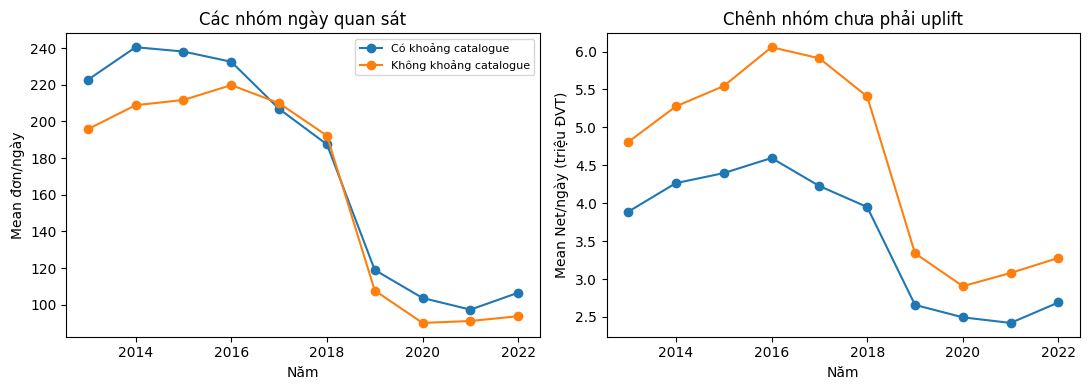

**Nhận xét.** 1707 ngày có khoảng và 1945 ngày không khoảng; mean đơn/ngày 175.70 so 161.94. Trong 120 tầng năm–tháng, 50 tầng đủ hai nhóm theo quy tắc mô tả. Cơ cấu lịch và kết quả trong tầng giúp kiểm tra độ nhạy, chưa loại tự chọn chương trình/mùa vụ/khách. Cần exposure và thiết kế đối chứng trước kết luận tác động.

In [47]:
def day_summary64(d,keys):
    keys=[keys] if isinstance(keys,str) else keys
    t=d.groupby(keys,dropna=False,observed=True).agg(days=('_date','size'),orders=('_orders','sum'),coded_orders=('_coded_orders','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),mean_orders=('_orders','mean'),median_orders=('_orders','median'),_mean_net_c=('_net_c','mean'),_median_net_c=('_net_c','median'),_mean_discount_c=('_discount_c','mean'),_median_discount_c=('_discount_c','median'),mean_sessions=('sessions','mean'),median_sessions=('sessions','median'),mean_pv=('page_views','mean'),median_pv=('page_views','median'),catalog_days=('_has_catalog','sum'),ref_days=('_has_ref','sum')).reset_index()
    t['code_order_pct']=100*t.coded_orders/t.orders
    t['discount_gross_pct']=(100*t._discount_c/t._gross_c).where(t._gross_c.gt(0))
    return t
day_groups64=day_summary64(d64,'_catalog_group')
show(money_view64(day_groups64),'So nhóm ngày trong phạm vi giao; cột _c hiển thị ĐVT, mean/median theo ngày')
composition64=[]
for key,label in [('_year','Năm'),('_calendar_month','Tháng lịch'),('_weekday','Thứ, Hai=0')]:
    counts=d64.groupby(['_catalog_group',key]).size().rename('Ngày').reset_index()
    for _,r in counts.iterrows():
        n=int(d64._catalog_group.eq(r['_catalog_group']).sum())
        composition64.append({'Cơ cấu':label,'Giá trị lịch':str(r[key]),'Nhóm':r['_catalog_group'],'Ngày':int(r['Ngày']),'Mẫu số: ngày nhóm':n,'Tỷ trọng ngày trong nhóm (%)':100*r['Ngày']/n})
show(composition64,'Hai nhóm catalogue có thể khác cơ cấu thời gian')
year_groups64=day_summary64(d64,['_year','_catalog_group'])
show(money_view64(year_groups64.assign(_year=lambda x:x._year.astype(str))),'Trong từng năm: số ngày, đơn, tiền và mean/ngày')
def contrast64(d,key):
    rows=[]
    for value,g in d.groupby(key):
        a=g.loc[g._has_catalog];b=g.loc[~g._has_catalog]
        eligible=len(a)>=5 and len(b)>=5
        rows.append({'Tầng':str(value),'Ngày có khoảng':len(a),'Ngày không khoảng':len(b),'Đủ ≥5 ngày mỗi nhóm':eligible,'Trạng thái':'Đã tính chênh mô tả' if eligible else 'Không áp dụng: thiếu hai nhóm hoặc mẫu nhỏ','Chênh mean đơn/ngày':a._orders.mean()-b._orders.mean() if eligible else np.nan,'_diff_mean_net_c':a._net_c.mean()-b._net_c.mean() if eligible else np.nan,'Chênh mean sessions/ngày':a.sessions.mean()-b.sessions.mean() if eligible else np.nan})
    return pd.DataFrame(rows)
strata64={'Năm':contrast64(d64,'_year'),'Năm–tháng':contrast64(d64,'_month'),'Thứ':contrast64(d64,'_weekday')}
strata_summary64=[]
for label,t in strata64.items():
    good=t.loc[t['Đủ ≥5 ngày mỗi nhóm']]
    weights=good[['Ngày có khoảng','Ngày không khoảng']].min(axis=1)
    strata_summary64.append({'Tầng thời gian':label,'Tổng tầng':len(t),'Tầng đủ':len(good),'Không áp dụng':len(t)-len(good),'Chênh mean đơn/ngày, ngang tầng':good['Chênh mean đơn/ngày'].mean(),'Chênh mean đơn/ngày, trọng số min ngày':np.average(good['Chênh mean đơn/ngày'],weights=weights) if len(good) else np.nan,'_diff_mean_net_c':good._diff_mean_net_c.mean(),'Ngày thuộc tầng đủ':int(good[['Ngày có khoảng','Ngày không khoảng']].to_numpy().sum())})
strata_summary64=pd.DataFrame(strata_summary64)
show(money_view64(strata_summary64),'Độ nhạy mô tả; ngang tầng khác trọng số và không là tác động')
show(money_view64(strata64['Năm–tháng'].sort_values('Chênh mean đơn/ngày',key=lambda x:x.abs(),ascending=False).head(12)),'12 tầng năm–tháng chênh tuyệt đối lớn nhất; không chọn làm hiệu quả')
show(strata64['Năm–tháng'].loc[~strata64['Năm–tháng']['Đủ ≥5 ngày mỗi nhóm'],['Tầng','Ngày có khoảng','Ngày không khoảng','Trạng thái']].head(12),'Ví dụ tầng không tính chênh; toàn bộ số tầng được báo ở bảng tổng hợp')
ck64('Nhóm ngày phân hoạch và bảo toàn đơn/tiền',int(day_groups64.days.sum())==len(d64) and int(day_groups64.orders.sum())==int(d64._orders.sum()) and all(int(day_groups64[c].sum())==int(d64[c].sum()) for c in money_cols64))
ck64('Mean/ngày đúng mẫu số ngày nhóm',np.allclose(day_groups64.mean_orders*day_groups64.days,day_groups64.orders) and np.allclose(day_groups64._mean_net_c*day_groups64.days,day_groups64._net_c))
ck64('Tỷ lệ nhóm dùng tổng đơn và Gross',np.allclose(day_groups64.code_order_pct*day_groups64.orders/100,day_groups64.coded_orders) and np.allclose(day_groups64.discount_gross_pct*day_groups64._gross_c/100,day_groups64._discount_c))
ck64('Tầng năm bảo toàn phạm vi giao',int(year_groups64.days.sum())==len(d64) and int(year_groups64.orders.sum())==int(d64._orders.sum()))
ck64('Tầng đủ có hai nhóm ≥5, tầng thiếu không tính chênh',all(t.loc[t['Đủ ≥5 ngày mỗi nhóm'],['Ngày có khoảng','Ngày không khoảng']].ge(5).all().all() and t.loc[~t['Đủ ≥5 ngày mỗi nhóm'],'Chênh mean đơn/ngày'].isna().all() for t in strata64.values()))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for flag,label in [(True,'Có khoảng catalogue'),(False,'Không khoảng catalogue')]:
    g=d64.loc[d64._has_catalog.eq(flag)].groupby('_year').agg(Đơn=('_orders','mean'),Net=('_net_c','mean'))
    axs[0].plot(g.index,g.Đơn,marker='o',label=label)
    axs[1].plot(g.index,g.Net/100/1_000_000,marker='o',label=label)
axs[0].set(xlabel='Năm',ylabel='Mean đơn/ngày',title='Các nhóm ngày quan sát')
axs[1].set(xlabel='Năm',ylabel='Mean Net/ngày (triệu ĐVT)',title='Chênh nhóm chưa phải uplift')
axs[0].legend(fontsize=8);figdone(fig)
day_yes64=day_groups64.loc[day_groups64._catalog_group.eq('Có khoảng catalogue')].iloc[0]
day_no64=day_groups64.loc[day_groups64._catalog_group.eq('Không khoảng catalogue')].iloc[0]
note(f"**Nhận xét.** {int(day_yes64.days)} ngày có khoảng và {int(day_no64.days)} ngày không khoảng; mean đơn/ngày {day_yes64.mean_orders:.2f} so {day_no64.mean_orders:.2f}. Trong {len(strata64['Năm–tháng'])} tầng năm–tháng, {int(strata64['Năm–tháng']['Đủ ≥5 ngày mỗi nhóm'].sum())} tầng đủ hai nhóm theo quy tắc mô tả. Cơ cấu lịch và kết quả trong tầng giúp kiểm tra độ nhạy, chưa loại tự chọn chương trình/mùa vụ/khách. Cần exposure và thiết kế đối chứng trước kết luận tác động.")

### NV06.4.7 — Catalogue và tham chiếu mã: hai cờ độc lập
Cờ catalogue từ khoảng chương trình; cờ mã từ tổng lượt vị trí trong giao dịch. Bảng bốn tổ hợp dùng số ngày thực của từng tập; tổ hợp rỗng có số đếm/tổng tập rỗng bằng 0, còn mean không xác định để trống. Đây không phải điền dữ liệu web hoặc ngày giao dịch thiếu.

Nếu có ngày mã ngoài catalogue, truy vết r62 và lịch; không tự kết luận vi phạm. Nếu catalogue và cờ mã khớp trong mẫu, vẫn không coi hai khái niệm là tương đương theo định nghĩa.

In [48]:
cross_records64=[]
for cat in [False,True]:
    for ref in [False,True]:
        g=d64.loc[d64._has_catalog.eq(cat)&d64._has_ref.eq(ref)]
        cross_records64.append({'Có khoảng catalogue':cat,'Có lượt mã':ref,'Ngày':len(g),'Đơn':int(g._orders.sum()),'Đơn có mã':int(g._coded_orders.sum()),'_discount_c':int(g._discount_c.sum()),'_mean_discount_c':g._discount_c.mean(),'_mean_net_c':g._net_c.mean(),'Mean số chương trình/ngày':g._programs.mean()})
cross64=pd.DataFrame(cross_records64)
show(money_view64(cross64),'Bốn tổ hợp ngày độc lập trong giao web–đơn')
cat_no_ref64=d64.loc[d64._has_catalog&~d64._has_ref]
ref_no_cat64=d64.loc[~d64._has_catalog&d64._has_ref]
show(money_view64(cat_no_ref64[['_date','_orders','_coded_orders','_refs','_programs','_discount_c']].head(8)),'Tối đa 8 ngày catalogue có khoảng nhưng không có lượt mã; rỗng nghĩa không xuất hiện')
trace_ref_no_cat64=r62.loc[r62._date.isin(ref_no_cat64._date),['_item_row_id','order_id','promo_id','_slot','order_date','start_date','end_date','_window']]
show(trace_ref_no_cat64.head(8),'Truy vết ngày mã không có khoảng, nếu có; đối chiếu NV06.2')
ck64('Bốn tổ hợp bảo toàn ngày/đơn/Discount',int(cross64.Ngày.sum())==len(d64) and int(cross64.Đơn.sum())==int(d64._orders.sum()) and int(cross64._discount_c.sum())==int(d64._discount_c.sum()))
ck64('Ngày mã ngoài catalogue khớp đối chiếu NV06.2',trace_ref_no_cat64._window.ne('Trong').all(),f'{len(ref_no_cat64)} ngày; {len(trace_ref_no_cat64)} lượt')
ck64('Ngày có khoảng đếm một lần khi nhiều chương trình',int(cross64.loc[cross64['Có khoảng catalogue'],'Ngày'].sum())==int(d64._has_catalog.sum()))
note(f"**Nhận xét.** {int(d64._has_ref.sum())} ngày có tham chiếu mã; {len(cat_no_ref64)} ngày có khoảng nhưng không mã; {len(ref_no_cat64)} ngày mã không có khoảng. Chỉ phản ánh catalogue và nhật ký đang quan sát, chưa chứng minh triển khai/exposure hoặc không có người hưởng ưu đãi ngoài dữ liệu. Cần nhật ký thực thi trước đánh giá độ phủ chiến dịch.")

**Bốn tổ hợp ngày độc lập trong giao web–đơn**

Có khoảng catalogue,Có lượt mã,Ngày,Đơn,Đơn có mã,Discount (ĐVT),Discount bình quân/ngày (ĐVT),Net bình quân/ngày (ĐVT),Mean số chương trình/ngày
0,0,1.945,314.966,0,"0,00","0,000000","4.563.856,894838",0
0,1,0,0,0,"0,00",∅,∅,∅
1,0,0,0,0,"0,00",∅,∅,∅
1,1,1.707,299.928,248.242,"749.607.320,10","439.137,270123","3.551.651,937288","1,011716"


**Tối đa 8 ngày catalogue có khoảng nhưng không có lượt mã; rỗng nghĩa không xuất hiện**

Ngày,Đơn,Đơn có mã,Lượt mã,Chương trình bao phủ,Discount (ĐVT)


**Truy vết ngày mã không có khoảng, nếu có; đối chiếu NV06.2**

_item_row_id,order_id,promo_id,_slot,order_date,start_date,end_date,_window


**Nhận xét.** 1707 ngày có tham chiếu mã; 0 ngày có khoảng nhưng không mã; 0 ngày mã không có khoảng. Chỉ phản ánh catalogue và nhật ký đang quan sát, chưa chứng minh triển khai/exposure hoặc không có người hưởng ưu đãi ngoài dữ liệu. Cần nhật ký thực thi trước đánh giá độ phủ chiến dịch.

### NV06.4.8 — Xu hướng đối chiếu theo kỳ trong giao dữ liệu
Chỉ 2013–2022 sau kiểm tra phạm vi thực tế. Tỷ lệ đơn có mã theo kỳ dùng tổng đơn, không cộng tỷ lệ ngày. Tổng UV-ngày nếu báo vẫn không là người duy nhất cả kỳ. Các panel dùng trục/đơn vị riêng, không ghép thang tiền với phiên.

2012 chỉ có giao dịch từ tháng 7, ngoài phép đối chiếu web; không gắn sessions=0 hoặc đưa vào hệ số web–đơn.

**Đối chiếu theo năm; mọi số đo web và tiền thuộc cùng giao ngày**

Năm,Ngày quan sát,Đơn,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Đơn bình quân/ngày,Đơn trung vị/ngày,Net bình quân/ngày (ĐVT),Net trung vị/ngày (ĐVT),Discount bình quân/ngày (ĐVT),Discount trung vị/ngày (ĐVT),Sessions bình quân/ngày,Sessions trung vị/ngày,Page_views bình quân/ngày,Page_views trung vị/ngày,Ngày có khoảng catalogue,Ngày có lượt mã,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%),Tổng sessions ghi nhận,Tổng page_views ghi nhận,"Tổng UV-ngày, không phải người duy nhất cả kỳ",Dòng hàng,Dòng có mã,Lượt mã
2013,365,76.849,35.538,"1.657.169.417,27","87.004.248,57","1.570.165.168,70","210,545205",186,"4.301.822,380000","3.715.858,500000","238.367,804301","26.950,000000","18.635,452055",18.275,"80.557,967123",74.574,200,200,"46,243933","5,250172",6.801.940,29.403.658,5.166.501,87.341,40.529,40.529
2014,365,80.645,29.510,"1.871.845.882,80","86.503.167,66","1.785.342.715,14","220,945205",197,"4.891.349,904493","4.251.113,980000","236.994,979890","0,000000","20.112,219178",19.708,"87.526,594521",83.362,139,139,"36,592473","4,621276",7.340.960,31.947.207,5.596.248,91.086,33.965,33.965
2015,365,82.622,38.118,"1.889.933.826,92","97.923.860,36","1.792.009.966,56","226,361644",201,"4.909.616,346740","4.369.752,690000","268.284,548932","27.600,000000","21.539,556164",20.962,"93.632,589041",87.438,202,202,"46,135412","5,181338",7.861.938,34.175.895,5.962.192,92.537,42.988,43.120
2016,366,82.247,28.367,"2.104.640.677,54","92.276.211,92","2.012.364.465,62","224,718579","196,5","5.498.263,567268","4.701.022,795000","252.120,797596","0,000000","22.960,106557","22.958,5","99.241,188525",94.944,140,140,"34,490012","4,384416",8.403.399,36.322.275,6.393.654,90.895,31.882,31.882
2017,365,76.010,33.654,"1.911.164.325,28","95.617.691,30","1.815.546.633,98","208,246575",179,"4.974.100,367068","4.054.744,460000","261.966,277534","25.550,000000","24.637,265753",24.119,"106.262,852055",102.782,203,203,"44,275753","5,003112",8.992.602,38.785.941,6.818.372,83.691,37.193,37.267
2018,365,69.510,23.150,"1.850.122.456,08","80.399.276,46","1.769.723.179,62","190,438356",156,"4.848.556,656493","4.100.504,230000","220.271,990301","0,000000","25.794,753425",25.444,"113.594,073973",109.317,140,140,"33,30456","4,345619",9.415.085,41.461.837,7.143.496,75.132,25.250,25.250
2019,365,41.601,18.603,"1.136.801.441,51","55.211.860,32","1.081.589.581,19","113,975342",102,"2.963.259,126548","2.652.667,470000","151.265,370740","20.550,000000","27.370,268493",26.432,"117.608,520548",110.379,202,202,"44,717675","4,856773",9.990.148,42.927.110,7.580.565,44.925,20.244,20.244
2020,366,34.881,12.714,"1.054.512.158,79","48.403.622,41","1.006.108.536,38","95,303279",85,"2.748.930,427268","2.424.481,675000","132.250,334454","0,000000","28.937,382514",28.665,"126.083,215847",119.885,140,140,"36,449643","4,590144",10.591.082,46.146.457,8.065.367,37.238,13.654,13.654
2021,365,34.525,15.303,"1.043.039.819,63","51.825.645,91","991.214.173,72","94,589041",84,"2.715.655,270466","2.302.447,680000","141.988,070986","14.500,000000","30.114,315068",29.427,"130.851,690411",123.393,202,202,"44,324403","4,968712",10.991.725,47.760.867,8.367.014,36.749,16.447,16.447
2022,365,36.004,13.285,"1.169.748.831,69","54.441.735,19","1.115.307.096,50","98,641096",90,"3.055.635,880822","2.702.835,700000","149.155,438877","0,000000","30.311,391781",29.790,"130.771,378082",126.179,139,139,"36,898678","4,654139",11.063.658,47.731.553,8.409.280,38.068,14.164,14.164


**12 tháng đầu/cuối để minh họa; mọi tháng có trong bảng làm việc bộ nhớ, không in toàn ngày**

Năm–tháng,Ngày quan sát,Đơn,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Đơn bình quân/ngày,Đơn trung vị/ngày,Net bình quân/ngày (ĐVT),Net trung vị/ngày (ĐVT),Discount bình quân/ngày (ĐVT),Discount trung vị/ngày (ĐVT),Sessions bình quân/ngày,Sessions trung vị/ngày,Page_views bình quân/ngày,Page_views trung vị/ngày,Ngày có khoảng catalogue,Ngày có lượt mã,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%),Tổng sessions ghi nhận,Tổng page_views ghi nhận,"Tổng UV-ngày, không phải người duy nhất cả kỳ",Dòng hàng,Dòng có mã,Lượt mã
2013-01,31,3.665,17,"91.308.677,03","23.227,14","91.285.449,89","118,225806",108,"2.944.691,931935","2.603.356,520000","749,262581","0,000000","9.516,322581",9.698,"40.291,806452",39.117,1,1,"0,463847","0,025438",295.006,1.249.046,224.927,4.216,21,21
2013-02,28,4.661,2.104,"109.783.137,94","3.422.468,64","106.360.669,30","166,464286",149,"3.798.595,332143","3.375.243,625000","122.231,022857","108.281,030000","14.889,142857","14.711,5","64.732,571429","63.202,5",28,28,"45,140528","3,117481",416.896,1.812.512,316.689,5.309,2.705,2.705
2013-03,31,6.590,4.058,"151.834.657,27","10.288.965,87","141.545.691,40","212,580645",203,"4.565.990,045161","4.340.155,200000","331.902,124839","0,000000","20.070,129032",20.504,"88.240,322581",85.400,15,15,"61,578149","6,776428",622.174,2.735.450,477.302,7.461,4.573,4.573
2013-04,30,8.874,3.619,"198.926.932,09","9.275.116,08","189.651.816,01","295,8",268,"6.321.727,200333","6.084.254,275000","309.170,536000","201.564,040000",27.146,26.853,"116.501,433333",114.223,17,17,"40,78206","4,662574",814.380,3.495.043,615.275,9.936,4.052,4.052
2013-05,31,8.314,0,"200.500.109,48","0,00","200.500.109,48","268,193548",228,"6.467.745,467097","5.622.176,450000","0,000000","0,000000",26.340,26.616,"114.653,225806",113.183,0,0,0,0,816.540,3.554.250,621.639,9.288,0,0
2013-06,30,8.469,2.364,"198.517.628,54","8.575.484,25","189.942.144,29","282,3","246,5","6.331.404,809667","5.794.654,055000","285.849,475000","0,000000","26.753,8","26.815,5","119.846,366667",125.099,8,8,"27,913567","4,31976",802.614,3.595.391,609.958,9.452,2.641,2.641
2022-07,31,3.122,1.973,"98.141.777,72","10.299.059,16","87.842.718,56","100,709677",101,"2.833.636,082581","2.706.697,270000","332.227,714839","357.974,510000",34.441,34.657,"152.814,83871",152.256,22,22,"63,196669","10,494062",1.067.671,4.737.260,810.433,3.252,2.054,2.054
2022-08,31,3.274,2,"113.542.943,47","6.936,56","113.536.006,91","105,612903",93,"3.662.451,835806","3.292.983,260000","223,760000","0,000000","38.071,16129",38.935,"164.105,387097",168.649,1,1,"0,061087","0,006109",1.180.206,5.087.267,896.768,3.432,2,2
2022-09,30,2.643,2.448,"85.764.286,59","7.947.430,04","77.816.856,55","88,1",81,"2.593.895,218333","2.348.332,685000","264.914,334667","253.955,200000","27.224,733333",27.031,"115.750,1",118.374,30,30,"92,62202","9,266596",816.742,3.472.503,617.741,2.751,2.548,2.548
2022-10,31,2.097,16,"75.194.452,31","57.433,23","75.137.019,08","67,645161",65,"2.423.774,809032","2.345.490,550000","1.852,684839","0,000000","21.205,83871",21.079,"89.662,870968",89.735,1,1,"0,762995","0,07638",657.381,2.779.549,498.478,2.194,18,18


**Phần giao dịch ngoài web báo riêng, không trộn vào đối chiếu**

Phạm vi,Đơn,Từ,Đến,Gross (ĐVT),Net (ĐVT),Web
Giao dịch ngoài web (2012 trong nguồn hiện hành),32.051,2012-07-04,2012-12-31,"741.497.748,02","741.497.748,02","Chưa quan sát, không gán0"


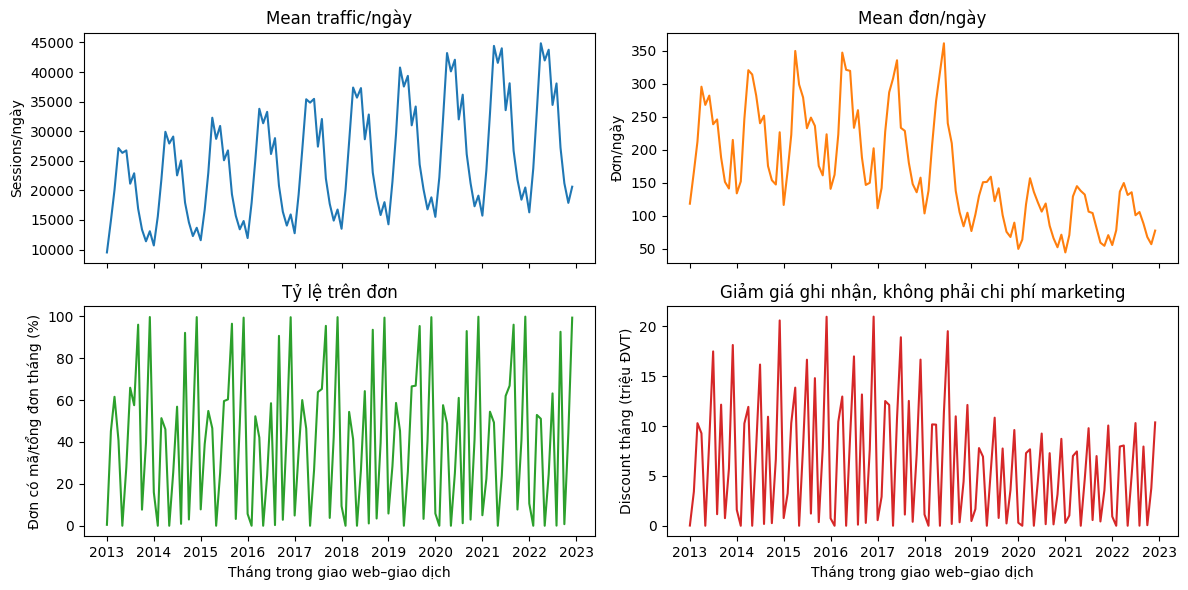

**Nhận xét.** 120 tháng và 10 năm đối chiếu được bảo toàn; 32,051 đơn ngoài web được báo riêng. Tỷ lệ mã và Discount thay đổi cùng số ngày catalogue, trong khi traffic và đơn còn có xu hướng dài hạn riêng. Các chuỗi cùng thời điểm chưa chứng minh ảnh hưởng marketing; cần kiểm tra hệ số trong năm và sau biến đổi thời gian.

In [49]:
def period64(key):
    t=day_summary64(d64,key)
    extra=d64.groupby(key).agg(sessions_total=('sessions','sum'),pv_total=('page_views','sum'),uv_daily_sum=('unique_visitors','sum'),lines=('_lines','sum'),coded_lines=('_coded_lines','sum'),refs=('_refs','sum')).reset_index()
    return t.merge(extra,on=key,validate='one_to_one')
year64=period64('_year');month64=period64('_month')
show(money_view64(year64.assign(_year=lambda x:x._year.astype(str))),'Đối chiếu theo năm; mọi số đo web và tiền thuộc cùng giao ngày')
selected_month64=pd.concat([month64.head(6),month64.tail(6)])
show(money_view64(selected_month64),'12 tháng đầu/cuối để minh họa; mọi tháng có trong bảng làm việc bộ nhớ, không in toàn ngày')
outside_web_tx64=o64.loc[~o64._date.between(lower64,upper64)]
show([{'Phạm vi':'Giao dịch ngoài web (2012 trong nguồn hiện hành)','Đơn':len(outside_web_tx64),'Từ':str(outside_web_tx64._date.min().date()),'Đến':str(outside_web_tx64._date.max().date()),'Gross (ĐVT)':money63(outside_web_tx64._gross_c.sum()),'Net (ĐVT)':money63(outside_web_tx64._net_c.sum()),'Web':'Chưa quan sát, không gán0'}],'Phần giao dịch ngoài web báo riêng, không trộn vào đối chiếu')
for label,t in [('năm',year64),('tháng',month64)]:
    ck64('Theo '+label+': bảo toàn ngày/đơn/lượt/tiền/web',int(t.days.sum())==len(d64) and int(t.orders.sum())==int(d64._orders.sum()) and int(t.refs.sum())==int(d64._refs.sum()) and int(t.sessions_total.sum())==int(d64.sessions.sum()) and all(int(t[c].sum())==int(d64[c].sum()) for c in money_cols64))
    ck64('Theo '+label+': tỷ lệ đúng tổng tử/mẫu',np.allclose(t.code_order_pct*t.orders/100,t.coded_orders))
fig,axs=plt.subplots(2,2,figsize=(12,6),sharex=True)
x=pd.to_datetime(month64._month)
axs[0,0].plot(x,month64.mean_sessions);axs[0,0].set(ylabel='Sessions/ngày',title='Mean traffic/ngày')
axs[0,1].plot(x,month64.mean_orders,color='tab:orange');axs[0,1].set(ylabel='Đơn/ngày',title='Mean đơn/ngày')
axs[1,0].plot(x,month64.code_order_pct,color='tab:green');axs[1,0].set(ylabel='Đơn có mã/tổng đơn tháng (%)',title='Tỷ lệ trên đơn')
axs[1,1].plot(x,month64._discount_c/100/1_000_000,color='tab:red');axs[1,1].set(ylabel='Discount tháng (triệu ĐVT)',title='Giảm giá ghi nhận, không phải chi phí marketing')
for ax in axs[1]:ax.set_xlabel('Tháng trong giao web–giao dịch')
figdone(fig)
note(f"**Nhận xét.** {len(month64)} tháng và {len(year64)} năm đối chiếu được bảo toàn; {len(outside_web_tx64):,} đơn ngoài web được báo riêng. Tỷ lệ mã và Discount thay đổi cùng số ngày catalogue, trong khi traffic và đơn còn có xu hướng dài hạn riêng. Các chuỗi cùng thời điểm chưa chứng minh ảnh hưởng marketing; cần kiểm tra hệ số trong năm và sau biến đổi thời gian.")

### NV06.4.9 — Tương quan traffic–giao dịch và độ nhạy thời gian
Pearson và Spearman dùng cùng cặp ngày hữu hạn; không tính khi biến hằng hoặc dưới 3 cặp. Giữ cực trị, báo min/max/phân vị và cờ IQR mô tả. Không suy conversion từ tương quan.

Hai cách nhìn: **ngày gốc** và **trừ mean riêng trong từng năm–tháng của mỗi biến**. Bản trừ mean chỉ dùng tương quan, không dùng cộng tiền. Cách này giảm khác biệt mức độ giữa tháng, chưa loại mùa vụ trong tháng, lựa chọn chương trình hoặc các yếu tố khác. Hệ số đổi dấu/độ lớn chưa là tác động. Hệ số theo năm được báo cùng số cặp và trạng thái.

**Quan hệ mô tả trong giao ngày; không là tỷ lệ chuyển đổi hoặc tác động**

Biến traffic,Biến giao dịch,Cách nhìn,Cặp ngày,Pearson,Spearman,Trạng thái
sessions,_orders,Ngày gốc,3.652,"0,190852","0,228827",Đã tính mô tả
sessions,_orders,Trừ mean năm–tháng,3.652,"-0,011633","-0,010401",Đã tính mô tả
sessions,_coded_orders,Ngày gốc,3.652,"-0,015017","-0,016657",Đã tính mô tả
sessions,_coded_orders,Trừ mean năm–tháng,3.652,"0,018442","0,009967",Đã tính mô tả
sessions,_gross_c,Ngày gốc,3.652,"0,32105","0,36839",Đã tính mô tả
sessions,_gross_c,Trừ mean năm–tháng,3.652,"-0,019169","-0,010605",Đã tính mô tả
sessions,_discount_c,Ngày gốc,3.652,"0,003523","-0,022557",Đã tính mô tả
sessions,_discount_c,Trừ mean năm–tháng,3.652,"0,021428","0,012711",Đã tính mô tả
sessions,_net_c,Ngày gốc,3.652,"0,327766","0,37512",Đã tính mô tả
sessions,_net_c,Trừ mean năm–tháng,3.652,"-0,023136","-0,012628",Đã tính mô tả


**Trong từng năm; không chọn riêng hệ số thuận lợi**

Năm,A,B,Cặp ngày,Pearson,Spearman,Trạng thái
2013,sessions,_orders,365,"0,477948","0,548314",Đã tính mô tả
2013,sessions,_coded_orders,365,"0,075047","0,057784",Đã tính mô tả
2013,sessions,_gross_c,365,"0,538091","0,577934",Đã tính mô tả
2013,sessions,_discount_c,365,"0,045397","0,00801",Đã tính mô tả
2013,sessions,_net_c,365,"0,541206","0,580423",Đã tính mô tả
2013,page_views,_orders,365,"0,415757","0,508752",Đã tính mô tả
2013,page_views,_coded_orders,365,"0,056864","0,056889",Đã tính mô tả
2013,page_views,_net_c,365,"0,480621","0,528923",Đã tính mô tả
2013,unique_visitors,_orders,365,"0,470921","0,54647",Đã tính mô tả
2014,sessions,_orders,365,"0,499443","0,568999",Đã tính mô tả


**Phân bố ngày đầu vào tương quan; tiền giữ đơn vị tính nội bộ ở bảng chẩn đoán này**

Biến,Ngày hữu hạn,Min,P01,Median,P99,Max,Cờ IQR (giữ nguyên),Đơn vị
sessions,3.652,7.973,"10.038,06","23.633,5","47.227,96",50.947,0,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
_orders,3.652,8,31,138,569,803,156,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
_coded_orders,3.652,0,0,0,"484,43",725,190,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
_gross_c,3.652,27.981.394,"83.523.743,64",364.724.208,"1.381.170.391,76",2.090.527.135,155,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
_discount_c,3.652,0,0,0,"154.563.495,67",262.365.376,194,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
_net_c,3.652,27.981.394,"74.615.345,39",347.040.317,"1.342.893.429,439994",2.090.527.135,168,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
page_views,3.652,30.451,"39.353,04","101.010,5","223.688,37",275.560,18,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại
unique_visitors,3.652,6.136,"7.516,77",17.924,"36.726,2",40.430,0,Phần trăm ĐVT khi hậu tố _c; số đếm còn lại


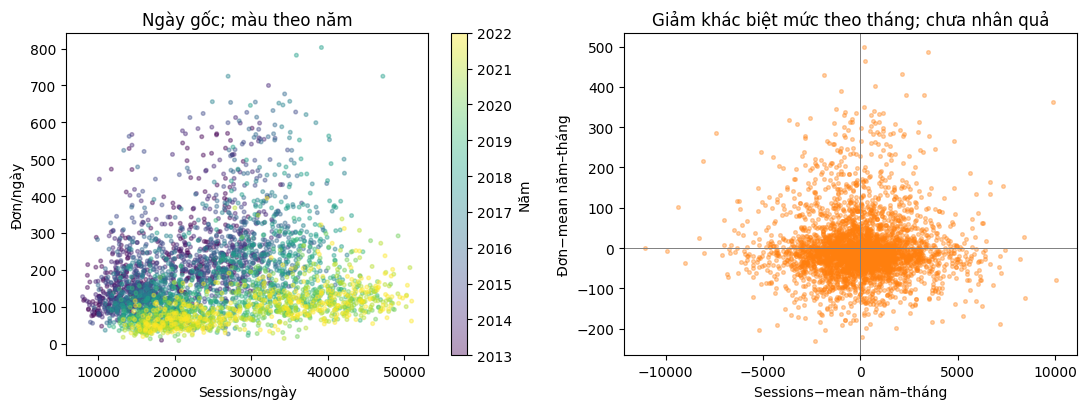

**Nhận xét.** Sessions–đơn dùng 3652 ngày: Pearson gốc 0.190852, sau trừ mean năm–tháng -0.011633; Spearman tương ứng 0.228827 và -0.010401. Chênh giữa hai cách nhìn cho thấy cần xét cấu trúc thời gian, không xác nhận traffic tạo đơn. Cần bridge sự kiện, định nghĩa chuyển đổi và phương pháp đối chứng trước câu hỏi tác động.

In [50]:
pairs64=[('sessions','_orders'),('sessions','_coded_orders'),('sessions','_gross_c'),('sessions','_discount_c'),('sessions','_net_c'),('page_views','_orders'),('page_views','_coded_orders'),('page_views','_net_c'),('unique_visitors','_orders')]
corr_vars64=list(dict.fromkeys(v for pair in pairs64 for v in pair))
def correlations64(d,a,b):
    valid=np.isfinite(d[a].astype(float))&np.isfinite(d[b].astype(float))
    g=d.loc[valid,[a,b]].astype(float)
    if len(g)<3:return len(g),np.nan,np.nan,'Không áp dụng: dưới3 cặp'
    if g[a].nunique()<2 or g[b].nunique()<2:return len(g),np.nan,np.nan,'Không áp dụng: biến hằng'
    return len(g),float(g[a].corr(g[b])),float(g[a].rank(method='average').corr(g[b].rank(method='average'))),'Đã tính mô tả'
center64=d64[['_date','_year','_month',*corr_vars64]].copy()
for v in corr_vars64:center64[v]=center64[v].astype(float)-center64.groupby('_month')[v].transform('mean').astype(float)
corr_rows64=[]
for a,b in pairs64:
    for label,g in [('Ngày gốc',d64),('Trừ mean năm–tháng',center64)]:
        n,p,s,status=correlations64(g,a,b)
        corr_rows64.append({'Biến traffic':a,'Biến giao dịch':b,'Cách nhìn':label,'Cặp ngày':n,'Pearson':p,'Spearman':s,'Trạng thái':status})
corr64=pd.DataFrame(corr_rows64)
show(corr64,'Quan hệ mô tả trong giao ngày; không là tỷ lệ chuyển đổi hoặc tác động')
corr_year64=[]
for year,g in d64.groupby('_year'):
    for a,b in pairs64:
        n,p,s,status=correlations64(g,a,b)
        corr_year64.append({'Năm':str(year),'A':a,'B':b,'Cặp ngày':n,'Pearson':p,'Spearman':s,'Trạng thái':status})
corr_year64=pd.DataFrame(corr_year64)
show(corr_year64,'Trong từng năm; không chọn riêng hệ số thuận lợi')
distribution64=[]
for col in corr_vars64:
    s=d64[col].astype(float);q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    distribution64.append({'Biến':col,'Ngày hữu hạn':int(np.isfinite(s).sum()),'Min':s.min(),'P01':s.quantile(.01),'Median':s.median(),'P99':s.quantile(.99),'Max':s.max(),'Cờ IQR (giữ nguyên)':int((s.lt(q1-1.5*iqr)|s.gt(q3+1.5*iqr)).sum()),'Đơn vị':'Phần trăm ĐVT khi hậu tố _c; số đếm còn lại'})
show(distribution64,'Phân bố ngày đầu vào tương quan; tiền giữ đơn vị tính nội bộ ở bảng chẩn đoán này')
for a,b in pairs64:
    for label,g in [('gốc',d64),('trừ mean',center64)]:
        n,p,s,status=correlations64(g,a,b)
        valid=np.isfinite(g[a].astype(float))&np.isfinite(g[b].astype(float))
        ck64('Cùng cặp hữu hạn '+label+': '+a+'/'+b,n==int(valid.sum()))
ck64('Trừ mean giữ đúng các ngày, không thêm lịch',center64._date.equals(d64._date))
ck64('Mean năm–tháng đã trừ gần0',all(np.allclose(center64.groupby('_month')[v].mean(),0,atol=1e-5) for v in corr_vars64))
ck64('Biến đổi tương quan không thay tiền gốc',all(int(d64[c].sum())==int(t_in64[c].sum()) for c in money_cols64))
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
pts=axs[0].scatter(d64.sessions,d64._orders,c=d64._year,s=7,alpha=.4,cmap='viridis')
axs[0].set(xlabel='Sessions/ngày',ylabel='Đơn/ngày',title='Ngày gốc; màu theo năm');fig.colorbar(pts,ax=axs[0],label='Năm')
axs[1].scatter(center64.sessions,center64._orders,s=7,alpha=.35,color='tab:orange')
axs[1].axhline(0,color='gray',lw=.7);axs[1].axvline(0,color='gray',lw=.7)
axs[1].set(xlabel='Sessions−mean năm–tháng',ylabel='Đơn−mean năm–tháng',title='Giảm khác biệt mức theo tháng; chưa nhân quả');figdone(fig)
main_corr64=corr64.loc[corr64['Biến traffic'].eq('sessions')&corr64['Biến giao dịch'].eq('_orders')]
raw_corr64=main_corr64.loc[main_corr64['Cách nhìn'].eq('Ngày gốc')].iloc[0]
center_corr64=main_corr64.loc[main_corr64['Cách nhìn'].eq('Trừ mean năm–tháng')].iloc[0]
note(f"**Nhận xét.** Sessions–đơn dùng {int(raw_corr64['Cặp ngày'])} ngày: Pearson gốc {raw_corr64.Pearson:.6f}, sau trừ mean năm–tháng {center_corr64.Pearson:.6f}; Spearman tương ứng {raw_corr64.Spearman:.6f} và {center_corr64.Spearman:.6f}. Chênh giữa hai cách nhìn cho thấy cần xét cấu trúc thời gian, không xác nhận traffic tạo đơn. Cần bridge sự kiện, định nghĩa chuyển đổi và phương pháp đối chứng trước câu hỏi tác động.")

### NV06.4.10 — Lag ngắn theo ngày lịch, chỉ thăm dò
Chiều lag k≥0: **sessions tại ngày t−k so số đơn tại ngày t**. Ghép bằng khóa ngày sau khi cộng k ngày lịch vào ngày traffic; không dùng shift theo vị trí dòng. Cả ngày nguồn/đích thuộc giao đã quan sát, không điền ngoài phạm vi.

Khảo sát k=0,1,2,7, báo số cặp và khoảng ngày. Kèm bản trừ mean năm–tháng để thấy độ nhạy. Không chọn hệ số lớn nhất làm thời gian chuyển đổi, phản hồi hoặc attribution; không xây mô hình chuỗi thời gian.

In [51]:
def calendar_lag64(d,k,x='sessions',y='_orders'):
    src=d[['_date',x]].rename(columns={'_date':'traffic_date',x:'traffic_value'}).copy()
    src['_date']=src.traffic_date+pd.to_timedelta(k,unit='D')
    target=d[['_date',y]].rename(columns={y:'target_value'})
    return src.merge(target,on='_date',how='inner',validate='one_to_one')
lag_rows64=[]
for k in [0,1,2,7]:
    g=calendar_lag64(d64,k);gc=calendar_lag64(center64,k)
    n,p,s,status=correlations64(g,'traffic_value','target_value')
    nc,pc,sc,stc=correlations64(gc,'traffic_value','target_value')
    lag_rows64.append({'k: traffic trước đơn (ngày)':k,'Cặp ngày':n,'Traffic từ':str(g.traffic_date.min().date()),'Traffic đến':str(g.traffic_date.max().date()),'Đơn từ':str(g._date.min().date()),'Đơn đến':str(g._date.max().date()),'Pearson ngày gốc':p,'Spearman ngày gốc':s,'Pearson trừ mean':pc,'Spearman trừ mean':sc,'Trạng thái':status,'Trạng thái trừ mean':stc})
    ck64('Lag '+str(k)+': đúng chiều và ngày lịch',(g._date-g.traffic_date).dt.days.eq(k).all() and g.traffic_date.isin(d64._date).all() and g._date.isin(d64._date).all())
    ck64('Lag '+str(k)+': cùng cặp cho hai cách nhìn',n==nc and g[['_date','traffic_date']].equals(gc[['_date','traffic_date']]))
lag64=pd.DataFrame(lag_rows64)
show(lag64,'Lag theo khóa ngày thực, không là độ trễ chuyển đổi')
note(f"**Nhận xét.** Lag0 có {int(lag64.iloc[0]['Cặp ngày'])} cặp; lag7 có {int(lag64.iloc[-1]['Cặp ngày'])} cặp vì biên phạm vi. Khác hệ số theo lag có thể phản ánh chu kỳ lịch hoặc xu hướng chung. Các hệ số không định danh người và chưa đo thời gian từ truy cập tới đặt hàng; cần phiên–đơn và cửa sổ được xác minh.")

**Lag theo khóa ngày thực, không là độ trễ chuyển đổi**

k: traffic trước đơn (ngày),Cặp ngày,Traffic từ,Traffic đến,Đơn từ,Đơn đến,Pearson ngày gốc,Spearman ngày gốc,Pearson trừ mean,Spearman trừ mean,Trạng thái,Trạng thái trừ mean
0,3.652,2013-01-01,2022-12-31,2013-01-01,2022-12-31,"0,190852","0,228827","-0,011633","-0,010401",Đã tính mô tả,Đã tính mô tả
1,3.651,2013-01-01,2022-12-30,2013-01-02,2022-12-31,"0,192827","0,234023","-0,005608","0,002419",Đã tính mô tả,Đã tính mô tả
2,3.650,2013-01-01,2022-12-29,2013-01-03,2022-12-31,"0,188628","0,231738","-0,007254","0,00472",Đã tính mô tả,Đã tính mô tả
7,3.645,2013-01-01,2022-12-24,2013-01-08,2022-12-31,"0,181667","0,222368","0,025347","0,039022",Đã tính mô tả,Đã tính mô tả


**Nhận xét.** Lag0 có 3652 cặp; lag7 có 3645 cặp vì biên phạm vi. Khác hệ số theo lag có thể phản ánh chu kỳ lịch hoặc xu hướng chung. Các hệ số không định danh người và chưa đo thời gian từ truy cập tới đặt hàng; cần phiên–đơn và cửa sổ được xác minh.

### NV06.4.11–12 — Đơn có/không mã và snapshot status
Phạm vi toàn bộ orders, kể cả 2012 ngoài web. Hai nhóm đơn không giao nhau, mỗi order_id tính một lần; tiền gồm mọi dòng trong đơn. Đây là các nhóm đã quan sát, không là phân nhóm thử nghiệm/ngẫu nhiên.

Các nhóm khác sản phẩm, khách, quy mô và thời điểm. order_status là snapshot; returned chưa chứng minh hoàn tiền đầy đủ, cancelled chưa chứng minh không phát sinh tác động. Không suy mã gây hủy/hoàn hoặc lợi nhuận. Mean/median tiền/đơn và số dòng/đơn có mẫu số riêng.

**Nhóm đơn đã quan sát; toàn bộ tiền của đơn, không chỉ dòng có mã**

Đơn có mã,Đơn,Đơn có mã,Dòng hàng,Số lượng hàng,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross bình quân/đơn (ĐVT),Gross trung vị/đơn (ĐVT),Net bình quân/đơn (ĐVT),Net trung vị/đơn (ĐVT),Dòng bình quân/đơn,Dòng trung vị/đơn,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%)
0,398.703,0,438.045,1.969.749,"10.990.390.489,76","0,00","10.990.390.489,76","27.565,356894","20.440,350000","27.565,356894","20.440,350000","1,098675",1,0,0
1,248.242,248.242,276.624,1.243.394,"5.440.086.095,77","749.607.320,10","4.690.478.775,67","21.914,446773","15.555,480000","18.894,783218","13.453,990000","1,114332",1,100,"13,779328"


**Snapshot status: đơn và tiền, không phải dòng tiền hoặc chuyển đổi**

order_status,Đơn,Đơn có mã,Dòng hàng,Số lượng hàng,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross bình quân/đơn (ĐVT),Gross trung vị/đơn (ĐVT),Net bình quân/đơn (ĐVT),Net trung vị/đơn (ĐVT),Dòng bình quân/đơn,Dòng trung vị/đơn,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%)
cancelled,59.462,22.883,65.673,296.113,"1.515.891.006,19","68.877.368,76","1.447.013.637,43","25.493,441293","18.292,235000","24.335,098675","17.233,225000","1,104453",1,"38,483401","4,543689"
created,7.275,2.830,7.994,36.137,"190.652.330,76","8.817.311,99","181.835.018,77","26.206,505946","18.785,360000","24.994,504298","17.758,030000","1,098832",1,"38,900344","4,624812"
delivered,516.716,198.222,570.887,2.565.930,"13.117.091.360,41","598.915.403,21","12.518.175.957,20","25.385,494857","18.276,700000","24.226,414427","17.242,600000","1,104837",1,"38,361885","4,565916"
paid,13.577,5.171,14.987,67.325,"345.922.854,99","15.295.758,75","330.627.096,24","25.478,592840","18.187,760000","24.351,999428","17.150,760000","1,103852",1,"38,08647","4,421725"
returned,36.142,13.930,40.034,179.401,"907.543.031,93","41.604.316,34","865.938.715,59","25.110,481764","17.964,120000","23.959,346898","16.851,870000","1,107686",1,"38,542416","4,58428"
shipped,13.773,5.206,15.094,68.237,"353.376.001,25","16.097.161,05","337.278.840,20","25.657,155395","18.548,940000","24.488,407769","17.470,720000","1,095912",1,"37,798591","4,55525"


**Có/không mã trong status; mẫu số tỷ trọng là mọi đơn của cùng nhóm mã**

order_status,Đơn có mã,Đơn,Đơn có mã,Dòng hàng,Số lượng hàng,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross bình quân/đơn (ĐVT),Gross trung vị/đơn (ĐVT),Net bình quân/đơn (ĐVT),Net trung vị/đơn (ĐVT),Dòng bình quân/đơn,Dòng trung vị/đơn,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%),Tỷ trọng trong nhóm mã (%)
cancelled,0,36.579,0,40.171,181.153,"1.015.587.448,78","0,00","1.015.587.448,78","27.764,221241","20.514,100000","27.764,221241","20.514,100000","1,098198",1,0,0,"9,174498"
cancelled,1,22.883,22.883,25.502,114.960,"500.303.557,41","68.877.368,76","431.426.188,65","21.863,547499","15.521,800000","18.853,567655","13.433,330000","1,114452",1,100,"13,767116","9,218021"
created,0,4.445,0,4.860,22.012,"126.276.050,56","0,00","126.276.050,56","28.408,560306","21.273,520000","28.408,560306","21.273,520000","1,093363",1,0,0,"1,114865"
created,1,2.830,2.830,3.134,14.125,"64.376.280,20","8.817.311,99","55.558.968,21","22.747,802191","15.756,695000","19.632,144244","13.596,215000","1,10742",1,100,"13,696523","1,140017"
delivered,0,318.494,0,349.951,1.573.274,"8.772.026.852,39","0,00","8.772.026.852,39","27.542,204413","20.436,150000","27.542,204413","20.436,150000","1,098768",1,0,0,"79,882519"
delivered,1,198.222,198.222,220.936,992.656,"4.345.064.508,02","598.915.403,21","3.746.149.104,81","21.920,193056","15.564,380000","18.898,755460","13.458,090000","1,114589",1,100,"13,783809","79,850307"
paid,0,8.406,0,9.247,41.626,"233.535.974,65","0,00","233.535.974,65","27.782,057417","20.555,140000","27.782,057417","20.555,140000","1,100048",1,0,0,"2,108336"
paid,1,5.171,5.171,5.740,25.699,"112.386.880,34","15.295.758,75","97.091.121,59","21.734,070845","15.403,950000","18.776,082303","13.232,240000","1,110037",1,100,"13,609915","2,083048"
returned,0,22.212,0,24.484,109.557,"606.213.117,62","0,00","606.213.117,62","27.292,144679","20.029,545000","27.292,144679","20.029,545000","1,102287",1,0,0,"5,571064"
returned,1,13.930,13.930,15.550,69.844,"301.329.914,31","41.604.316,34","259.725.597,97","21.631,723927","15.442,110000","18.645,053695","13.388,120000","1,116296",1,100,"13,806899","5,61146"


**Độ nhạy theo năm đặt đơn; 2012 chỉ 04/07–31/12 và không có web**

Năm,Đơn có mã,Đơn,Đơn có mã,Dòng hàng,Số lượng hàng,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross bình quân/đơn (ĐVT),Gross trung vị/đơn (ĐVT),Net bình quân/đơn (ĐVT),Net trung vị/đơn (ĐVT),Dòng bình quân/đơn,Dòng trung vị/đơn,Đơn có mã/tổng đơn (%),Tổng Discount/tổng Gross (%)
2012,0,32.051,0,37.007,166.286,"741.497.748,02","0,00","741.497.748,02","23.134,933326","14.603,200000","23.134,933326","14.603,200000","1,154629",1,0,0
2013,0,41.311,0,46.725,209.656,"994.365.549,89","0,00","994.365.549,89","24.070,236738","16.556,040000","24.070,236738","16.556,040000","1,131055",1,0,0
2013,1,35.538,35.538,40.616,182.866,"662.803.867,38","87.004.248,57","575.799.618,81","18.650,567488","12.571,540000","16.202,364196","10.979,795000","1,142889",1,100,"13,126696"
2014,0,51.135,0,57.121,257.425,"1.295.140.818,39","0,00","1.295.140.818,39","25.327,873636","18.494,820000","25.327,873636","18.494,820000","1,117063",1,0,0
2014,1,29.510,29.510,33.965,152.858,"576.705.064,41","86.503.167,66","490.201.896,75","19.542,699573","12.954,320000","16.611,382472","10.909,850000","1,150966",1,100,"14,999551"
2015,0,44.504,0,49.452,222.017,"1.144.071.882,67","0,00","1.144.071.882,67","25.707,169753","18.994,905000","25.707,169753","18.994,905000","1,111181",1,0,0
2015,1,38.118,38.118,43.085,193.492,"745.861.944,25","97.923.860,36","647.938.083,89","19.567,184644","13.763,755000","16.998,218267","11.938,570000","1,130306",1,100,"13,128952"
2016,0,53.880,0,59.013,266.453,"1.483.054.466,14","0,00","1.483.054.466,14","27.525,138570","21.222,300000","27.525,138570","21.222,300000","1,095267",1,0,0
2016,1,28.367,28.367,31.882,143.440,"621.586.211,40","92.276.211,92","529.309.999,48","21.912,299905","15.708,000000","18.659,357686","13.360,250000","1,123912",1,100,"14,84528"
2017,0,42.356,0,46.406,208.017,"1.176.418.282,24","0,00","1.176.418.282,24","27.774,536836","21.608,140000","27.774,536836","21.608,140000","1,095618",1,0,0


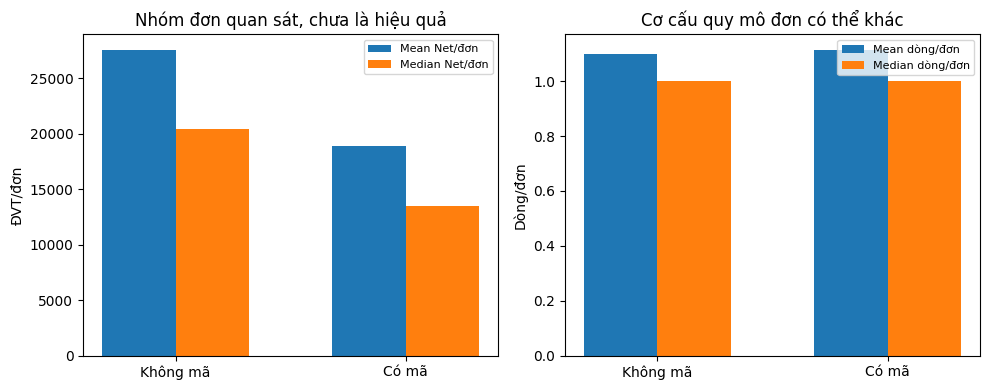

**Nhận xét.** 248,242 đơn có mã so 398,703 không mã; mean Net/đơn 18.894,78 so 27.565,36 ĐVT. Giữ đủ 6 status và kiểm tra từng năm; khác biệt quan sát chưa cho biết mã làm tăng/giảm giá trị, hủy hay hoàn. Cần kiểm soát cấu trúc khách/sản phẩm và lịch sử trạng thái.

In [52]:
def order_summary64(d,keys):
    keys=[keys] if isinstance(keys,str) else keys
    t=d.groupby(keys,dropna=False,observed=True).agg(orders=('order_id','size'),coded_orders=('_has_code','sum'),lines=('_lines','sum'),quantity=('_qty','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_mean_gross_c=('_gross_c','mean'),_median_gross_c=('_gross_c','median'),_mean_net_c=('_net_c','mean'),_median_net_c=('_net_c','median'),mean_lines=('_lines','mean'),median_lines=('_lines','median')).reset_index()
    t['coded_order_pct']=100*t.coded_orders/t.orders;t['discount_gross_pct']=(100*t._discount_c/t._gross_c).where(t._gross_c.gt(0))
    return t
order_groups64=order_summary64(o64,'_has_code')
status_groups64=order_summary64(o64,'order_status')
status_code64=order_summary64(o64,['order_status','_has_code'])
status_code64['Tỷ trọng trong nhóm mã (%)']=100*status_code64.orders/status_code64._has_code.map(o64.groupby('_has_code').size())
year_code64=order_summary64(o64,['_year','_has_code'])
show(money_view64(order_groups64),'Nhóm đơn đã quan sát; toàn bộ tiền của đơn, không chỉ dòng có mã')
show(money_view64(status_groups64),'Snapshot status: đơn và tiền, không phải dòng tiền hoặc chuyển đổi')
show(money_view64(status_code64),'Có/không mã trong status; mẫu số tỷ trọng là mọi đơn của cùng nhóm mã')
show(money_view64(year_code64.assign(_year=lambda x:x._year.astype(str))),'Độ nhạy theo năm đặt đơn; 2012 chỉ 04/07–31/12 và không có web')
ck64('Hai nhóm đơn phân hoạch, bảo toàn dòng/quantity/tiền',int(order_groups64.orders.sum())==len(o64) and int(order_groups64.lines.sum())==len(li64) and int(order_groups64.quantity.sum())==int(li64._qty.sum()) and all(int(order_groups64[c].sum())==int(o64[c].sum()) for c in money_cols64))
ck64('Status bảo toàn đơn và tiền',int(status_groups64.orders.sum())==len(o64) and all(int(status_groups64[c].sum())==int(o64[c].sum()) for c in money_cols64))
ck64('Status×mã và năm×mã bảo toàn đơn',int(status_code64.orders.sum())==len(o64) and int(year_code64.orders.sum())==len(o64))
ck64('Mean tiền/đơn đúng mẫu số',np.allclose(order_groups64._mean_gross_c*order_groups64.orders,order_groups64._gross_c) and np.allclose(order_groups64._mean_net_c*order_groups64.orders,order_groups64._net_c))
fig,axs=plt.subplots(1,2,figsize=(10,4))
labels=['Có mã' if v else 'Không mã' for v in order_groups64._has_code]
x=np.arange(len(labels));width=.32
axs[0].bar(x-width/2,order_groups64._mean_net_c/100,width,label='Mean Net/đơn')
axs[0].bar(x+width/2,order_groups64._median_net_c/100,width,label='Median Net/đơn')
axs[0].set(xticks=x,xticklabels=labels,ylabel='ĐVT/đơn',title='Nhóm đơn quan sát, chưa là hiệu quả');axs[0].legend(fontsize=8)
axs[1].bar(x-width/2,order_groups64.mean_lines,width,label='Mean dòng/đơn')
axs[1].bar(x+width/2,order_groups64.median_lines,width,label='Median dòng/đơn')
axs[1].set(xticks=x,xticklabels=labels,ylabel='Dòng/đơn',title='Cơ cấu quy mô đơn có thể khác');axs[1].legend(fontsize=8)
figdone(fig)
order_yes64=order_groups64.loc[order_groups64._has_code].iloc[0]
order_no64=order_groups64.loc[~order_groups64._has_code].iloc[0]
note(f"**Nhận xét.** {int(order_yes64.orders):,} đơn có mã so {int(order_no64.orders):,} không mã; mean Net/đơn {money63(order_yes64._mean_net_c)} so {money63(order_no64._mean_net_c)} ĐVT. Giữ đủ {len(status_groups64)} status và kiểm tra từng năm; khác biệt quan sát chưa cho biết mã làm tăng/giảm giá trị, hủy hay hoàn. Cần kiểm soát cấu trúc khách/sản phẩm và lịch sử trạng thái.")

### NV06.4.13 — Mã trên đơn thuộc khách có acquisition_channel
Tên phép đo: **“Phân tích việc tham chiếu mã khuyến mãi trên các đơn thuộc khách hàng được gắn nhãn acquisition_channel=X”**. Đây là nhãn hồ sơ hồi cứu; không là khuyến mãi/doanh thu/hiệu quả của kênh X.

JOIN bảng cấp đơn với customer_id duy nhất, bảo toàn tiền. Số khách trong hồ sơ và khách có đơn có mẫu số khác nhau. Mean/median số đơn có mã trên khách có đơn bao gồm cả khách có đơn nhưng không có đơn mang mã (số đếm từ giao dịch bằng 0, không điền NULL nguồn).

Kiểm tra độ nhạy toàn bộ/trước/bằng/sau signup. Nhóm dưới30 đơn không tính tỷ lệ trong bảng nhãn×thời gian; mốc30 là cảnh báo mô tả, không ngưỡng kiểm định. Đơn sau signup chưa được xác nhận do acquisition tạo ra.

In [53]:
ck64('Customers: khóa đủ/duy nhất trước JOIN',c63.customer_id.notna().all() and c63.customer_id.is_unique)
acq_o64=o64.merge(c63[['customer_id','acquisition_channel','_signup']],on='customer_id',how='left',validate='many_to_one',indicator='_customer_match')
acq_o64['_time_state']=np.select([acq_o64._signup.isna(),acq_o64._date.lt(acq_o64._signup),acq_o64._date.eq(acq_o64._signup)],['Không thể so','Trước signup','Bằng signup'],default='Sau signup')
ck64('JOIN customers bảo toàn đơn và tiền',len(acq_o64)==len(o64) and acq_o64.order_id.is_unique and acq_o64._customer_match.eq('both').all() and all(int(acq_o64[c].sum())==int(o64[c].sum()) for c in money_cols64))
acq64=acq_o64.groupby('acquisition_channel',dropna=False).agg(buyers=('customer_id','nunique'),orders=('order_id','size'),coded_orders=('_has_code','sum'),_gross_c=('_gross_c','sum'),_discount_c=('_discount_c','sum'),_net_c=('_net_c','sum'),_coded_gross_c=('_coded_gross_c','sum'),_coded_discount_c=('_coded_discount_c','sum'),_coded_net_c=('_coded_net_c','sum')).reset_index()
acq64['Khách trong hồ sơ']=acq64.acquisition_channel.map(c63.groupby('acquisition_channel').size())
acq64['Đơn có mã/tổng đơn nhãn (%)']=100*acq64.coded_orders/acq64.orders
acq64['Discount/Gross của đơn có mã (%)']=100*acq64._coded_discount_c/acq64._coded_gross_c
buyer_promo64=acq_o64.groupby(['acquisition_channel','customer_id'])._has_code.sum().rename('Đơn có mã của khách').reset_index()
buyer_promo_stats64=buyer_promo64.groupby('acquisition_channel')['Đơn có mã của khách'].agg(['mean','median']).reset_index().rename(columns={'mean':'Mean đơn có mã/khách có đơn','median':'Median đơn có mã/khách có đơn'})
acq64=acq64.merge(buyer_promo_stats64,on='acquisition_channel',validate='one_to_one')
show(money_view64(acq64),'Hồi cứu theo hồ sơ, toàn kỳ orders; tiền _coded_* là mọi dòng của đơn có mã, không attribution')
time_sens64=acq_o64.groupby('_time_state').agg(orders=('order_id','size'),coded_orders=('_has_code','sum'),customers=('customer_id','nunique')).reset_index()
time_sens64['Đơn có mã/tổng đơn nhóm (%)']=100*time_sens64.coded_orders/time_sens64.orders
all_time64=pd.DataFrame([{'_time_state':'Toàn bộ đơn','orders':len(acq_o64),'coded_orders':int(acq_o64._has_code.sum()),'customers':acq_o64.customer_id.nunique(),'Đơn có mã/tổng đơn nhóm (%)':100*acq_o64._has_code.mean()}])
time_sens64=pd.concat([all_time64,time_sens64],ignore_index=True)
show(time_sens64,'Độ nhạy thời gian; các số khách của ba nhóm có thể giao, không cộng dòng Toàn bộ với nhóm con')
acq_time64=acq_o64.groupby(['acquisition_channel','_time_state']).agg(orders=('order_id','size'),coded_orders=('_has_code','sum')).reset_index()
acq_time64['Đủ ≥30 đơn']=acq_time64.orders.ge(30)
acq_time64['Tỷ lệ đơn có mã (%)']=(100*acq_time64.coded_orders/acq_time64.orders).where(acq_time64['Đủ ≥30 đơn'])
show(acq_time64,'Theo nhãn×trước/bằng/sau signup; dưới30 đơn không tính tỷ lệ, không suy thời điểm attribution')
ck64('Các nhãn acquisition gán đúng ID',acq_o64.acquisition_channel.equals(acq_o64.customer_id.map(c63.set_index('customer_id').acquisition_channel)))
ck64('Acquisition bảo toàn đơn, coded đơn và tiền',int(acq64.orders.sum())==len(o64) and int(acq64.coded_orders.sum())==int(o64._has_code.sum()) and all(int(acq64[c].sum())==int(o64[c].sum()) for c in money_cols64))
ck64('Acquisition bảo toàn tiền đơn có mã',all(int(acq64['_coded'+c].sum())==int(o64.loc[o64._has_code,c].sum()) for c in money_cols64))
ck64('Tỷ lệ đơn có mã theo nhãn đúng mẫu số',np.allclose(acq64['Đơn có mã/tổng đơn nhãn (%)']*acq64.orders/100,acq64.coded_orders))
ck64('Mean mã/khách có đơn dùng đúng tập buyer',int(acq64.buyers.sum())==len(buyers_set63) and np.allclose(acq64['Mean đơn có mã/khách có đơn']*acq64.buyers,acq64.coded_orders))
ck64('Đơn trước signup khớp NV06.3',int(acq_o64._time_state.eq('Trước signup').sum())==summary63['orders_before_signup'])
ck64('Ba nhóm thời gian bảo toàn đơn',int(time_sens64.loc[time_sens64._time_state.ne('Toàn bộ đơn'),'orders'].sum())==len(o64))
ck64('Nhóm thời gian nhỏ không tính tỷ lệ',acq_time64.loc[~acq_time64['Đủ ≥30 đơn'],'Tỷ lệ đơn có mã (%)'].isna().all())
acq_min64=acq64['Đơn có mã/tổng đơn nhãn (%)'].min();acq_max64=acq64['Đơn có mã/tổng đơn nhãn (%)'].max()
note(f"**Nhận xét.** Tỷ lệ mã trên đơn thuộc các nhãn hồ sơ từ {acq_min64:.2f}% tới {acq_max64:.2f}%, mẫu số là đơn trong chính nhãn. {int(acq_o64._time_state.eq('Trước signup').sum()):,} đơn trước signup giữ nguyên giới hạn hồi cứu; có {int((~acq_time64['Đủ ≥30 đơn']).sum())} nhóm nhãn×thời gian nhỏ chưa tính tỷ lệ. Không suy đơn sau signup hoặc có mã do kênh tạo ra. Cần lịch sử nhãn và bridge tiếp xúc–đơn.")

**Hồi cứu theo hồ sơ, toàn kỳ orders; tiền _coded_* là mọi dòng của đơn có mã, không attribution**

acquisition_channel,Khách có đơn,Đơn,Đơn có mã,Gross (ĐVT),Discount (ĐVT),Net số học (ĐVT),Gross của đơn có mã (ĐVT),Discount của đơn có mã (ĐVT),Net của đơn có mã (ĐVT),Khách trong hồ sơ,Đơn có mã/tổng đơn nhãn (%),Discount/Gross của đơn có mã (%),Mean đơn có mã/khách có đơn,Median đơn có mã/khách có đơn
direct,7.337,52.019,19.964,"1.310.930.473,19","60.114.165,97","1.250.816.307,22","436.914.258,72","60.114.165,97","376.800.092,75",9.803,"38,378285","13,758802","2,721003",1
email_campaign,10.886,77.775,29.911,"1.967.111.032,67","90.204.665,87","1.876.906.366,80","655.428.173,83","90.204.665,87","565.223.507,96",14.674,"38,458374","13,762708","2,747658",1
organic_search,26.950,194.227,74.716,"4.937.571.851,57","225.383.620,61","4.712.188.230,96","1.633.932.764,93","225.383.620,61","1.408.549.144,32",36.450,"38,46839","13,793935","2,772393",1
paid_search,17.999,128.953,49.420,"3.271.722.558,11","149.343.233,00","3.122.379.325,11","1.083.520.399,65","149.343.233,00","934.177.166,65",24.285,"38,324041","13,783149","2,745708",1
referral,9.072,64.473,24.840,"1.634.969.451,48","74.987.921,55","1.559.981.529,93","545.228.761,18","74.987.921,55","470.240.839,63",12.270,"38,527756","13,753479","2,738095",1
social_media,18.002,129.498,49.391,"3.308.171.218,51","149.573.713,10","3.158.597.505,41","1.085.061.737,46","149.573.713,10","935.488.024,36",24.448,"38,140357","13,784811","2,74364",1


**Độ nhạy thời gian; các số khách của ba nhóm có thể giao, không cộng dòng Toàn bộ với nhóm con**

_time_state,orders,coded_orders,customers,Đơn có mã/tổng đơn nhóm (%)
Toàn bộ đơn,646.945,248.242,90.246,"38,371423"
Bằng signup,149,69,148,"46,308725"
Sau signup,169.343,68.332,48.674,"40,35124"
Trước signup,477.453,179.841,80.623,"37,666744"


**Theo nhãn×trước/bằng/sau signup; dưới30 đơn không tính tỷ lệ, không suy thời điểm attribution**

acquisition_channel,_time_state,orders,coded_orders,Đủ ≥30 đơn,Tỷ lệ đơn có mã (%)
direct,Bằng signup,15,2,0,∅
direct,Sau signup,13.625,5.486,1,"40,26422"
direct,Trước signup,38.379,14.476,1,"37,718544"
email_campaign,Bằng signup,15,9,0,∅
email_campaign,Sau signup,20.332,8.277,1,"40,709227"
email_campaign,Trước signup,57.428,21.625,1,"37,655847"
organic_search,Bằng signup,44,19,1,"43,181818"
organic_search,Sau signup,50.779,20.539,1,"40,447823"
organic_search,Trước signup,143.404,54.158,1,"37,766032"
paid_search,Bằng signup,32,13,1,"40,625"


**Nhận xét.** Tỷ lệ mã trên đơn thuộc các nhãn hồ sơ từ 38.14% tới 38.53%, mẫu số là đơn trong chính nhãn. 477,453 đơn trước signup giữ nguyên giới hạn hồi cứu; có 4 nhóm nhãn×thời gian nhỏ chưa tính tỷ lệ. Không suy đơn sau signup hoặc có mã do kênh tạo ra. Cần lịch sử nhãn và bridge tiếp xúc–đơn.

### NV06.4.14–15 — Nhãn ngày, nhãn chương trình và kiểm soát cách gọi
Bảng nhỏ dưới chỉ mô tả đơn/traffic trên **ngày mang nhãn** trong giao quan sát. Một ngày có một nhãn traffic nhưng có thể nhiều khoảng catalogue. Không nối traffic_source với promo_channel theo tên, không gán mọi đơn/phiên của ngày cho nhãn đó.

Ba cấp khách–ngày–chương trình không có bridge sự kiện chung. Tên giống nhau hoặc ngày trùng chỉ cho phép đối chiếu mô tả, không nâng lên attribution. Các điều kiện min_order_value/stackable/danh mục kế thừa giới hạn NV06.2, không đánh giá lại chính sách như đã xác minh.

In [54]:
source_day64=day_summary64(d64,'traffic_source')
show(money_view64(source_day64[['traffic_source','days','orders','coded_orders','catalog_days','ref_days','mean_orders','mean_sessions','code_order_pct']]),'Những ngày mang nhãn: đơn/sessions cùng ngày chưa là đóng góp nguồn')
show(pd.DataFrame([
['traffic_source','Ngày: một nhãn','Có khóa date tới bảng ngày','Chưa biết nhãn là nguồn mọi phiên; không có campaign/order ID','Định nghĩa nguồn và phân rã nguồn/ngày'],
['promo_channel','Chương trình; nhiều chương trình/ngày','Chỉ khoảng lịch tổng hợp','Không có khóa sự kiện với nhãn web','Campaign/exposure ID, lịch thực thi'],
['acquisition_channel','Hồ sơ khách','customer_id tới đơn, nhãn hồi cứu','477.453 đơn trước signup; không suy kênh tạo đơn','Lịch sử nhãn và thời điểm gán']
],columns=['Trường','Cấp','Quan hệ hợp lệ','Giới hạn','Cần bổ sung']),'Ma trận ranh giới, không tạo mapping email_campaign↔email hoặc nhãn khác')
terms64=[
['Ngày có khoảng catalogue','Ngày được khoảng mô tả bao phủ','Ngày chiến dịch đã tiếp cận khách','Thiếu exposure/thực thi','Nhật ký phân phối và tiếp xúc'],
['Đơn có mã','Đơn chứa ≥1 dòng tham chiếu mã','Đơn tăng thêm nhờ khuyến mãi','Không có phản thực tế/đối chứng','Thiết kế so sánh phù hợp và mục tiêu'],
['Discount','Giảm giá ghi nhận một lần/dòng','Chi phí marketing đã xác minh','Không có định nghĩa chi phí đầy đủ','Chi phí chiến dịch và quy tắc kế toán'],
['Net','Gross−Discount số học','Tiền thực thu/lợi nhuận','Không xác nhận thanh toán/hoàn/chi phí','Dòng tiền và chính sách ghi nhận'],
['Đơn khách acquisition=X','Phân nhóm hồi cứu theo nhãn hồ sơ','Đơn do X tạo ra','Không biết thời điểm gán nhãn','Bridge tiếp xúc–khách–đơn'],
['Sessions ngày traffic=X','Sessions trên ngày mang nhãn X','Sessions chắc chắn do X tạo ra','Chỉ một nhãn ngày, chưa định nghĩa đóng góp','Đo nguồn riêng theo phiên/ngày'],
['Σ daily unique_visitors','Tổng lượt khách phân biệt ghi theo ngày','Người duy nhất cả kỳ','Một người có thể nhiều ngày','ID và khử trùng xuyên ngày'],
['Tương quan sessions–orders','Liên hệ số đo ngày','Conversion rate','Không có tử/mẫu chuyển đổi và liên kết người','Định nghĩa funnel, session–order bridge'],
['Tương quan lag','Traffic t−k so đơn t theo ngày','Thời gian chuyển đổi','Không theo dõi hành trình sự kiện','Timestamp sự kiện, cửa sổ chuyển đổi'],
['Chênh nhóm ngày catalogue','Chênh mô tả nhóm đã quan sát','Uplift nhân quả','Cơ cấu thời gian/tự chọn khác nhau','Đối chứng và giả định được kiểm chứng'],
['Trùng ngày promo–web','Đối chiếu lịch','Attribution','Ngày không là ID người/sự kiện','Campaign/exposure/session/order ID'],
['Dưới min_order_value ứng viên','Dưới ngưỡng theo Gross hoặc Net thử so','Lỗi khuyến mãi đã xác minh','Chưa biết cơ sở ngưỡng','Chính sách chính thức và thời điểm xét']]
show(pd.DataFrame(terms64,columns=['Phép đo','Cách gọi đúng','Cách gọi không phù hợp','Lý do','Cần để nâng kết luận']),'12 ranh giới diễn giải bắt buộc')
ck64('Nhãn ngày bảo toàn ngày và đơn, không mapping',int(source_day64.days.sum())==len(d64) and int(source_day64.orders.sum())==int(d64._orders.sum()) and set(source_day64.traffic_source)==set(wraw63.traffic_source))
note("**Nhận xét.** Các nhãn ngày hỗ trợ phân nhóm mô tả ở cùng cấp thời gian, còn promo_channel và acquisition_channel vẫn giữ cấp nguồn. Bảng thuật ngữ chỉ ra điều kiện để nâng kết luận; chưa có số liệu exposure, chi phí và bridge đủ cho attribution/conversion/ROI. Cần xác minh các điều kiện này trước bất kỳ nhãn 'hiệu quả kênh' nào.")

**Những ngày mang nhãn: đơn/sessions cùng ngày chưa là đóng góp nguồn**

traffic_source,Ngày quan sát,Đơn,Đơn có mã,Ngày có khoảng catalogue,Ngày có lượt mã,Đơn bình quân/ngày,Sessions bình quân/ngày,Đơn có mã/tổng đơn (%)
direct,266,43.955,16.760,115,115,"165,244361","24.705,071429","38,129906"
email_campaign,505,84.353,33.078,228,228,"167,035644","25.332,019802","39,21378"
organic_search,1.090,180.567,77.331,528,528,"165,657798","24.951,354128","42,826762"
paid_search,784,132.889,52.211,372,372,"169,501276","24.997,794643","39,289181"
referral,375,62.954,24.174,175,175,"167,877333","25.271,586667","38,399466"
social_media,632,110.176,44.688,289,289,"174,329114","25.025,674051","40,560558"


**Ma trận ranh giới, không tạo mapping email_campaign↔email hoặc nhãn khác**

Trường,Cấp,Quan hệ hợp lệ,Giới hạn,Cần bổ sung
traffic_source,Ngày: một nhãn,Có khóa date tới bảng ngày,Chưa biết nhãn là nguồn mọi phiên; không có campaign/order ID,Định nghĩa nguồn và phân rã nguồn/ngày
promo_channel,Chương trình; nhiều chương trình/ngày,Chỉ khoảng lịch tổng hợp,Không có khóa sự kiện với nhãn web,"Campaign/exposure ID, lịch thực thi"
acquisition_channel,Hồ sơ khách,"customer_id tới đơn, nhãn hồi cứu",477.453 đơn trước signup; không suy kênh tạo đơn,Lịch sử nhãn và thời điểm gán


**12 ranh giới diễn giải bắt buộc**

Phép đo,Cách gọi đúng,Cách gọi không phù hợp,Lý do,Cần để nâng kết luận
Ngày có khoảng catalogue,Ngày được khoảng mô tả bao phủ,Ngày chiến dịch đã tiếp cận khách,Thiếu exposure/thực thi,Nhật ký phân phối và tiếp xúc
Đơn có mã,Đơn chứa ≥1 dòng tham chiếu mã,Đơn tăng thêm nhờ khuyến mãi,Không có phản thực tế/đối chứng,Thiết kế so sánh phù hợp và mục tiêu
Discount,Giảm giá ghi nhận một lần/dòng,Chi phí marketing đã xác minh,Không có định nghĩa chi phí đầy đủ,Chi phí chiến dịch và quy tắc kế toán
Net,Gross−Discount số học,Tiền thực thu/lợi nhuận,Không xác nhận thanh toán/hoàn/chi phí,Dòng tiền và chính sách ghi nhận
Đơn khách acquisition=X,Phân nhóm hồi cứu theo nhãn hồ sơ,Đơn do X tạo ra,Không biết thời điểm gán nhãn,Bridge tiếp xúc–khách–đơn
Sessions ngày traffic=X,Sessions trên ngày mang nhãn X,Sessions chắc chắn do X tạo ra,"Chỉ một nhãn ngày, chưa định nghĩa đóng góp",Đo nguồn riêng theo phiên/ngày
Σ daily unique_visitors,Tổng lượt khách phân biệt ghi theo ngày,Người duy nhất cả kỳ,Một người có thể nhiều ngày,ID và khử trùng xuyên ngày
Tương quan sessions–orders,Liên hệ số đo ngày,Conversion rate,Không có tử/mẫu chuyển đổi và liên kết người,"Định nghĩa funnel, session–order bridge"
Tương quan lag,Traffic t−k so đơn t theo ngày,Thời gian chuyển đổi,Không theo dõi hành trình sự kiện,"Timestamp sự kiện, cửa sổ chuyển đổi"
Chênh nhóm ngày catalogue,Chênh mô tả nhóm đã quan sát,Uplift nhân quả,Cơ cấu thời gian/tự chọn khác nhau,Đối chứng và giả định được kiểm chứng


**Nhận xét.** Các nhãn ngày hỗ trợ phân nhóm mô tả ở cùng cấp thời gian, còn promo_channel và acquisition_channel vẫn giữ cấp nguồn. Bảng thuật ngữ chỉ ra điều kiện để nâng kết luận; chưa có số liệu exposure, chi phí và bridge đủ cho attribution/conversion/ROI. Cần xác minh các điều kiện này trước bất kỳ nhãn 'hiệu quả kênh' nào.

### NV06.4.16 — Phát hiện và vấn đề cần xác minh
Sổ dưới có bằng chứng định lượng, cấp, mẫu số và nguồn. B là hiện tượng mô tả, C là giới hạn dữ liệu/định nghĩa. A chỉ ghi nhận khi có ràng buộc kỹ thuật cụ thể bị vi phạm; không biến khác biệt nhóm hoặc tương quan thành lỗi.

In [55]:
findings64=[]
def find64(code,kind,event,evidence,unit,denom,source,meaning,limit,nextq):
    findings64.append({'Mã':code,'Loại':kind,'Hiện tượng':event,'Bằng chứng':str(evidence),'Cấp':unit,'Mẫu số':str(denom),'Nguồn':source,'Ý nghĩa':meaning,'Giới hạn':limit,'Câu hỏi tiếp':nextq})
find64('F64-01','B','Giao web–giao dịch',f'{len(d64)} ngày {lower64.date()}–{upper64.date()}; {len(outside_web_tx64)} đơn ngoài web','Ngày',len(d64),'orders/items/web','Chỉ đối chiếu ngày quan sát chung','Không gán traffic0 ngoài phạm vi','Độ đầy đủ nhật ký và phạm vi công cụ đo?')
find64('F64-02','B','Catalogue so giao dịch có mã',f'{d64._has_catalog.sum()} ngày khoảng; {d64._has_ref.sum()} ngày mã; {len(cat_no_ref64)} có khoảng không mã; {len(ref_no_cat64)} mã không khoảng','Ngày',len(d64),'promotions/r62/orders','Hai cờ xây độc lập','Khớp mẫu không thành định nghĩa tương đương/exposure','Có lịch thực thi hoặc log đổi ưu đãi?')
find64('F64-03','B','Chênh nhóm ngày',f'Mean đơn {day_yes64.mean_orders:.2f} so {day_no64.mean_orders:.2f}; Net/ngày {money63(day_yes64._mean_net_c)} so {money63(day_no64._mean_net_c)}','Ngày','Ngày từng nhóm catalogue','Bảng d64','Tổng và bình quân có mẫu số khác','Không là uplift; ngày không ngẫu nhiên','Yếu tố lịch/sản phẩm/khách nào khác?')
ym_eligible64=int(strata64['Năm–tháng']['Đủ ≥5 ngày mỗi nhóm'].sum())
find64('F64-04','B','Độ nhạy thời gian của nhóm ngày',f'{ym_eligible64}/{len(strata64["Năm–tháng"])} tầng năm–tháng đủ; chênh mean đơn ngang tầng {strata_summary64.loc[strata_summary64["Tầng thời gian"].eq("Năm–tháng"),"Chênh mean đơn/ngày, ngang tầng"].iloc[0]:.4f}','Tầng lịch','≥5 ngày mỗi nhóm/tầng','d64','Đọc cùng cơ cấu năm/tháng/thứ','Không kiểm soát hết khác biệt và không suy tác động','Có điều kiện so sánh và exposure tương đương?')
find64('F64-05','B','Xu hướng mã và giảm ghi nhận',f'{int(d64._coded_orders.sum())} đơn mã; Discount {money63(d64._discount_c.sum())} ĐVT trong giao','Ngày/tháng','Đơn và ngày thuộc giao web','t64/d64','Tỷ lệ kỳ dùng tổng tử/mẫu','Đồng biến không chứng minh marketing tạo tiền','Định nghĩa tiền/chi phí và mục tiêu chương trình?')
find64('F64-06','B','Tương quan nhạy cấu trúc thời gian',f'Pearson sessions–đơn gốc {raw_corr64.Pearson:.6f}; trừ mean {center_corr64.Pearson:.6f}; Spearman {raw_corr64.Spearman:.6f}/{center_corr64.Spearman:.6f}','Cặp ngày',len(d64),'d64 và bản trừ mean','Hai cách nhìn mô tả','Không conversion/nhân quả; lag không hành trình','Có cầu nối phiên–đơn và cửa sổ được xác minh?')
find64('F64-07','B','Đơn có/không mã khác cơ cấu',f'{int(order_yes64.orders)}/{int(order_no64.orders)} đơn; mean dòng {order_yes64.mean_lines:.4f}/{order_no64.mean_lines:.4f}','Đơn',len(o64),'orders/items','Giữ mọi dòng trong đơn và mọi status','Không nhóm thử nghiệm/đối chứng; không suy mã tăng giá trị','Cơ cấu sản phẩm/khách/thời điểm có tương đồng?')
find64('F64-08','B','Mã theo nhãn hồ sơ và signup',f'Tỷ lệ mã {acq_min64:.2f}–{acq_max64:.2f}%; {int(acq_o64._time_state.eq("Trước signup").sum())} đơn trước signup','Đơn/khách','Đơn thuộc từng nhãn hồ sơ','customers/orders/items','Phân nhóm hồi cứu, mẫu số rõ','Không kênh tạo đơn; status không dòng tiền','Nghĩa signup và lịch sử nhãn/trạng thái?')
find64('F64-09','C','Nhãn ngày khác nhãn chương trình','Web một nhãn/ngày; catalogue có thể nhiều khoảng; không có bridge sự kiện','Ngày/chương trình','Các cấp khác nhau','web/promotions/customers','Chỉ đối chiếu thời gian sau tổng hợp','Không ánh xạ nhãn để attribution','Cần campaign/exposure/session/customer/order ID?')
find64('F64-10','C','Giới hạn kết luận và tiền','Không tính conversion/uplift nhân quả/ROI; Discount hai mã giữ nguyên một lần','Dòng/đơn/ngày','Nguồn đang quan sát','V02/NV06.2 và d64','Cần điều kiện trước nâng kết luận','Chưa xác minh thực thu, chi phí, eligibility','Chính sách ngưỡng/stacking, chi phí và ghi nhận tiền?')
show(findings64,'10 phát hiện NV06.4, không phải tổng kết toàn NV06')
technical64={'Đơn nhân thêm sau tổng hợp/JOIN':abs(len(o64)-len(orders)),'Ngày JOIN trùng':int(d64._date.duplicated().sum()),'Sai lệch Discount cấp đơn so dòng (phần trăm ĐVT)':abs(int(o64._discount_c.sum())-int(discount_c.sum())),'Sai lệch sessions sau JOIN phạm vi (số nguồn)':abs(int(d64.sessions.sum())-int(w_in64.sessions.sum()))}
show([{'Phép kiểm kỹ thuật':k,'Số':v,'Phân loại':'Không phát hiện A trong phép kiểm này' if v==0 else 'A — truy vết'} for k,v in technical64.items()],'A được giới hạn bởi ràng buộc cụ thể')
note("**Nhận xét.** Các phát hiện mô tả cả quy mô, khác biệt nhóm và độ nhạy cách so thời gian; C nêu thông tin còn thiếu. Chưa có căn cứ gán hiệu quả cho nhãn hoặc chương trình. Đầu vào cần chuyển sang NV06.5 là các phát hiện có mẫu số, ranh giới JOIN và câu hỏi chính sách, không phải mô hình attribution.")

**10 phát hiện NV06.4, không phải tổng kết toàn NV06**

Mã,Loại,Hiện tượng,Bằng chứng,Cấp,Mẫu số,Nguồn,Ý nghĩa,Giới hạn,Câu hỏi tiếp
F64-01,B,Giao web–giao dịch,3652 ngày 2013-01-01–2022-12-31; 32051 đơn ngoài web,Ngày,3652,orders/items/web,Chỉ đối chiếu ngày quan sát chung,Không gán traffic0 ngoài phạm vi,Độ đầy đủ nhật ký và phạm vi công cụ đo?
F64-02,B,Catalogue so giao dịch có mã,1707 ngày khoảng; 1707 ngày mã; 0 có khoảng không mã; 0 mã không khoảng,Ngày,3652,promotions/r62/orders,Hai cờ xây độc lập,Khớp mẫu không thành định nghĩa tương đương/exposure,Có lịch thực thi hoặc log đổi ưu đãi?
F64-03,B,Chênh nhóm ngày,"Mean đơn 175.70 so 161.94; Net/ngày 3.551.651,94 so 4.563.856,89",Ngày,Ngày từng nhóm catalogue,Bảng d64,Tổng và bình quân có mẫu số khác,Không là uplift; ngày không ngẫu nhiên,Yếu tố lịch/sản phẩm/khách nào khác?
F64-04,B,Độ nhạy thời gian của nhóm ngày,50/120 tầng năm–tháng đủ; chênh mean đơn ngang tầng 27.4552,Tầng lịch,≥5 ngày mỗi nhóm/tầng,d64,Đọc cùng cơ cấu năm/tháng/thứ,Không kiểm soát hết khác biệt và không suy tác động,Có điều kiện so sánh và exposure tương đương?
F64-05,B,Xu hướng mã và giảm ghi nhận,"248242 đơn mã; Discount 749.607.320,10 ĐVT trong giao",Ngày/tháng,Đơn và ngày thuộc giao web,t64/d64,Tỷ lệ kỳ dùng tổng tử/mẫu,Đồng biến không chứng minh marketing tạo tiền,Định nghĩa tiền/chi phí và mục tiêu chương trình?
F64-06,B,Tương quan nhạy cấu trúc thời gian,Pearson sessions–đơn gốc 0.190852; trừ mean -0.011633; Spearman 0.228827/-0.010401,Cặp ngày,3652,d64 và bản trừ mean,Hai cách nhìn mô tả,Không conversion/nhân quả; lag không hành trình,Có cầu nối phiên–đơn và cửa sổ được xác minh?
F64-07,B,Đơn có/không mã khác cơ cấu,248242/398703 đơn; mean dòng 1.1143/1.0987,Đơn,646945,orders/items,Giữ mọi dòng trong đơn và mọi status,Không nhóm thử nghiệm/đối chứng; không suy mã tăng giá trị,Cơ cấu sản phẩm/khách/thời điểm có tương đồng?
F64-08,B,Mã theo nhãn hồ sơ và signup,Tỷ lệ mã 38.14–38.53%; 477453 đơn trước signup,Đơn/khách,Đơn thuộc từng nhãn hồ sơ,customers/orders/items,"Phân nhóm hồi cứu, mẫu số rõ",Không kênh tạo đơn; status không dòng tiền,Nghĩa signup và lịch sử nhãn/trạng thái?
F64-09,C,Nhãn ngày khác nhãn chương trình,Web một nhãn/ngày; catalogue có thể nhiều khoảng; không có bridge sự kiện,Ngày/chương trình,Các cấp khác nhau,web/promotions/customers,Chỉ đối chiếu thời gian sau tổng hợp,Không ánh xạ nhãn để attribution,Cần campaign/exposure/session/customer/order ID?
F64-10,C,Giới hạn kết luận và tiền,Không tính conversion/uplift nhân quả/ROI; Discount hai mã giữ nguyên một lần,Dòng/đơn/ngày,Nguồn đang quan sát,V02/NV06.2 và d64,Cần điều kiện trước nâng kết luận,"Chưa xác minh thực thu, chi phí, eligibility","Chính sách ngưỡng/stacking, chi phí và ghi nhận tiền?"


**A được giới hạn bởi ràng buộc cụ thể**

Phép kiểm kỹ thuật,Số,Phân loại
Đơn nhân thêm sau tổng hợp/JOIN,0,Không phát hiện A trong phép kiểm này
Ngày JOIN trùng,0,Không phát hiện A trong phép kiểm này
Sai lệch Discount cấp đơn so dòng (phần trăm ĐVT),0,Không phát hiện A trong phép kiểm này
Sai lệch sessions sau JOIN phạm vi (số nguồn),0,Không phát hiện A trong phép kiểm này


**Nhận xét.** Các phát hiện mô tả cả quy mô, khác biệt nhóm và độ nhạy cách so thời gian; C nêu thông tin còn thiếu. Chưa có căn cứ gán hiệu quả cho nhãn hoặc chương trình. Đầu vào cần chuyển sang NV06.5 là các phát hiện có mẫu số, ranh giới JOIN và câu hỏi chính sách, không phải mô hình attribution.

### Đối chứng độc lập trong bộ nhớ
Mẫu hoàn chỉnh gồm 3 đơn, 4 dòng, 5 ngày web, 2 chương trình và 2 khách: Gross=110, Discount=5, Net=105 ĐVT; 1 đơn có mã, 2 dòng có mã, 3 lượt vị trí. Hai dòng của O1 có một mã và hai mã; tiền dòng hai mã vẫn một lần.

Mẫu được dựng với nhật ký đầy đủ trong 5 ngày, nên có thể đếm 0 giao dịch ở ngày không có bản ghi. Đây là giả định của ví dụ, không tự áp cho ngày thiếu trong CSV thật. Catalogue P1 bao phủ ngày1–3, P2 chỉ ngày2; ngày2 có hai chương trình và hai đơn nhưng web một dòng/nhãn. Không trộn mẫu vào dữ liệu gốc.

In [56]:
fp64=pd.DataFrame({'promo_id':['P1','P2'],'start':pd.to_datetime(['2020-01-01','2020-01-02']),'end':pd.to_datetime(['2020-01-03','2020-01-02'])})
fi64=pd.DataFrame({'row_id':[0,1,2,3],'order_id':['O1','O1','O2','O3'],'quantity':[2,1,1,1],'price':[10,20,30,40],'discount':[2,3,0,0],'promo_id':['P1','P1',None,None],'promo_id_2':[None,'P2',None,None]})
fi64['gross']=fi64.quantity*fi64.price;fi64['net']=fi64.gross-fi64.discount
fi64['slots']=fi64.promo_id.notna().astype(int)+fi64.promo_id_2.notna().astype(int);fi64['coded']=fi64.slots.gt(0)
fo64=pd.DataFrame({'order_id':['O1','O2','O3'],'customer_id':['C1','C1','C2'],'_date':pd.to_datetime(['2020-01-02','2020-01-02','2020-01-05'])})
fc64=pd.DataFrame({'customer_id':['C1','C2'],'signup':pd.to_datetime(['2020-01-03','2020-01-01'])})
fog64=fi64.groupby('order_id').agg(lines=('row_id','size'),gross=('gross','sum'),discount=('discount','sum'),net=('net','sum'),coded=('coded','any'),refs=('slots','sum')).reset_index()
fog64=fo64.merge(fog64,on='order_id',validate='one_to_one')
fw64=pd.DataFrame({'_date':pd.date_range('2020-01-01','2020-01-05'),'sessions':[10,20,30,40,50],'traffic_source':['organic_search','social_media','direct','organic_search','direct']})
fcday64=pd.DataFrame({'_date':fw64._date,'programs':0})
fcover64=[]
for _,p in fp64.iterrows():
    m=fcday64._date.between(p.start,p.end);fcday64['programs']+=m.astype(int)
    fcover64.extend([{'_date':day,'promo_id':p.promo_id} for day in fcday64.loc[m,'_date']])
fcover64=pd.DataFrame(fcover64)
ft64=fog64.groupby('_date').agg(orders=('order_id','size'),coded_orders=('coded','sum'),gross=('gross','sum'),discount=('discount','sum'),net=('net','sum'),refs=('refs','sum')).reset_index()
fd64=fw64.merge(fcday64,on='_date',validate='one_to_one')
# 0 là đếm tập rỗng trong mẫu hoàn chỉnh, không sửa dữ liệu nguồn.
for col in ['orders','coded_orders','gross','discount','net','refs']:
    lookup=ft64.set_index('_date')[col].to_dict();fd64[col]=[lookup.get(day,0) for day in fd64._date]
fd64['has_catalog']=fd64.programs.gt(0);fd64['has_ref']=fd64.refs.gt(0)
fixture64=[]
def fx64(label,ok,expected):
    fixture64.append({'Tình huống':label,'Đạt':bool(ok),'Kỳ vọng':expected});ck64('Mẫu độc lập: '+label,ok,expected)
fx64('Một đơn hai dòng, giữ một đơn',int(fog64.loc[fog64.order_id.eq('O1'),'lines'].iloc[0])==2 and len(fog64)==3,'O1 có2 dòng, bảng đơn3 dòng')
fx64('Dòng hai mã một Discount',fi64.loc[fi64.slots.eq(2),'discount'].sum()==3 and fi64.discount.sum()==5,'Dòng1 hai mã giảm3; toàn mẫu5')
fx64('Lượt khác dòng mã và đơn mã',(int(fi64.slots.sum()),int(fi64.coded.sum()),int(fog64.coded.sum()))==(3,2,1),'3 lượt,2 dòng,1 đơn')
fx64('Bảo toàn tiền cấp đơn và ngày',tuple(fog64[c].sum() for c in ['gross','discount','net'])==(110,5,105) and tuple(fd64[c].sum() for c in ['gross','discount','net'])==(110,5,105),'110/5/105 qua cả hai cấp')
fx64('Hai chương trình giao ngày, biên bao gồm',fcday64.programs.tolist()==[1,2,1,0,0],'Ngày1/3 thuộc biênP1; ngày2 cóP1/P2')
fx64('Ngày nhiều khoảng vẫn đếm một ngày',len(fd64)==5 and fd64._date.is_unique and fd64.loc[fd64.programs.eq(2),'orders'].iloc[0]==2,'Ngày2 có2 khoảng và2 đơn, không nhân4 đơn')
fx64('Catalogue không mã không đồng nhất',int((fd64.has_catalog&~fd64.has_ref).sum())==2,'Ngày1/3 có khoảng nhưng không mã')
fx64('Mã phù hợp lịch được kiểm tra riêng',fd64.loc[fd64.has_ref,'_date'].tolist()==[pd.Timestamp('2020-01-02')] and fd64.loc[fd64.has_ref,'has_catalog'].all(),'Ngày2 mã và khoảng cùng xuất hiện')
fx64('Web một nhãn, nhiều đơn',fw64._date.is_unique and fd64.loc[fd64.orders.eq(2),'traffic_source'].tolist()==['social_media'],'Một nhãn ngày2 chưa chứng minh tạo2 đơn')
fx64('Khách nhiều đơn và trước signup',fog64.customer_id.eq('C1').sum()==2 and (fog64.merge(fc64,on='customer_id',validate='many_to_one')._date<fog64.merge(fc64,on='customer_id',validate='many_to_one').signup).sum()==2,'C1 có2 đơn trước03/01')
fx64('Nhóm ngày khác số lượng',int(fd64.has_catalog.sum())==3 and int((~fd64.has_catalog).sum())==2,'3 ngày khoảng và2 ngày không; phải so mean cùng tổng')
fvalid64=fd64.orders.gt(0)
ratio_tot64=fd64.coded_orders.sum()/fd64.orders.sum()
mean_ratio64=(fd64.loc[fvalid64,'coded_orders']/fd64.loc[fvalid64,'orders']).mean()
fx64('Tỷ số tổng khác mean tỷ số',abs(ratio_tot64-1/3)<1e-12 and abs(mean_ratio64-.25)<1e-12,'1/3 so mean(.5,0)=.25; ngày0 đơn không tính tỷ số')
bad_program_join64=fog64.merge(fcover64,on='_date',how='left')
fx64('JOIN khoảng trực tiếp làm lặp tiền',len(bad_program_join64)==5 and bad_program_join64.gross.sum()==180 and fog64.gross.sum()==110,'Sai5 dòng vàGross180; đúng3 đơn và110')
bad_web_join64=fw64.merge(fog64,on='_date',how='left')
fx64('JOIN web trực tiếp vào đơn lặp sessions',bad_web_join64.sessions.sum()==170 and fd64.sessions.sum()==150,'Sai170; đúng150 sau tổng hợp riêng')
trend_example64=pd.DataFrame({'x':[1.,2.,3.,4.,5.],'y':[10.,20.,30.,40.,50.]})
_,fpear64,_,_=correlations64(trend_example64,'x','y')
fx64('Hai chuỗi tăng chưa là nguyên nhân',abs(fpear64-1)<1e-12 and 'session_id' not in trend_example64,'Pearson1 trong ví dụ không cung cấp cơ chế/đối chứng/bridge')
flag_full64=calendar_lag64(fd64.rename(columns={'orders':'_orders'}),1)
flag_gap64=calendar_lag64(fd64.loc[fd64._date.isin(pd.to_datetime(['2020-01-01','2020-01-03']))].rename(columns={'orders':'_orders'}),1)
fx64('Lag theo lịch, không vị trí dòng',len(flag_full64)==4 and (flag_full64._date-flag_full64.traffic_date).dt.days.eq(1).all() and len(flag_gap64)==0,'Đủ5 ngày→4 cặp lag1; chỉngày1/3→0 cặp lag1')
fn64,fpconst64,fsconst64,fstatus64=correlations64(pd.DataFrame({'x':[1.,1.,1.],'y':[1.,2.,3.]}),'x','y')
fx64('Biến hằng không chạy hệ số',fn64==3 and pd.isna(fpconst64) and pd.isna(fsconst64) and 'biến hằng' in fstatus64,'Báo không áp dụng, không tạo hệ số')
# Web thiếu có nghĩa chưa quan sát, không lấy0.
missing_web_example64=fw64.loc[~fw64._date.eq(pd.Timestamp('2020-01-03'))]
fmissing_join64=fcday64.merge(missing_web_example64,on='_date',how='left',validate='one_to_one')
fx64('Ngày web thiếu giữ thiếu',fmissing_join64.loc[fmissing_join64._date.eq(pd.Timestamp('2020-01-03')),'sessions'].isna().all(),'Không điền0 cho03/01 thiếu web')
show(fixture64,'Đối chứng phương pháp độc lập, không ghép CSV thật')
note("**Nhận xét.** Mẫu cho thấy cả tiền đơn và sessions có thể bị nhân nếu JOIN sai độ hạt, dù khóa ngày trùng. Hai cờ catalogue/mã có thể khác và tỷ số của tổng khác mean tỷ số ngày. Lag phải dựa ngày thực; các mẫu không chứng minh chính sách, tác động hoặc hành trình người dùng.")

**Đối chứng phương pháp độc lập, không ghép CSV thật**

Tình huống,Đạt,Kỳ vọng
"Một đơn hai dòng, giữ một đơn",1,"O1 có2 dòng, bảng đơn3 dòng"
Dòng hai mã một Discount,1,Dòng1 hai mã giảm3; toàn mẫu5
Lượt khác dòng mã và đơn mã,1,"3 lượt,2 dòng,1 đơn"
Bảo toàn tiền cấp đơn và ngày,1,110/5/105 qua cả hai cấp
"Hai chương trình giao ngày, biên bao gồm",1,Ngày1/3 thuộc biênP1; ngày2 cóP1/P2
Ngày nhiều khoảng vẫn đếm một ngày,1,"Ngày2 có2 khoảng và2 đơn, không nhân4 đơn"
Catalogue không mã không đồng nhất,1,Ngày1/3 có khoảng nhưng không mã
Mã phù hợp lịch được kiểm tra riêng,1,Ngày2 mã và khoảng cùng xuất hiện
"Web một nhãn, nhiều đơn",1,Một nhãn ngày2 chưa chứng minh tạo2 đơn
Khách nhiều đơn và trước signup,1,C1 có2 đơn trước03/01


**Nhận xét.** Mẫu cho thấy cả tiền đơn và sessions có thể bị nhân nếu JOIN sai độ hạt, dù khóa ngày trùng. Hai cờ catalogue/mã có thể khác và tỷ số của tổng khác mean tỷ số ngày. Lag phải dựa ngày thực; các mẫu không chứng minh chính sách, tác động hoặc hành trình người dùng.

### Kết luận NV06.4
Chỉ kết luận phần đối chiếu thời gian NV06.4; chưa tổng kết toàn NV06 hoặc thực hiện NV06.5.

In [57]:
note(f'''Catalogue, giao dịch và web nối được ở cấp ngày sau tổng hợp riêng, với {len(d64):,} ngày hợp lệ {lower64.date()}–{upper64.date()}. {len(outside_web_tx64):,} đơn ngoài web được báo riêng, không gán traffic0. Trong giao có {int(d64._has_catalog.sum())} ngày được khoảng catalogue bao phủ và {int(d64._has_ref.sum())} ngày có lượt mã; {len(cat_no_ref64)} ngày có khoảng không mã, {len(ref_no_cat64)} ngày mã không khoảng. Các cờ xây độc lập; trùng trong mẫu vẫn không chứng minh triển khai hoặc exposure.

Nhóm có khoảng có mean {day_yes64.mean_orders:.2f} đơn/ngày, nhóm còn lại {day_no64.mean_orders:.2f}; mean Net/ngày {money63(day_yes64._mean_net_c)} so {money63(day_no64._mean_net_c)} ĐVT. Cơ cấu năm/tháng/thứ được báo cùng số ngày, chỉ {ym_eligible64}/{len(strata64["Năm–tháng"])} tầng năm–tháng đủ ít nhất5 ngày mỗi nhóm để so chênh. Những kết quả gộp hoặc trong tầng đều là chênh mô tả, không phải uplift; chưa kiểm soát lựa chọn chương trình, mùa vụ, khách và sản phẩm.

Sessions–đơn có Pearson gốc {raw_corr64.Pearson:.6f}, sau trừ mean năm–tháng {center_corr64.Pearson:.6f}; Spearman {raw_corr64.Spearman:.6f}/{center_corr64.Spearman:.6f}. Hệ số theo năm và lag0/1/2/7 báo cùng số cặp, không xác định conversion lag. Quan hệ gộp có thể phản ánh xu hướng thời gian chung; biến đổi mức theo tháng chỉ là độ nhạy, chưa chứng minh traffic gây đặt hàng hoặc nguồn nào hiệu quả.

Toàn kỳ có {int(order_yes64.orders):,} đơn có mã và {int(order_no64.orders):,} không mã, khác tiền bình quân và cơ cấu dòng/trạng thái. Đây là nhóm quan sát, không thử nghiệm. Tỷ lệ mã trên đơn thuộc các nhãn acquisition từ {acq_min64:.2f}% đến {acq_max64:.2f}% là phân nhóm hồi cứu; {int(acq_o64._time_state.eq("Trước signup").sum()):,} đơn trước signup ngăn dùng ngày đó làm mốc attribution. Đơn sau signup cũng chưa chứng minh do kênh tạo ra; status snapshot chưa xác nhận thực thu/hoàn tiền.

Đầu vào cho NV06.5 là sổ phát hiện về độ phủ, hai loại ngày, so nhóm, độ nhạy tương quan và các giới hạn định nghĩa. Cần exposure, bridge sự kiện, tử/mẫu chuyển đổi, cửa sổ attribution, chi phí và chính sách tiền/ưu đãi được xác minh để nâng kết luận; chưa tính conversion/uplift nhân quả/ROI/ROAS/CAC hoặc phân bổ Discount hai mã. Không ánh xạ promo_channel, traffic_source và acquisition_channel từ tên hoặc cùng ngày.''')

Catalogue, giao dịch và web nối được ở cấp ngày sau tổng hợp riêng, với 3,652 ngày hợp lệ 2013-01-01–2022-12-31. 32,051 đơn ngoài web được báo riêng, không gán traffic0. Trong giao có 1707 ngày được khoảng catalogue bao phủ và 1707 ngày có lượt mã; 0 ngày có khoảng không mã, 0 ngày mã không khoảng. Các cờ xây độc lập; trùng trong mẫu vẫn không chứng minh triển khai hoặc exposure.

Nhóm có khoảng có mean 175.70 đơn/ngày, nhóm còn lại 161.94; mean Net/ngày 3.551.651,94 so 4.563.856,89 ĐVT. Cơ cấu năm/tháng/thứ được báo cùng số ngày, chỉ 50/120 tầng năm–tháng đủ ít nhất5 ngày mỗi nhóm để so chênh. Những kết quả gộp hoặc trong tầng đều là chênh mô tả, không phải uplift; chưa kiểm soát lựa chọn chương trình, mùa vụ, khách và sản phẩm.

Sessions–đơn có Pearson gốc 0.190852, sau trừ mean năm–tháng -0.011633; Spearman 0.228827/-0.010401. Hệ số theo năm và lag0/1/2/7 báo cùng số cặp, không xác định conversion lag. Quan hệ gộp có thể phản ánh xu hướng thời gian chung; biến đổi mức theo tháng chỉ là độ nhạy, chưa chứng minh traffic gây đặt hàng hoặc nguồn nào hiệu quả.

Toàn kỳ có 248,242 đơn có mã và 398,703 không mã, khác tiền bình quân và cơ cấu dòng/trạng thái. Đây là nhóm quan sát, không thử nghiệm. Tỷ lệ mã trên đơn thuộc các nhãn acquisition từ 38.14% đến 38.53% là phân nhóm hồi cứu; 477,453 đơn trước signup ngăn dùng ngày đó làm mốc attribution. Đơn sau signup cũng chưa chứng minh do kênh tạo ra; status snapshot chưa xác nhận thực thu/hoàn tiền.

Đầu vào cho NV06.5 là sổ phát hiện về độ phủ, hai loại ngày, so nhóm, độ nhạy tương quan và các giới hạn định nghĩa. Cần exposure, bridge sự kiện, tử/mẫu chuyển đổi, cửa sổ attribution, chi phí và chính sách tiền/ưu đãi được xác minh để nâng kết luận; chưa tính conversion/uplift nhân quả/ROI/ROAS/CAC hoặc phân bổ Discount hai mã. Không ánh xạ promo_channel, traffic_source và acquisition_channel từ tên hoặc cùng ngày.

### Kiểm chứng riêng NV06.4 và bảo toàn
Các kiểm chứng bên dưới thực sự chạy trên bảng dòng/đơn/ngày hoặc mẫu độc lập. Tầng thiếu hai nhóm/ngày ít và tương quan biến hằng được báo **không áp dụng**, không tính như kiểm chứng đạt. Ngoài phạm vi: attribution, conversion, uplift/nhân quả, ROI/ROAS/CAC, phân bổ tiền hai mã, mô hình dự báo/NV06.5.

Hai kernel mới chạy toàn notebook từ gốc repo và thư mục notebook. 88 ô gốc được chạy lại trong bộ nhớ nhưng lưu nguyên JSON source/output/metadata cũ; toàn bộ root metadata giữ nguyên. Audit mới ở **metadata ô tiêu đề NV06.4 (ô88), nv06_4.execution**. Hậu kiểm hash tệp, JSON cũ, output hai lượt và số bảng/biểu đồ; không tạo file phụ.

In [58]:
ck64('Mốc orders/items từ V02',len(o64)==reports['v02']['metrics']['orders_rows'] and len(li64)==reports['v02']['metrics']['order_items_rows'])
ck64('Mốc Gross/Discount/Net từ V02 bằng Decimal',all(Decimal(int(o64[c].sum()))/100==Decimal(str(reports['v02']['metrics'][k])) for c,k in [('_gross_c','gross'),('_discount_c','discount'),('_net_c','net')]))
ck64('Đơn có/không mã phân hoạch khóa không giao',set(o64.loc[o64._has_code,'order_id']).isdisjoint(set(o64.loc[~o64._has_code,'order_id'])) and o64._has_code.notna().all())
ck64('Cờ mã gốc được đối chiếu bằng tập order_id',set(o64.loc[o64._has_code,'order_id'])==set(items.loc[items.promo_id.notna()|items.promo_id_2.notna(),'order_id']))
ck64('Ngày catalogue đầy đủ mọi khóa đối chiếu',d64._programs.notna().all() and set(d64._date).issubset(set(cal64._date)))
ck64('Ngày giao không mất bản ghi web hoặc đơn hiện hành',not missing_orders_days64 and not missing_web_days64,len(missing_orders_days64)+len(missing_web_days64))
ck64('Trọn bộ web trong giao bảo toàn, không trộn2012',len(d64)==len(wraw63) and int(d64.sessions.sum())==web_totals63['sessions'] and int(d64.page_views.sum())==web_totals63['page_views'])
ck64('Unique_visitors cộng số nguồn từng ngày, không khử trùng người',int(d64.unique_visitors.sum())==web_totals63['unique_visitors'])
ck64('Toàn kỳ giao và ngoài web bảo toàn tiền/đơn',len(outside_web_tx64)+int(d64._orders.sum())==len(o64) and all(int(outside_web_tx64[c].sum())+int(d64[c].sum())==int(o64[c].sum()) for c in money_cols64))
ck64('Tầng năm–tháng ghi đủ ngày',int(strata64['Năm–tháng'][['Ngày có khoảng','Ngày không khoảng']].to_numpy().sum())==len(d64))
ck64('Tương quan theo năm giữ số cặp bằng ngày mỗi năm',all(int(r['Cặp ngày'])==int(d64._year.eq(int(r['Năm'])).sum()) for r in corr_year64.to_dict('records')))
ck64('Lag không vượt ngày nguồn/đích đã quan sát',all(int(r['Cặp ngày'])<=len(d64) for r in lag_rows64))
ck64('Ngưỡng, stacking và tiền hai mã không bị điều chỉnh',int(li64._discount_c.sum())==int(discount_c.sum()) and li64._discount_c.equals(i62._discount_c))
ck64('Bốn biểu đồ mới đúng phạm vi',figure_count-base_figures64==4)
self64=load_notebook_for_audit(ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb')
audit_saved64=self64['cells'][88]['metadata']['nv06_4']
ck64('53: 88 ô gốc nguyên JSON source/output/metadata',jsonhash62(self64['cells'][:88])==audit_saved64['original_cells_sha256'])
ck64('Root metadata cũ giữ nguyên JSON',jsonhash62(self64['metadata'])==audit_saved64['original_metadata_sha256'])
show(checks64,'Kiểm chứng NV06.4 đã chạy, không tạo kiểm chứng hình thức cho kết luận nhân quả')
passed64=sum(r['Trạng thái']=='Đạt' for r in checks64);failed64=len(checks64)-passed64
na_strata64={k:int((~t['Đủ ≥5 ngày mỗi nhóm']).sum()) for k,t in strata64.items()}
na_corr64=int(corr64['Trạng thái'].ne('Đã tính mô tả').sum())
na_year_corr64=int(corr_year64['Trạng thái'].ne('Đã tính mô tả').sum())
show([{'Phần':'NV06.1','Đạt':len(checks),'Không đạt':0,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phần':'NV06.2','Đạt':len(checks62),'Không đạt':0,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phần':'NV06.3','Đạt':len(checks63),'Không đạt':0,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0},
{'Phần':'NV06.4','Đạt':passed64,'Không đạt':failed64,'Ngoài phạm vi (nhóm)':6,'Không thể chạy':0}],'Trạng thái riêng; các phần cũ đã chạy lại và được assert')
show([{'Phép so':'Tầng '+k,'Không áp dụng':v,'Lý do':'Dưới5 ngày một nhóm hoặc thiếu một loại ngày'} for k,v in na_strata64.items()]+[{'Phép so':'Tương quan gộp gốc/trừ mean','Không áp dụng':na_corr64,'Lý do':'Biến hằng hoặc dưới3 cặp nếu có'},
{'Phép so':'Tương quan trong năm','Không áp dụng':na_year_corr64,'Lý do':'Biến hằng hoặc dưới3 cặp nếu có'},
{'Phép so':'Nhãn acquisition×trước/bằng/sau','Không áp dụng':int((~acq_time64['Đủ ≥30 đơn']).sum()),'Lý do':'Dưới30 đơn trong nhóm, không tính tỷ lệ'}],'Không áp dụng phương pháp báo riêng, không được cộng vào Đạt')
assert failed64==0,'Có kiểm chứng NV06.4 không đạt, xem bảng.'
note(f"**Kết quả trong kernel.** NV06.4 đạt {passed64}, không đạt {failed64}; 274 kiểm chứng cũ đã chạy lại. Thêm {table_count-base_tables64} bảng, {figure_count-base_figures64} biểu đồ; tổng {table_count} bảng và {figure_count} biểu đồ. Hậu kiểm hai kernel và bảo toàn file xem metadata ô tiêu đề NV06.4, nv06_4.execution.")
summary64={'checks_new':passed64,'checks_old':len(checks)+len(checks62)+len(checks63),'checks_failed':failed64,'tables_new':table_count-base_tables64,'figures_new':figure_count-base_figures64,'tables_total':table_count,'figures_total':figure_count,'joined_days':len(d64),'catalog_days':int(d64._has_catalog.sum()),'reference_days':int(d64._has_ref.sum()),'catalog_without_ref_days':len(cat_no_ref64),'ref_without_catalog_days':len(ref_no_cat64),'orders_in_overlap':int(d64._orders.sum()),'orders_outside_web':len(outside_web_tx64),'mean_orders_catalog':float(day_yes64.mean_orders),'mean_orders_no_catalog':float(day_no64.mean_orders),'mean_net_catalog_c':float(day_yes64._mean_net_c),'mean_net_no_catalog_c':float(day_no64._mean_net_c),'pearson_sessions_orders_raw':float(raw_corr64.Pearson),'spearman_sessions_orders_raw':float(raw_corr64.Spearman),'pearson_sessions_orders_centered':float(center_corr64.Pearson),'spearman_sessions_orders_centered':float(center_corr64.Spearman),'coded_orders':int(order_yes64.orders),'noncoded_orders':int(order_no64.orders),'acquisition_code_rate_min':float(acq_min64),'acquisition_code_rate_max':float(acq_max64),'orders_before_signup':int(acq_o64._time_state.eq('Trước signup').sum()),'na_strata':na_strata64,'na_corr':na_corr64,'na_corr_year':na_year_corr64,'na_acq_time':int((~acq_time64['Đủ ≥30 đơn']).sum()),'findings_B':sum(f['Loại']=='B' for f in findings64),'findings_C':sum(f['Loại']=='C' for f in findings64)}
print('NV064_RESULT '+json.dumps(summary64,ensure_ascii=False))

**Kiểm chứng NV06.4 đã chạy, không tạo kiểm chứng hình thức cho kết luận nhân quả**

Kiểm chứng NV06.4,Trạng thái,Bằng chứng
Orders: khóa đủ và duy nhất,Đạt,
Items không mất hoặc tạo dòng,Đạt,
Tổng hợp đơn: khóa duy nhất,Đạt,
JOIN cấp đơn không nhân hoặc mất đơn,Đạt,
Ngày đơn hợp lệ,Đạt,
Cấp đơn bảo toàn _gross_c,Đạt,
Cấp đơn bảo toàn _discount_c,Đạt,
Cấp đơn bảo toàn _net_c,Đạt,
Cấp đơn bảo toàn dòng/quantity,Đạt,
Số đơn có mã khớp NV06.2,Đạt,


**Trạng thái riêng; các phần cũ đã chạy lại và được assert**

Phần,Đạt,Không đạt,Ngoài phạm vi (nhóm),Không thể chạy
NV06.1,72,0,6,0
NV06.2,92,0,6,0
NV06.3,110,0,6,0
NV06.4,117,0,6,0


**Không áp dụng phương pháp báo riêng, không được cộng vào Đạt**

Phép so,Không áp dụng,Lý do
Tầng Năm,0,Dưới5 ngày một nhóm hoặc thiếu một loại ngày
Tầng Năm–tháng,70,Dưới5 ngày một nhóm hoặc thiếu một loại ngày
Tầng Thứ,0,Dưới5 ngày một nhóm hoặc thiếu một loại ngày
Tương quan gộp gốc/trừ mean,0,Biến hằng hoặc dưới3 cặp nếu có
Tương quan trong năm,0,Biến hằng hoặc dưới3 cặp nếu có
Nhãn acquisition×trước/bằng/sau,4,"Dưới30 đơn trong nhóm, không tính tỷ lệ"


**Kết quả trong kernel.** NV06.4 đạt 117, không đạt 0; 274 kiểm chứng cũ đã chạy lại. Thêm 40 bảng, 4 biểu đồ; tổng 183 bảng và 16 biểu đồ. Hậu kiểm hai kernel và bảo toàn file xem metadata ô tiêu đề NV06.4, nv06_4.execution.

NV064_RESULT {"checks_new": 117, "checks_old": 274, "checks_failed": 0, "tables_new": 40, "figures_new": 4, "tables_total": 183, "figures_total": 16, "joined_days": 3652, "catalog_days": 1707, "reference_days": 1707, "catalog_without_ref_days": 0, "ref_without_catalog_days": 0, "orders_in_overlap": 614894, "orders_outside_web": 32051, "mean_orders_catalog": 175.70474516695958, "mean_orders_no_catalog": 161.93624678663238, "mean_net_catalog_c": 355165193.72876394, "mean_net_no_catalog_c": 456385689.48380464, "pearson_sessions_orders_raw": 0.19085234225924136, "spearman_sessions_orders_raw": 0.22882715550491145, "pearson_sessions_orders_centered": -0.011633429357410716, "spearman_sessions_orders_centered": -0.010401142874283788, "coded_orders": 248242, "noncoded_orders": 398703, "acquisition_code_rate_min": 38.140357380036754, "acquisition_code_rate_max": 38.52775580475548, "orders_before_signup": 477453, "na_strata": {"Năm": 0, "Năm–tháng": 70, "Thứ": 0}, "na_corr": 0, "na_corr_year": 0

# NV06.5 — Tổng hợp phát hiện và kết luận nghiệp vụ khuyến mãi, marketing

Phần này khép lại NV06, chỉ tổng hợp kết quả đã thực hiện ở NV06.1–NV06.4. Đơn vị quan sát được giữ riêng ở cấp chương trình, lượt tham chiếu mã, dòng hàng, đơn, hồ sơ khách và ngày web. Không có phân tích liên nghiệp vụ mới hoặc mô hình hiệu quả marketing.

## 1. Hệ chỉ tiêu tổng hợp M01–M75

Các giá trị được lấy từ biến và bảng đã kiểm chứng, không nhập lại các mốc tham chiếu của đề bài. Các dòng chứa phân bố được trình bày thành một chỉ tiêu tổng hợp có cùng đơn vị và mẫu số. ĐVT là đơn vị tiền nguồn chưa xác nhận loại tiền; số tiền được cộng bằng phần trăm ĐVT nguyên rồi định dạng. Thời lượng catalogue là end_date−start_date, còn phủ lịch bao gồm cả hai biên.

In [59]:
base_tables65,base_figures65=table_count,figure_count
metrics65=[]
scope_tx65=f'{od.min().date()}–{od.max().date()}; {vn(len(items))} dòng, {vn(len(orders))} đơn'
scope_web65=f'{w63._date.min().date()}–{w63._date.max().date()}; {vn(len(w63))} ngày'
scope_prom65=f'{ps.min().date()}–{pe.max().date()}; {vn(len(prom))} mô tả chương trình'
scope_cust65=f'Snapshot {vn(len(c63))} hồ sơ; signup {c63._signup.min().date()}–{c63._signup.max().date()}; đơn theo phạm vi giao dịch'
def met65(group,name,value,unit,grain,scope,source,limit,tags=()):
    metrics65.append({'Mã chỉ tiêu':f'M{len(metrics65)+1:02d}','Nhóm phân tích':group,'Tên chỉ tiêu':name,'Giá trị':str(value),'Đơn vị':unit,'Cấp quan sát':grain,'Mẫu số/phạm vi':scope,'Nguồn NV06':source,'Giới hạn diễn giải':limit,'_tags':set(tags)})
def dist65(d,key,value,fmt=vn):
    return '; '.join(f'{r[key]}: {fmt(r[value])}' for _,r in d.sort_values(key).iterrows())
def counts65(s):return '; '.join(f'{k}: {vn(v)}' for k,v in s.value_counts(dropna=False).sort_index().items())
def triple65(r):return '/'.join(money63(r[c]) for c in ['_gross_c','_discount_c','_net_c'])
limit_p65='Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng.'
A65=lambda name,v,u='chương trình',g='Chương trình',lim=limit_p65:met65('A — Catalogue',name,v,u,g,scope_prom65,'NV06.1; NV06.2',lim)
A65('Số chương trình',vn(len(prom)))
A65('Cơ cấu loại chương trình',counts65(prom.promo_type))
A65('Giá trị mô tả theo loại','; '.join(f'{t}: {vn(pd.to_numeric(g.discount_value).min())}–{vn(pd.to_numeric(g.discount_value).max())}' for t,g in prom.groupby('promo_type')),'giá trị discount_value nguồn',lim='Percentage/fixed chỉ là nhãn; chưa xác nhận công thức, cơ sở và đơn vị áp dụng.')
A65('Không ghi applicable_category',vn(prom.applicable_category.isna().sum()),lim='NULL: chưa xác định phạm vi danh mục từ trường nguồn; không suy mọi danh mục.')
A65('stackable_flag=1',vn(prom.stackable_flag.eq('1').sum()),lim='Cờ mô tả; cần nghĩa chính thức và quy tắc ưu tiên mã.')
A65('Cặp khoảng chương trình giao nhau',vn(len(overlap_pairs62)),'cặp khoảng','Cặp chương trình')
A65('Khoảng thời lượng end−start',f'{vn((pe-ps).dt.days.min())}–{vn((pe-ps).dt.days.max())}','ngày/chương trình')
A65('Mean thời lượng end−start',vn((pe-ps).dt.days.mean()),'ngày/chương trình')
A65('Phân bố promo_channel',counts65(prom.promo_channel),lim='Nhãn chương trình; không thay acquisition_channel hoặc traffic_source.')
A65('Phân bố min_order_value',counts65(pd.to_numeric(prom.min_order_value)),'chương trình/ngưỡng nguồn',lim='Chưa xác nhận đơn vị xét và cơ sở Gross/Net của ngưỡng.')
limit_ref65='Tham chiếu ghi nhận, chưa chứng minh áp dụng thành công, exposure hoặc đơn tăng thêm.'
B65=lambda name,v,u,g,lim=limit_ref65:met65('B — Tham chiếu',name,v,u,g,scope_tx65,'NV06.2',lim)
B65('Tổng dòng hàng',vn(len(i62)),'dòng','Dòng hàng')
B65('Dòng không mã',vn(i62._slots.eq(0).sum()),'dòng','Dòng hàng')
B65('Dòng một vị trí mã',vn(len(single62)),'dòng','Dòng hàng')
B65('Dòng hai vị trí mã',vn(len(dual62)),'dòng','Dòng hàng')
B65('Dòng có ít nhất một mã',vn(i62._has_code.sum()),'dòng','Dòng hàng')
B65('Tổng lượt tham chiếu hai vị trí',vn(len(r62)),'lượt mã','Vị trí mã trên dòng')
B65('Hợp đơn có mã',vn(o62._has_code.sum()),'đơn distinct','Đơn','Hợp order_id, không cộng distinct đơn của từng chương trình.')
B65('Chương trình có tham chiếu',vn(prog62.refs.gt(0).sum()),'chương trình','Chương trình')
B65('Ba chương trình đứng đầu lượt',dist65(prog62.nlargest(3,'refs'),'promo_id','refs'),'lượt mã/chương trình','Chương trình')
B65('Chương trình đứng đầu số đơn',f'{top_order62.promo_id}: {vn(top_order62.orders)}','đơn distinct/chương trình','Chương trình','Các tập đơn theo chương trình giao nhau; thứ hạng không là hiệu quả.')
product_leader65=prog62.sort_values(['products','promo_id'],ascending=[False,True]).iloc[0]
B65('Chương trình đứng đầu sản phẩm phân biệt',f'{product_leader65.promo_id}: {vn(product_leader65.products)}','sản phẩm distinct/chương trình','Chương trình')
limit_money65='Discount một lần/dòng, không nhân quantity; Net=Gross−Discount số học, chưa là thực thu/lợi nhuận.'
C65=lambda name,v,u='ĐVT',g='Dòng hàng',lim=limit_money65:met65('C — Tiền ghi nhận',name,v,u,g,scope_tx65,'NV06.2; V02',lim)
C65('Gross',money63(i62._gross_c.sum()))
C65('Discount',money63(i62._discount_c.sum()))
C65('Net số học',money63(i62._net_c.sum()))
C65('Gross/Discount/Net theo số vị trí mã','; '.join(f'{r["_group"]}: {triple65(r)}' for _,r in groups62.iterrows()),'ĐVT, thứ tự Gross/Discount/Net',lim=limit_money65+' Không chia tiền dòng hai mã cho từng mã.')
C65('Discount tập một vị trí theo loại',dist65(type_money62,'promo_type','_discount_c',money63),'ĐVT','Dòng một vị trí mã','Chỉ tập một vị trí; tách riêng toàn bộ tiền hai vị trí, chưa chứng minh mã sinh ra khoản giảm.')
C65('Discount/Gross toàn bộ dòng',vn(100*i62._discount_c.sum()/i62._gross_c.sum()),'%','Tỷ số tổng','Mẫu số toàn bộ Gross dòng; không phải mean % dòng hoặc hiệu quả chương trình.')
C65('Discount theo category',dist65(category62,'category','_discount_c',money63),'ĐVT','Dòng theo danh mục sản phẩm')
C65('Discount theo segment',dist65(segment62,'segment','_discount_c',money63),'ĐVT','Dòng theo segment sản phẩm')
C65('Discount theo snapshot order_status',dist65(status62,'order_status','_discount_c',money63),'ĐVT','Dòng theo trạng thái đơn','Snapshot; delivered/cancelled/returned không xác nhận tiền thực thu, hoàn hoặc đảo giảm.')
# Sử dụng trực tiếp bảng nồng độ đã kiểm tra; không xếp hạng lại nguồn.
conc_top65='Top mục tiêu (%)'
conc_share65='Tỷ trọng Discount (%)'
C65('Tập top dòng và tỷ trọng Discount','; '.join(f'top {vn(r[conc_top65])}%: {vn(r[conc_share65])}%' for _,r in concentration62.loc[concentration62['Đơn vị'].eq('Dòng')].iterrows()),'% Discount toàn bộ dòng','Dòng xếp theo Discount','Top dùng ceil(N×p), tie theo ID kỹ thuật; không là phân bố hiệu quả khách.')
C65('Tập top đơn và tỷ trọng Discount','; '.join(f'top {vn(r[conc_top65])}%: {vn(r[conc_share65])}%' for _,r in concentration62.loc[concentration62['Đơn vị'].eq('Đơn')].iterrows()),'% Discount toàn bộ đơn','Đơn xếp theo Discount','Discount đơn cộng từ dòng một lần; top dùng ceil, nhóm đơn khác nhóm dòng.')
C65('Discount riêng tập hai vị trí',f'{money63(dual62._discount_c.sum())}; {vn(len(dual62))} dòng, {vn(dual62.order_id.nunique())} đơn','ĐVT; dòng; đơn distinct','Dòng hai vị trí mã','Tiền giữ ở dòng một lần; chưa có quy tắc phân bổ cho từng chương trình.')
D65=lambda name,v,u,g,lim:met65('D — Điều kiện mô tả',name,v,u,g,scope_tx65+'; catalogue '+scope_prom65,'NV06.2',lim)
D65('Lượt trong khoảng mô tả',vn(r62._window.eq('Trong').sum()),'lượt','Lượt tham chiếu','Biên ngày bao gồm; khớp lịch không chứng minh đủ mọi điều kiện chính sách.')
D65('Lượt ngoài khoảng/chưa xác định',vn(len(outside62)),'lượt','Lượt tham chiếu','Không thấy trong kiểm tra hiện tại; không xác nhận thực thi hay giờ áp dụng.')
explicit65=r62.loc[r62.applicable_category.notna()]
D65('Category ghi rõ: lượt khớp/khác',f'{vn(explicit65.category.eq(explicit65.applicable_category).sum())}/{vn(explicit65.category.ne(explicit65.applicable_category).sum())}; {vn(explicit65.promo_id.nunique())} chương trình','lượt khớp/khác; chương trình','Lượt có category mô tả','Chỉ tập category không NULL; danh mục sản phẩm hiện ghi nhận, không suy điều kiện NULL.')
D65('Dưới min_order_value theo Gross',vn((~threshold62._gross_ok).sum()),'lượt','Lượt tham chiếu','Cơ sở Gross đơn ứng viên; chưa là vi phạm chính sách đã xác minh.')
D65('Dưới min_order_value theo Net',vn((~threshold62._net_ok).sum()),'lượt','Lượt tham chiếu','Cơ sở Net đơn ứng viên; chưa là vi phạm chính sách đã xác minh.')
D65('Khác kết quả Gross và Net',vn(threshold62._gross_ok.ne(threshold62._net_ok).sum()),'lượt','Lượt tham chiếu','Cần xác minh ngưỡng trước/sau giảm, thời điểm xét và đơn vị áp dụng.')
D65('Tổ hợp stackable_flag trên dòng hai mã','; '.join(f'{a}/{b}: {vn(n)}' for (a,b),n in dual62.groupby(['a_stackable_flag','b_stackable_flag']).size().items()),'dòng/tổ hợp chính/phụ','Dòng hai vị trí','Cờ 1/0 là hiện tượng nguồn; chưa chứng minh vi phạm hay quy tắc stacking.')
E65=lambda name,v,u,g,lim:met65('E — Khách và kênh hồ sơ',name,v,u,g,scope_cust65,'NV06.3; NV06.4',lim)
profile_limit65='Phân nhóm hồi cứu acquisition_channel của hồ sơ; không phải attribution hoặc kênh tạo từng đơn.'
E65('Tổng khách',vn(len(c63)),'hồ sơ','Khách',profile_limit65)
E65('Có đơn/không có đơn',f'{vn(len(buyers_set63))}/{vn(len(c63)-len(buyers_set63))}','khách','Khách','Có ≥1 đơn trong tập quan sát; không là conversion rate.')
E65('Sáu nhãn và số hồ sơ',dist65(acq63,'acquisition_channel','Khách'),'khách/nhãn','Khách',profile_limit65)
E65('Số đơn theo acquisition_channel',dist65(channel_orders63,'acquisition_channel','orders'),'đơn/nhãn','Đơn',profile_limit65)
E65('Net số học theo acquisition_channel',dist65(channel_orders63,'acquisition_channel','_net_c',money63),'ĐVT/nhãn','Đơn',profile_limit65+' Net chưa là thực thu.')
E65('Khoảng tỷ lệ khách có đơn trong từng nhãn',f'{vn(buyer_rate_range63["min"])}–{vn(buyer_rate_range63["max"])}','% khách có đơn/khách của nhãn','Khách','Mẫu số mọi khách của từng nhãn, thời gian quan sát chưa tương đương; không conversion.')
E65('Đơn trước/bằng/sau signup',counts65(o63._time_state),'đơn/trạng thái thời gian','Đơn','order_date so signup_date nguồn, không thay signup bằng ngày mua đầu.')
E65('Khách liên quan đơn trước signup',vn(before_signup63.customer_id.nunique()),'khách distinct','Khách có đơn trước signup','Các nhóm khách trước/bằng/sau có thể giao nhau; không cộng thành tổng khách.')
E65('Tỷ lệ đơn trước signup',vn(100*len(before_signup63)/len(o63)),'% trên toàn bộ đơn','Đơn','Giới hạn cohort, retention và conversion lag; chưa xác định nguyên nhân quy trình.')
F65=lambda name,v,u,g,lim:met65('F — Web theo ngày',name,v,u,g,scope_web65,'NV06.3',lim)
web_limit65='Số đo nguồn cấp ngày; chưa có liên kết người/phiên–đơn hoặc quy tắc công cụ đo đã xác nhận.'
F65('Số ngày và giai đoạn web',f'{vn(len(w63))}; {w63._date.min().date()}–{w63._date.max().date()}','ngày','Ngày',web_limit65)
F65('Tổng sessions',vn(web_totals63['sessions']),'sessions','Ngày',web_limit65)
F65('Tổng page_views',vn(web_totals63['page_views']),'page_views','Ngày',web_limit65)
F65('Tổng unique_visitors từng ngày',vn(web_totals63['unique_visitors']),'UV-ngày','Ngày','Tổng UV-ngày không phải người duy nhất toàn kỳ; cần ID khử trùng xuyên ngày.')
F65('Mean sessions/ngày 2013→2022',f'{vn(web_first63.sessions_mean)} → {vn(web_last63.sessions_mean)}','sessions/ngày','Năm tổng hợp từ ngày','Mean chia số ngày của từng năm; xu hướng chưa chứng minh marketing gây tăng.')
F65('Mean page_views/ngày 2013→2022',f'{vn(web_first63.pv_mean)} → {vn(web_last63.pv_mean)}','page_views/ngày','Năm tổng hợp từ ngày',web_limit65)
F65('Tháng lịch nổi bật theo năm',f'Tháng {int(month_peak_counts63.index[0])}: {int(month_peak_counts63.iloc[0])}/{w63._year.nunique()} năm','năm có mean tháng cao nhất','Năm×tháng lịch','Mẫu lặp mô tả, chưa xác nhận cơ chế mùa vụ hoặc chiến dịch.')
F65('Thứ có mean sessions/ngày cao nhất',f'{weekday_peak63["Thứ"]}: {vn(weekday_peak63.sessions_mean)}; {vn(weekday_peak63.days)} ngày','sessions/ngày; ngày','Thứ trong tuần','So mean trên số ngày từng thứ; chưa là hành vi mua hoặc tác động lịch.')
F65('traffic_source: ngày và mean sessions','; '.join(f'{r.traffic_source}: {vn(r.days)} ngày, mean {vn(r.sessions_mean)}' for _,r in source63.iterrows()),'ngày; sessions/ngày mang nhãn','Ngày mang nhãn','Một nhãn/ngày chưa chứng minh nhãn tạo toàn bộ traffic; không mapping với promo_channel.')
F65('bounce_rate: min/mean/median/max','/'.join(vn(v) for v in [w63.bounce_rate.min(),w63.bounce_rate.mean(),w63.bounce_rate.median(),w63.bounce_rate.max()]),'giá trị thang nguồn','Ngày','Giữ thang nguồn; chưa xác minh đơn vị, không tự nhân 100 hoặc tính số bounce.')
F65('Thời lượng: min/mean/median/max','/'.join(vn(v) for v in [w63[duration_field63].min(),w63[duration_field63].mean(),w63[duration_field63].median(),w63[duration_field63].max()]),'giá trị nguồn '+duration_field63,'Ngày','Tên có hậu tố sec nhưng đơn vị và quy tắc đo chưa được xác minh.')
web_corr65=corr63.iloc[0]
F65('Tương quan sessions–page_views',f'Pearson {vn(web_corr65.Pearson)}; Spearman {vn(web_corr65.Spearman)}','hệ số','Cặp số đo ngày','Cùng cặp ngày hợp lệ; liên hệ mô tả, không nhân quả.')
G65=lambda name,v,u,g,lim,scope=scope_web65:met65('G — Đối chiếu lịch và giao dịch',name,v,u,g,scope,'NV06.4',lim)
G65('Đơn trong/ngoài phạm vi web',f'{vn(d64._orders.sum())}/{vn(len(outside_web_tx64))}','đơn','Đơn','Ngoài phạm vi là năm 2012, không gán traffic=0.',scope_tx65+'; giao web '+scope_web65)
G65('Ngày có/không khoảng catalogue',f'{vn(d64._has_catalog.sum())}/{vn((~d64._has_catalog).sum())}','ngày','Ngày','Khoảng mô tả, chưa chứng minh chiến dịch thực thi hoặc exposure.')
G65('Catalogue×mã: có/có; không/không; hai lệch',f'{vn((d64._has_catalog&d64._has_ref).sum())}; {vn((~d64._has_catalog&~d64._has_ref).sum())}; {vn(len(cat_no_ref64))}/{vn(len(ref_no_cat64))}','ngày','Ngày','Hai cờ xây độc lập; khớp ở cấp ngày không chứng minh hiệu quả hay áp dụng thành công.')
G65('Mean đơn/ngày có/không catalogue',f'{vn(day_yes64.mean_orders)}/{vn(day_no64.mean_orders)}','đơn/ngày','Ngày','Mẫu số từng nhóm ngày có/không catalogue; nhóm quan sát không ngẫu nhiên.')
G65('Mean Net/ngày có/không catalogue',f'{money63(day_yes64._mean_net_c,6)}/{money63(day_no64._mean_net_c,6)}','ĐVT/ngày','Ngày','Mẫu số ngày từng nhóm; Net số học, chênh không là uplift.')
G65('Chênh mean đơn/ngày ngang tầng năm; năm–tháng; thứ',dist65(strata_summary64,'Tầng thời gian','Chênh mean đơn/ngày, ngang tầng'),'đơn/ngày, có trừ không','Tầng thời gian','Chỉ tầng ≥5 ngày mỗi nhóm, trọng số ngang tầng; không kiểm soát toàn bộ nhiễu.')
G65('Tầng năm–tháng đủ/không đủ',f'{vn(ym_eligible64)}/{vn(na_strata64["Năm–tháng"])} trên {vn(len(strata64["Năm–tháng"]))}','tầng','Năm–tháng','70 tầng không đủ không đưa vào tính chênh; tổng số ngày đủ xem NV06.4.')
G65('Tương quan sessions–đơn gốc',f'Pearson {vn(raw_corr64.Pearson)}; Spearman {vn(raw_corr64.Spearman)}; n={vn(raw_corr64["Cặp ngày"])}','hệ số; cặp ngày','Cặp ngày','Liên hệ thô nhạy xu hướng, không conversion hoặc nhân quả.')
G65('Tương quan sessions–đơn trừ mean năm–tháng',f'Pearson {vn(center_corr64.Pearson)}; Spearman {vn(center_corr64.Spearman)}; n={vn(center_corr64["Cặp ngày"])}','hệ số; cặp ngày','Cặp ngày','Kiểm soát sơ bộ thời gian; gần 0 không chứng minh traffic không có tác động.')
# Lấy các cột hệ số đã tính, bao gồm số cặp và chiều lag trong tên cột bảng gốc.
G65('Lag lịch 0/1/2/7 của sessions(t−k) so đơn(t)','; '.join(f'k={int(r["k: traffic trước đơn (ngày)"])}: n={vn(r["Cặp ngày"])}, P/S gốc={vn(r["Pearson ngày gốc"])}/{vn(r["Spearman ngày gốc"])}, P/S trừ mean={vn(r["Pearson trừ mean"])}/{vn(r["Spearman trừ mean"])}' for _,r in lag64.iterrows()),'ngày lag; cặp ngày; hệ số','Cặp ngày theo lịch','Không phải thời gian chuyển đổi của người dùng; không dùng vị trí dòng thay lịch.')
G65('Mean Net/đơn có mã/không mã',f'{money63(order_yes64._mean_net_c,6)}/{money63(order_no64._mean_net_c,6)}','ĐVT/đơn','Đơn','Toàn bộ tiền mỗi đơn; không so riêng dòng có mã, không coi nhóm là đối chứng.',scope_tx65)
G65('Tỷ lệ đơn có mã theo status',dist65(status_groups64,'order_status','coded_order_pct'),'% đơn có mã/đơn cùng status','Đơn','Snapshot trạng thái; không xác nhận thu tiền, hoàn tiền hoặc nguyên nhân trạng thái.',scope_tx65)
G65('Tỷ lệ đơn có mã theo acquisition_channel',dist65(acq64,'acquisition_channel','Đơn có mã/tổng đơn nhãn (%)'),'% đơn có mã/đơn cùng nhãn hồ sơ','Đơn','Nhãn khách hồi cứu, không attribution.',scope_tx65)
G65('Tỷ lệ đơn có mã theo trước/bằng/sau signup',dist65(time_sens64,'_time_state','Đơn có mã/tổng đơn nhóm (%)'),'% đơn có mã/đơn của nhóm thời gian','Đơn','Mẫu số từng nhóm signup; nhóm nhỏ không mặc định ổn định, không tính conversion lag.',scope_tx65)
for mid,scope in {'M26':scope_tx65+f'; tập một vị trí: {vn(len(single62))} dòng', 'M33':scope_tx65+f'; tập hai vị trí: {vn(len(dual62))} dòng, {vn(dual62.order_id.nunique())} đơn', 'M65':scope_web65+f'; có catalogue {vn(day_yes64.days)} ngày, không {vn(day_no64.days)} ngày', 'M66':scope_web65+f'; có catalogue {vn(day_yes64.days)} ngày, không {vn(day_no64.days)} ngày', 'M72':scope_tx65+f'; có mã {vn(order_yes64.orders)} đơn, không {vn(order_no64.orders)} đơn'}.items():
    metrics65[int(mid[1:])-1]['Mẫu số/phạm vi']=scope
metrics_view65=pd.DataFrame([{k:v for k,v in r.items() if k!='_tags'} for r in metrics65])
show(metrics_view65,'75 chỉ tiêu NV06 — mỗi dòng ghi đơn vị, mẫu số, thời gian, nguồn và giới hạn')
metric_index65={r['Mã chỉ tiêu']:r for r in metrics65}
note('Các phân bố được giữ trong cùng dòng để tránh tăng số lượng chỉ tiêu bằng các mục trùng nghĩa. Tham chiếu mã không mang số tiền: tiền được lấy từ bảng dòng/đơn đã bảo toàn, đặc biệt tập hai vị trí mã được giữ riêng.')

**75 chỉ tiêu NV06 — mỗi dòng ghi đơn vị, mẫu số, thời gian, nguồn và giới hạn**

Mã chỉ tiêu,Nhóm phân tích,Tên chỉ tiêu,Giá trị,Đơn vị,Cấp quan sát,Mẫu số/phạm vi,Nguồn NV06,Giới hạn diễn giải
M01,A — Catalogue,Số chương trình,50,chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng."
M02,A — Catalogue,Cơ cấu loại chương trình,fixed: 5; percentage: 45,chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng."
M03,A — Catalogue,Giá trị mô tả theo loại,fixed: 50–50; percentage: 10–20,giá trị discount_value nguồn,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Percentage/fixed chỉ là nhãn; chưa xác nhận công thức, cơ sở và đơn vị áp dụng."
M04,A — Catalogue,Không ghi applicable_category,40,chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,NULL: chưa xác định phạm vi danh mục từ trường nguồn; không suy mọi danh mục.
M05,A — Catalogue,stackable_flag=1,12,chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,Cờ mô tả; cần nghĩa chính thức và quy tắc ưu tiên mã.
M06,A — Catalogue,Cặp khoảng chương trình giao nhau,5,cặp khoảng,Cặp chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng."
M07,A — Catalogue,Khoảng thời lượng end−start,29–45,ngày/chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng."
M08,A — Catalogue,Mean thời lượng end−start,"33,54",ngày/chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,"Mô tả catalogue, chưa xác nhận thực thi, exposure hoặc công thức áp dụng."
M09,A — Catalogue,Phân bố promo_channel,all_channels: 19; email: 7; in_store: 5; online: 13; social_media: 6,chương trình,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,Nhãn chương trình; không thay acquisition_channel hoặc traffic_source.
M10,A — Catalogue,Phân bố min_order_value,0: 31; 50000: 4; 100000: 5; 150000: 8; 200000: 2,chương trình/ngưỡng nguồn,Chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,Chưa xác nhận đơn vị xét và cơ sở Gross/Net của ngưỡng.


Các phân bố được giữ trong cùng dòng để tránh tăng số lượng chỉ tiêu bằng các mục trùng nghĩa. Tham chiếu mã không mang số tiền: tiền được lấy từ bảng dòng/đơn đã bảo toàn, đặc biệt tập hai vị trí mã được giữ riêng.

## 2. Phát hiện F01–F12 và câu chuyện nghiệp vụ

Bảng dưới liên kết trực tiếp từng phát hiện với mã M, nguồn tính và mẫu số. “Đã kiểm chứng” chỉ áp dụng cho số học, khóa và phạm vi đã kiểm tra; “quan sát thống kê” không nâng thành bằng chứng về quy trình hoặc tác động. Các hướng nghiên cứu là đề xuất cần xác minh, chưa triển khai trong NV06.5.

In [60]:
findings65=[]
def find65(name,content,mids,meaning,level,limit,nextstep,priority):
    ms=[metric_index65[x] for x in mids.split()]
    findings65.append({'Mã':f'F{len(findings65)+1:02d}','Tên phát hiện':name,'Nội dung':content,
    'Bằng chứng định lượng':' | '.join(f'{m["Mã chỉ tiêu"]} — {m["Tên chỉ tiêu"]}: {m["Giá trị"]} ({m["Đơn vị"]})' for m in ms),
    'Đơn vị phân tích':' | '.join(dict.fromkeys(m['Cấp quan sát'] for m in ms)),
    'Phạm vi thời gian và mẫu số':' | '.join(dict.fromkeys(m['Mẫu số/phạm vi'] for m in ms)),
    'Nguồn':' | '.join(dict.fromkeys(m['Nguồn NV06'] for m in ms)),
    'Ý nghĩa nghiệp vụ':meaning,'Mức độ bằng chứng':level,'Giới hạn diễn giải':limit,'Hướng nghiên cứu tiếp':nextstep,'Mã M':mids,'Ưu tiên':priority})
find65('Catalogue mô tả 50 chương trình','Loại, giá trị, khoảng ngày, kênh và điều kiện được ghi ở cấp chương trình.','M01 M02 M03 M04 M05 M06','Có nền mô tả chính sách để truy vết mã trong giao dịch.','Số đếm catalogue đã kiểm chứng','Catalogue chưa chứng minh exposure, thực thi hoặc đầy đủ quy tắc.','Xác minh tài liệu áp dụng và ý nghĩa các trường điều kiện.',1)
find65('Tham chiếu khuyến mãi xuất hiện ở lượng lớn giao dịch','Lượt mã, dòng có mã và hợp đơn có mã là ba đại lượng khác nhau.','M11 M14 M15 M16 M17 M18','Cần tách ba cấp để tránh phóng đại quy mô ghi nhận.','Khóa, hợp ID và số đếm đã kiểm chứng','Đơn có mã không là đơn phát sinh thêm; distinct đơn theo chương trình không cộng được.','Bổ sung định danh lần áp dụng và exposure.',4)
find65('Discount được đối soát, giữ một lần mỗi dòng','Gross, Discount, Net và ba nhóm vị trí mã được bảo toàn, kể cả dòng hai mã.','M22 M23 M24 M25 M26 M33','Cơ sở tiền nhất quán với V02 và có thể tái sử dụng trong báo cáo.','Số học phần trăm ĐVT nguyên đã kiểm chứng','Không nhân Discount với quantity hoặc nhân theo lượt; không phân bổ hai mã; Net chưa là thực thu.','Xác minh công thức và phần giảm theo từng mã.',1)
find65('Thứ hạng chương trình tùy tiêu chí','Chương trình đứng đầu lượt/đơn không đồng nhất với đứng đầu số sản phẩm.','M19 M20 M21','Mức phổ biến tham chiếu cần gắn chỉ tiêu cụ thể.','Xếp hạng mô tả đã kiểm chứng','Chưa có exposure, mục tiêu và chi phí; không gọi chương trình dẫn đầu hiệu quả nhất.','Đặt mục tiêu và mẫu số tương ứng trước so hiệu quả.',5)
find65('Điều kiện áp dụng vẫn cần xác minh','Khớp ngày/category ghi rõ đi cùng NULL category và khác biệt theo cơ sở ngưỡng.','M04 M34 M35 M36 M37 M38 M39 M40','Các phép so ứng viên giúp xác định câu hỏi chính sách, không thay tài liệu chính thức.','Số đếm so sánh đã kiểm chứng; nghĩa chính sách chưa xác minh','Dưới ngưỡng không là vi phạm đã xác minh; NULL chưa xác định; cờ 1/0 chưa định nghĩa stacking.','Xác minh Gross/Net trước/sau giảm, đơn vị, thời điểm và ưu tiên mã.',1)
find65('Acquisition_channel là thuộc tính hồ sơ','Khách có/không đơn và tiền được phân nhóm hồi cứu theo sáu nhãn nguồn.','M41 M42 M43 M44 M45 M46','Hỗ trợ mô tả cơ cấu hồ sơ và giao dịch thuộc khách.','JOIN customer_id và phân nhóm đã kiểm chứng','Không attribution; tỷ lệ khách có đơn không là conversion rate; Net chưa thực thu.','Xác minh thời điểm gán nhãn, lịch sử và định nghĩa acquisition.',2)
find65('Signup không mặc định là mốc bắt đầu mua','Phần lớn đơn quan sát có order_date trước signup_date, liên quan nhiều khách.','M47 M48 M49','Phân tích hành trình cần xác minh nguồn gốc thời gian trước khi đặt gốc cohort.','So ngày và số đếm đã kiểm chứng','Chưa rõ nguyên nhân quy trình; không dùng signup để suy retention hoặc conversion lag.','Kiểm tra provenance signup, liên kết ID và khả năng nhập dữ liệu lịch sử.',2)
find65('Web ghi nhận xu hướng và mẫu thời gian','Chuỗi ngày đầy đủ có mean sessions/page_views cuối kỳ cao hơn đầu kỳ và tháng nổi bật lặp lại.','M50 M51 M52 M54 M55 M56 M57 M61','Có cơ sở mô tả lưu lượng theo lịch và kiểm tra cấu trúc thời gian.','Quan sát thống kê mô tả','Chưa xác nhận cơ chế mùa vụ hoặc chiến dịch; cần tính ổn định công cụ đo.','Xác minh lịch đo, phạm vi website và log sự kiện.',3)
find65('Nhãn traffic_source chưa đo đóng góp kênh','Một nhãn mỗi ngày, UV-ngày, bounce và thời lượng cần giữ đúng nghĩa nguồn.','M50 M53 M58 M59 M60','Có thể thống kê các ngày mang nhãn và số đo trên ngày đó.','Cấu trúc và thang giá trị nguồn đã kiểm chứng','Không ID phiên/khách/đơn trong bảng web; tổng UV-ngày không là người duy nhất toàn kỳ; đơn vị bounce/thời lượng chưa xác nhận.','Xin định nghĩa nguồn/ngày, UV, bounce, thời lượng và event log.',3)
find65('Ngày catalogue và ngày có mã nhất quán trong giao lịch','Hai cờ độc lập khớp tại cấp ngày; phạm vi loại riêng đơn ngoài web.','M62 M63 M64','Đối chiếu lịch mô tả không nhân bản đơn hoặc sessions theo số chương trình.','Số đếm ngày/JOIN đã kiểm chứng','Khớp ngày chưa chứng minh exposure, thực thi, áp dụng thành công hoặc hiệu quả.','Bổ sung lịch thực thi và campaign/exposure/session/order bridge.',4)
find65('Tương quan traffic–đơn nhạy cấu trúc thời gian','Pearson và Spearman thay đổi mạnh sau trừ mean năm–tháng; lag vẫn chỉ là cặp ngày lịch.','M68 M69 M70 M71','Cần đọc liên hệ gốc cùng độ nhạy thời gian; kiểm soát sơ bộ chưa giải quyết mọi nhiễu.','Quan sát thống kê, chưa là tác động','Gần 0 không chứng minh không có tác động; lag không là thời gian chuyển đổi; 70 tầng thiếu điều kiện được loại khỏi chênh.','Xác minh cầu nối sự kiện và xây điều kiện so sánh hợp lệ trước nghiên cứu tác động.',5)
find65('Chênh nhóm chưa đo hiệu quả marketing','Ngày catalogue có mean đơn cao hơn nhưng mean Net thấp hơn; đơn có mã có mean Net/đơn thấp hơn.','M65 M66 M67 M72 M73 M74 M75','Khác biệt quan sát cần được đặt trong cơ cấu thời gian, khách, sản phẩm và Discount.','Quan sát thống kê, nhóm không ngẫu nhiên','Không uplift hoặc kết luận nhân quả; status snapshot và nhãn hồ sơ không chứng minh thu tiền/attribution.','Thu thập mục tiêu, ngân sách/chi phí, tiền thực hiện, exposure và thiết kế so sánh phù hợp.',5)
findings_view65=pd.DataFrame(findings65)
show(findings_view65,'F01–F12 — bằng chứng truy ngược M01–M75, giữ riêng cấp quan sát và mức kết luận')
story65=[
('Số học đã kiểm chứng','Catalogue có 50 mô tả, từ đó truy vết 276.522 vị trí mã trên 276.316 dòng thuộc hợp 248.242 đơn. Lượng tham chiếu không thay thế số chương trình hoặc số đơn. Khi nối mã, số tiền phải tiếp tục ở dòng hàng: Discount không nhân quantity và không nhân hai lần ở dòng hai mã. Tập một vị trí hỗ trợ mô tả tiền đi cùng mã; tập hai vị trí chưa có cơ sở chia Discount cho từng chương trình.'),
('Giả thuyết quy trình cần kiểm chứng','Khớp ngày và category ghi rõ chưa xác nhận mọi điều kiện. 40 chương trình không ghi category; 110.923 và 111.698 lượt dưới ngưỡng tùy so Gross hay Net, với 775 lượt khác kết quả. Tổ hợp cờ 1/0 trên 206 dòng hai mã đặt ra câu hỏi về thứ tự và stacking. Khả năng ngưỡng xét trước/sau giảm hoặc signup được nhập từ hệ thống khác là giả thuyết cần tài liệu/log, chưa phải nguyên nhân đã xác minh.'),
('Hồ sơ khác hành trình và attribution','Sáu acquisition_channel chỉ phân nhóm hồi cứu khách và đơn thuộc khách. Có 477.453 đơn trước signup_date nên chưa thể đặt signup làm gốc hành trình. Muốn giải thích kênh tạo giao dịch phải biết thời điểm gán nhãn, lịch sử, tiếp xúc và chuỗi sự kiện; số đơn và Net theo nhãn hiện chỉ phản ánh cơ cấu dữ liệu.'),
('Quan hệ thống kê quan sát được','Web cung cấp chuỗi 3.652 ngày có xu hướng và mẫu tháng/thứ. Một traffic_source mỗi ngày chưa mô tả hỗn hợp nguồn của mọi phiên. Khớp 1.707 ngày catalogue với ngày có mã là nhất quán lịch, chưa là exposure. Nhóm ngày catalogue có mean đơn cao hơn nhưng mean Net thấp hơn; cần đọc các chênh theo năm, năm–tháng và thứ thay vì quy trực tiếp cho chương trình.'),
('Nhân quả chưa được kiểm chứng và thông tin còn thiếu','Pearson sessions–đơn thay đổi từ 0,190852 thành −0,011633 sau trừ mean năm–tháng, cho thấy tương quan gốc nhạy với kiểm soát sơ bộ cấu trúc thời gian. Dữ liệu hiện tại chưa đủ xác định tác động của traffic; hệ số gần 0 không chứng minh không có tác động. Lag lịch chưa là hành trình người dùng. Muốn đánh giá hiệu quả cần cầu nối sự kiện, exposure, mục tiêu, ngân sách/chi phí, tiền thực hiện, nhóm so sánh hợp lệ và thiết kế có giả định được kiểm chứng. Những thông tin này chưa có đủ trong các CSV đã khảo sát; chưa đánh giá sự tồn tại ở hệ thống khác.')
]
for title,paragraph in story65:note(f'**{title}.** {paragraph}')

**F01–F12 — bằng chứng truy ngược M01–M75, giữ riêng cấp quan sát và mức kết luận**

Mã,Tên phát hiện,Nội dung,Bằng chứng định lượng,Đơn vị phân tích,Phạm vi thời gian và mẫu số,Nguồn,Ý nghĩa nghiệp vụ,Mức độ bằng chứng,Giới hạn diễn giải,Hướng nghiên cứu tiếp,Mã M,Ưu tiên
F01,Catalogue mô tả 50 chương trình,"Loại, giá trị, khoảng ngày, kênh và điều kiện được ghi ở cấp chương trình.",M01 — Số chương trình: 50 (chương trình) | M02 — Cơ cấu loại chương trình: fixed: 5; percentage: 45 (chương trình) | M03 — Giá trị mô tả theo loại: fixed: 50–50; percentage: 10–20 (giá trị discount_value nguồn) | M04 — Không ghi applicable_category: 40 (chương trình) | M05 — stackable_flag=1: 12 (chương trình) | M06 — Cặp khoảng chương trình giao nhau: 5 (cặp khoảng),Chương trình | Cặp chương trình,2013-01-31–2022-12-31; 50 mô tả chương trình,NV06.1; NV06.2,Có nền mô tả chính sách để truy vết mã trong giao dịch.,Số đếm catalogue đã kiểm chứng,"Catalogue chưa chứng minh exposure, thực thi hoặc đầy đủ quy tắc.",Xác minh tài liệu áp dụng và ý nghĩa các trường điều kiện.,M01 M02 M03 M04 M05 M06,1
F02,Tham chiếu khuyến mãi xuất hiện ở lượng lớn giao dịch,"Lượt mã, dòng có mã và hợp đơn có mã là ba đại lượng khác nhau.",M11 — Tổng dòng hàng: 714.669 (dòng) | M14 — Dòng hai vị trí mã: 206 (dòng) | M15 — Dòng có ít nhất một mã: 276.316 (dòng) | M16 — Tổng lượt tham chiếu hai vị trí: 276.522 (lượt mã) | M17 — Hợp đơn có mã: 248.242 (đơn distinct) | M18 — Chương trình có tham chiếu: 50 (chương trình),Dòng hàng | Vị trí mã trên dòng | Đơn | Chương trình,"2012-07-04–2022-12-31; 714.669 dòng, 646.945 đơn",NV06.2,Cần tách ba cấp để tránh phóng đại quy mô ghi nhận.,"Khóa, hợp ID và số đếm đã kiểm chứng",Đơn có mã không là đơn phát sinh thêm; distinct đơn theo chương trình không cộng được.,Bổ sung định danh lần áp dụng và exposure.,M11 M14 M15 M16 M17 M18,4
F03,"Discount được đối soát, giữ một lần mỗi dòng","Gross, Discount, Net và ba nhóm vị trí mã được bảo toàn, kể cả dòng hai mã.","M22 — Gross: 16.430.476.585,53 (ĐVT) | M23 — Discount: 749.607.320,10 (ĐVT) | M24 — Net số học: 15.680.869.265,43 (ĐVT) | M25 — Gross/Discount/Net theo số vị trí mã: Hai vị trí mã: 6.301.765,62/640.476,62/5.661.289,00; Không mã: 10.995.039.052,90/0,00/10.995.039.052,90; Một vị trí mã: 5.429.135.767,01/748.966.843,48/4.680.168.923,53 (ĐVT, thứ tự Gross/Discount/Net) | M26 — Discount tập một vị trí theo loại: fixed: 4.726.550,00; percentage: 744.240.293,48 (ĐVT) | M33 — Discount riêng tập hai vị trí: 640.476,62; 206 dòng, 205 đơn (ĐVT; dòng; đơn distinct)",Dòng hàng | Dòng một vị trí mã | Dòng hai vị trí mã,"2012-07-04–2022-12-31; 714.669 dòng, 646.945 đơn | 2012-07-04–2022-12-31; 714.669 dòng, 646.945 đơn; tập một vị trí: 276.110 dòng | 2012-07-04–2022-12-31; 714.669 dòng, 646.945 đơn; tập hai vị trí: 206 dòng, 205 đơn",NV06.2; V02,Cơ sở tiền nhất quán với V02 và có thể tái sử dụng trong báo cáo.,Số học phần trăm ĐVT nguyên đã kiểm chứng,Không nhân Discount với quantity hoặc nhân theo lượt; không phân bổ hai mã; Net chưa là thực thu.,Xác minh công thức và phần giảm theo từng mã.,M22 M23 M24 M25 M26 M33,1
F04,Thứ hạng chương trình tùy tiêu chí,Chương trình đứng đầu lượt/đơn không đồng nhất với đứng đầu số sản phẩm.,M19 — Ba chương trình đứng đầu lượt: PROMO-0004: 11.126; PROMO-0010: 11.345; PROMO-0014: 11.451 (lượt mã/chương trình) | M20 — Chương trình đứng đầu số đơn: PROMO-0014: 9.487 (đơn distinct/chương trình) | M21 — Chương trình đứng đầu sản phẩm phân biệt: PROMO-0041: 522 (sản phẩm distinct/chương trình),Chương trình,"2012-07-04–2022-12-31; 714.669 dòng, 646.945 đơn",NV06.2,Mức phổ biến tham chiếu cần gắn chỉ tiêu cụ thể.,Xếp hạng mô tả đã kiểm chứng,"Chưa có exposure, mục tiêu và chi phí; không gọi chương trình dẫn đầu hiệu quả nhất.",Đặt mục tiêu và mẫu số tương ứng trước so hiệu quả.,M19 M20 M21,5
F05,Điều kiện áp dụng vẫn cần xác minh,Khớp ngày/category ghi rõ đi cùng NULL category và khác biệt theo cơ sở ngưỡng.,M04 — Không ghi applicable_category: 40 (chương trình) | M34 — Lượt trong khoảng mô tả: 276.522 (lượt) | M35 — Lượt ngoài khoảng/chưa xác định: 0 

**Số học đã kiểm chứng.** Catalogue có 50 mô tả, từ đó truy vết 276.522 vị trí mã trên 276.316 dòng thuộc hợp 248.242 đơn. Lượng tham chiếu không thay thế số chương trình hoặc số đơn. Khi nối mã, số tiền phải tiếp tục ở dòng hàng: Discount không nhân quantity và không nhân hai lần ở dòng hai mã. Tập một vị trí hỗ trợ mô tả tiền đi cùng mã; tập hai vị trí chưa có cơ sở chia Discount cho từng chương trình.

**Giả thuyết quy trình cần kiểm chứng.** Khớp ngày và category ghi rõ chưa xác nhận mọi điều kiện. 40 chương trình không ghi category; 110.923 và 111.698 lượt dưới ngưỡng tùy so Gross hay Net, với 775 lượt khác kết quả. Tổ hợp cờ 1/0 trên 206 dòng hai mã đặt ra câu hỏi về thứ tự và stacking. Khả năng ngưỡng xét trước/sau giảm hoặc signup được nhập từ hệ thống khác là giả thuyết cần tài liệu/log, chưa phải nguyên nhân đã xác minh.

**Hồ sơ khác hành trình và attribution.** Sáu acquisition_channel chỉ phân nhóm hồi cứu khách và đơn thuộc khách. Có 477.453 đơn trước signup_date nên chưa thể đặt signup làm gốc hành trình. Muốn giải thích kênh tạo giao dịch phải biết thời điểm gán nhãn, lịch sử, tiếp xúc và chuỗi sự kiện; số đơn và Net theo nhãn hiện chỉ phản ánh cơ cấu dữ liệu.

**Quan hệ thống kê quan sát được.** Web cung cấp chuỗi 3.652 ngày có xu hướng và mẫu tháng/thứ. Một traffic_source mỗi ngày chưa mô tả hỗn hợp nguồn của mọi phiên. Khớp 1.707 ngày catalogue với ngày có mã là nhất quán lịch, chưa là exposure. Nhóm ngày catalogue có mean đơn cao hơn nhưng mean Net thấp hơn; cần đọc các chênh theo năm, năm–tháng và thứ thay vì quy trực tiếp cho chương trình.

**Nhân quả chưa được kiểm chứng và thông tin còn thiếu.** Pearson sessions–đơn thay đổi từ 0,190852 thành −0,011633 sau trừ mean năm–tháng, cho thấy tương quan gốc nhạy với kiểm soát sơ bộ cấu trúc thời gian. Dữ liệu hiện tại chưa đủ xác định tác động của traffic; hệ số gần 0 không chứng minh không có tác động. Lag lịch chưa là hành trình người dùng. Muốn đánh giá hiệu quả cần cầu nối sự kiện, exposure, mục tiêu, ngân sách/chi phí, tiền thực hiện, nhóm so sánh hợp lệ và thiết kế có giả định được kiểm chứng. Những thông tin này chưa có đủ trong các CSV đã khảo sát; chưa đánh giá sự tồn tại ở hệ thống khác.

## 3. Khả năng sử dụng nguồn và trường

Ma trận dưới đánh giá 20 nguồn/trường trong phạm vi CSV đã khảo sát. JOIN khóa ngoại khác với liên kết tiếp xúc marketing; ngày hoặc chuỗi nhãn giống nhau chỉ cho phép đối chiếu mô tả ở cấp phù hợp. Cột sử dụng giai đoạn sau là điều kiện chuẩn bị, chưa thực hiện công việc mới.

In [61]:
usable_rows65=[
('promotions','Chương trình','50 mô tả; promo_id duy nhất','Cơ cấu loại/kênh/thời lượng','many_to_one từ từng slot mã tới promo_id','Catalogue chưa xác nhận exposure; promo_channel không thay acquisition_channel','Bung khoảng ra ngày hoặc nối lượt vào tiền làm nhân bản','Truy vết mô tả sau khi chốt chính sách','Tài liệu chương trình, campaign và lịch thực thi'),
('order_items.promo_id','Vị trí mã chính trên dòng','Tham chiếu tới catalogue; đếm riêng dòng/đơn','Lượt slot chính; hợp dòng/đơn có mã','many_to_one tới promotions; giữ ID dòng kỹ thuật','Tham chiếu chưa là áp dụng thành công','Đơn nhiều dòng; không cộng distinct đơn từng mã','Theo dõi lần áp dụng nếu có log','Vai trò chính, thời điểm ghi và ID lần áp dụng'),
('order_items.promo_id_2','Vị trí mã phụ trên dòng','206 dòng có hai vị trí trong tập hiện tại','Tổ hợp mã và cờ; tiền riêng tập hai mã','Tra catalogue độc lập slot phụ; không mang tiền vào long refs','Chưa xác minh vai trò, thứ tự hoặc chia giảm','Một Discount lặp theo hai lượt nếu bung dòng','Phân bổ chỉ khi có quy tắc/log được xác minh','Thứ tự, mức giảm riêng từng mã và ưu tiên'),
('promotions.promo_type','Chương trình','Nhãn percentage/fixed','Đếm mô tả; tiền tập một mã theo loại','Tra theo promo_id sau tách tập một/hai vị trí','Nhãn không chứng minh công thức sinh Discount','Tiền hai mã có thể lặp qua hai loại','Kiểm tra công thức sau khi có quy tắc','Cơ sở tính và ngoại lệ từng loại'),
('promotions.discount_value','Chương trình','Giá trị số mô tả theo loại','Min/max/phân bố giá trị nguồn','many_to_one từ mã, không tái tính tiền nguồn','Chưa rõ đơn vị fixed, cơ sở %, làm tròn, trần giảm','Giá trị chương trình lặp mỗi lượt, không phải tổng giảm','Đối soát tính tiền có quy tắc chính thức','Đơn vị, cơ sở, cap, rounding và nguồn giảm khác'),
('promotions.start_date/end_date','Khoảng chương trình','Khoảng hợp lệ; kiểm tra biên ngày','Thời lượng end−start; phủ lịch gồm hai biên','Tổng hợp khoảng thành một dòng/ngày trước JOIN daily','Ngày mô tả chưa xác nhận giờ/múi giờ thực thi','Ngày giao nhiều khoảng lặp đơn nếu JOIN trực tiếp','Đối chiếu lịch sau khi có log triển khai','Múi giờ, biên và thời điểm áp dụng'),
('promotions.applicable_category','Chương trình','10 ghi rõ, 40 NULL; tập ghi rõ khớp nhãn hiện tại','So nhãn tại tập không NULL','Mã tới catalogue; dòng tới products theo product_id','NULL chưa xác định, không mặc định mọi danh mục; products là snapshot','Nhiều sản phẩm/dòng trong chương trình','Kiểm tra eligibility khi có lịch sử danh mục','Nghĩa NULL và thời điểm lấy category'),
('promotions.stackable_flag','Chương trình','Cờ nguồn 0/1; dòng hai mã ghi nhận 1/0','Đếm cờ và tổ hợp chính/phụ','Tra riêng từng slot theo promo_id','Chưa xác minh stacking đối xứng hay thứ tự','Mỗi cờ lặp ở lượt, không cộng tiền theo cờ','Đối soát kết hợp mã theo tài liệu','Nghĩa chính thức, ngoại lệ và ưu tiên'),
('promotions.min_order_value','Chương trình','Giá trị ngưỡng; hai phép so ứng viên Gross/Net','Đếm lượt dưới ngưỡng theo từng cơ sở','Tổng hợp tiền một dòng/đơn rồi many_to_one tới lượt','Chưa biết trước/sau giảm, thuế/phí, đơn vị xét; chưa kết luận vi phạm','Cùng đơn nhiều lượt: đếm lượt khác đếm đơn','Kiểm tra chính sách khi chốt cơ sở','Gross/Net, thời điểm, nhóm hàng, thuế/phí'),
('order_items.discount_amount','Dòng hàng','Khoản giảm toàn dòng; V02 đối soát cộng một lần','Gross=quantity×unit_price; Net=Gross−Discount','Tổng hợp từ dòng tới đơn trước JOIN web/customer','Net số học chưa thực thu/lợi nhuận; chưa chia hai mã','Không nhân quantity; không cộng từ bảng lượt mã','Chuẩn hóa tiền, đối soát với ledger sau này','Nguồn giảm, chi tiết từng mã, ghi nhận/hoàn nguyên'),
('orders.order_date','Đơn','Ngày đặt nguồn; có đơn trước signup','Tổng hợp đơn/ngày và đối chiếu lịch','orders←items aggregate 1:1; daily←web 1:1','Không là thời điểm tiếp xúc, thanh toán hoặc chuyển đổi','JOIN web trực tiếp vào nhiều đơn làm lặp sessions','Liên kết sự kiện nếu có timestamp/bridge','Múi giờ, timestamp và nguồn gốc ngày'),
('orders.order_status','Snapshot đơn','Sáu nhãn nguyên gốc; giữ mọi nhóm','Phân nhóm đơn/tiền/tỷ lệ mã trong status','many_to_one từ dòng; 1:1 từ bảng đơn','Không suy chuyển trạng thái, thu tiền hoàn tất hoặc hoàn đủ','Đơn lặp qua dòng; nhóm returned chưa là tổng hoàn tiền','Theo dõi quy trình nếu có lịch sử sự kiện','Lịch sử status, thanh toán, hoàn và định nghĩa trạng thái'),
('customers.acquisition_channel','Hồ sơ khách','Sáu nhãn; customer_id tới đơn khớp','Khách, đơn và Net hồi cứu theo hồ sơ','many_to_one orders→customers theo customer_id','Không attribution, không kênh tạo từng đơn; không thay bằng promo_channel','Một khách nhiều đơn; cần tách mẫu số khách/đơn','Phân nhóm có thời điểm nếu có lịch sử','Quy tắc first/last touch, thời điểm và lịch sử gán'),
('customers.signup_date','Hồ sơ khách','Ngày nguồn; 477.453 đơn trước signup','Phân bố signup; so ngày đơn trước/bằng/sau','many_to_one theo customer_id','Không mặc định ngày mua đầu, gốc retention hoặc conversion lag','Khách có thể thuộc nhiều nhóm thời gian đơn','Cohort chỉ sau khi xác minh provenance','Ý nghĩa ngày, nhập/migration, ID và lịch sử'),
('web_traffic.sessions','Ngày','Số đo nguồn; 3.652 ngày đầy đủ','Tổng/mean theo ngày/lịch, tương quan mô tả','daily transaction aggregate←web 1:1 theo date','Không là số người hoặc số tiếp xúc chiến dịch; tương quan không nhân quả','JOIN tới từng đơn/ khoảng làm lặp sessions','Funnel khi có phiên và cầu nối hợp lệ','Định nghĩa phiên, timezone, event/session log'),
('web_traffic.unique_visitors','Ngày','Số UV từng ngày','Mean UV/ngày; tổng UV-ngày','Chỉ JOIN bảng cùng cấp ngày','Tổng từng ngày không là người duy nhất toàn kỳ','Một người lặp nhiều ngày; không khử trùng được từ tổng ngày','Unique xuyên kỳ chỉ nếu có ID hợp lệ','Định nghĩa unique, cookie/ID, khử trùng thiết bị/ngày'),
('web_traffic.page_views','Ngày','Số đo lượt xem trang nguồn','Tổng, mean/ngày, tỷ số tổng hoặc mean tỷ số có phân biệt','JOIN daily 1:1 theo date','Không là đơn, người hoặc hiệu quả nội dung','JOIN giao dịch chưa aggregate nhân số đo','Phân tích nội dung khi có page/event log','Phạm vi page, bot/filter, event và cách đếm'),
('web_traffic.traffic_source','Ngày mang nhãn','Một nhãn/ngày trong bảng hiện tại','Đếm ngày mang nhãn; số đo trên ngày đó','Ngày chỉ nối tổng hợp; không mapping nhãn kênh','Chưa biết hỗn hợp nguồn; không gán nguồn từng đơn','Toàn số đo ngày bị quy nhầm cho một nguồn','Nguồn/phiên hoặc nguồn/ngày nếu có phân rã thật','Quy tắc gán, source mix, campaign/session/customer/order bridge'),
('web_traffic.bounce_rate','Ngày','Giá trị giữ nguyên thang nguồn','Min/mean/median/max thô theo ngày','JOIN daily 1:1; không suy số bounce','Đơn vị/thang và mẫu số chưa xác nhận; không tự nhân 100','Mean tỷ lệ không là tỷ lệ gộp có trọng số','Tỷ lệ chính thức khi biết tử/mẫu và định nghĩa','Bounce definition, mẫu số phiên, unit và tracking changes'),
('web_traffic.avg_session_duration_sec','Ngày','Giá trị nguồn; hậu tố sec gợi đơn vị chưa xác minh','Phân bố, mean/median giá trị thô ngày','JOIN daily 1:1, chưa đổi đơn vị','Chưa biết cách đo, censoring, mẫu số; không mặc định đơn vị đã xác nhận','Mean ngày khác mean toàn phiên có trọng số','Thời lượng phiên sau khi có định nghĩa/log','Đơn vị, zero/bounce, engagement và trọng số phiên')
]
usable65=pd.DataFrame(usable_rows65,columns=['Nguồn/trường','Cấp quan sát','Ý nghĩa đã xác minh','Phân tích mô tả được phép','Phép JOIN phù hợp','Giới hạn ngữ nghĩa','Rủi ro đếm trùng','Khả năng sử dụng ở giai đoạn sau','Thông tin cần bổ sung'])
show(usable65,'Khả năng sử dụng 20 nguồn/trường — phạm vi CSV NV06.1–NV06.4, không đánh giá hệ thống bên ngoài')
note('Độ khớp khóa cho phép đối chiếu mô tả nhưng không xác nhận attribution. Trước sử dụng tiếp cần giải quyết rủi ro nhân tiền/sessions và ngữ nghĩa thời gian, nguồn, tỷ số.')

**Khả năng sử dụng 20 nguồn/trường — phạm vi CSV NV06.1–NV06.4, không đánh giá hệ thống bên ngoài**

Nguồn/trường,Cấp quan sát,Ý nghĩa đã xác minh,Phân tích mô tả được phép,Phép JOIN phù hợp,Giới hạn ngữ nghĩa,Rủi ro đếm trùng,Khả năng sử dụng ở giai đoạn sau,Thông tin cần bổ sung
promotions,Chương trình,50 mô tả; promo_id duy nhất,Cơ cấu loại/kênh/thời lượng,many_to_one từ từng slot mã tới promo_id,Catalogue chưa xác nhận exposure; promo_channel không thay acquisition_channel,Bung khoảng ra ngày hoặc nối lượt vào tiền làm nhân bản,Truy vết mô tả sau khi chốt chính sách,"Tài liệu chương trình, campaign và lịch thực thi"
order_items.promo_id,Vị trí mã chính trên dòng,Tham chiếu tới catalogue; đếm riêng dòng/đơn,Lượt slot chính; hợp dòng/đơn có mã,many_to_one tới promotions; giữ ID dòng kỹ thuật,Tham chiếu chưa là áp dụng thành công,Đơn nhiều dòng; không cộng distinct đơn từng mã,Theo dõi lần áp dụng nếu có log,"Vai trò chính, thời điểm ghi và ID lần áp dụng"
order_items.promo_id_2,Vị trí mã phụ trên dòng,206 dòng có hai vị trí trong tập hiện tại,Tổ hợp mã và cờ; tiền riêng tập hai mã,Tra catalogue độc lập slot phụ; không mang tiền vào long refs,"Chưa xác minh vai trò, thứ tự hoặc chia giảm",Một Discount lặp theo hai lượt nếu bung dòng,Phân bổ chỉ khi có quy tắc/log được xác minh,"Thứ tự, mức giảm riêng từng mã và ưu tiên"
promotions.promo_type,Chương trình,Nhãn percentage/fixed,Đếm mô tả; tiền tập một mã theo loại,Tra theo promo_id sau tách tập một/hai vị trí,Nhãn không chứng minh công thức sinh Discount,Tiền hai mã có thể lặp qua hai loại,Kiểm tra công thức sau khi có quy tắc,Cơ sở tính và ngoại lệ từng loại
promotions.discount_value,Chương trình,Giá trị số mô tả theo loại,Min/max/phân bố giá trị nguồn,"many_to_one từ mã, không tái tính tiền nguồn","Chưa rõ đơn vị fixed, cơ sở %, làm tròn, trần giảm","Giá trị chương trình lặp mỗi lượt, không phải tổng giảm",Đối soát tính tiền có quy tắc chính thức,"Đơn vị, cơ sở, cap, rounding và nguồn giảm khác"
promotions.start_date/end_date,Khoảng chương trình,Khoảng hợp lệ; kiểm tra biên ngày,Thời lượng end−start; phủ lịch gồm hai biên,Tổng hợp khoảng thành một dòng/ngày trước JOIN daily,Ngày mô tả chưa xác nhận giờ/múi giờ thực thi,Ngày giao nhiều khoảng lặp đơn nếu JOIN trực tiếp,Đối chiếu lịch sau khi có log triển khai,"Múi giờ, biên và thời điểm áp dụng"
promotions.applicable_category,Chương trình,"10 ghi rõ, 40 NULL; tập ghi rõ khớp nhãn hiện tại",So nhãn tại tập không NULL,Mã tới catalogue; dòng tới products theo product_id,"NULL chưa xác định, không mặc định mọi danh mục; products là snapshot",Nhiều sản phẩm/dòng trong chương trình,Kiểm tra eligibility khi có lịch sử danh mục,Nghĩa NULL và thời điểm lấy category
promotions.stackable_flag,Chương trình,Cờ nguồn 0/1; dòng hai mã ghi nhận 1/0,Đếm cờ và tổ hợp chính/phụ,Tra riêng từng slot theo promo_id,Chưa xác minh stacking đối xứng hay thứ tự,"Mỗi cờ lặp ở lượt, không cộng tiền theo cờ",Đối soát kết hợp mã theo tài liệu,"Nghĩa chính thức, ngoại lệ và ưu tiên"
promotions.min_order_value,Chương trình,Giá trị ngưỡng; hai phép so ứng viên Gross/Net,Đếm lượt dưới ngưỡng theo từng cơ sở,Tổng hợp tiền một dòng/đơn rồi many_to_one tới lượt,"Chưa biết trước/sau giảm, thuế/phí, đơn vị xét; chưa kết luận vi phạm",Cùng đơn nhiều lượt: đếm lượt khác đếm đơn,Kiểm tra chính sách khi chốt cơ sở,"Gross/Net, thời điểm, nhóm hàng, thuế/phí"
order_items.discount_amount,Dòng hàng,Khoản giảm toàn dòng; V02 đối soát cộng một lần,Gross=quantity×unit_price; Net=Gross−Discount,Tổng hợp từ dòng tới đơn trước JOIN web/customer,Net số học chưa thực thu/lợi nhuận; chưa chia hai mã,Không nhân quantity; không cộng từ bảng lượt mã,"Chuẩn hóa tiền, đối soát với ledger sau này","Nguồn giảm, chi tiết từng mã, ghi nhận/hoàn nguyên"


Độ khớp khóa cho phép đối chiếu mô tả nhưng không xác nhận attribution. Trước sử dụng tiếp cần giải quyết rủi ro nhân tiền/sessions và ngữ nghĩa thời gian, nguồn, tỷ số.

## 4. Sáu ưu tiên nghiên cứu tiếp có căn cứ

Thứ tự ưu tiên bắt đầu từ quy tắc tiền và provenance thời gian, sau đó là định nghĩa web, cầu nối sự kiện, điều kiện đánh giá hiệu quả và từ điển chỉ tiêu chung. Chỉ đề xuất đầu vào và phương pháp kiểm tra; không triển khai nghiên cứu nhân quả, xử lý dữ liệu giai đoạn sau hay tính các chỉ tiêu thiếu cơ sở.

In [62]:
priorities65=pd.DataFrame([
(1,'Quy tắc áp dụng và sinh Discount','F03 F05','M04 M26 M33 M37 M38 M39 M40','Gọi dưới ngưỡng là lỗi; phân bổ tùy ý tiền hai mã','Công thức Discount; vai trò promo_id_2; stacking/ưu tiên; Gross/Net trước/sau giảm; NULL category; đơn vị và thời điểm xét','Lấy tài liệu và log áp dụng; đối soát một mẫu có ID dòng/đơn/mã, làm tròn và ngoại lệ','Chốt đặc tả và ví dụ được chủ nghiệp vụ xác nhận'),
(2,'Thời gian và hành trình khách','F06 F07','M43 M47 M48 M49','Coi signup là lần mua đầu; nhãn hồ sơ là kênh tạo đơn','Provenance signup, migration/ID; thời điểm và lịch sử acquisition; timestamp exposure','Truy vết nguồn ngày và lịch sử nhãn trên mẫu ID, đối chiếu event gốc','Xác nhận có thể đặt gốc cohort/hành trình hay chỉ phân nhóm hồi cứu'),
(3,'Định nghĩa và phạm vi web','F08 F09','M50 M53 M58 M59 M60','Quy toàn traffic cho nhãn ngày; đổi thang bounce; cộng UV thành người toàn kỳ','Quy tắc source/day và mix, UV, bounce/thời lượng, phạm vi website, session/event log, công cụ đo','Đối chiếu data dictionary, cấu hình tracking và tổng sự kiện theo ngày','Chốt đơn vị, mẫu số, trọng số và biến động công cụ đo'),
(4,'Cầu nối marketing–giao dịch','F02 F09 F10','M15 M17 M58 M62 M64','Tạo mapping từ nhãn hoặc trùng ngày để attribution','campaign_id, session_id, customer_id/ID liên kết hợp lệ, order_id, timestamp tiếp xúc, cửa sổ và nhiều điểm chạm','Kiểm tra cardinality, độ phủ, timestamp và bảo toàn tiền trên bridge thực; không dựng bridge từ nhãn/ngày','Đặc tả và kiểm chứng bridge nếu nguồn bổ sung cho phép'),
(5,'Điều kiện đánh giá hiệu quả','F04 F11 F12','M19 M20 M65 M66 M69 M70 M71 M72','Coi chênh nhóm là uplift; Net là thực thu; Discount là đủ chi phí','Mục tiêu, ngân sách/chi phí, tiền thực hiện/lợi nhuận phù hợp, exposure, nhóm so sánh, mùa vụ/xu hướng, sản phẩm/khách/thời gian','Lập điều kiện nhận diện và đánh giá khả năng so sánh; cân nhắc thiết kế thực nghiệm hoặc quan sát có giả định kiểm chứng khi đủ đầu vào','Lập đề cương phương pháp; chưa tính ROI/ROAS/CAC/uplift hoặc triển khai nghiên cứu tác động'),
(6,'Từ điển chỉ tiêu thống nhất toàn dự án','F02 F03 F06 F09 F12','M11 M16 M17 M22 M23 M24 M42 M53 M73','Trộn cấp quan sát, mẫu số, thực thu và snapshot','Gross, Discount, Net, thực thu; đơn có mã/lượt tham chiếu/khách có đơn; traffic ngày, tỷ số web và status','Đối chiếu định nghĩa NV01–NV06, chốt grain, tử/mẫu, thời gian, rounding và giới hạn','Chuẩn bị từ điển được phê duyệt cho báo cáo tổng hợp và xử lý sau này')
],columns=['Thứ tự ưu tiên','Vấn đề','Phát hiện căn cứ','Mã M bằng chứng','Rủi ro diễn giải','Dữ liệu hoặc định nghĩa cần bổ sung','Phương pháp kiểm tra đề xuất','Công việc tiếp theo'])
priorities65['Bằng chứng hiện có']=priorities65['Mã M bằng chứng'].map(lambda s:' | '.join(f'{x}: {metric_index65[x]["Giá trị"]}' for x in s.split()))
show(priorities65,'Sáu ưu tiên — dẫn F/M hiện có; đây là đề xuất, chưa phải công việc đã triển khai')
note('Nguồn chi phí, lịch sử và bridge chưa có đủ trong CSV đã khảo sát. Cần kiểm tra khả năng bổ sung từ hệ thống liên quan; không kết luận chúng không tồn tại ngoài phạm vi dữ liệu hiện tại.')

**Sáu ưu tiên — dẫn F/M hiện có; đây là đề xuất, chưa phải công việc đã triển khai**

Thứ tự ưu tiên,Vấn đề,Phát hiện căn cứ,Mã M bằng chứng,Rủi ro diễn giải,Dữ liệu hoặc định nghĩa cần bổ sung,Phương pháp kiểm tra đề xuất,Công việc tiếp theo,Bằng chứng hiện có
1,Quy tắc áp dụng và sinh Discount,F03 F05,M04 M26 M33 M37 M38 M39 M40,Gọi dưới ngưỡng là lỗi; phân bổ tùy ý tiền hai mã,Công thức Discount; vai trò promo_id_2; stacking/ưu tiên; Gross/Net trước/sau giảm; NULL category; đơn vị và thời điểm xét,"Lấy tài liệu và log áp dụng; đối soát một mẫu có ID dòng/đơn/mã, làm tròn và ngoại lệ",Chốt đặc tả và ví dụ được chủ nghiệp vụ xác nhận,"M04: 40 | M26: fixed: 4.726.550,00; percentage: 744.240.293,48 | M33: 640.476,62; 206 dòng, 205 đơn | M37: 110.923 | M38: 111.698 | M39: 775 | M40: 1/0: 206"
2,Thời gian và hành trình khách,F06 F07,M43 M47 M48 M49,Coi signup là lần mua đầu; nhãn hồ sơ là kênh tạo đơn,"Provenance signup, migration/ID; thời điểm và lịch sử acquisition; timestamp exposure","Truy vết nguồn ngày và lịch sử nhãn trên mẫu ID, đối chiếu event gốc",Xác nhận có thể đặt gốc cohort/hành trình hay chỉ phân nhóm hồi cứu,"M43: direct: 9.803; email_campaign: 14.674; organic_search: 36.450; paid_search: 24.285; referral: 12.270; social_media: 24.448 | M47: Bằng signup: 149; Sau signup: 169.343; Trước signup: 477.453 | M48: 80.623 | M49: 73,801173"
3,Định nghĩa và phạm vi web,F08 F09,M50 M53 M58 M59 M60,Quy toàn traffic cho nhãn ngày; đổi thang bounce; cộng UV thành người toàn kỳ,"Quy tắc source/day và mix, UV, bounce/thời lượng, phạm vi website, session/event log, công cụ đo","Đối chiếu data dictionary, cấu hình tracking và tổng sự kiện theo ngày","Chốt đơn vị, mẫu số, trọng số và biến động công cụ đo","M50: 3.652; 2013-01-01–2022-12-31 | M53: 69.502.689 | M58: direct: 266 ngày, mean 24.705,071429; email_campaign: 505 ngày, mean 25.332,019802; organic_search: 1.090 ngày, mean 24.951,354128; paid_search: 784 ngày, mean 24.997,794643; referral: 375 ngày, mean 25.271,586667; social_media: 632 ngày, mean 25.025,674051 | M59: 0,0032/0,004487/0,00445/0,0058 | M60: 100,1/210,283242/209,2/319,9"
4,Cầu nối marketing–giao dịch,F02 F09 F10,M15 M17 M58 M62 M64,Tạo mapping từ nhãn hoặc trùng ngày để attribution,"campaign_id, session_id, customer_id/ID liên kết hợp lệ, order_id, timestamp tiếp xúc, cửa sổ và nhiều điểm chạm","Kiểm tra cardinality, độ phủ, timestamp và bảo toàn tiền trên bridge thực; không dựng bridge từ nhãn/ngày",Đặc tả và kiểm chứng bridge nếu nguồn bổ sung cho phép,"M15: 276.316 | M17: 248.242 | M58: direct: 266 ngày, mean 24.705,071429; email_campaign: 505 ngày, mean 25.332,019802; organic_search: 1.090 ngày, mean 24.951,354128; paid_search: 784 ngày, mean 24.997,794643; referral: 375 ngày, mean 25.271,586667; social_media: 632 ngày, mean 25.025,674051 | M62: 614.894/32.051 | M64: 1.707; 1.945; 0/0"
5,Điều kiện đánh giá hiệu quả,F04 F11 F12,M19 M20 M65 M66 M69 M70 M71 M72,Coi chênh nhóm là uplift; Net là thực thu; Discount là đủ chi phí,"Mục tiêu, ngân sách/chi phí, tiền thực hiện/lợi nhuận phù hợp, exposure, nhóm so sánh, mùa vụ/xu hướng, sản phẩm/khách/thời gian",Lập điều kiện nhận diện và đánh giá khả năng so sánh; cân nhắc thiết kế thực nghiệm hoặc quan sát có giả định kiểm chứng khi đủ đầu vào,Lập đề cương phương pháp; chưa tính ROI/ROAS/CAC/uplift hoặc triển khai nghiên cứu tác động,"M19: PROMO-0004: 11.126; PROMO-0010: 11.345; PROMO-0014: 11.451 | M20: PROMO-0014: 9.487 | M65: 175,704745/161,936247 | M66: 3.551.651,937288/4.563.856,894838 | M69: Pearson 0,190852; Spearman 0,228827; n=3.652 | M70: Pearson -0,011633; Spearman -0,010401; n=3.652 | M71: k=0: n=3.652, P/S gốc=0,190852/0,228827, P/S trừ mean=-0,011633/-0,010401; k=1: n=3.651, P/S gốc=0,192827/0,234023, P/S trừ mean=-0,005608/0,002419; k=2: n=3.650, P/S gốc=0,188628/0,231738, P/S trừ mean=-0,007254/0,00472; k=7: n=3.645, P/S gốc=0,181667/0,222368, P/S trừ mean=0,025347/0,039022 | M72: 18.894,783218/27.565,356894"
6,Từ điển chỉ tiêu thống nhất toàn dự án,F02 F03 F06 F09 F12,M11 M16 M17 M22 M23 M24 M42 M53 M73,"Trộn cấp quan sát, mẫu số, thự

Nguồn chi phí, lịch sử và bridge chưa có đủ trong CSV đã khảo sát. Cần kiểm tra khả năng bổ sung từ hệ thống liên quan; không kết luận chúng không tồn tại ngoài phạm vi dữ liệu hiện tại.

## 5. Giới hạn A/B/C được phân loại theo bằng chứng

A là vi phạm ràng buộc kỹ thuật đã kiểm chứng, B là hiện tượng nghiệp vụ quan sát cần làm rõ, C là giới hạn định nghĩa hoặc dữ liệu. Không biến hiện tượng dưới ngưỡng, đơn trước signup hay khác biệt nhóm thành lỗi kỹ thuật. Bảng kỹ thuật chỉ tóm tắt các phép kiểm đã thực hiện, không tuyên bố mọi ràng buộc có thể có đều đạt.

In [63]:
technical_summary65=[{'Nguồn kiểm tra':section,'Ràng buộc':k,'Số vi phạm/sai lệch':v,'Phân loại':'A' if v else 'Không phát hiện A trong ràng buộc đã kiểm'} for section,d in [('NV06.2',technical62),('NV06.3',technical63),('NV06.4',technical64)] for k,v in d.items()]
show(technical_summary65,'A — kết quả ràng buộc kỹ thuật đã kiểm, giữ riêng với hiện tượng và giới hạn')
issues65=[]
def issue65(kind,name,mids,source,effect,need,p):
    issues65.append({'Loại':kind,'Hiện tượng/giới hạn':name,'Nguồn':source,'Mã M':mids,'Bằng chứng':' | '.join(f'{m}: {metric_index65[m]["Giá trị"]}' for m in mids.split()),'Ảnh hưởng tới kết luận':effect,'Thông tin cần xác minh':need,'Mức ưu tiên':p})
issue65('B','Lượt dưới ngưỡng tùy cơ sở Gross/Net','M37 M38 M39','NV06.2 threshold62','Không xác nhận vi phạm chính sách','Cơ sở, đơn vị, thời điểm xét ngưỡng',1)
issue65('B','Hai vị trí mã, một khoản Discount và tổ hợp cờ 1/0','M14 M33 M40','NV06.2 dual62','Không phân bổ tiền hoặc suy stacking hợp lệ/vi phạm','Công thức, vai trò mã phụ, ưu tiên và log giảm riêng',1)
issue65('B','Discount tập một mã khác nhau theo loại, danh mục và segment','M26 M28 M29','NV06.2 type_money62/category62/segment62','Khác biệt tổng chịu quy mô/cơ cấu; chưa là hiệu quả','Exposure, điều kiện, quy mô và cơ cấu nhóm',5)
issue65('B','Nhiều đơn trước signup_date','M47 M48 M49','NV06.3 o63/before_signup63','Signup chưa là gốc hành trình đáng tin mặc định','Provenance signup, ID, lịch sử nhập và gán acquisition',2)
issue65('B','Web tăng đầu–cuối trong khi số đơn thay đổi khác theo năm','M54 M55 M62','NV06.3 wy63; NV06.4 year64','Xu hướng khác nhau không xác định cơ chế tạo đơn','Phạm vi đo, xu hướng, môi trường kinh doanh và cơ cấu',5)
issue65('B','Ngày catalogue có mean đơn cao hơn nhưng Net thấp hơn','M65 M66 M67','NV06.4 day_groups64/strata_summary64','Khác biệt mô tả; nhóm ngày không ngẫu nhiên','Exposure, khách/sản phẩm, lịch và nhóm so sánh',5)
issue65('B','Tương quan giảm mạnh sau trừ mean năm–tháng','M69 M70 M71','NV06.4 corr64/lag64','Liên hệ gốc nhạy thời gian; chưa biết tác động, không suy không có tác động','Bridge sự kiện và điều kiện nhận diện tác động',5)
issue65('C','Chưa đủ quy tắc phân bổ Discount hai mã và tính giảm','M26 M33 M40','NV06.1–NV06.2, CSV đã khảo sát','Không quy khoản giảm hai mã chính xác từng chương trình','Công thức, log mức giảm từng mã, stacking',1)
issue65('C','Nghĩa ngưỡng Gross/Net và category NULL chưa xác minh','M04 M36 M37 M38 M39','NV06.2, CSV đã khảo sát','Khớp lịch/category ghi rõ không đủ xác nhận eligibility','Định nghĩa NULL, basis và thời điểm',1)
issue65('C','Chưa đủ lịch sử signup và acquisition','M43 M47 M49','NV06.3, CSV đã khảo sát','Không xác nhận cohort/hành trình hoặc attribution hồ sơ','Nguồn gốc ngày, thời điểm gán nhãn, lịch sử',2)
issue65('C','Thiếu bridge sự kiện và quy tắc attribution trong nguồn khảo sát','M50 M58 M64','NV06.1/NV06.3/NV06.4','Không xác định traffic/source/campaign tạo đơn, conversion hay conversion lag','campaign/session/customer/order ID, timestamp, window, nhiều điểm chạm',4)
issue65('C','Định nghĩa UV, bounce và thời lượng chưa đủ','M53 M59 M60','NV06.3 wraw63/w63','Không khử trùng UV xuyên kỳ hoặc tự đổi đơn vị/tính tử bounce','Data dictionary, công cụ đo, event log và trọng số',3)
issue65('C','Chưa đủ chi phí và mục tiêu marketing trong CSV khảo sát','M23 M65 M66 M72','NV06.1–NV06.4','Discount không đủ làm toàn chi phí; chưa tính ROI/ROAS/CAC','Ngân sách, chi phí, mục tiêu, tiền thực hiện/lợi nhuận phù hợp',5)
issue65('C','Chưa có đối chứng và thiết kế nhận diện tác động được xác minh','M67 M68 M69 M70 M72','NV06.4','Chênh nhóm/tương quan không là uplift hoặc nhân quả','Exposure, nhiễu, nhóm so sánh, giả định và thiết kế',5)
issue65('C','Net và status chưa xác nhận thực thu/hoàn nguyên','M24 M30 M73','V02; NV06.2/NV06.4','Không gọi Net thực thu/lợi nhuận hoặc Discount returned đã hoàn nguyên','Ledger thanh toán, hoàn, lịch sử trạng thái và chính sách ghi nhận',6)
issues_view65=pd.DataFrame(issues65)
show(issues_view65,'B/C — hiện tượng, căn cứ, ảnh hưởng và thông tin cần xác minh trong phạm vi NV06')
note('Không phát hiện A trong các ràng buộc kỹ thuật được tóm tắt. Các vấn đề B/C giữ nguyên là quan sát hoặc thiếu định nghĩa; số đếm nhất quán không giải quyết được những khoảng trống nghiệp vụ.')

**A — kết quả ràng buộc kỹ thuật đã kiểm, giữ riêng với hiện tượng và giới hạn**

Nguồn kiểm tra,Ràng buộc,Số vi phạm/sai lệch,Phân loại
NV06.2,Khóa cha NULL/trùng,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.2,Lượt mã mồ côi,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.2,Dòng thất lạc sau JOIN,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.2,Sai lệch Discount nhóm (phần trăm ĐVT),0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Customer_id NULL/trùng,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Order_id NULL/trùng,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Đơn nhân thêm sau JOIN,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Ngày web không hợp lệ,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Ngày web trùng vượt đầu,0,Không phát hiện A trong ràng buộc đã kiểm
NV06.3,Ngày web thiếu giữa hai đầu,0,Không phát hiện A trong ràng buộc đã kiểm


**B/C — hiện tượng, căn cứ, ảnh hưởng và thông tin cần xác minh trong phạm vi NV06**

Loại,Hiện tượng/giới hạn,Nguồn,Mã M,Bằng chứng,Ảnh hưởng tới kết luận,Thông tin cần xác minh,Mức ưu tiên
B,Lượt dưới ngưỡng tùy cơ sở Gross/Net,NV06.2 threshold62,M37 M38 M39,M37: 110.923 | M38: 111.698 | M39: 775,Không xác nhận vi phạm chính sách,"Cơ sở, đơn vị, thời điểm xét ngưỡng",1
B,"Hai vị trí mã, một khoản Discount và tổ hợp cờ 1/0",NV06.2 dual62,M14 M33 M40,"M14: 206 | M33: 640.476,62; 206 dòng, 205 đơn | M40: 1/0: 206",Không phân bổ tiền hoặc suy stacking hợp lệ/vi phạm,"Công thức, vai trò mã phụ, ưu tiên và log giảm riêng",1
B,"Discount tập một mã khác nhau theo loại, danh mục và segment",NV06.2 type_money62/category62/segment62,M26 M28 M29,"M26: fixed: 4.726.550,00; percentage: 744.240.293,48 | M28: Casual: 20.363.189,60; GenZ: 14.888.919,71; Outdoor: 141.485.957,34; Streetwear: 572.869.253,45 | M29: Activewear: 117.110.249,52; All-weather: 18.819.409,57; Balanced: 227.090.557,59; Everyday: 229.393.745,66; Performance: 105.382.688,99; Premium: 25.919.487,85; Standard: 11.002.261,21; Trendy: 14.888.919,71",Khác biệt tổng chịu quy mô/cơ cấu; chưa là hiệu quả,"Exposure, điều kiện, quy mô và cơ cấu nhóm",5
B,Nhiều đơn trước signup_date,NV06.3 o63/before_signup63,M47 M48 M49,"M47: Bằng signup: 149; Sau signup: 169.343; Trước signup: 477.453 | M48: 80.623 | M49: 73,801173",Signup chưa là gốc hành trình đáng tin mặc định,"Provenance signup, ID, lịch sử nhập và gán acquisition",2
B,Web tăng đầu–cuối trong khi số đơn thay đổi khác theo năm,NV06.3 wy63; NV06.4 year64,M54 M55 M62,"M54: 18.635,452055 → 30.311,391781 | M55: 80.557,967123 → 130.771,378082 | M62: 614.894/32.051",Xu hướng khác nhau không xác định cơ chế tạo đơn,"Phạm vi đo, xu hướng, môi trường kinh doanh và cơ cấu",5
B,Ngày catalogue có mean đơn cao hơn nhưng Net thấp hơn,NV06.4 day_groups64/strata_summary64,M65 M66 M67,"M65: 175,704745/161,936247 | M66: 3.551.651,937288/4.563.856,894838 | M67: Năm: 13,371026; Năm–tháng: 27,455241; Thứ: 13,744433",Khác biệt mô tả; nhóm ngày không ngẫu nhiên,"Exposure, khách/sản phẩm, lịch và nhóm so sánh",5
B,Tương quan giảm mạnh sau trừ mean năm–tháng,NV06.4 corr64/lag64,M69 M70 M71,"M69: Pearson 0,190852; Spearman 0,228827; n=3.652 | M70: Pearson -0,011633; Spearman -0,010401; n=3.652 | M71: k=0: n=3.652, P/S gốc=0,190852/0,228827, P/S trừ mean=-0,011633/-0,010401; k=1: n=3.651, P/S gốc=0,192827/0,234023, P/S trừ mean=-0,005608/0,002419; k=2: n=3.650, P/S gốc=0,188628/0,231738, P/S trừ mean=-0,007254/0,00472; k=7: n=3.645, P/S gốc=0,181667/0,222368, P/S trừ mean=0,025347/0,039022","Liên hệ gốc nhạy thời gian; chưa biết tác động, không suy không có tác động",Bridge sự kiện và điều kiện nhận diện tác động,5
C,Chưa đủ quy tắc phân bổ Discount hai mã và tính giảm,"NV06.1–NV06.2, CSV đã khảo sát",M26 M33 M40,"M26: fixed: 4.726.550,00; percentage: 744.240.293,48 | M33: 640.476,62; 206 dòng, 205 đơn | M40: 1/0: 206",Không quy khoản giảm hai mã chính xác từng chương trình,"Công thức, log mức giảm từng mã, stacking",1
C,Nghĩa ngưỡng Gross/Net và category NULL chưa xác minh,"NV06.2, CSV đã khảo sát",M04 M36 M37 M38 M39,M04: 40 | M36: 30.061/0; 10 chương trình | M37: 110.923 | M38: 111.698 | M39: 775,Khớp lịch/category ghi rõ không đủ xác nhận eligibility,"Định nghĩa NULL, basis và thời điểm",1
C,Chưa đủ lịch sử signup và acquisition,"NV06.3, CSV đã khảo sát",M43 M47 M49,"M43: direct: 9.803; email_campaign: 14.674; organic_search: 36.450; paid_search: 24.285; referral: 12.270; social_media: 24.448 | M47: Bằng signup: 149; Sau signup: 169.343; Trước signup: 477.453 | M49: 73,801173",Không xác nhận cohort/hành trình hoặc attribution hồ sơ,"Nguồn gốc ngày, thời điểm gán nhãn, lịch sử",2


Không phát hiện A trong các ràng buộc kỹ thuật được tóm tắt. Các vấn đề B/C giữ nguyên là quan sát hoặc thiếu định nghĩa; số đếm nhất quán không giải quyết được những khoảng trống nghiệp vụ.

## 6. Ranh giới phân tích và liên hệ NV01–NV05

Nhóm “có cơ sở” chỉ bao gồm mô tả và kiểm tra đã có ở NV06.1–NV06.4, luôn đi kèm giới hạn. Nhóm “chưa đủ cơ sở” nêu điều kiện để nâng kết luận, không có giá trị hiệu quả được tính. Liên hệ NV01–NV05 bên dưới chỉ thống nhất phạm vi và định nghĩa, chưa phải phân tích liên nghiệp vụ mới.

In [64]:
analysis_rows65=[
('Có cơ sở','Khảo sát đặc điểm chương trình','M01 M02 M03 M07 M09','Mô tả catalogue; chưa xác nhận thực thi'),
('Có cơ sở','Đếm lượt tham chiếu mã','M16 M18 M19','Lượt theo vị trí mã, khác dòng/đơn; không exposure'),
('Có cơ sở','Đếm dòng và hợp đơn có mã','M11 M15 M17','Không cộng distinct đơn theo mã; không incremental orders'),
('Có cơ sở','Tính Gross/Discount/Net số học','M22 M23 M24 M25','Discount một lần/dòng, Net chưa thực thu'),
('Có cơ sở','Phân tích giảm giá theo thời gian','M23 M62 M66','NV06.2 và year64/month64; kỳ quan sát, không hiệu quả'),
('Có cơ sở','Phân nhóm đơn theo acquisition của khách','M43 M44 M45','Hồi cứu hồ sơ; không kênh tạo đơn'),
('Có cơ sở','Mô tả traffic theo ngày','M50 M51 M52 M53 M58','Một nhãn/ngày; UV-ngày, chưa unique cả kỳ'),
('Có cơ sở','So nhóm ngày có/không catalogue','M63 M65 M66','Mẫu số từng nhóm ngày, nhóm không ngẫu nhiên'),
('Có cơ sở','Tương quan theo thời gian','M69 M70 M71','Cặp ngày hợp lệ, không conversion/nhân quả'),
('Có cơ sở','Kiểm tra độ nhạy cấu trúc thời gian','M67 M68 M69 M70','Tầng ≥5 ngày mỗi nhóm; trừ mean là kiểm soát sơ bộ'),
('Có cơ sở','So mô tả đơn có/không mã','M72 M73 M74 M75','Toàn bộ tiền đơn, giữ snapshot và nhãn hồi cứu'),
('Chưa đủ cơ sở','Số đơn tăng thêm do khuyến mãi','M17 M65','Cần exposure, phản thực tế/nhóm so sánh và thiết kế nhận diện'),
('Chưa đủ cơ sở','Doanh thu tăng thêm do khuyến mãi','M24 M66 M72','Cần định nghĩa tiền thực hiện và thiết kế hợp lệ'),
('Chưa đủ cơ sở','Doanh thu quy thuộc từng kênh marketing','M45 M58','Cần bridge sự kiện, cửa sổ, quy tắc nhiều điểm chạm'),
('Chưa đủ cơ sở','Conversion rate truy cập→đơn','M42 M51 M62','Cần định nghĩa funnel, tập hợp người/phiên đủ điều kiện và bridge'),
('Chưa đủ cơ sở','CAC theo acquisition_channel','M43 M46','Cần chi phí, khách mới theo định nghĩa và attribution được xác minh'),
('Chưa đủ cơ sở','ROI hoặc ROAS','M23 M24','Cần mục tiêu, tổng chi phí, return/revenue phù hợp và quy thuộc hợp lệ'),
('Chưa đủ cơ sở','Campaign uplift','M65 M66 M67','Cần exposure và nhóm so sánh/thiết kế được kiểm chứng'),
('Chưa đủ cơ sở','Tác động nhân quả của khuyến mãi','M69 M70 M72','Cần thiết kế và giả định nhận diện, xử lý nhiễu'),
('Chưa đủ cơ sở','Thời gian chuyển đổi của người dùng','M47 M49 M71','Cần timestamp tiếp xúc và đơn cùng hành trình; lag lịch chưa đủ'),
('Chưa đủ cơ sở','Chi phí giảm phân bổ chính xác từng chương trình hai mã','M33 M40','Cần log giảm từng mã và quy tắc phân bổ chính thức'),
('Chưa đủ cơ sở','Mức tuân thủ đầy đủ chính sách áp dụng','M04 M35 M36 M37 M38 M40','Cần tài liệu chính sách, thời điểm và đơn vị xét')
]
analysis65=pd.DataFrame(analysis_rows65,columns=['Nhóm cơ sở','Phép phân tích','Mã M liên quan','Giới hạn hoặc đầu vào còn cần'])
show(analysis65,'11 phép mô tả có cơ sở và 11 kết luận chưa đủ cơ sở — không tính chỉ tiêu hiệu quả')
links65=pd.DataFrame([
('NV01 — Bán hàng','Gross=quantity×unit_price; Discount một lần/dòng; Net=Gross−Discount','Net chưa thực thu; đơn có mã không đồng nghĩa đơn tăng thêm','M17 M22 M23 M24'),
('NV02 — Khách hàng','Acquisition_channel là nhãn hồ sơ; tách mẫu số khách/đơn','Không tự suy tác động thu hút; đơn trước signup hạn chế hành trình/cohort','M42 M43 M47 M49'),
('NV03 — Quy trình đơn','order_status là snapshot tại nguồn','Không suy quá trình chuyển status, thời điểm thu tiền hoặc khuyến mãi gây status','M30 M73'),
('NV04 — Hoàn trả/hoàn tiền','returned chưa xác nhận toàn giá trị đã hoàn hoặc giảm đã đảo','Discount của đơn returned không là khoản đã hoàn nguyên; không quy nguyên nhân trả hàng cho khuyến mãi','M30 M73'),
('NV05 — Tồn kho','Đối chiếu lịch khuyến mãi với snapshot tồn kho chỉ là hướng nghiên cứu sau','inventory.units_sold chưa tương đương order_items.quantity; không suy khuyến mãi gây thiếu/dư hàng hoặc dùng chỉ báo tồn chưa xác minh để kết luận hiệu quả','M11 M63')
],columns=['Nghiệp vụ','Định nghĩa/phạm vi cần thống nhất','Giới hạn liên hệ','Mã M NV06 liên quan'])
show(links65,'Liên hệ phạm vi NV06 với NV01–NV05 — không JOIN hoặc tính phân tích liên nghiệp vụ mới')

**11 phép mô tả có cơ sở và 11 kết luận chưa đủ cơ sở — không tính chỉ tiêu hiệu quả**

Nhóm cơ sở,Phép phân tích,Mã M liên quan,Giới hạn hoặc đầu vào còn cần
Có cơ sở,Khảo sát đặc điểm chương trình,M01 M02 M03 M07 M09,Mô tả catalogue; chưa xác nhận thực thi
Có cơ sở,Đếm lượt tham chiếu mã,M16 M18 M19,"Lượt theo vị trí mã, khác dòng/đơn; không exposure"
Có cơ sở,Đếm dòng và hợp đơn có mã,M11 M15 M17,Không cộng distinct đơn theo mã; không incremental orders
Có cơ sở,Tính Gross/Discount/Net số học,M22 M23 M24 M25,"Discount một lần/dòng, Net chưa thực thu"
Có cơ sở,Phân tích giảm giá theo thời gian,M23 M62 M66,"NV06.2 và year64/month64; kỳ quan sát, không hiệu quả"
Có cơ sở,Phân nhóm đơn theo acquisition của khách,M43 M44 M45,Hồi cứu hồ sơ; không kênh tạo đơn
Có cơ sở,Mô tả traffic theo ngày,M50 M51 M52 M53 M58,"Một nhãn/ngày; UV-ngày, chưa unique cả kỳ"
Có cơ sở,So nhóm ngày có/không catalogue,M63 M65 M66,"Mẫu số từng nhóm ngày, nhóm không ngẫu nhiên"
Có cơ sở,Tương quan theo thời gian,M69 M70 M71,"Cặp ngày hợp lệ, không conversion/nhân quả"
Có cơ sở,Kiểm tra độ nhạy cấu trúc thời gian,M67 M68 M69 M70,Tầng ≥5 ngày mỗi nhóm; trừ mean là kiểm soát sơ bộ


**Liên hệ phạm vi NV06 với NV01–NV05 — không JOIN hoặc tính phân tích liên nghiệp vụ mới**

Nghiệp vụ,Định nghĩa/phạm vi cần thống nhất,Giới hạn liên hệ,Mã M NV06 liên quan
NV01 — Bán hàng,Gross=quantity×unit_price; Discount một lần/dòng; Net=Gross−Discount,Net chưa thực thu; đơn có mã không đồng nghĩa đơn tăng thêm,M17 M22 M23 M24
NV02 — Khách hàng,Acquisition_channel là nhãn hồ sơ; tách mẫu số khách/đơn,Không tự suy tác động thu hút; đơn trước signup hạn chế hành trình/cohort,M42 M43 M47 M49
NV03 — Quy trình đơn,order_status là snapshot tại nguồn,"Không suy quá trình chuyển status, thời điểm thu tiền hoặc khuyến mãi gây status",M30 M73
NV04 — Hoàn trả/hoàn tiền,returned chưa xác nhận toàn giá trị đã hoàn hoặc giảm đã đảo,Discount của đơn returned không là khoản đã hoàn nguyên; không quy nguyên nhân trả hàng cho khuyến mãi,M30 M73
NV05 — Tồn kho,Đối chiếu lịch khuyến mãi với snapshot tồn kho chỉ là hướng nghiên cứu sau,inventory.units_sold chưa tương đương order_items.quantity; không suy khuyến mãi gây thiếu/dư hàng hoặc dùng chỉ báo tồn chưa xác minh để kết luận hiệu quả,M11 M63


## 7. Kết luận học thuật toàn bộ NV06

Sáu đoạn dưới đây tổng hợp kết quả theo mạch dữ liệu → ghi nhận khuyến mãi → khách hàng → web → đối chiếu thời gian → giá trị và giới hạn. Các số liệu dẫn M/F được lấy từ kết quả đã kiểm chứng; kết luận nhân quả và attribution chưa được xác lập.

In [65]:
conclusions65=[
f'''NV06 khảo sát hệ dữ liệu gồm {vn(len(prom))} mô tả chương trình, {vn(len(items))} dòng hàng, {vn(len(orders))} đơn, {vn(len(c63))} hồ sơ khách và {vn(len(w63))} ngày web. Các bảng có đơn vị quan sát khác nhau: promo_id mô tả chương trình, hai vị trí mã ghi tham chiếu trên dòng, order_id và customer_id cho phép tổng hợp tiền theo đơn và phân nhóm hồ sơ, còn web chỉ cung cấp số đo ngày. Việc nối khóa đã được kiểm tra độ phủ và bảo toàn; tổng hợp giao dịch trước khi nối ngày giúp tránh nhân bản tiền hoặc lưu lượng. Tuy nhiên, khả năng nối ở cấp khóa và ngày chưa tạo ra cầu nối tiếp xúc marketing tới người dùng hoặc giao dịch (M01, M11, M41, M50, M62; F01, F06, F10).''',
f'''Ở cấp giao dịch, {vn(len(r62))} lượt tham chiếu xuất hiện trên {vn(i62._has_code.sum())} dòng hàng thuộc hợp {vn(o62._has_code.sum())} đơn. Tổng Gross, Discount và Net lần lượt là {money63(i62._gross_c.sum())}, {money63(i62._discount_c.sum())} và {money63(i62._net_c.sum())} ĐVT; Net là kết quả số học, chưa xác nhận tiền thực thu hoặc lợi nhuận. Discount được cộng một lần mỗi dòng, không nhân quantity và không nhân theo hai vị trí mã trên {vn(len(dual62))} dòng. Tiền đi cùng mã ở tập một vị trí có thể mô tả riêng, nhưng khoản giảm của tập hai vị trí chưa thể phân bổ chính xác từng chương trình. Thứ hạng tham chiếu vì thế phản ánh mức ghi nhận, chưa đo hiệu quả; các điều kiện ngưỡng Gross/Net, category NULL và stacking vẫn cần tài liệu chính thức (M15–M40; F02–F05).''',
f'''Dữ liệu khách gồm sáu nhãn acquisition_channel, với {vn(len(buyers_set63))} khách có ít nhất một đơn và {vn(len(c63)-len(buyers_set63))} khách chưa có đơn trong tập quan sát. Số đơn và Net theo nhãn mô tả giao dịch thuộc hồ sơ, không chứng minh nguồn tạo ra giao dịch. Đáng chú ý, {vn(len(before_signup63))}/{vn(len(o63))} đơn, tương ứng {vn(100*len(before_signup63)/len(o63))}%, được đặt trước signup_date. Quan sát này hạn chế việc mặc định ngày signup là khởi đầu hành trình mua hoặc gốc cohort, retention và conversion lag. Trước khi diễn giải quá trình thu hút cần xác minh nguồn gốc ngày, tính ổn định định danh và thời điểm/lịch sử gán nhãn (M41–M49; F06–F07).''',
f'''Chuỗi web liên tục giai đoạn {w63._date.min().year}–{w63._date.max().year} ghi nhận {vn(web_totals63["sessions"])} sessions và {vn(web_totals63["page_views"])} page_views. Mean sessions/ngày tăng từ {vn(web_first63.sessions_mean)} năm {int(web_first63._year)} lên {vn(web_last63.sessions_mean)} năm {int(web_last63._year)}; page_views cũng có mức cuối kỳ cao hơn đầu kỳ, và tháng {int(month_peak_counts63.index[0])} có mean sessions cao nhất ở {int(month_peak_counts63.iloc[0])}/{w63._year.nunique()} năm. Đây là mô tả xu hướng và mẫu lịch, chưa xác nhận cơ chế mùa vụ hoặc tác động chiến dịch. Tổng {vn(web_totals63["unique_visitors"])} UV-ngày không phải số người duy nhất toàn kỳ. Một traffic_source mỗi ngày chưa xác định đóng góp của từng nguồn; bounce_rate và thời lượng được giữ thang nguồn vì đơn vị/quy tắc đo chưa được xác minh (M50–M61; F08–F09).''',
f'''Trong giao lịch {vn(len(d64))} ngày, {vn(d64._has_catalog.sum())} ngày có khoảng catalogue cũng có lượt mã, còn {vn((~d64._has_catalog).sum())} ngày không có cả hai; hai tổ hợp lệch không xuất hiện. Sự nhất quán này chưa chứng minh exposure, áp dụng thành công hoặc hiệu quả marketing. Ngày catalogue có mean {vn(day_yes64.mean_orders)} đơn/ngày so với {vn(day_no64.mean_orders)} ở nhóm còn lại, trong khi mean Net/ngày tương ứng là {money63(day_yes64._mean_net_c,6)} và {money63(day_no64._mean_net_c,6)} ĐVT. Đơn có mã cũng có mean Net/đơn thấp hơn nhóm không mã. Các nhóm không được phân bổ ngẫu nhiên và có thể khác thời gian, sản phẩm, khách và mức giảm. Pearson sessions–đơn thay đổi từ {vn(raw_corr64.Pearson)} xuống {vn(center_corr64.Pearson)}, Spearman từ {vn(raw_corr64.Spearman)} xuống {vn(center_corr64.Spearman)} sau trừ mean năm–tháng, cho thấy liên hệ gốc nhạy với kiểm soát sơ bộ cấu trúc thời gian. Dữ liệu hiện tại chưa đủ xác định tác động của traffic; hệ số gần 0 không chứng minh không có tác động, và lag lịch chưa là thời gian chuyển đổi (M62–M75; F10–F12).''',
'''Giá trị đã kiểm chứng của NV06 nằm ở độ bao phủ nguồn được khảo sát, tính nhất quán khóa, quy tắc cộng tiền, đặc điểm tham chiếu chương trình và những quan hệ thống kê mô tả có công bố mẫu số, phạm vi. Các kết quả này đủ làm nền cho báo cáo nghiệp vụ, đồng thời xác định rõ ranh giới giữa số học, quan sát và giả thuyết quy trình. Chưa đủ cơ sở xác minh attribution, conversion, uplift nhân quả, ROI/ROAS/CAC hoặc hiệu quả thực sự của từng chương trình. Các bước nghiên cứu tiếp cần ưu tiên quy tắc khuyến mãi, provenance thời gian và nhãn khách, định nghĩa web, cầu nối sự kiện, mục tiêu/chi phí/tiền thực hiện cùng thiết kế so sánh phù hợp, và từ điển chỉ tiêu thống nhất. Những đầu vào này chưa có đủ trong các CSV đã khảo sát; cần xác minh khả năng bổ sung ở hệ thống liên quan trước khi nâng mức kết luận.'''
]
for paragraph in conclusions65:note(paragraph)
# Hồ sơ biên tập gắn với nội dung thực tế để kiểm tra ranh giới kết luận.
editorial65={
'metric_ids':set(metric_index65),'finding_ids':set(findings_view65['Mã']),
'conclusion_refs':{'M01','M11','M41','M50','M62','M15','M40','M49','M61','M75'},
'no_effect_limit':metric_index65['M70']['Giới hạn diễn giải'],
'lag_limit':metric_index65['M71']['Giới hạn diễn giải'],
'threshold_limits':[metric_index65[m]['Giới hạn diễn giải'] for m in ['M37','M38','M39']],
'uv_limit':metric_index65['M53']['Giới hạn diễn giải'],
'profile_limit':metric_index65['M44']['Giới hạn diễn giải']
}
note('Kết luận khép lại NV06 ở phạm vi mô tả và kiểm chứng hiện tại. Sáu ưu tiên là hướng chuẩn bị dữ liệu và phương pháp, chưa triển khai giai đoạn phân tích tiếp theo.')

NV06 khảo sát hệ dữ liệu gồm 50 mô tả chương trình, 714.669 dòng hàng, 646.945 đơn, 121.930 hồ sơ khách và 3.652 ngày web. Các bảng có đơn vị quan sát khác nhau: promo_id mô tả chương trình, hai vị trí mã ghi tham chiếu trên dòng, order_id và customer_id cho phép tổng hợp tiền theo đơn và phân nhóm hồ sơ, còn web chỉ cung cấp số đo ngày. Việc nối khóa đã được kiểm tra độ phủ và bảo toàn; tổng hợp giao dịch trước khi nối ngày giúp tránh nhân bản tiền hoặc lưu lượng. Tuy nhiên, khả năng nối ở cấp khóa và ngày chưa tạo ra cầu nối tiếp xúc marketing tới người dùng hoặc giao dịch (M01, M11, M41, M50, M62; F01, F06, F10).

Ở cấp giao dịch, 276.522 lượt tham chiếu xuất hiện trên 276.316 dòng hàng thuộc hợp 248.242 đơn. Tổng Gross, Discount và Net lần lượt là 16.430.476.585,53, 749.607.320,10 và 15.680.869.265,43 ĐVT; Net là kết quả số học, chưa xác nhận tiền thực thu hoặc lợi nhuận. Discount được cộng một lần mỗi dòng, không nhân quantity và không nhân theo hai vị trí mã trên 206 dòng. Tiền đi cùng mã ở tập một vị trí có thể mô tả riêng, nhưng khoản giảm của tập hai vị trí chưa thể phân bổ chính xác từng chương trình. Thứ hạng tham chiếu vì thế phản ánh mức ghi nhận, chưa đo hiệu quả; các điều kiện ngưỡng Gross/Net, category NULL và stacking vẫn cần tài liệu chính thức (M15–M40; F02–F05).

Dữ liệu khách gồm sáu nhãn acquisition_channel, với 90.246 khách có ít nhất một đơn và 31.684 khách chưa có đơn trong tập quan sát. Số đơn và Net theo nhãn mô tả giao dịch thuộc hồ sơ, không chứng minh nguồn tạo ra giao dịch. Đáng chú ý, 477.453/646.945 đơn, tương ứng 73,801173%, được đặt trước signup_date. Quan sát này hạn chế việc mặc định ngày signup là khởi đầu hành trình mua hoặc gốc cohort, retention và conversion lag. Trước khi diễn giải quá trình thu hút cần xác minh nguồn gốc ngày, tính ổn định định danh và thời điểm/lịch sử gán nhãn (M41–M49; F06–F07).

Chuỗi web liên tục giai đoạn 2013–2022 ghi nhận 91.452.537 sessions và 396.662.800 page_views. Mean sessions/ngày tăng từ 18.635,452055 năm 2013 lên 30.311,391781 năm 2022; page_views cũng có mức cuối kỳ cao hơn đầu kỳ, và tháng 4 có mean sessions cao nhất ở 9/10 năm. Đây là mô tả xu hướng và mẫu lịch, chưa xác nhận cơ chế mùa vụ hoặc tác động chiến dịch. Tổng 69.502.689 UV-ngày không phải số người duy nhất toàn kỳ. Một traffic_source mỗi ngày chưa xác định đóng góp của từng nguồn; bounce_rate và thời lượng được giữ thang nguồn vì đơn vị/quy tắc đo chưa được xác minh (M50–M61; F08–F09).

Trong giao lịch 3.652 ngày, 1.707 ngày có khoảng catalogue cũng có lượt mã, còn 1.945 ngày không có cả hai; hai tổ hợp lệch không xuất hiện. Sự nhất quán này chưa chứng minh exposure, áp dụng thành công hoặc hiệu quả marketing. Ngày catalogue có mean 175,704745 đơn/ngày so với 161,936247 ở nhóm còn lại, trong khi mean Net/ngày tương ứng là 3.551.651,937288 và 4.563.856,894838 ĐVT. Đơn có mã cũng có mean Net/đơn thấp hơn nhóm không mã. Các nhóm không được phân bổ ngẫu nhiên và có thể khác thời gian, sản phẩm, khách và mức giảm. Pearson sessions–đơn thay đổi từ 0,190852 xuống -0,011633, Spearman từ 0,228827 xuống -0,010401 sau trừ mean năm–tháng, cho thấy liên hệ gốc nhạy với kiểm soát sơ bộ cấu trúc thời gian. Dữ liệu hiện tại chưa đủ xác định tác động của traffic; hệ số gần 0 không chứng minh không có tác động, và lag lịch chưa là thời gian chuyển đổi (M62–M75; F10–F12).

Giá trị đã kiểm chứng của NV06 nằm ở độ bao phủ nguồn được khảo sát, tính nhất quán khóa, quy tắc cộng tiền, đặc điểm tham chiếu chương trình và những quan hệ thống kê mô tả có công bố mẫu số, phạm vi. Các kết quả này đủ làm nền cho báo cáo nghiệp vụ, đồng thời xác định rõ ranh giới giữa số học, quan sát và giả thuyết quy trình. Chưa đủ cơ sở xác minh attribution, conversion, uplift nhân quả, ROI/ROAS/CAC hoặc hiệu quả thực sự của từng chương trình. Các bước nghiên cứu tiếp cần ưu tiên quy tắc khuyến mãi, provenance thời gian và nhãn khách, định nghĩa web, cầu nối sự kiện, mục tiêu/chi phí/tiền thực hiện cùng thiết kế so sánh phù hợp, và từ điển chỉ tiêu thống nhất. Những đầu vào này chưa có đủ trong các CSV đã khảo sát; cần xác minh khả năng bổ sung ở hệ thống liên quan trước khi nâng mức kết luận.

Kết luận khép lại NV06 ở phạm vi mô tả và kiểm chứng hiện tại. Sáu ưu tiên là hướng chuẩn bị dữ liệu và phương pháp, chưa triển khai giai đoạn phân tích tiếp theo.

## 8. Kiểm chứng NV06.5 và bảo toàn phạm vi

Bộ kiểm chứng dưới chạy trực tiếp trên biến/bảng đã có. Kiểm tra số học tách với kiểm tra cấu trúc và ranh giới biên tập; kiểm tra biên tập xác nhận định nghĩa, dẫn nguồn và giới hạn đã xuất hiện trong đầu ra, không phải phép chứng minh nhân quả. Các tầng không đủ điều kiện, nhóm nhỏ và kết luận thiếu cơ sở được báo riêng, không cộng vào kiểm chứng đạt. Hậu kiểm hai kernel, so JSON 116 ô và SHA-256 toàn bộ file bảo vệ được ghi trong metadata của ô tiêu đề NV06.5.

In [66]:
checks65=[]
def ck65(group,name,condition,evidence):
    checks65.append({'Nhóm kiểm chứng':group,'Kiểm chứng NV06.5':name,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/nguồn':str(evidence)})
def num65(name,ok,evidence):ck65('Số học, khóa và phạm vi',name,ok,evidence)
def ed65(name,ok,evidence):ck65('Cấu trúc, biên tập và bảo toàn',name,ok,evidence)
for name,d,n in [('promotions',prom,50),('order_items',items,714669),('orders',orders,646945),('customers',c63,121930),('web_traffic',w63,3652)]:
    num65('Quy mô '+name,len(d)==n,f'{len(d)}; mốc kiểm chứng nguồn {n}')
for name,d,key in [('promotions',prom,'promo_id'),('orders',orders,'order_id'),('customers',c63,'customer_id'),('web',w63,'_date')]:
    num65('Khóa đủ và duy nhất '+name,d[key].notna().all() and d[key].is_unique,f'{key}; NULL={d[key].isna().sum()}, trùng vượt đầu={d[key].duplicated().sum()}')
num65('Web liên tục một dòng/ngày',len(pd.date_range(w63._date.min(),w63._date.max()).difference(w63._date))==0,scope_web65)
num65('Ba nhóm dòng bảo toàn items',i62._slots.isin([0,1,2]).all() and sum(int(i62._slots.eq(k).sum()) for k in [0,1,2])==len(items),counts65(i62._slots))
num65('Dòng có mã',int(i62._has_code.sum())==276316 and int(i62._has_code.sum())==len(single62)+len(dual62),len(coded62))
num65('Lượt hai vị trí khác số dòng mã',len(r62)==276522 and len(r62)==len(single62)+2*len(dual62),len(r62))
num65('Hợp order_id có mã',int(o62._has_code.sum())==248242 and coded62.order_id.nunique()==int(o62._has_code.sum()),int(o62._has_code.sum()))
num65('Chương trình và lượt không trộn',prog62.promo_id.is_unique and int(prog62.refs.sum())==len(r62) and len(prog62)==len(prom),f'{len(prog62)} chương trình, {len(r62)} lượt')
num65('Gross đúng phần trăm ĐVT nguyên',int(i62._gross_c.sum())==1643047658553 and int(gross_c.sum())==int(i62._gross_c.sum()),money63(i62._gross_c.sum()))
num65('Discount đúng và cộng một lần từ dòng',int(i62._discount_c.sum())==74960732010 and int(discount_c.sum())==int(o64._discount_c.sum()),money63(discount_c.sum()))
num65('Net=Gross−Discount từng dòng',i62._net_c.eq(i62._gross_c-i62._discount_c).all() and int(i62._net_c.sum())==1568086926543,money63(i62._net_c.sum()))
num65('Ba nhóm dòng bảo toàn mọi tiền',all(int(groups62[c].sum())==int(i62[c].sum()) for c in money_cols63),'groups62 so i62; Gross/Discount/Net')
num65('Discount một mã tách hai mã',int(single62._discount_c.sum()+dual62._discount_c.sum())==int(i62._discount_c.sum()) and i62.loc[i62._slots.eq(0),'_discount_c'].eq(0).all(),f'{money63(single62._discount_c.sum())} + {money63(dual62._discount_c.sum())}')
num65('Hai mã mỗi dòng giữ một khoản giảm',dual62._item_row_id.is_unique and int(dual62._discount_c.sum())==64047662 and int(r62.loc[r62._item_row_id.isin(dual62._item_row_id)]._item_row_id.nunique())==len(dual62),f'{len(dual62)} dòng; {money63(dual62._discount_c.sum())} ĐVT')
num65('Long refs không mang tiền để cộng trùng',not set(money_cols63)&set(r62.columns),'r62 chỉ phục vụ đếm lượt, distinct ID và điều kiện')
num65('Tiền theo loại chỉ chứa tập một vị trí',int(type_money62._discount_c.sum())==int(single62._discount_c.sum()) and int(type_money62.rows.sum())==len(single62),'type_money62; loại không chứa tiền hai mã')
num65('Distinct đơn từ hợp ID, không tổng theo mã',coded62.order_id.nunique()==int(o64._has_code.sum()) and int(prog62.orders.sum())>=coded62.order_id.nunique(),f'hợp={coded62.order_id.nunique()}; tổng distinct theo mã={prog62.orders.sum()}')
num65('Category/segment/status bảo toàn Discount',all(int(t._discount_c.sum())==int(i62._discount_c.sum()) for t in [category62,segment62,status62]),'Ba bảng NV06.2')
num65('Nồng độ Discount dùng đúng dân số và tỷ số',len(concentration62)==6 and np.allclose(concentration62['Tỷ trọng Discount (%)'],100*concentration62['Discount top (ĐVT)']/concentration62['Mẫu số Discount (ĐVT)']),concentration62[['Đơn vị','Top mục tiêu (%)','Dân số N']].to_dict('records'))
num65('Top dùng ceil và số dân số từng cấp',(concentration62['k=ceil(p×N)']==np.ceil(concentration62['Top mục tiêu (%)']*concentration62['Dân số N']/100)).all() and set(concentration62['Dân số N'])=={len(i62),len(o62)},'concentration62')
num65('Mọi lượt trong lịch, ngoài lịch báo riêng',r62._window.eq('Trong').all() and len(outside62)==0,f'{len(r62)} trong; {len(outside62)} ngoài/chưa xác định')
num65('Category ghi rõ khớp; NULL không đưa vào tập rõ',explicit65.category.eq(explicit65.applicable_category).all() and explicit65.promo_id.nunique()==10 and prom.applicable_category.isna().sum()==40,f'{len(explicit65)} lượt rõ; 40 chương trình NULL')
num65('Ngưỡng Gross ứng viên',int((~threshold62._gross_ok).sum())==110923,'threshold62._gross_ok; cấp lượt, Gross đơn')
num65('Ngưỡng Net ứng viên',int((~threshold62._net_ok).sum())==111698,'threshold62._net_ok; cấp lượt, Net đơn')
num65('Hai cơ sở khác kết quả',int(threshold62._gross_ok.ne(threshold62._net_ok).sum())==775,'Gross/Net ứng viên; không xác nhận vi phạm')
num65('Cờ chính/phụ hai mã',dual62.a_stackable_flag.eq('1').all() and dual62.b_stackable_flag.eq('0').all(),f'{len(dual62)} dòng 1/0')
num65('Khách có/không đơn bảo toàn',len(buyers_set63)==90246 and len(c63)-len(buyers_set63)==31684 and int(channel_orders63.customers.sum())==len(c63),'buyer set và channel_orders63')
num65('Sáu nhãn bảo toàn đơn và Net',len(acq63)==6 and int(channel_orders63.orders.sum())==len(orders) and int(channel_orders63._net_c.sum())==int(i62._net_c.sum()),'acq63/channel_orders63')
num65('Tỷ lệ khách đúng mẫu số từng nhãn',np.allclose(channel_orders63['Tỷ lệ khách có ít nhất một đơn trong dữ liệu quan sát (%)'],100*channel_orders63.buyers/channel_orders63.customers),'Khách có đơn / mọi khách cùng nhãn')
num65('Phân hoạch ngày đơn so signup',o63._time_state.value_counts().to_dict()=={'Trước signup':477453,'Sau signup':169343,'Bằng signup':149},counts65(o63._time_state))
num65('Khách có đơn trước signup distinct',before_signup63.customer_id.nunique()==80623 and set(before_signup63.customer_id)<=buyers_set63,'80623 distinct; không cộng khách ba nhóm thời gian')
for field,expected in [('sessions',91452537),('page_views',396662800),('unique_visitors',69502689)]:
    num65('Tổng web '+field,int(w63[field].sum())==expected==web_totals63[field],f'{field}={web_totals63[field]}')
num65('Bounce giữ thang nguồn',np.array_equal(w63.bounce_rate.to_numpy(dtype=float),pd.to_numeric(wraw63.bounce_rate).to_numpy(dtype=float)),'w63 bằng wraw63, không nhân/chia 100')
num65('Thời lượng giữ giá trị nguồn',np.array_equal(w63[duration_field63].to_numpy(dtype=float),pd.to_numeric(wraw63[duration_field63]).to_numpy(dtype=float)),duration_field63+' chưa xác minh đơn vị')
num65('Một nhãn nguyên gốc/ngày',w63.traffic_source.equals(wraw63.traffic_source) and int(source63.days.sum())==len(w63),'source63 cộng ngày; không mapping nhãn')
num65('Phạm vi đối chiếu 3652 ngày',len(d64)==3652 and d64._date.equals(w_in64._date.reset_index(drop=True)),'d64 so w_in64 lịch giao')
num65('Đơn trong/ngoài web bảo toàn',int(d64._orders.sum())==614894 and len(outside_web_tx64)==32051 and int(d64._orders.sum())+len(outside_web_tx64)==len(o64),'2013–2022 và 2012 tách riêng')
num65('Phân hoạch ngày catalogue',int(d64._has_catalog.sum())==1707 and int((~d64._has_catalog).sum())==1945,'3652 ngày trong giao web')
num65('Bảng chéo catalogue/mã bảo toàn',int(cross64.Ngày.sum())==len(d64) and int(cross64.Đơn.sum())==int(d64._orders.sum()) and len(cat_no_ref64)==len(ref_no_cat64)==0,'cross64 bốn tổ hợp độc lập')
num65('Ngày nhiều chương trình không nhân đơn',d64._date.is_unique and int(d64._orders.sum())==int(t64.loc[t64._date.between(lower64,upper64),'_orders'].sum()),'d64 một dòng/ngày so t64 trước JOIN')
num65('Tiền ngày bảo toàn đúng giao lịch',all(int(d64[c].sum())==int(o64.loc[o64._date.between(lower64,upper64),c].sum()) for c in money_cols63),'Gross/Discount/Net giao 2013–2022')
num65('Mean đơn/ngày đúng mẫu số',np.allclose(day_groups64.mean_orders*day_groups64.days,day_groups64.orders),'Mean đơn × số ngày của nhóm = tổng đơn')
num65('Mean Net/ngày đúng mẫu số',np.allclose(day_groups64._mean_net_c*day_groups64.days,day_groups64._net_c),'Mean Net × số ngày của nhóm = tổng Net')
num65('Tầng năm–tháng đủ/không đủ',ym_eligible64==50 and na_strata64['Năm–tháng']==70 and len(strata64['Năm–tháng'])==120,'>=5 ngày mỗi nhóm; 50 đủ, 70 không áp dụng')
ym65=strata64['Năm–tháng'];elig_col65='Đủ ≥5 ngày mỗi nhóm'
diff_cols65=[c for c in ym65 if c.startswith('Chênh') or c.startswith('_diff')]
num65('Tầng không đủ không tạo chênh',bool(diff_cols65) and ym65.loc[~ym65[elig_col65],diff_cols65].isna().all().all(),diff_cols65)
num65('Pearson/Spearman cùng cặp ngày',corr64['Cặp ngày'].eq(len(d64)).all() and raw_corr64['Cặp ngày']==center_corr64['Cặp ngày'],'corr64 18 hệ số, ngày gốc/trừ mean')
num65('Cặp ngày trừ mean bảo toàn thứ tự',center64._date.equals(d64._date) and len(center64)==len(d64),'center64 và d64, không JOIN mới')
num65('Hệ số gốc và trừ mean giữ nguồn',np.isclose(raw_corr64.Pearson,summary64['pearson_sessions_orders_raw']) and np.isclose(center_corr64.Pearson,summary64['pearson_sessions_orders_centered']),'corr64 và summary64')
num65('Lag ngày lịch và số cặp',lag64['k: traffic trước đơn (ngày)'].tolist()==[0,1,2,7] and lag64['Cặp ngày'].tolist()==[3652,3651,3650,3645],'sessions(t−k) so orders(t), lịch đầy đủ')
num65('Đơn có/không mã phân hoạch',int(order_yes64.orders)+int(order_no64.orders)==len(o64) and o64.order_id.is_unique,'248242 có mã; 398703 không mã')
num65('Mean Net/đơn không lặp JOIN',np.allclose(order_groups64._mean_net_c*order_groups64.orders,order_groups64._net_c) and int(order_groups64._net_c.sum())==int(i62._net_c.sum()),'Toàn bộ dòng của mỗi đơn')
num65('Giữ đúng nhãn status nguồn',set(status_groups64.order_status)==set(orders.order_status) and int(status_groups64.orders.sum())==len(orders),'Không loại cancelled/returned')
num65('Acquisition đúng hồ sơ và bảo toàn mã',set(acq64.acquisition_channel)==set(c63.acquisition_channel) and int(acq64.coded_orders.sum())==int(o64._has_code.sum()),'acq_o64 many_to_one; nhãn hồi cứu')
num65('Tỷ lệ mã theo status/nhãn đúng mẫu số',np.allclose(status_groups64.coded_order_pct,100*status_groups64.coded_orders/status_groups64.orders) and np.allclose(acq64['Đơn có mã/tổng đơn nhãn (%)'],100*acq64.coded_orders/acq64.orders),'Mẫu số đơn cùng nhóm')
num65('Tỷ lệ mã nhóm signup không cộng dòng Toàn bộ',int(time_sens64.loc[time_sens64._time_state.ne('Toàn bộ đơn'),'orders'].sum())==len(o64) and np.allclose(time_sens64['Đơn có mã/tổng đơn nhóm (%)'],100*time_sens64.coded_orders/time_sens64.orders),'time_sens64')
num65('Nhóm acquisition×thời gian nhỏ báo N/A',int((~acq_time64['Đủ ≥30 đơn']).sum())==4 and acq_time64.loc[~acq_time64['Đủ ≥30 đơn'],'Tỷ lệ đơn có mã (%)'].isna().all(),'4 nhóm không tính tỷ lệ')
ed65('75 M liên tục, không thiếu trường bắt buộc',len(metrics_view65)==75 and metrics_view65['Mã chỉ tiêu'].tolist()==[f'M{i:02d}' for i in range(1,76)] and metrics_view65.notna().all().all(),'9 cột bắt buộc; M01–M75')
ed65('M có đơn vị/cấp/mẫu số/nguồn/giới hạn',metrics_view65[['Đơn vị','Cấp quan sát','Mẫu số/phạm vi','Nguồn NV06','Giới hạn diễn giải']].apply(lambda s:s.str.len().gt(0)).all().all(),'Kiểm tra nội dung bắt buộc không rỗng')
ed65('F01–F12 đủ các cột bằng chứng',findings_view65['Mã'].tolist()==[f'F{i:02d}' for i in range(1,13)] and findings_view65.notna().all().all(),'12 phát hiện, 13 cột')
ed65('F có dẫn M tồn tại',all(set(f['Mã M'].split())<=editorial65['metric_ids'] for f in findings65),'Truy ngược registry M')
ed65('Phân biệt mức bằng chứng thống kê/số học',findings_view65['Mức độ bằng chứng'].str.contains('Quan sát thống kê').sum()>=3 and findings_view65['Mức độ bằng chứng'].str.contains('kiểm chứng').sum()>=8,'F06/F07 kiểm tra JOIN/ngày; F08/F11/F12 thống kê')
ed65('Ngưỡng ghi rõ Gross/Net, chưa xác nhận vi phạm',all('chưa' in s and ('Gross' in s or 'Net' in s) for s in editorial65['threshold_limits'][:2]),editorial65['threshold_limits'])
ed65('NULL category giữ chưa xác định','chưa xác định' in metric_index65['M04']['Giới hạn diễn giải'] and 'không suy mọi danh mục' in metric_index65['M04']['Giới hạn diễn giải'],'M04/M36 và ma trận nguồn')
ed65('Distinct đơn theo chương trình không cộng','không cộng' in metric_index65['M17']['Giới hạn diễn giải'],metric_index65['M17']['Giới hạn diễn giải'])
ed65('Không quy tiền hai mã cho chương trình','chưa có quy tắc phân bổ' in metric_index65['M33']['Giới hạn diễn giải'],metric_index65['M33']['Giới hạn diễn giải'])
ed65('UV-ngày không là unique toàn kỳ','không phải người duy nhất toàn kỳ' in editorial65['uv_limit'],editorial65['uv_limit'])
ed65('Nhãn hồ sơ không attribution','không phải attribution' in editorial65['profile_limit'],editorial65['profile_limit'])
ed65('Gần 0 không chứng minh không tác động','gần 0 không chứng minh' in editorial65['no_effect_limit'],editorial65['no_effect_limit'])
ed65('Lag không là conversion lag','Không phải thời gian chuyển đổi' in editorial65['lag_limit'],editorial65['lag_limit'])
ed65('Mọi so nhóm nêu đúng mẫu số','từng nhóm' in metric_index65['M65']['Giới hạn diễn giải'] and 'từng nhóm' in metric_index65['M66']['Giới hạn diễn giải'] and 'Toàn bộ tiền mỗi đơn' in metric_index65['M72']['Giới hạn diễn giải'],'M65/M66 mẫu số ngày; M72 mẫu số đơn')
ed65('20 trường nguồn đủ thông tin',len(usable65)==20 and usable65.notna().all().all() and usable65['Nguồn/trường'].is_unique,'9 cột bắt buộc; không dùng nhãn như bridge')
ed65('Sáu ưu tiên đủ, liên kết F/M hợp lệ',priorities65['Thứ tự ưu tiên'].tolist()==list(range(1,7)) and all(set(s.split())<=editorial65['finding_ids'] for s in priorities65['Phát hiện căn cứ']) and all(set(s.split())<=editorial65['metric_ids'] for s in priorities65['Mã M bằng chứng']),'Không triển khai đề xuất')
ed65('Ưu tiên bám giới hạn phát hiện',all(f['Ưu tiên'] in set(priorities65['Thứ tự ưu tiên']) and bool(f['Hướng nghiên cứu tiếp']) for f in findings65),'F01–F12 gắn ưu tiên 1–6')
ed65('Không tạo vấn đề A khi kiểm kỹ thuật không phát hiện',all(r['Số vi phạm/sai lệch']==0 for r in technical_summary65) and set(issues_view65['Loại'])=={'B','C'},f'{len(technical_summary65)} ràng buộc; A=0')
ed65('B/C đầy đủ bằng chứng, ảnh hưởng, yêu cầu, ưu tiên',issues_view65.notna().all().all() and set(issues_view65['Mức ưu tiên'])<=set(range(1,7)),f'{len(issues_view65)} vấn đề; không coi B là lỗi')
ed65('11 phân tích mỗi nhóm cơ sở',analysis65['Nhóm cơ sở'].value_counts().to_dict()=={'Có cơ sở':11,'Chưa đủ cơ sở':11} and all(set(s.split())<=editorial65['metric_ids'] for s in analysis65['Mã M liên quan']),'Nhóm chưa đủ chỉ ghi đầu vào còn cần, không có cột giá trị hiệu quả')
ed65('NV01–NV05 chỉ liên hệ phạm vi',len(links65)==5 and links65['Nghiệp vụ'].is_unique and links65.notna().all().all(),'Không đọc/JOIN/tính thêm NV01–NV05')
ed65('Sáu đoạn kết luận có dẫn M/F',len(conclusions65)==6 and all(len(x)>300 for x in conclusions65) and all('M' in x and 'F' in x for x in conclusions65[:5]),'Đoạn cuối nêu giá trị, thiếu cơ sở và ưu tiên')
ed65('Kết luận nêu rõ chưa đủ attribution/nhân quả','Chưa đủ cơ sở xác minh attribution' in conclusions65[-1] and 'hệ số gần 0 không chứng minh không có tác động' in conclusions65[4],'Kiểm tra hiện diện ranh giới, không là kiểm định nhân quả')
ed65('Chưa tính conversion/uplift/ROI/ROAS/CAC','Giá trị hiệu quả' not in analysis65.columns and analysis65.loc[analysis65['Nhóm cơ sở'].eq('Chưa đủ cơ sở'),'Giới hạn hoặc đầu vào còn cần'].str.startswith('Cần').all(),'Bảng khả năng chỉ có điều kiện, không có kết quả hiệu quả')
ed65('Đủ 391 kiểm chứng cũ thực chạy',sum(map(len,[checks,checks62,checks63,checks64]))==391 and all(r['Trạng thái']=='Đạt' for rs in [checks,checks62,checks63,checks64] for r in rs),'72 +92 +110 +117')
self65=load_notebook_for_audit(ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb')
audit_saved65=self65['cells'][116]['metadata']['nv06_5']
ed65('116 ô cũ giữ nguyên JSON toàn bộ',jsonhash62(self65['cells'][:116])==audit_saved65['original_cells_sha256'],'source/output/execution_count/metadata/id')
ed65('Metadata cấp notebook giữ nguyên',jsonhash62(self65['metadata'])==audit_saved65['original_metadata_sha256'],'Không thêm khóa root metadata')
current_files65 = snapshot_files(ROOT, ROOT/'notebook/04_phan_tich_kinh_doanh/NV06_phan_tich_khuyen_mai_marketing.ipynb')
changed65 = sorted(p for p in set(protected_before_restructure) | set(current_files65) if protected_before_restructure.get(p) != current_files65.get(p))
ed65('SHA-256 mọi file ngoài notebook giữ nguyên',not changed65,f'{len(protected_before_restructure)} file; thay đổi={changed65}')
ed65('Không thêm biểu đồ',figure_count==base_figures65==16,'Giữ 16 biểu đồ; NV06.5 chỉ bảng và diễn giải')
passed65=sum(r['Trạng thái']=='Đạt' for r in checks65);failed65=len(checks65)-passed65
show(checks65,'Kiểm chứng NV06.5 đã thực thi — số học và kiểm tra biên tập được phân nhóm riêng')
status_rows65=[{'Phần':name,'Đạt':sum(r['Trạng thái']=='Đạt' for r in rs),'Không đạt':sum(r['Trạng thái']!='Đạt' for r in rs),'Không thể chạy':0} for name,rs in [('NV06.1',checks),('NV06.2',checks62),('NV06.3',checks63),('NV06.4',checks64),('NV06.5',checks65)]]
show(status_rows65,'Tổng hợp kiểm chứng NV06 — mọi bộ kiểm tra được thực chạy trong kernel hiện tại')
na65=[
{'Phạm vi/phương pháp':'Tầng năm–tháng không đủ ≥5 ngày mỗi nhóm','Số':na_strata64['Năm–tháng'],'Đơn vị':'tầng','Trạng thái':'Không áp dụng','Lý do':'Không đưa vào tính chênh tầng'},
{'Phạm vi/phương pháp':'Acquisition×thời gian dưới30 đơn','Số':int((~acq_time64['Đủ ≥30 đơn']).sum()),'Đơn vị':'nhóm','Trạng thái':'Không áp dụng','Lý do':'Không tính tỷ lệ nhóm nhỏ'},
{'Phạm vi/phương pháp':'Đơn năm2012 ngoài web','Số':len(outside_web_tx64),'Đơn vị':'đơn','Trạng thái':'Ngoài phạm vi đối chiếu web','Lý do':'Không có web2012, không điền0'},
{'Phạm vi/phương pháp':'Kết luận hiệu quả chưa đủ cơ sở','Số':int(analysis65['Nhóm cơ sở'].eq('Chưa đủ cơ sở').sum()),'Đơn vị':'nhóm kết luận','Trạng thái':'Ngoài phạm vi xác minh','Lý do':'Thiếu định nghĩa, bridge, chi phí hoặc thiết kế'},
{'Phạm vi/phương pháp':'Tương quan gộp/trong năm không đủ điều kiện','Số':na_corr64+na_year_corr64,'Đơn vị':'phép tương quan','Trạng thái':'Không áp dụng nếu có','Lý do':'Dưới3 cặp hoặc biến hằng; hiện không xuất hiện'}
]
show(na65,'Không áp dụng/ngoài phạm vi báo riêng — các đơn vị khác nhau không cộng thành số kiểm chứng')
assert failed65==0,[(r['Kiểm chứng NV06.5'],r['Bằng chứng/nguồn']) for r in checks65 if r['Trạng thái']!='Đạt']
summary65={'metrics':len(metrics65),'findings':len(findings65),'usable_fields':len(usable65),'priorities':len(priorities65),'issues_B':int(issues_view65.Loại.eq('B').sum()),'issues_C':int(issues_view65.Loại.eq('C').sum()),'issues_A':sum(r['Số vi phạm/sai lệch']!=0 for r in technical_summary65),'checks_new':passed65,'checks_old':391,'checks_total':391+passed65,'checks_failed':failed65,'checks_not_run':0,'tables_new':table_count-base_tables65,'tables_total':table_count,'figures_new':figure_count-base_figures65,'figures_total':figure_count,'protected_files':len(protected_before_restructure),'na_ym_strata':na_strata64['Năm–tháng'],'na_acq_time':int((~acq_time64['Đủ ≥30 đơn']).sum()),'outside_web_orders':len(outside_web_tx64)}
note(f'NV06.5: {passed65} kiểm chứng đạt, {failed65} không đạt, 0 không thể chạy. Toàn NV06: {391+passed65} đạt. Thêm {table_count-base_tables65} bảng, không thêm biểu đồ; tổng {table_count} bảng và {figure_count} biểu đồ. Hậu kiểm hai kernel và bảo toàn file được ghi trong nv06_5.execution ở metadata ô tiêu đề phần này.')
print('NV065_RESULT '+json.dumps(summary65,ensure_ascii=False))

**Kiểm chứng NV06.5 đã thực thi — số học và kiểm tra biên tập được phân nhóm riêng**

Nhóm kiểm chứng,Kiểm chứng NV06.5,Trạng thái,Bằng chứng/nguồn
"Số học, khóa và phạm vi",Quy mô promotions,Đạt,50; mốc kiểm chứng nguồn 50
"Số học, khóa và phạm vi",Quy mô order_items,Đạt,714669; mốc kiểm chứng nguồn 714669
"Số học, khóa và phạm vi",Quy mô orders,Đạt,646945; mốc kiểm chứng nguồn 646945
"Số học, khóa và phạm vi",Quy mô customers,Đạt,121930; mốc kiểm chứng nguồn 121930
"Số học, khóa và phạm vi",Quy mô web_traffic,Đạt,3652; mốc kiểm chứng nguồn 3652
"Số học, khóa và phạm vi",Khóa đủ và duy nhất promotions,Đạt,"promo_id; NULL=0, trùng vượt đầu=0"
"Số học, khóa và phạm vi",Khóa đủ và duy nhất orders,Đạt,"order_id; NULL=0, trùng vượt đầu=0"
"Số học, khóa và phạm vi",Khóa đủ và duy nhất customers,Đạt,"customer_id; NULL=0, trùng vượt đầu=0"
"Số học, khóa và phạm vi",Khóa đủ và duy nhất web,Đạt,"_date; NULL=0, trùng vượt đầu=0"
"Số học, khóa và phạm vi",Web liên tục một dòng/ngày,Đạt,2013-01-01–2022-12-31; 3.652 ngày


**Tổng hợp kiểm chứng NV06 — mọi bộ kiểm tra được thực chạy trong kernel hiện tại**

Phần,Đạt,Không đạt,Không thể chạy
NV06.1,72,0,0
NV06.2,92,0,0
NV06.3,110,0,0
NV06.4,117,0,0
NV06.5,94,0,0


**Không áp dụng/ngoài phạm vi báo riêng — các đơn vị khác nhau không cộng thành số kiểm chứng**

Phạm vi/phương pháp,Số,Đơn vị,Trạng thái,Lý do
Tầng năm–tháng không đủ ≥5 ngày mỗi nhóm,70,tầng,Không áp dụng,Không đưa vào tính chênh tầng
Acquisition×thời gian dưới30 đơn,4,nhóm,Không áp dụng,Không tính tỷ lệ nhóm nhỏ
Đơn năm2012 ngoài web,32.051,đơn,Ngoài phạm vi đối chiếu web,"Không có web2012, không điền0"
Kết luận hiệu quả chưa đủ cơ sở,11,nhóm kết luận,Ngoài phạm vi xác minh,"Thiếu định nghĩa, bridge, chi phí hoặc thiết kế"
Tương quan gộp/trong năm không đủ điều kiện,0,phép tương quan,Không áp dụng nếu có,Dưới3 cặp hoặc biến hằng; hiện không xuất hiện


NV06.5: 94 kiểm chứng đạt, 0 không đạt, 0 không thể chạy. Toàn NV06: 485 đạt. Thêm 11 bảng, không thêm biểu đồ; tổng 194 bảng và 16 biểu đồ. Hậu kiểm hai kernel và bảo toàn file được ghi trong nv06_5.execution ở metadata ô tiêu đề phần này.

NV065_RESULT {"metrics": 75, "findings": 12, "usable_fields": 20, "priorities": 6, "issues_B": 7, "issues_C": 8, "issues_A": 0, "checks_new": 94, "checks_old": 391, "checks_total": 485, "checks_failed": 0, "checks_not_run": 0, "tables_new": 11, "tables_total": 194, "figures_new": 0, "figures_total": 16, "protected_files": 91, "na_ym_strata": 70, "na_acq_time": 4, "outside_web_orders": 32051}


## NV06.6 — Quy mô lượng mỗi đơn theo hiện diện mã: kế thừa Thu Luyn

**Bước 3 — 15/11/2026.** Kế thừa `notebooks/thuluyn/EDA.ipynb` c84/c86/c88 (ID/hash trong hồ sơ nguồn Bước 3), đặc biệt mean/median quantity ở c86. Giữ nguyên 132 cell/output và các M/F/KPI cũ. Không chép reader hoặc tiền xử lý của EDA; dùng lại **o64**, ledger cấp đơn đã kiểm ở NV06.4. Không JOIN mới, không bung slot để tính tiền.

**Câu hỏi:** nhóm đơn có ít nhất một slot tham chiếu mã có mean/median quantity khác nhóm không mã ra sao khi đọc cạnh Net và snapshot delivered? Có mã là any(promo_id hoặc promo_id_2 quan sát), không xác nhận áp dụng thành công. Giữ toàn bộ trạng thái, mọi dòng và cùng cửa sổ đặt hàng. N là số đơn trong từng nhóm; quantity/Net là toàn bộ dòng của mỗi đơn. Không dùng dòng có mã làm mẫu số đơn.

Mean quantity = tổng quantity/N; median trên quantity cấp đơn; std mẫu ddof=1. Mean Net = tổng Net/N, chưa trừ Refund. Tỷ lệ delivered = số nhãn delivered/N trong snapshot, chưa là tỷ lệ chuyển đổi hay vòng đời. Không suy mã làm tăng giỏ hàng, doanh thu hoặc hiệu quả marketing; cần giá/cơ cấu/exposure và thiết kế đối chứng để đánh giá tác động.


In [67]:
from datathon.eda.thuluyn_business_integration import promotion_quantity_summary
p3_promo=promotion_quantity_summary(o64[['order_id','_has_code','_qty','_net_c','order_status']].to_dict('records'))
assert int(p3_promo.orders.sum())==len(o64)
assert int(p3_promo.quantity.sum())==int(o64._qty.sum())
assert int(p3_promo.net_cents.sum())==int(o64._net_c.sum())
assert p3_promo.set_index('has_code').orders.to_dict()=={False:398703,True:248242}
p3_promo_view=p3_promo.drop(columns=['has_code','net_cents']).copy()
p3_promo_view.insert(0,'Nhóm',['Có tham chiếu mã' if f else 'Không tham chiếu mã' for f in p3_promo.has_code])
p3_promo_view=p3_promo_view.rename(columns={'orders':'N đơn','quantity':'Tổng quantity','mean_quantity':'Mean quantity/đơn',
    'median_quantity':'Median quantity/đơn','std_quantity':'Std quantity/đơn (ddof=1)',
    'mean_net':'Mean Net/đơn (ĐVT)','delivered_orders':'N nhãn delivered','delivered_rate_pct':'Nhãn delivered/N (%)'})
display(Markdown('**Cùng cấp đơn và cùng phạm vi: số lượng, Net và nhãn delivered**'))
display(p3_promo_view)


**Cùng cấp đơn và cùng phạm vi: số lượng, Net và nhãn delivered**

,Nhóm,N đơn,Tổng quantity,Mean quantity/đơn,Median quantity/đơn,Std quantity/đơn (ddof=1),Mean Net/đơn (ĐVT),N nhãn delivered,Nhãn delivered/N (%)
0,Không tham chiếu mã,398703,1969749,4.940392,5.0,2.762949,27565.356894,318494,79.882519
1,Có tham chiếu mã,248242,1243394,5.008798,5.0,2.831859,18894.783218,198222,79.850307


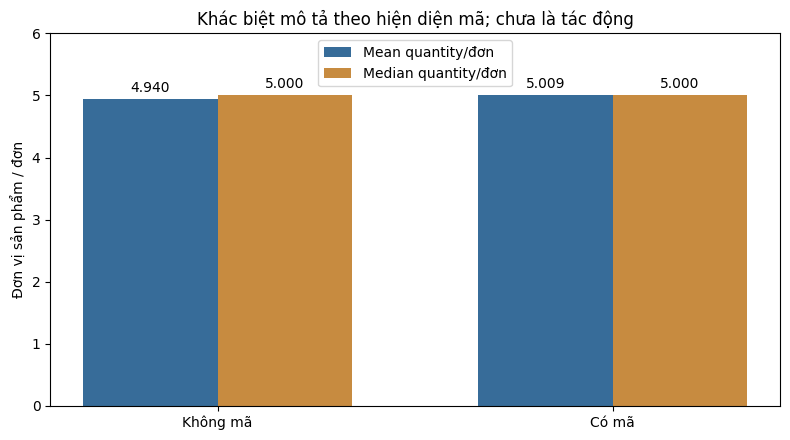

**Nhận xét.** Mean quantity có mã **5.008798** so không mã **4.940392**, chênh **0.068406** đơn vị/đơn; median đều **5**. Mean Net tương ứng **18,894.78** so **27,565.36 ĐVT**. Nhãn delivered/N tương ứng **79.8503%** so **79.8825%**. Quy mô lượng nhỉnh hơn không đồng nghĩa giá trị cao hơn hoặc hiệu quả khuyến mãi; bảng NV06.4 theo năm/status vẫn là đối chứng độ nhạy, không bị thay thế.

**Kết luận/giới hạn.** Đóng góp của Thu Luyn bổ sung một thước đo quy mô giỏ hàng dễ đọc cạnh Net. Giữ đây là quan hệ mô tả theo sự hiện diện mã, chưa quy cho cơ chế stacking, mức giảm hay tác động nhân quả. Nên kiểm cơ cấu/giá và ghi nhận exposure trước thử nghiệm đánh giá chương trình. Không tính thêm ROI/ROAS hoặc phân bổ tiền hai mã.

STEP3_PROMO_SUMMARY [{"has_code": false, "orders": 398703, "quantity": 1969749, "mean_quantity": 4.940391720152594, "median_quantity": 5.0, "std_quantity": 2.7629486661816682, "net_cents": 1099039048976, "mean_net": 27565.356894129214, "delivered_orders": 318494, "delivered_rate_pct": 79.88251906807824}, {"has_code": true, "orders": 248242, "quantity": 1243394, "mean_quantity": 5.0087978665979165, "median_quantity": 5.0, "std_quantity": 2.8318594308496574, "net_cents": 469047877567, "mean_net": 18894.78321827088, "delivered_orders": 198222, "delivered_rate_pct": 79.85030736136513}]


In [68]:
fig,ax=plt.subplots(figsize=(8,4.5));x=np.arange(2);width=.34
ax.bar(x-width/2,p3_promo.mean_quantity,width,label='Mean quantity/đơn',color='#376c99')
ax.bar(x+width/2,p3_promo.median_quantity,width,label='Median quantity/đơn',color='#c78b40')
for c in ax.containers:ax.bar_label(c,fmt='%.3f',padding=3)
ax.set(xticks=x,xticklabels=['Không mã','Có mã'],ylabel='Đơn vị sản phẩm / đơn',ylim=(0,6),title='Khác biệt mô tả theo hiện diện mã; chưa là tác động')
ax.legend();fig.tight_layout();display(fig);plt.close(fig)
p3_yes=p3_promo.set_index('has_code').loc[True];p3_no=p3_promo.set_index('has_code').loc[False]
display(Markdown(f"**Nhận xét.** Mean quantity có mã **{p3_yes.mean_quantity:.6f}** so không mã **{p3_no.mean_quantity:.6f}**, chênh **{p3_yes.mean_quantity-p3_no.mean_quantity:.6f}** đơn vị/đơn; median đều **{p3_yes.median_quantity:g}**. Mean Net tương ứng **{p3_yes.mean_net:,.2f}** so **{p3_no.mean_net:,.2f} ĐVT**. Nhãn delivered/N tương ứng **{p3_yes.delivered_rate_pct:.4f}%** so **{p3_no.delivered_rate_pct:.4f}%**. Quy mô lượng nhỉnh hơn không đồng nghĩa giá trị cao hơn hoặc hiệu quả khuyến mãi; bảng NV06.4 theo năm/status vẫn là đối chứng độ nhạy, không bị thay thế."))
display(Markdown('**Kết luận/giới hạn.** Đóng góp của Thu Luyn bổ sung một thước đo quy mô giỏ hàng dễ đọc cạnh Net. Giữ đây là quan hệ mô tả theo sự hiện diện mã, chưa quy cho cơ chế stacking, mức giảm hay tác động nhân quả. Nên kiểm cơ cấu/giá và ghi nhận exposure trước thử nghiệm đánh giá chương trình. Không tính thêm ROI/ROAS hoặc phân bổ tiền hai mã.'))
print('STEP3_PROMO_SUMMARY '+json.dumps(p3_promo.to_dict('records'),ensure_ascii=False))
